## 1. Colab ya trae pandas, numpy, scipy, matplotlib, requests y openpyxl; esta celda instala lo que falta.

In [ ]:
# Faltan reportlab y el SDK de Anthropic.
%pip install -q "reportlab>=4.0" anthropic

### 3.1 `bondai.py`:

In [ ]:
%%writefile bondai.py
"""
bondai.py — los datos básicos (BYMA, BCRA y REM) y los bonos soberanos en dólares.

Lo usan: la pestaña «Curva en dólares» y, a través de ella, «Mi portafolio», «Flujos de fondos» y el informe semanal.

Índice
  1. Bajar datos: series del BCRA, paneles de BYMA (o el último precio de data912 con el mercado cerrado) y el REM;
     cargar_datos() junta todo (o usa el respaldo del 09/10/2026)
  2. Fechas: días 30/360, sumar meses, días hábiles y feriados
  3. Flujos de fondos: cupones y amortizaciones de cada Bonar, Global y bono del Tesoro en dólares
  4. Métricas y curvas: TIR, duración, convexidad, valor técnico, paridad y curva Nelson-Siegel por legislación

Ejemplo:
    import bondai as B
    D = B.cargar_datos(usar_api=True)                 # precios, CER, IPC, tipo de cambio y REM
    tabla, liq, bonos = B.analisis_usd(D, "mep")      # una fila por bono con TIR, MD, convexidad, paridad y spread
"""
import base64
import json
import warnings
import zlib
from datetime import date, timedelta

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import urllib3
from scipy.optimize import brentq, least_squares

warnings.filterwarnings("ignore")
urllib3.disable_warnings()

FECHA_ANALISIS = date(2026, 10, 9)  # día de los precios del respaldo; con API se usa la fecha de hoy
COLORES = {"bonar": "#2a78d6", "global": "#eb6834", "tesoro": "#1baf7a", "mercado": "#4a3aa7",
           "rem": "#1baf7a", "modelo": "#eb6834", "ipc": "#2a78d6", "gris": "#75839a"}
MESES_ES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
mes_corto = lambda m: f"{MESES_ES[pd.Period(m, 'M').month - 1]}-{str(pd.Period(m, 'M').year)[2:]}"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})


# Respaldo: datos reales del 09/10/2026 (BYMA + BCRA), comprimidos con zlib y codificados en base64.
RESPALDO_B64 = "eNplXG2PnTWS/StX/QWQOjcuv5TL/S3AaLWrZYKAlWARijqdHpFVQkfdATFC+e97Tj1vrsuMRlP2fcou2/VyquzOX1f/ur/79fbVm9uPD09XN1c5ZX0m6VkaV9dXvz483qJP8k3up8//5/uvvzg9P0m5ye30+Yf7p4enL/DRv36//+3jPXj/unp/e/f4AIYX3/7n6cuvvntx+qOeEz55/fCbD/7lT9+8OL38cP/b6evbj7en5x9+f/3u7d0z/Pzm6fTv0/N3969v757A8Hj//tX7+9+efr99RzYMdX367v7d/R+3799itofTm/vTP/78cH/38fbj2z9un9j+5v7x7vaN//R0/+Hj2/v3rx/vT1zP6fNH5/Uf352ynW7fnUp6nsZz/nx9WuTg7/g56XNJ/sMX59OLx7tf3/7xcHqcJn92P8387P0y7bOPt6/foen7l8b5z3dPf16ffn34Pwj32Ve/3755fHApH++ffn/3EQxPn2HFn323N08/vPz2JOmz89Wn620j/7p6++Hu6ubnn3EsgmHl6rqe5ZfrrZ2vrvO5H+1ydV2OVkXrXI92I3c+2srfp9E6RjtadnWd5q+hDzJ9LYlzH6OL8Hc92pntjb+77HIuR9tlb0e7zON1lz7v43WXPvDrxfid7X60je1pPJd/7G3KL9P8i/zH95T/2B1b5bejnWd5bZW/HO06n425/Hkez3d/+r1fzGdsj6MN+XWX11z+Ns1P+cu+H+byH/s3XP68jzdc/rKvZ7j8dZdnXGjPcPkP+YbLn+fvqT37/MPln7gHpT1mp/Rl363h0te5nafdyWmVvhztvOsqW2Uaje06nS3b7aKtk6xs90k32LZpbXnxhXnbK7QX6af2vPds533tWRarPVq+Mj3avu92tOtk42y3eW2y6k0+2n23ebZssiq2B78+2ovkU1vi9zJrRc4u+66FbOdJS9gu1MqpDen1aDWeuhxtZbscbcjeNx1jG9JPY7nG571N2XXiXnTmkI2yH7MVl12PVib31C6cux9tSG67LMVl7/tOFJd94u6zLGXxNnlmH95xjE/pbeJwf5OnCdxg234WddH5tItcfQlynH31NYgcTV+CHe3Z4bOtbE/j9UMx62Kw89dBderq8PvRlskBsj0Ho9xWk81He3aYbJfZxNvqMO1oB6Ntq8PXox2Mtq0Of2qPyeGivchfjnZQ/bbKv82v0WHmLdhO7TI5yKwxYGWNDj/rKv/E3y9+tyWA/eLoB9IcYZ/u6ohVK6vMgd+8Y4RonS/DtYyLeJ1TDNdjjrfiHT0EbHTEiC12EbKlz1/wCHsM2T1G7L7LuIbsPsd0GpFeBu0+oQC3onlKX0ef47K4lBoCN77QELmlz6G9OkuOsTvPHTyROnfwREI4Z/iWKV67OckU0N0Vp0kOP5FZUtdIm2Ps8kULQTyPEMMx5EUQl8soHoN4SSGGl3QZxG2Ky1xFtRDGq00M7pPbBDs8FIZYyy9SCORlzLG3eEcLwbyOEMubhFDe8vx55+8XwbzJLAGxSJpYHEodprjE8zCor2LMUVq8I4b12mJUL3MYr95RQlyvl4G9Hg5miew1hHrzjh6i+7Hba3ivNncsKykhwLd6EeHbZYhvee7AWlqbwzTW0nSO61iLpotArzbPgrVYmYEC1jKOQ1ii/ajTGFzLmMdwW09pGoSLGSFoi3e0EPUllbnHY2aZYzfNver8jfstmbEEXZfKPBW9Vzvwx4oBRp/Hof+yNn2zuOE24RC3+qwzUqBRSwk4QCzE/bxIPCIS2Nz5BgUiEsB5jAAF9NiEBQu0MoV3V7Y6d1DZ0jSGO7AW8cC4BARtjsgyR6kNEgSMUNyvtggKdIra7orTPIZ6hwVccIS+FRhElnEhh0ODeQxfi0RokOZYPf+u2zpKwAa5zGCizgFjQwdlZtHLMZZ1WAAI86RbiAdg+HhRJIB+a9v9tK4KczYoTSgWoG+otFAyQF9No4WyAfqk9B5KB+yrqQdQwvHSqAGXcN46LBYSgNPTxOtmgT6TWE9AslDGiCClnS2PC5wCLUvaIlQBlB5WIlpBXy49AhbM0caImAUGOkwicIHDE9W/oRcdl/ilyizKWDBNnfpWFFNbtksgU0f+G5bpKV2UIcY55REBDYITTi1WIxDJS4+wxvvqiMgGyqLWI7iBOyz1At8ANOV6AXFgFbleoBw44AuYg32CzsZahWIDRsA6+Mys5QB30FeTXpQt4PKTaSxdyLlAuoB8GDxLsQB+4NJGKTkgIMZUGyXAIETiVksNSAhRsecusaiBjUpSAyJq2ICSLICiBihdTAIuQp9ZidAIYTSJBHiEsFOq1YCQ4Lsl5x5AkrZz1xyAkkJ7couFDwW42u12BUyIdbXXiJk6dm+UgJo6THRsG78Cp46Ap9N3XGwf0yav8MmQG5U+AoJiaOzJAogywJdeY31kyDmp1gCmBnI1LRbwFPFDqhYgFYJtxkkGVDV0sowVWCFwI+hawFaAEtli8WQM2PKQALAISookCSALbZyutQC0CEWGVQ1gSxICXOoSAJckhNI2s9cVt5TaAvASuoheegBfUA7oW+sBgAlyh1pbrLdIwQaNVAIQE5iE5hZrL0JIPPKIgEwBnMVKwGTSgR/TrgBlhTCI9LVKxGY4Whu5BniWsUuSWgsILcMBt9ZGAGkZyY2MFKs0GQi4q/QA1bLC32jtAa0V7JKUWSS6L+D6MSxAtoJ8AYpcA2orwEtwujUAN4UjGqP2gN4M2SSOrQUAZwWuSGqAcIZ5yh5oNxxH5NasBDRnptR/DYgOew5VGDWgusG8VFsOyG4w0zgWtKA7QAHE1lYDwkMchIFbDjgPGo9PZ0EXlUd46UklID5YJPC31hpgH84Xyqi5BewHU0BsKzVWhUSyyxBLQ1LhefLIsUAECIF43kosE2U4wnT4y7VYVABXW+ktAEMB4IBK9h7QIQwixxF8GypjonQNSFEqJJs2Z4VkFXpVjqVtoAx2rq1LgI6QAS6hWA/4Ed5JCBpKAJH4ttOb5VhoqtCk3LMFOCnVsA+pREwpFSsemkeAltLgbGwSYXUBgMmlOeh8ffvm3e1jBJ7E6pJbvKGCtz1Q1wqOGQ6bxLuqBNSl8b4KfegqAXjCi42qI1bDFGHTLBbECDxLBJ6whdRqvMTCwQI9xsIYAs6wHIBnpguYQeFaINNYIuNnmi+qZKFsVr0jIEI/SCgC0G4EnVDFA4svoJOJiKZ40cVTSWoBdWINJfcaUCf6FFEloM5Mr14soE5sU+4lgE58NrRF1MkgY1Ii6kRcPjRgRZ3saxZRp8fWiDpx2k2bxjsxpIM5WUSdwCHaNaBO+F1rWuL9WAKglhZwZyNQbBKAJ0smpdUAPGub17ECT3gcq/USeAKvlAg8EYBSzwF4MniaxdIb5LPRLAJPO+s8rS3Fl1paxJ0w2ZYvcGcjKPxbMQ6IzWI9DiGqlRFwJ+C4tKSxLge/vfOuwJMuU5vFq7ZBUFMD8oQG1cO1rldudLctIk/vm4GseZ+2IvH6DZZWa4lXcLPD2K7hoKY1WYCeUKEsrQToiT5ElRGv5eqUla7QE33piH4L9GTf0BGv6MArTeI1HftiPY9dRQLwZFfrsajnfTPKTEtflRqQJ/t603h9V6c7s/VokVVGzIkUquwWuULOCuurEu/y6uQIVrxZmUTLCHCTNeCk8WIPhgZQG8EmsptqpvGKT9kX635EAQc2WJAm+qRPvI62xlzHWz6qahZv/aA6u4VuN3+IK5YkIMyOjSsqAWAOePM91qz4EplHDX0Oss6aJMdaYIKezDB0LAj+CHxbQZAhaPej+90g1tYCtiQMkj5f+MmSKBzOcCsOJoNnmVGog8sz9KcFbAn0rnpRKIR3bdbitSFcQc3aArCkXh2HvuBK6NURc7dLRCzEJIBKqlqyWDukB5oX57qMwDHjM1muM0a/uFYElOwmsYwIx7IXDlYgiVVIqxpwJKboh7NZUCT6RCUHDIm+OO9yNZKKlIAf0VdzLC1WnU+obX4KZI8lRqYoqQXYiOVyNwJo5BXPkB6rjUzD7aLgGBR1rTmymNBqLDvSj87zLpXHItZi8ZH1D4kwkXPM866IqtD3O0Z8uo8IEWZStQSAiLBtJRYmEWb3THOFh83ybk0rOoSaVksBHKqMrClgQ0VKMt10uh/qqqUFZKiWbJpx8UKltBaAYRckdxEX9pFGbwEWmqhpDrAQYx8lpgUVdmQZI+JCtLXmAAu7VZMWUCFcRU/x5RPstU8Yjms0hXHG90+wpTQJ4U8SzMoEJrlGGPVcTF0uWXIfFouQOO0uF1VIaGodKd6sok9qxIPsayPiQY6XWwl4EOlgTyW+kRK40Cwa8CCibM/aAx6U3BHNcsCDwHMBNy5+to1eYyESM/TWJOBBKQDsM37z72ouE+BacreULKWABzleSRrwIOsOodip3tfKfD3bPevLucZCJMZD1jcCIATvSDW+sAJvO4qsY62pW+q9B0AIv9uOcLsAQqjwOJzCAgjFYEpz6dBzG8YnCYAwIzeXLBEQ5jw5wRUQAuSkbBEQApfkuY+OpyAZtov3WEVoQAEQ4jBwSC0AwszCS461yFxLOZyqrJlrgrHnAAihGtlsBECYkYA37QEQZuzyId8CCNGXStYACHPHjrceEGE2WHxq8QXXKKmkHCAh+/YLgw0SYoYDoK+QECi0SYqQEP71qDysqBAupOZ47VvgFm3EQmSBp5QS65BASa3pCLAQ4xnOKcDCYoP+OMDCykOf6oUeR+EcjzPPaz5nqfUUYGHNeYx28QKsJnjiGmBhNepaLD+yVLT7qxUZ8jKoSHwTBg+hfa4oMvRkpAVNAzJEAlXzXE9kPqeUJSJDFRzbXGJk+IH1phTvibVlVY1lR8DnqhMi9QiERP/YlwUYDkF6aJe4MDf8Xi9wYUUI6CXeG6eBZDVHYMiSWVONRUehizkqq3V90cP7uBqvkukBtKQIDjEHdiyNgA5x7gJ0Hq+VYdxDu414uQwsg8h0ccGMrHAqT64YEb/CnCWAxJLof0osOOLL3mToBUxM0IEyIk6EjIg98T1aQezoNsE9R4rINiTUMP3dRrNhF7XGCldnR460okWe0eGJFriIlLYhrtSAF70zawmAscIlSJk7PeM3ZB1DA2SsWA7tM2DGymK+dQugsXLAtAX2FTXChxapKQfYiLMQKETEjay718NGF7xVNQPaTEXHBSnzv9DkXz5dX93dP/IF/Jv7pzf32x8mpMVZX/1x++7hkX9z8LP2DkRbm1yTMgzZQBGE15qdGtpSAeUJQVIivTP3uDiFY6mkhIl5V6e01wZeXlhI7wvVFWcKqpzhhxcCGHWAqGe4AitOjQoPDwopFCaDTEbsj5jrVAcK4K+Q2OClnRrQIM5qZ3iKQY5xRsBXJ3AUhrmQhQIYKKbwmzCEPacwoeE75J7Q7eLEEMtG4MpKi0FyXonBVTmBpVDy0SCwcFmDVVPhXKDg5jtEYjUZrsgJ6/wcezna4E+DVz11oXCi2PPOqy9tmJ0UIS4ISAbFIIUNLKOIU4bPFFTxmlwDxfKI+SDV6+UdFDeOGwKgcaaCDKcG/sM+XmdmH8VvssjK7Bf66hSmx+53QT4DLcYUwmyHGgE4ck7gGk514llQ2KWslW4Wa+aiSQ3sKoaTdsb/Mn9VplGFVGcJwqfAwUnqpHBwFQiXqcG5wBmAYokWONCc4iGREmbV3BWmR1gFKVajxzCnIFTDeHz+UpAHgGosqlRxCq6De8F7eaybHLyvXPqo9gARoIy7B+3oyH4zlKI6BYzFc2F1tfs6mFRClO7UYJwAxQoGPgTFmo/KQg0kFpCg1LMiSGOHSuNlpRan0MMVIXVXGBlkLm6MHBipca5joXCsRoqFgM4FVRbJgYSc6kRUoJDYl0YlqLxSxBE5ZanyR2iNLV1e8qKGgEKWxfWwJAUd5XeKKdLgd36fm0kZazg+imGnaJYA/DxdxRr5ErAJ18jKMDYSIzfobVaO13BC2rhTfCOXmmC8BksC3iMHKyWQAxR0BBvROstl1MtmWIMfY6MHKhSzeTVfMZhCQzE7flWoBYZlH9SiwamCwgGkymG1QkEoh/JhTefAfsufuMWqtLMCXdCOJHxQ89SgW/A8oAaf08At9Y7NLr47nfVmoDRQmLZQLXvmdtIuuhfpOUXHZgPfYZDulU7KDgqH64NAAfqgonS4D+igOqWAABCK3hj5hTg1Gj0fIuQZ/oNq3nnv4cfT+fYBOIh4hhVgTEEXjJi/UAY8js/geGun5+vGFw9CQ+c7wu47AIdbEcI4SKNCwZORgiVSP+BwAUpJ8PJPqIugENi5WuNGKfUOFHIpp3gDk/krHC6ANTlADXg69glVkF1wJYWqOFjS7zRz+FuGyOIUvL9/xnIirNupzrcKTO9ZGaEDA8XUmxxUnUH7GHR0tG0+Iqy0E/he7L85oXX5CFuYijNChxs80bX5+wPBZpKiBht8MLKKMZzCbhR+lbnR8DsGH5yMgYIUvBcWAzM7M90vTkFVUwUFcQGailNQdOg8zAfiIp91aows5O20ocJ5aWvi4/ERTG78js+VeIakGjAk5oWLTgBZ2Sn08DtQyDjJK9zqwvHEpc+Yl39doTwmUkMpvFBPFSGN1IAZsQ8qUevITo0yfOAGkRktSEFzOwfGMjIgAAksQjgun27BXzo1pPTqF/cVoHk4RQtk3zjXpctdK2zC4OaRhnCG7CYGL2asoA24UKeQCEEkev5Bb0IKmo7YbrwoqdqdQCig5AwBsBxSfCdXORcowH7jaAiMkLc6BXfgA8PqmKM4hYMiAyRHBHAC++sz8OUP0Mi1IRQkKH12CjvofcJx+R0ouA9hH0MVSKeMsdpYCa4I+f5+AQEDpkEKuM9I8QpKuOmgAKV46ogOyDRhiKSghcZfIbBW7+t+O0FRIDHCHPugMa7tpFQy+xAoeNVRnAKgNPYJ35WVhWoI/hgFIQOKxfPkEy4gM2wUogcBknkUUWoYKOQSXBiiCMIO9bn640UsAuGkWO0LBWMeHIwX8n50oKCW3GuGGNh/cQo2lvmdEfL0hYKlc8sQbASaW51icln9oYfg/MUpZekLlPC0y0IBvQGiWeNyhPPyAhFwGzrOoCR0dqSwT1wGwxOdDKjKh0OaVwj9ainB/rVVU55lubrJ/roN7hmICAe4ZfHPpFzd8F0xi1g4RbisLaF8JgY2OhpEUMEEA5u95ZDE5DfACecldWnY2LL96HnWDQI7VAQujIlvHddbqvdMOmZECIC6U73hzdv1lvYwybnBDtKikhLPIzjsP2bjj9xQwyKQO7dFICY3vpAdXoFXxv6jV21vNrePzARYbPpN8dvq6oE8yLr92J8VLHP3JgkBAp78WCY4C9/qIYtI+ACI79P6l8+vfn96wyN48TJ3/zPp+w9XN3wLxv26vrp9RCKDSMnYhQXe3b27unHUbYYRwGQ70/CXURsL5IDSQiUWHqOj7WPhGTsP4yBw0MoD1z3o6DYe3hFkJc8/Zx4oL9zpxqPUXCDMlQeGAkdCnv+eeJo/9F15YE0Ie3AEC0vzK4HiLCUdLMrXPmXjQQRlnrDxFI8qC0/befytYtv3QGDZg+BrYQIAyiO5bP8ox745fOFRrkwAcjC7beM4JFTEZ6qyMynf5cm+c7AfQr99psJtBc9/fD1vgvIqrx8r6nwPNq/IOeY9gGX0fQuMKKRt3xPVVF04ph1gkmTHDrCcBEi6LQbgFdh2YTp2ADYG8913IBfmOrYthgAOXc407QChY827HiDhYRa7iYf9gc+tC5Me2wapYRsrE+zP06aNJ/OBELfty29fvpitgXlPGrs1DM8FN5UD1mkLz5cXPPtEoryUP4seLGNh+eqC5VAesNQeWeA6F66vIxf88sRmvMkuBxuCUl/XNBlrduC9WyvrsoCkmxURtK9rmngIgkvfeVJDNNZy8OT2CUz+jy+Q6XvRl7pIiDCMhXxfkncgTgMQ47y/l/JP/4LRCuiSX3hH9kyCHXn8oy8OCWkCxvhBmnfwCj8xCPxQEs9KmOgRcaJDfmIH/zytcyPwxX/5F2CBK0fHy7zOmhg2r374qaRvqa1YDrAHOv73Rxe0E9k0DvEjOZiGARBhhB83OaHcY+X4mk428T0kjerHTXCmiUgX+MU36OCzUBjO8A4XHGNUby1St7VFd1wxHELAMv73fRWRWMdF9PGFJsnpOTj9qayDf2OrIxffJoxoSxQQsXVEdNDh1uYr5Pc0cYCvdUhbjlX7ItI3wxUHEIP8PzLkINx2vhGhtoR/GOPn+b3eefDfJ+D/D1ZVmEErayn+C1AQQV18zHfmb7py2fLNVKVb/0UHQCksHx4FaKXx6qNnfs8LLYRr5AJSWIZAD9OdijjduqvRMt4xnP+DEGRVxPHO15fWMzHwKjprYgSAmZWoTeStvLj9AxIUt63j9PWb45M8f8JSEfIJbV534RTQqiDU+jrP96Fdw1opSoPH482hVGS0EKO4xOuf5b66/c13/q+rD48PfxJI8KkgTnJpvvr48AFbe8N3sEtfrjzwM3Tzzdu77NqLabzRnZlBiS0qBhznp0//D/4AnJQ="
RESPALDO = json.loads(zlib.decompress(base64.b64decode(RESPALDO_B64)))
print("Respaldo:", RESPALDO["fecha_datos"], "·", ", ".join(RESPALDO["fuentes"].values())[:120], "…")


BCRA_API = "https://api.bcra.gob.ar/estadisticas/v4.0/Monetarias"
BYMA_API = "https://open.bymadata.com.ar/vanoms-be-core/rest/api/bymadata/free"
DATA912 = "https://data912.com/live"   # último precio operado: sirve cuando BYMA vacía su panel (fines de semana, feriados, antes de abrir)
UA = {"User-Agent": "Mozilla/5.0 (Bond Analytics, trabajo académico)"}


# ── 1. Bajar datos: BCRA, BYMA y REM (con respaldo) ────────────────────────────────────────────────────────────
def bcra_serie(id_variable, desde, hasta):
    """Serie diaria o mensual del BCRA como pd.Series indexada por fecha."""
    filas, offset = [], 0
    while True:
        r = requests.get(f"{BCRA_API}/{id_variable}",
                         params={"desde": desde, "hasta": hasta, "Limit": 3000, "Offset": offset}, timeout=20)
        r.raise_for_status()
        detalle = r.json()["results"][0]["detalle"]
        filas += detalle
        if len(detalle) < 3000:
            break
        offset += 3000
    s = pd.Series({pd.Timestamp(x["fecha"]): x["valor"] for x in filas}).sort_index()
    return s


def bcra_mensual(id_variable, desde="2016-01-01", hasta=None, como="mean"):
    """Agrega una serie del BCRA a frecuencia mensual (índice 'AAAA-MM')."""
    hasta = hasta or date.today().isoformat()
    s = bcra_serie(id_variable, desde, hasta)
    m = s.groupby(s.index.to_period("M")).agg(como)
    m.index = m.index.astype(str)
    return m


def byma_panel(ruta, plazo="24HS"):
    """Panel de BYMA (public-bonds o lebacs). plazo: 'CI' (contado inmediato) o '24HS'."""
    filtro = {"CI": {"T0": True, "T1": False, "T2": False}, "24HS": {"T0": False, "T1": True, "T2": False}}[plazo]
    r = requests.post(f"{BYMA_API}/{ruta}", json={"excludeZeroPxAndQty": False, "page_size": 5000, **filtro},
                      headers={"Content-Type": "application/json"}, verify=False, timeout=20)
    r.raise_for_status()
    datos = r.json()
    df = pd.DataFrame(datos["data"] if isinstance(datos, dict) else datos)
    if df.empty or "symbol" not in df:
        raise ValueError("BYMA devolvió el panel vacío (fin de semana, feriado o antes de la apertura)")
    col = lambda c: pd.to_numeric(df[c], errors="coerce").fillna(0) if c in df else pd.Series(0.0, index=df.index)
    df["precio"] = col("vwap")                        # precio promedio del día; si no operó: último, cierre o cierre anterior
    for c in ("trade", "closingPrice", "previousClosingPrice"):
        df["precio"] = df["precio"].where(df["precio"] > 0, col(c))
    return df.set_index("symbol")


def data912_precios():
    """Último precio operado de cada bono y letra (data912). Lo guarda aunque el mercado esté cerrado."""
    filas = []
    for ruta in ("arg_bonds", "arg_notes"):
        r = requests.get(f"{DATA912}/{ruta}", headers=UA, timeout=(5, 12))
        r.raise_for_status()
        filas += r.json()
    s = pd.Series({x["symbol"]: float(x.get("c") or 0) for x in filas if x.get("symbol")})
    return s[s > 0]


def rem_mensual_bcra(anio, mes):
    """Medianas mensuales del REM leídas del Excel que publica el BCRA (hoja 'Cuadros de resultados')."""
    url = ("https://www.bcra.gob.ar/archivos/Pdfs/PublicacionesEstadisticas/informes/"
           f"relevamiento-expectativas-mercado-tablas-{anio}-{mes:02d}.xlsx")
    tabla = pd.read_excel(url, sheet_name="Cuadros de resultados", header=None)
    filas = tabla[tabla[2] == "var. % mensual"].head(7)  # primer bloque: IPC nivel general
    out = pd.DataFrame({"mes": pd.to_datetime(filas[1].astype(float), unit="D", origin="1899-12-30").dt.strftime("%Y-%m"),
                        "mediana": filas[3].astype(float), "p25": filas[10].astype(float), "p75": filas[9].astype(float)})
    return out.set_index("mes")


def cargar_datos(usar_api=True):
    """Devuelve un dict con todos los insumos. Si una API falla, usa el respaldo para esa parte."""
    d, R = {"fuente": {}}, RESPALDO
    # 1) macro mensual
    try:
        assert usar_api
        macro = pd.DataFrame({"ipc": bcra_mensual(27, como="last"), "rem12": bcra_mensual(29, como="last"),
                              "tc": bcra_mensual(5), "badlar": bcra_mensual(7), "base": bcra_mensual(15)})
        d["fuente"]["macro"] = "API BCRA"
    except Exception:
        macro = pd.DataFrame({k: pd.Series(dict(v)) for k, v in R["macro"].items()})
        d["fuente"]["macro"] = "respaldo"
    d["macro"] = macro.sort_index()
    # 2) CER diario
    try:
        assert usar_api
        cer = bcra_serie(30, "2020-08-01", (date.today() + timedelta(days=40)).isoformat())
        d["fuente"]["cer"] = "API BCRA"
    except Exception:
        cer = pd.Series(R["cer"]["valores"], index=pd.date_range(R["cer"]["desde"], periods=len(R["cer"]["valores"])))
        for f, v in R["cer_base"].items():
            cer[pd.Timestamp(f)] = v
        cer = cer.sort_index()
        d["fuente"]["cer"] = "respaldo"
    d["cer"] = cer
    # 3) precios de bonos: BYMA mientras opera el mercado; data912 (último precio) si BYMA tiene el panel vacío; si no, respaldo
    try:
        assert usar_api
        pb24, pbci, leci = byma_panel("public-bonds", "24HS"), byma_panel("public-bonds", "CI"), byma_panel("lebacs", "CI")
        assert pb24["precio"].get("AL30D", 0) > 0, "panel de BYMA incompleto"
        d["precios_usd"] = pb24["precio"].to_dict()      # incluye tickers D (MEP), C (cable) y en pesos
        d["precios_pesos"] = pd.concat([pbci["precio"], leci["precio"]]).to_dict()
        d["fuente"]["bonos"] = "API BYMA"
    except Exception:
        try:
            assert usar_api
            px = data912_precios()
            assert px.get("AL30D", 0) > 0, "data912 sin AL30D"
            d["precios_usd"] = d["precios_pesos"] = px.to_dict()
            d["fuente"]["bonos"] = "data912 (último precio)"
        except Exception:
            pu = {}
            for t, v in R["bonos_usd"].items():
                pu[t + "D"], pu[t + "C"], pu[t] = v["mep"], v["ccl"], v["ars"]
            d["precios_usd"], d["precios_pesos"] = pu, R["pesos"]
            d["fuente"]["bonos"] = "respaldo"
    # 4) REM mes a mes
    try:
        assert usar_api
        hoy = date.today()
        anio, mes = (hoy.year, hoy.month - 1) if hoy.month > 1 else (hoy.year - 1, 12)
        d["rem_mensual"] = rem_mensual_bcra(anio, mes)
        d["fuente"]["rem"] = "Excel BCRA"
    except Exception:
        d["rem_mensual"] = pd.DataFrame(R["rem_mensual"], columns=["mes", "mediana", "p25", "p75", "top10", "n", "nucleo"]).set_index("mes")
        d["fuente"]["rem"] = "respaldo"
    d["fecha"] = FECHA_ANALISIS if d["fuente"]["bonos"] == "respaldo" else date.today()
    return d


# ── 2. Fechas: 30/360, meses, días hábiles y feriados ──────────────────────────────────────────────────────────
def d360(a, b):
    """Días entre dos fechas con convención 30/360."""
    d1, d2 = min(a.day, 30), b.day
    if d2 == 31 and d1 == 30:
        d2 = 30
    return (b.year - a.year) * 360 + (b.month - a.month) * 30 + (d2 - d1)


def sumar_meses(f, n):
    y, m = divmod(f.month - 1 + n, 12)
    y += f.year
    import calendar
    return date(y, m + 1, min(f.day, calendar.monthrange(y, m + 1)[1]))


FERIADOS = {date(2026, 1, 1), date(2026, 2, 16), date(2026, 2, 17), date(2026, 3, 23), date(2026, 3, 24), date(2026, 4, 2),
            date(2026, 4, 3), date(2026, 5, 1), date(2026, 5, 25), date(2026, 6, 15), date(2026, 7, 9), date(2026, 7, 10),
            date(2026, 8, 17), date(2026, 10, 12), date(2026, 11, 9), date(2026, 11, 10), date(2026, 11, 23), date(2026, 12, 7), date(2026, 12, 8), date(2026, 12, 25),
            date(2027, 1, 1), date(2027, 2, 8), date(2027, 2, 9), date(2027, 3, 24), date(2027, 3, 26), date(2027, 4, 2),
            date(2027, 5, 25), date(2027, 6, 21), date(2027, 7, 9), date(2027, 8, 16), date(2027, 10, 11)}
habil = lambda f: f.weekday() < 5 and f not in FERIADOS


def liquidacion_24hs(f):
    """Siguiente día hábil (para el plazo de 24 hs)."""
    f += timedelta(days=1)
    while f.weekday() >= 5 or f in FERIADOS:
        f += timedelta(days=1)
    return f


# ── 3. Flujos de fondos de los bonos en dólares ────────────────────────────────────────────────────────────────
def bono_2020(ticker):
    """Bonares y Globales del canje 2020: pagos 9/1 y 9/7, cupón step-up, amortización según ficha."""
    s = ticker[-2:]
    tramos = {"29": [(2020, .01)], "30": [(2020, .00125), (2021, .005), (2023, .0075), (2027, .0175)],
              "35": [(2020, .00125), (2021, .01125), (2022, .015), (2023, .03625), (2024, .04125), (2027, .0475), (2028, .05)],
              "38": [(2020, .00125), (2021, .02), (2022, .03875), (2023, .0425), (2024, .05)],
              "41": [(2020, .00125), (2021, .025), (2022, .035), (2029, .04875)],
              "46": [(2020, .00125), (2021, .01125), (2022, .015), (2023, .03625), (2024, .04125), (2027, .04375), (2028, .05)]}[s]
    venc = {"29": date(2029, 7, 9), "30": date(2030, 7, 9), "35": date(2035, 7, 9), "38": date(2038, 1, 9),
            "41": date(2041, 7, 9), "46": date(2046, 7, 9)}[s]
    amort_ini, n_cuotas = {"29": (date(2025, 1, 9), 10), "30": (date(2025, 1, 9), 12), "35": (date(2031, 1, 9), 10),
                           "38": (date(2027, 7, 9), 22), "41": (date(2028, 1, 9), 28), "46": (date(2025, 1, 9), 44)}[s]
    amort = {sumar_meses(amort_ini, 6 * i): (96 if s == "30" else 100) / n_cuotas for i in range(n_cuotas)}
    if s == "30":
        amort[date(2024, 7, 9)] = 4.0
    tasa = lambda ini: [t for (anio, t) in tramos if ini >= (date(2020, 9, 4) if anio == 2020 else date(anio, 7, 9))][-1]
    flujos, periodos, residual, ini, pago = [], [], 100.0, date(2020, 9, 4), date(2021, 7, 9)
    while pago <= venc:
        cup = residual * tasa(ini) * d360(ini, pago) / 360
        am = amort.get(pago, 0.0)
        flujos.append((pago, cup, am)); periodos.append((ini, pago, tasa(ini), residual))
        residual -= am; ini = pago; pago = sumar_meses(pago, 6)
    familia = "Bonares" if ticker.startswith("A") else "Globales"
    return {"ticker": ticker, "familia": familia, "flujos": flujos, "periodos": periodos, "venc": venc}


def bono_tesoro(ticker, emision, venc, tasa, mensual=True):
    """Bonos del Tesoro en USD emitidos en 2025-26: AO27/AO28/AO29 (6%, cupón mensual) y AN29 (6,5% semestral)."""
    import calendar
    fechas = []
    if mensual:
        y, m = emision.year, emision.month
        while (y, m) <= (venc.year, venc.month):
            ult = date(y, m, calendar.monthrange(y, m)[1] if m != 12 else 30)
            while ult.weekday() >= 5:
                ult -= timedelta(days=1)
            if emision < ult < venc:
                fechas.append(ult)
            m += 1
            if m > 12:
                y, m = y + 1, 1
        fechas.append(venc)
    else:
        f = date(2026, 5, 30)
        while f <= venc:
            fechas.append(f); f = sumar_meses(f, 6) if f.month == 5 else date(f.year + 1, 5, 30)
    flujos, periodos, ini = [], [], emision
    for i, f in enumerate(fechas):
        frac = (d360(ini, f) / 360) if (i == 0 or not mensual) else 1 / 12
        flujos.append((f, 100 * tasa * frac, 100.0 if f == venc else 0.0)); periodos.append((ini, f, tasa, 100.0)); ini = f
    return {"ticker": ticker, "familia": "Tesoro", "flujos": flujos, "periodos": periodos, "venc": venc}


def universo_usd():
    u = {t: bono_2020(t) for t in ["AL29", "AL30", "AL35", "AE38", "AL41", "GD29", "GD30", "GD35", "GD38", "GD41", "GD46"]}
    u["AO27"] = bono_tesoro("AO27", date(2026, 2, 27), date(2027, 10, 29), .06)
    u["AO28"] = bono_tesoro("AO28", date(2026, 3, 31), date(2028, 10, 31), .06)
    u["AO29"] = bono_tesoro("AO29", date(2026, 7, 16), date(2029, 10, 31), .06)
    u["AN29"] = bono_tesoro("AN29", date(2025, 12, 12), date(2029, 11, 30), .065, mensual=False)
    return u


# ── 4. Métricas y curvas: TIR, duración, convexidad, paridad y Nelson-Siegel ───────────────────────────────────
def metricas_bono(b, liq, precio):
    """TIR, MD, convexidad, valor técnico y paridad. Precio por 100 VN originales (sucio, como cotiza en BYMA)."""
    fl = [(f, c + a) for f, c, a in b["flujos"] if f > liq]
    t = np.array([(f - liq).days / 365 for f, _ in fl]); F = np.array([x for _, x in fl])
    pv = lambda y: float(np.sum(F / (1 + y) ** t))
    y = brentq(lambda y: pv(y) - precio, -0.5, 5.0)
    vp = F / (1 + y) ** t
    mac = float(np.sum(t * vp) / precio)
    residual = 100 - sum(a for f, _, a in b["flujos"] if f <= liq)
    ic = next((res * tasa * d360(ini, liq) / 360 for ini, fin, tasa, res in b["periodos"] if ini <= liq < fin), 0.0)
    cupon = next((res * tasa for ini, fin, tasa, res in b["periodos"] if ini <= liq < fin), 0.0)      # cupón anual vigente por 100 VN
    return {"precio": precio, "tir": y, "md": mac / (1 + y), "convexidad": float(np.sum(t * (t + 1) * vp) / (precio * (1 + y) ** 2)),
            "residual": residual, "ic": ic, "vt": residual + ic, "paridad": precio / (residual + ic), "current_yield": cupon / precio}


def nelson_siegel(m, b0, b1, b2, tau):
    x = np.maximum(m, 1e-3) / tau
    return b0 + b1 * (1 - np.exp(-x)) / x + b2 * ((1 - np.exp(-x)) / x - np.exp(-x))


def ajustar_ns(x, y):
    """Ajuste no lineal de Nelson-Siegel por mínimos cuadrados (scipy.optimize.least_squares)."""
    res = least_squares(lambda p: nelson_siegel(np.asarray(x), *p) - np.asarray(y), x0=[y.mean(), -0.02, 0.0, 1.0],
                        bounds=([-1, -1, -1, 0.05], [1, 1, 1, 15]))
    return res.x


def analisis_usd(datos, moneda="mep"):
    """Métricas de cada bono en dólar MEP (tickers D) o cable (tickers C), curvas Nelson-Siegel por legislación y spread contra la curva."""
    usd, liq = universo_usd(), liquidacion_24hs(datos["fecha"])
    suf = "C" if moneda == "ccl" else "D"
    filas = [{"ticker": t, "familia": b["familia"], **metricas_bono(b, liq, datos["precios_usd"][t + suf])}
             for t, b in usd.items() if datos["precios_usd"].get(t + suf)]
    tabla = pd.DataFrame(filas).set_index("ticker").sort_values(["familia", "md"])
    tabla["ley"] = np.where(tabla["familia"] == "Globales", "Nueva York", "Local")
    for ley in ["Local", "Nueva York"]:
        sub = tabla[tabla["ley"] == ley]
        p = ajustar_ns(sub["md"].values, sub["tir"].values)
        tabla.loc[sub.index, "tir_curva"] = nelson_siegel(sub["md"].values, *p)
        tabla.attrs[ley] = [float(v) for v in p]  # parámetros Nelson-Siegel (lista: pandas compara attrs al concatenar)
    tabla["spread_pb"] = (tabla["tir"] - tabla["tir_curva"]) * 1e4
    return tabla, liq, usd


Writing bondai.py


### 3.2 `pesos.py`:


In [ ]:
%%writefile pesos.py
"""
pesos.py — los bonos del Tesoro en pesos: LECAP, BONCAP y BONTE (tasa fija), CER, TAMAR, duales y dólar linked.

Lo usan: «Tesoro en pesos», «Mi portafolio», «Flujos de fondos» y el informe semanal.
Idea central: la tasa fija es la vara. Cada otro bono se compara con la curva de tasa fija al mismo plazo: qué inflación (CER),
qué TAMAR (TAMAR y duales) o qué dólar (dólar linked) lo empata.

Índice
  1. Calendario: feriados, días hábiles y fechas de pago
  2. Instrumentos: las condiciones de cada bono (emisión, vencimiento, TEM, CER base, margen TAMAR…)
  3. Bonos nuevos: registrar_nuevos() agrega los que el Tesoro emite en cada licitación
  4. Carga de datos: precios de BYMA (o el último de data912 con el mercado cerrado) y CER, TAMAR y A3500 del BCRA
     (con respaldo del 09/10/2026)
  5. Matemática: TIR, duración, curvas, conversión de tasas y proyección del CER
  6. Cálculo principal: calcular() valúa todos los bonos; dolar_esperado_futuros() arma el dólar que esperan los futuros
  7. Inflación mes a mes que descuenta el mercado (trayectoria_be)

Ejemplo:
    import pesos as P
    datos = P.cargar(usar_api=True)
    res = P.calcular(datos, plazo="24HS", tamar=None, infl=None, dev=None)   # res["lecap"], res["cer"], res["dl"]…: una tabla por tipo
"""
import base64
import json
import zlib
from datetime import date, timedelta
from functools import lru_cache

import numpy as np
import pandas as pd
import requests
import urllib3
from scipy.optimize import brentq

urllib3.disable_warnings()

BYMA_API = "https://open.bymadata.com.ar/vanoms-be-core/rest/api/bymadata/free"
DATA912 = "https://data912.com/live"   # último precio operado, para cuando BYMA vacía su panel
UA = {"User-Agent": "Mozilla/5.0 (Bond Analytics, trabajo académico)"}
BCRA_API = "https://api.bcra.gob.ar/estadisticas/v4.0/Monetarias"
FECHA_RESPALDO = date(2026, 10, 9)
RESPALDO = json.loads(zlib.decompress(base64.b64decode("eNqVXFuvLTlx/i/neZ2Wr2X7vE04JArKBBQImgHNwwTmAYnLCCZRJMR/z/dVuS+ubvYmiFntVcsul+te5d7nrx++/98Pn/764edRfioc/PC77//04dOH33/3m2+///D68D/f/fE3+JpCko8xfIwC2A/hw6dfx1C2XuNLn2KPV8CzbqW+au5xi7G8whZCqK+J/xssjrq4bmHklz2TrS6GrEUFp/7KEurYesyKJZUDy98wyuEfoTeHg96ctxb6i08p9qyNFOeylfFqUrYau24Vd/wHvZgTch06ObQ6sRiSqNCEH3vsegziyAcOUhvzv79LbfwY88ndtuUQsAMHWR8pK3/bNrBVlbb1YFuFtu9w8rdttVRbV3E6Xd/ta9yRpCZdtiQmpVQPLMbff4TiC39T3YAPFGMwwFkF4ASgOQk5DGYBUtOpE7rHQTNmgcdNp4c0EWR95B1HTin1LY6LShgSkpzGj9ubJLePIX5M42Ry3kYpVL+8dfs0HYYWYq/etpiHkSs7/pPF0ISai86OVVc3SgbPqckCHEGgIUNODhsSkPuLn6Yrg//rT398trh21YlYmqkEP5XUTnOLA3tP3S0T9VUXcp+qZJ9Krmy1mibUVyoBdjb1IO0ISGSsC08fqFSmxnpQWSOQdJDJARhRwzZIKb6CPa3CRFo59NY2OGjFpCzVFmfptpoaW4aSW5OS23sPW2mm/ulEQ4pz+OJ9isviGWQToQ/DYFR9tEKaw6uA3AS5fdyVwNCffkHg/OCgdGnRhyQ+8J9xtvXWYcpGKvzLjkFJjV+/T2r9mONpZB0W1IAdA7KFXidRETlU4mPdpE6C49g3OY2sbyPUrgjoeImHptaUvRNHhgy2mqaRyYHE2PuT92mWhb1ThHgWdQN4DmNvpU+2bXLdkZ/MxcQ8mq5Q3xuMXlIYqfYJ9IY8/W051pPMr3P42Ztk5qCsPcmMEQYLjsWYtshPpRDjHo2bqe94Dwo5VaimGKSqD4iC62D4wDe9RzwWkrRffbVErt989+c341aDF4QWvThgyGwUsNEGaSVzLaHsiA/amoA20NTo4kXXtRhpiQ3CfkEUZctg4iFjW04Kv0rvEBg/hsOLwqMDQ8kwbSDEZ940UJUQXgJzqGUqY5uYdwpbrfC3iT4BJOrC+mpZP6GTLSRwcIaLnPbFoO8rF5seCbxGpg4tyc2Ux3Q9FeVgRKSZfrPseE9ToQHHqAtGt4VijxzNgOpLshriHo2+OqIR2Pn5HSLTxW3mMLYUsFtW9csxHJrUqGSTierrFPNOZobehgJ+cWALC7Sv23IYCkJ8B+91dTxWk40uXnoKb9EyMcgw1cOAnh2RLtc8A2ZhPoHIN4zQWvYNzjiUQRPjesiKo5OZeFZDRQsvAdqa6+ksvzrD5a+++vIdavPFUyZ4iNhhshjwP8oKFoNEjVEEAoWLVkKRXE3cO6GcDec3dBmcjaIyZ6PfMsIllBMZn9lelAOD0fnFO3QuwYfayKRItWt3xCZ32L35xpB2vFfllNjnguNTptRrCCB5ZlrjWGzkff0OeWvAQTrPQE3cGiHqFi0yQnCpHopveE/yqibEM3WrmnEgTtHqkHCBkcGWxngsNeLSO8RdI0uBlude5MVB1U9R2qBERfagXXe8O3GFpoZU9cWBLet8NGOe9JHOgH0sNvJ+/g55w0WU3BBHOCDvaKnTcyOg5cm8sSM+owrWzfnZHsShDiFGpKyv0Zi9lXImfIZgRpe3aUR0uRo1AunQAoFWGMgJEsgQbbonZUd6GrJmeFximWRATqJeAP6aIb3XNaoclH1+h7KrQ0wsTXpmsocwoZ/TZ8Pv7jE/7mgP28UqofPRga46MYxXaYzK3aJyHsfq6V/6G+T11b+oAwvM9ejBzJGZ8iGAxVlHph3tyTrkr3RsdHjRPKl+5lmDwC5Q3uTslk/beIe+q21kobKhtuEgspTempI3YCSSrsp9kse5PUMjs2giw1VDMXDMwFwHzSQu8k0HgT9/h8Bx0byhDqxCl7Glfip5HZ46j0v6qlh3AkE8CqrEQ0Rdg/Xq8wYtOQ6GwHApY2yxpTRv07akNLH1gSqFeX0bgZhb7/ZQ60VErSbh0CfuM+3CAikjcmm6LhU2CJATVWg1zmgijmlfPy3kHSqvFoLyNAlKKdRa2CLKNNw9ssUp388ncVghHUEDz8YPrIUfeXUyT+CV86RqxsTPB1lfjjfIGrQMHGEXLA0DTonP14Caw19B7eSF6h9cU8mWtKM9JJu3VJCNYtXgKrP1gtynI7U8E0hbpBKFMf5donJ0OWBhJ4nleWHbplgrZ8axHtpR5CvaQ5gFBlDV1xWJuoyiLNVCLBIe+r5yqWZ1Nan78p+XSPbDt3/49hYs0sck10Ab2OpimBx1f1jzBAPEqNDPkKnor9E2R9FAmzRGn0WhsE4a7FP1mQ+wCzHXK6H/9j6hbYlqgdn00IgU56fWchuT5bNQVsRnTMM0yfGyiuQhAGetmrQHUZHysJDYfZNhUCL/5X0i+9U7R5RGhQU5BlqYDYtR4Oc2Zt9A9Ukxn1QOsCvb/DIf+OzGS00ic4WLCj2fZZehmELvb5LZVehnr4T1IjNiPLmPaFtG/TRs0Wwll7xjPsksGxQyaTbAdfnMLZo6gt36bdnk4LukrRxkitKSyqjpp5XsiYZqmlj7jviMb7Qydj9imGv4GeouZOT27Ia0qSfxQEAaf/F5qTt/+9/f/v6tkinCOQwh+xpCE/jQrC5RKgs4k6bB1B336aS5oBRbqZ+pGwLW2Wp5ecDYQ0sehTLzlz/ubxHaWTldeFmyIEyJChjjwOo49xiMVFa/fdZ3Gk8U/emD8iBF2lPC2Ba3pI+o38qAgy1soZD5Z6PJ8Kiv/PIn7xG8tGxY3TSyNKhiMsUx4ymHXlqAVcTX7KaUbgvikddY8huKGbmAyNROrhoGI/LzO0Qu4gdHa0RQxTO+lL2W+xd45Klfccd6RBmsGVV0etHPPX/QYj6GziM0CzjH4snB8RZxgxy8ZDeVWZIwR8E+VTsi2u7qe3KTd6QHbaiSUO9xctk/zYkHpiBSGNr3NsC5enLuHeLIuXIkDjDBBvfGZ+dnmTajJa3pYd7RHrkDpoE7L81muJJ5B47UMvi/1zLHosmy8AZVbMDJJW9Akh6ZcnWtFpnuWweuIqjBDD8exZLiPcjCvAzT0PJAs/0OGulIR+XF1NWubCFI++wuj377+zc7cBXKyyZa470LpKHN7NDNfFtgYztMAsmCz+vVUUUQrkytEpchZdgfalBp1Mg8ble5z8ed0WfX5boTuSQ4NQz2A4XJyk4kZtk2opdAmnnVHfNJIPIO/AScl5Vdk6OIYIjvPQXRgvB6xtnn+uxuCByZ/nagtCGIXtpoLT1pJgWXMl0hYrUxkn2lifrKSITgPux6oFsSFo1cUs1jpmHJWKvHcmVl/PJtGpfSrgwce0uJEdZQE1TC3jLsKR7SipfGEWYF3q4MmGekU9aFEubCxppqWn851ioLw9dvk1ehkSd50oM54zlgumD/TVQX0RpjjsF9qib4v0xv778Eh9LoxKuwJ106wtmLUp0kDSbHbBX1i8Uq/pNLPbG3pZdlpTN24bEfaSRyLcMd971B1w8Mk9b+92n1gSzVjoDQm3Z/pXZaXN5ZwcBr/fOktweK+nIdORKy7lG0A5xJFvN9s9pOMrXtVK6XQ4bByPz8JplrJgPQRHwMIhlzCMvwXfLUnnmNxytdLODFSJyKNs/HHGFr/dKH+OUMZZ//9Uc/e6NwyiTtNAZUskJXDA8MB8BDD60vgg5JI0uMNo5qWNEfrbbBYjeNVDC5FF0NhpUOP/My0+iC2rXOhsexXun8Wfh/0KmKBKTzeVV0Ijoo6p3dX3aFTddAi9ZZ9g2RVqyrywa2rQQtP/viP97iWV9pQcqO3BFuIL0whHBQacIh0c1pB+ZonKKKMNRHA6YURAMRZC65kB58Fl2v4wrbgt1ss4EFXzmXK4lvsutGYtT0c39e2KWIDoJqHGzbV5bvkyA9hH1DLWeNUpq5LQQpP/rPL97gVqlOctD1wIqqsCGbtCELO2WmC6lE6ohseebyPU70hzwRiFlRcHWMapTDTBOZU9GGC5JW2r+6XdmX/w10/vCXS7wP4xcpfAr8/69AGogO+6+IYCEaDDtKa8jNSo0vjnovIBm+EDbCVwk4GlKRPyFd2GoQ+AW4adS1DUrOUYVL4SgibYpNdCRIx7C2IwDG1mzUJOJQAvvJVEYOOu9NpSMJH3C8OhqFbTJh5oPNQFPntV+E++WowW/xV74BUJFVcTRG0107MuYwuAIlMvJyHfSMA71kBNbBSEpkoK7ED01H2BBeWaw/nnUw9JJFoCSImUi9ZPBtCCS5HOAopJzJ7Ig8FpNtVK+iI8HxQRJSZER90QHfDBDk4gi3vFsbg63UYqNWEPVf7Lhkqdido8F6p7HvHEvgCAzM7A43u19CwdX4PsaIKEEaX9SIXZEgJuTWeMlIxpEhbKmn1vkmEEbwbIMw3sEkxQKiii4FTWBj1xG2B/cb9Fcie9WNLftCjWgs7bFq6KgN1jzIbmH6SEkbVDJVHpqjAa4CXeT9LC8mG1KMUiRzBCffum4BwcXQOILg4Cb460Ae37kiwRBjhvvliELiCHVXpyLiBLCfRJYl2vIYXUcgCulIQ9qPQh/sbmwfBUG846g3poyN1z6F70W1BDlFg1HtBcre9Da+QTsack8EHlLFLBT+ALvx2r7pOXLEeQOMkCPYOCJSy2kTzQ945Zug7TYaNTVQkMsmiTlAQyqWA9DoCBCeSN/Y4B0SDJsMJ+IOL1SGjSDWzhEYBJUCOhRPQZg5ctRqoqxKROlQqQQF5SpCatJRZ47c2D/oBoLW6DsXHHVhqgBrZUJNnUJhALc+OI/8AZ8xAilFFAsSiE6zbGVQusLLbnAFOT9gfMcFjATmmpiJEB9KxCCVnMJooLZIeq+OHTtXsIXKhiOvzPXKHZs2XpjyvZoYVYyVHiiTTPY8wxAgE2godsevbOYDLWFQi4r4hBEEENgP4UtwcPZVBwNBC4iF73UFspi3+WxcYISyVhjVG6J3hjxxBhl8VQJuqTUm8ModjMhEwrAtX+hpvM0GiUNHHXaJLRqYXRl4G5I1EEzam3ptRQIFaIOK0vhiGMtqjkQK2URvHBrZ2fS+vnKPzjKfag4fnIqKh2Gz84WMRh+cSTtdcIM31lFHrYRpXet/ahv8LSITDR0jnIQcgMMtSLSIpFKh4Mk4giVSP+BwcyMr4GVBJ3WRHXcoJBeQUUK9w2i0oaMBJ8h7KV4apC5cgRFSThomHG7pCoIryVRFXih0vsTY2FcHlVlH8P46DU4FicfQEYihoOh6c6MDG3zZousKqs6gfQw6Otr24FuCtBNesAyKiddExSbxxYSsC9lEhSd6dTrhyHfjOKIGd94jpjCGjsCNzFmJjGZJz6v/zkDBEbwXa3T44BRiyzqCqqImQsxmI1th9EAFOt9ZeqJ4bjoaI0Wu5S05O2KdLzogzCcdYbfKeYMZvWQdVdQU2DfqXSYqOo4A4TyMkCxybSSrtY0QlXoUeJ09WaGYOBpC4tlurXyhhaPBuzqMoBIFyaOORh6KmE0JRguOoLmNiHGMhBSAAxyCLY7I9yXgL3U0YuZdDrw7UpoydEQLJGxsxUDqWit7HIHX8twhqYnBi6EqRZiFC9VRHzwrPf+gN+EImo7YDmtkdGk6QCgg5QwBle8LdF7VB76lxZFUqD5GCIygt+gI7kARw+oSrzw46k0XgHJem3MA/uoOYD8yOMAQCgKUPukIHFRYJF7OwwjuIxLGUIWhjjpjNcQCehHyMSp6fTF0VBFxOWLXLJLpGCGVotQRHRKUUXQELeQFGeOEFIUx/ddDZLa04EkxgsaotnMkKHAAQ6CAoyK+whu9xnszhAzUW9lGFcEfWBAyoFiUJ1+JQGYGRiF6MEHqGkWEGoYRyh0eDFEEYYf6XOhjaTIIJ7mziOIIxsz7HgaWrKIrfIGHr3t2hpjOF+Y4go0lzutMeZqNYOlkWWH1kSkxjAQOg60xHKfw5WSOJAnXVr0uzTZC9oYUrfNtLmSeTUe1sCbrDEqRzo4j8InHYHiik8EIB6oIjN9ohvxP3/7lOyb/rGR5pZCQpSdigiIiV4dbfvG3pE2N/OETTgfVZzO4sdLHT0VbRqieE91M52Ui4gVvSu3HzGz8E7IETarxP7A17z9W/P7hE8I6Czmky8gSy5g/2tu0n0rXl2Oo3PDlVX+s+vp1+vAJ/KM9BWE2j9Bw/Miug1Sys+MQInwzbZYHWQ9yJFdYi9pv/1EU7e70CzIMvoV1/Cb4bTp65B1cuv/YWCN9OnxJQHjgm0Ys92cB9YkvQaLM6HA9I144AKS8tGd5gcKothNpth1npofACElXlEK/+x7F2a9/badlsYOE5JvX/j3xezm/5w8vhMTze+Hv/fxeP7ygT+d34Xc5vzd+H+f37r4P4ovHd/a+4BfO70rfiT+m6/4y6R/n9+S+K/3l/K70y/m9XveXSf9lfXO/K/3tGxjAn7/7w85H0XNc1/Ec8eCb6DlYutQTkgjZT9L0JCfnmp5k+Z6Pne1Gb+5dqCGcTBcHCc8FBs4KRlRbwUXBK6waTNxU8APeNiwwnBVe2e3FE2f231ZoVKgnjIdn33UFZp3rSeDfoTxs1wzqjgZfojgWmNHrZqZHelN+RJvkGdweT5cNdbqYRTQRLSgMnBeCDWa7tRVoe3W/ngfmSyZu9jxzX8FTSDdwfiCYl0irOOre4GfAdhhEybghbjrZ41Dep9tZUnxEktIzOCvYMzSVR4Yko8QBjXke8TCoQ6xSzauk2NpilnOdOc0uXNXCwMUmdweuCl63m5Z3R90UusBUqPftotHmoUmh0RERjeR1s1ie5xoN2RGsphc2D6WDH04cZn1IHte5lD/m+oNQonz737GC71Y8gUXBHkdTaPWTu4IXaLag4CdnlUgaTlDZQsRYlShbILtD4wM38iGUFfGUSfQ4yl0x8i4UT5wKJTomZXOJcXNkqFlGj1mtconxWXnP9W43dZPRH1pNLzq9t9fI7pPVopIjuGh0ZBfJQbNCV3YWM7Tk9KiY7eTNoegPrqiY/3Rerpil5Rs0PjjVYnIadzBZJ9sKE5u60qCMdzOTBU5xSNUXVs8edYX1xksVXvGnSP0hvhRzhuWGY4a4BWrZIGu4hfF1TyJWbanPEc1SxDUi1j2crRNjevDTdQ9mfaVhj2YLrD5EuGrS8CpY9zRCHOKZR9zA0SUdBk0P3Kx71uEJSRZUb6jbg77Vx2BWn+VX92C24pA9SUkrMPssx8AWaMMCMwVYDyJ7QhM8eDyYr+xJyoI4WmrgJj4pgJgC3ImI7SExEPOQafPQ8UjxzDkcsDwwbRrZcogpTzexPeSFsgto2d+KhJvo2y62Gzg/HKLtgnNz2+N+3ec8zcTjPWYzCcXNQy12e8rijLALzIKHW9/u0mkmM5/6tcPm3GZqdG3z0Kze1UOLzg0LrN6dazNzq45ctba+LldJDs8YxrmyJlxdxVviIpmu4uKtRXfgqmBxGOQJA5hYsgeCfjajViilyIbTCgQDeamxArMCh0cAaqvP+LtKrModDH7V7gTZ1afW7lRM+0uvOhzPKN067nPBHvH8pQGKc8pdLZB/OeEYTAGL3CYPgy6Th0pOFr0ZapW1O7851CqBYZ0Krkl1zBwqY/EGPFR0sljlUF/KixyHgcbKl1sXWDQRLbCkchd3LNppudNFUy35Prvp7LhSS9Gzw+nmDt2wuqNRmqXf2EtjLV4hhlprKffZVY3AozbTWFhBaZa4soL2WlaXw3cGokK7gyaFhgWWjai0zhSFuuVNmeCn0lZc3q9vLQBcPF00w5odXjXC4fFSmIvizX/kQ8JtJujSP5xc0apZ5lUdCTZ96g6JGqZTEoKzHsNDi9rKCmt35SO4q+Px7FFRrhnpfLUTmupQaJHh3E6cvRhZeBktWjpFJdjS+BuKh5w2Hn2XFbNGzHqVR7SUxp0i7hnNyonZoXHpdox7orPi9YGcsIc+R4xHFdhXrKnes2KC5Xm21XwOaBXfSm+ypCa401lPk7V5d2DwghdRC9XWXEmyMs56K/wTLj95KNgTojW73HbUon1VC+uj3IH1CShKsCOBQuLNmpvbDeonD98tYfMxKdBhoHn5HspsYGKyPxqNJrUb67N1Z87Jsncwl86KQavOdUB5nOqUQi4NzPPEcvQvr9mNQtU6lsJeLu3LG9jy8uHB1ZfQcnQw69XODTzUzv1sNZIHsJXsfstk7fngcGsKuqiygcXlm3I0MM8CVo7+5Y1LaTywOQdfa4n2E42j6znSUTkssOJ7uXK0L5f0VI72ZXRnm3cH8TY7BtePkqODGW87Ti3wk7N3hnJ0JfPtgHsxv2K+3QkYNC99GNl7kl5G1pK8FniyNySvdY3s/ci1L6c3dsEagW0FZpu7wMoDrN42ynsbuTuU4wk6peCJmmJY9lIZeFh+Xu4b2bL3K1N3+pF3Bxg9Zeawq0OSwupvZe9Nrs5d9t5kWgK27M3JJJuDZkPsycjxAYc1J/nmxAqUO2LrQd4QWxcyOXWyJmTyKm1dyJQc64qyP6VthRXFEBxijVNpc0RooMqeYhVU2tapyUjwjNAGfroRrJHKUZYmtY4y7fU/YGjP+3UFexzjCaoidaeb99l3aH1gvPUxHSusi3mThnUxb+eb99keRUx3guuDPK2L+bDZLk8P7s9g489wp5sydcD4PDc9g+Vxw/TMIpVevvqQusvuOnFe8vvd5l3/SrA1KwGMDkN5Qkuu+RBlV/wprtKwXmWK2wJTQ/TxyXqVt6lJYe4EanHRnUANLt5OO4XptjJ2re5EdvE4DOmmULLb24o1PamT7NL1x03jUTrZ1GkNvG2XZfTgdBebNTBT3PxceWCQdTCfwP0RPK2reHC5m2Lb7ctD5RHa7r617cblufFoXu3ZvNouwBu4PON+srq2+0w/edw1pu0ydHM1CmbnjPtueSt1/dHDWvfSY7buZVrzJ+teprw5tDE8EhGNNodXrS87pbMWZip3cFHwqufWwkxLAm79S75H6TDMvGSFRZ3qCVbhVRehrX2ZquOEGmD1rFQ5P9Bg5Dq8KrvidMXalyk7XbEO5npka1+msrmJxrL1FMNE5xls/cu0VBdjz3WqwzDF7AmbYl6td+zpjsdRH6HyCG3PZPSbYg6TaF65k9ITVjXcfON6MnId8JHaGSv9gdVsi1Mqa2GmsijKbGEmVybPHqZXd4KrJ252Mb1AZx9zEejsYk4avnl9+JZ/XHx5Xc78EP9yln+H1Lwr4t/Sbrmm6L0R/+6W/0xM9A6Jf1fKP2SK/sSxUnCpFn9m/SF06f7UsfJfEik9+pNjReA/1Zv82fWHFrN4BvCPl8FwycsPQ3/gW+8i33zzt/8DFhPOnw==")))  # cierre del 09/10/2026

TIPOS = [("lecap", "LECAP", "Letras capitalizables a tasa fija"),
         ("boncap", "BONCAP y BONTE", "Bonos a tasa fija"),
         ("cer", "CER", "BONCER, LECER y bonos del canje 2005: ajustan el capital por inflación"),
         ("tamar", "TAMAR", "Tasa variable de plazo fijo mayorista"),
         ("dual", "Duales", "Pagan la mejor de dos patas"),
         ("dl", "Dólar linked", "Capital en dólares, pago en pesos al A3500")]

# ── 1. Calendario: feriados, días hábiles y fechas de pago ─────────────────────────────────────────────────────
FERIADOS = {date.fromisoformat(f) for f in (
    "2026-01-01 2026-02-16 2026-02-17 2026-03-23 2026-03-24 2026-04-02 2026-04-03 2026-05-01 2026-05-25 2026-06-15 2026-07-09 "
    "2026-07-10 2026-08-17 2026-10-12 2026-11-09 2026-11-10 2026-11-23 2026-12-07 2026-12-08 2026-12-25 2027-01-01 2027-02-08 2027-02-09 2027-03-24 "
    "2027-03-26 2027-04-02 2027-05-25 2027-06-21 2027-07-09 2027-08-16 2027-10-11 2027-11-22 2027-12-08 2027-12-25 "
    "2028-01-01 2028-03-24 2028-04-14 2028-05-01 2028-05-25 2028-06-20 2028-07-09 2028-12-08 2028-12-25 "
    "2029-01-01 2029-03-24 2029-03-30 2029-05-01 2029-05-25 2029-06-20 2029-07-09 2029-12-08 2029-12-25 "
    "2030-01-01 2030-03-24 2030-04-19 2030-05-01 2030-05-25 2030-06-20 2030-07-09 2030-12-08 2030-12-25").split()}
habil = lambda f: f.weekday() < 5 and f not in FERIADOS
D = date.fromisoformat


def siguiente_habil(f):
    f += timedelta(days=1)
    while not habil(f):
        f += timedelta(days=1)
    return f


ajustar_pago = lambda f: f if habil(f) else siguiente_habil(f)


def restar_habiles(f, n):
    while n:
        f -= timedelta(days=1)
        n -= habil(f)
    return f


def d360(a, b):
    d1, d2 = min(a.day, 30), b.day
    if d2 == 31 and d1 == 30:
        d2 = 30
    return (b.year - a.year) * 360 + (b.month - a.month) * 30 + (d2 - d1)


def sumar_meses(f, n):
    m = f.month - 1 + n
    y, m = f.year + m // 12, m % 12 + 1
    ult = (date(y + (m == 12), m % 12 + 1, 1) - timedelta(days=1)).day
    return date(y, m, min(f.day, ult))


# ── 2. Instrumentos: las condiciones de cada bono ──────────────────────────────────────────────────────────────
FIJA = [("S16O6", "LECAP", "2026-07-31", "2026-10-16", .0205), ("S30O6", "LECAP", "2025-10-31", "2026-10-30", .0255),
        ("S13N6", "LECAP", "2026-06-30", "2026-11-13", .0210), ("S30N6", "LECAP", "2025-12-15", "2026-11-30", .0230),
        ("S29E7", "LECAP", "2026-08-31", "2027-01-29", .0225), ("T15E7", "BONCAP", "2025-01-31", "2027-01-15", .0205),
        ("T30A7", "BONCAP", "2025-10-31", "2027-04-30", .0255), ("T31Y7", "BONCAP", "2025-12-15", "2027-05-31", .0240),
        ("T30J7", "BONCAP", "2026-01-16", "2027-06-30", .0258)]
# fecha base = CER de 10 hábiles antes de la liquidación; TZXM8, TZXM9 y TZXO7 liquidaron el 01/04 y el 30/06/2026 (base implícita
# en la TIREA oficial de sus reaperturas), aunque la ficha de BYMA diga 31/03 y 29/06
CERZ = [("TZXO6", "BONCER", "2024-10-31", "2026-10-30", "2024-10-17"), ("X30N6", "LECER", "2025-12-15", "2026-11-30", "2025-11-28"),
        ("TZXD6", "BONCER", "2024-03-15", "2026-12-15", "2024-03-01"), ("X29E7", "LECER", "2026-08-14", "2027-01-29", "2026-07-31"),
        ("TZXM7", "BONCER", "2024-05-20", "2027-03-31", "2024-05-06"), ("TZXA7", "BONCER", "2025-11-28", "2027-04-30", "2025-11-12"),
        ("TZXY7", "BONCER", "2025-12-15", "2027-05-31", "2025-11-28"), ("TZX27", "BONCER", "2024-02-01", "2027-06-30", "2024-01-18"),
        ("TZXS7", "BONCER", "2026-03-31", "2027-09-30", "2026-03-13"), ("TZXO7", "BONCER", "2026-06-30", "2027-10-29", "2026-06-16"),
        ("TZXD7", "BONCER", "2024-03-15", "2027-12-15", "2024-03-01"), ("TZXM8", "BONCER", "2026-04-01", "2028-03-31", "2026-03-16"),
        ("TZX28", "BONCER", "2024-02-01", "2028-06-30", "2024-01-18"), ("TZXS8", "BONCER", "2026-03-31", "2028-09-29", "2026-03-13"),
        ("TZXD8", "BONCER", "2026-06-30", "2028-12-15", "2026-06-16"), ("TZXM9", "BONCER", "2026-04-01", "2029-03-28", "2026-03-16")]
# BONCER con cupón: ticker, emisión, vencimiento, fecha base, tasa real, primer pago, inicio de amortización, cuotas, condición
BONCER = [("TX26", "2020-09-04", "2026-11-09", "2020-08-21", .02, "2021-05-09", "2024-11-09", 5,
           "2% anual sobre saldo ajustado, pagos 9/5 y 9/11; amortiza en 5 cuotas semestrales"),
          ("TX28", "2020-09-04", "2028-11-09", "2020-08-21", .0225, "2021-05-09", "2024-05-09", 10,
           "2,25% anual sobre saldo ajustado, pagos 9/5 y 9/11; amortiza en 10 cuotas semestrales"),
          ("TX31", "2022-05-31", "2031-11-30", "2022-05-13", .025, "2022-11-30", "2027-05-30", 10,
           "2,5% anual sobre saldo ajustado, pagos 30/5 y 30/11; amortiza en 10 cuotas semestrales")]
# Canje 2005: base CER del 31/12/2003; flujos por 100 VN originales sobre el capital capitalizado (Discount 127%, Cuasipar 138,86%).
# ticker, tipo, vencimiento, (desde, hasta, mes1, mes2) de las fechas de pago, tasa según el inicio del período, inicio de amortización, capitalización
LARGOS = [("DICP", "Discount", "2033-12-31", ("2013-12-31", "2033-12-31", 6, 12), lambda ini: .0583, "2024-06-30", 1.27),
          ("DIP0", "Discount", "2033-12-31", ("2013-12-31", "2033-12-31", 6, 12), lambda ini: .0583, "2024-06-30", 1.27),
          ("PARP", "Par", "2038-12-31", ("2019-03-31", "2038-09-30", 3, 9), lambda ini: .0177 if ini < date(2029, 3, 31) else .0248, "2029-09-30", 1.0),
          ("PAP0", "Par", "2038-12-31", ("2019-03-31", "2038-09-30", 3, 9), lambda ini: .0177 if ini < date(2029, 3, 31) else .0248, "2029-09-30", 1.0),
          ("CUAP", "Cuasipar", "2045-12-31", ("2013-12-31", "2045-12-31", 6, 12), lambda ini: .0331, "2036-06-30", 1.38859)]
COND_LARGOS = {"Discount": "5,83% anual sobre el capital capitalizado (127% del VN), pagos 30/6 y 31/12; amortiza en 20 cuotas de jun-24 a dic-33",
               "Par": "1,77% anual hasta mar-29 y 2,48% después, pagos 31/3 y 30/9; amortiza en 20 cuotas de sep-29 a dic-38",
               "Cuasipar": "3,31% anual sobre el capital capitalizado (138,86% del VN), pagos 30/6 y 31/12; amortiza en 20 cuotas de jun-36 a dic-45"}
BASE_CANJE = "2003-12-31"
# TAMAR: margen de la licitación en puntos de TNA. TMG27: ficha técnica de BYMA; el resto, comunicados de resultado de la
# Secretaría de Finanzas (TMF27 11/02/26, TMF28 15/04/26, TMG28 28/04/26, TML27 26/06/26)
TAMAR = [("TMF27", "2026-02-13", "2027-02-26", 6.5), ("TML27", "2026-06-30", "2027-07-30", 5.4), ("TMG27", "2026-04-01", "2027-08-31", 6.0),
         ("TMF28", "2026-04-20", "2028-02-25", 6.5), ("TMG28", "2026-04-30", "2028-08-31", 6.9)]
DUALES = [dict(t="TTD26", clase="fija", em="2025-01-29", v="2026-12-15", tem=.0214, m=0.0, cond="Máximo entre TEM fija 2,14% y TAMAR"),
          dict(t="TMVE8", clase="dolar", em="2026-07-31", v="2028-01-31", m=0.0, tc0=1499.8387, cond="Máximo entre USD al A3500 y USD al TC inicial capitalizado a TAMAR"),
          dict(t="TXMJ8", clase="cer", em="2026-05-15", v="2028-06-30", m=3.0, cond="Máximo entre capital ajustado por CER y TAMAR + 3%"),
          dict(t="TXMD8", clase="cer", em="2026-06-12", v="2028-12-15", m=3.0, cond="Máximo entre capital ajustado por CER y TAMAR + 3%"),
          dict(t="TXMJ9", clase="cer", em="2026-04-30", v="2029-06-29", m=3.0, cond="Máximo entre capital ajustado por CER y TAMAR + 3%"),
          dict(t="TXMD9", clase="cer", em="2026-06-12", v="2029-12-14", m=3.0, cond="Máximo entre capital ajustado por CER y TAMAR + 3%"),
          dict(t="TXMJ0", clase="cer", em="2026-06-12", v="2030-06-28", m=3.0, cond="Máximo entre capital ajustado por CER y TAMAR + 3%")]
DL = [("D30O6", "2026-08-14", "2026-10-30"), ("D30N6", "2026-09-15", "2026-11-30"), ("D15E7", "2026-07-31", "2027-01-15"),
      ("D31M7", "2026-05-29", "2027-03-31"), ("D10Y7", "2026-07-16", "2027-05-10"), ("TZV27", "2026-02-27", "2027-06-30"),
      ("TZV28", "2026-03-31", "2028-06-30"), ("TZVD8", "2026-06-12", "2028-12-15")]
# tickers con sufijo X: mismo ISIN que el base (verificado con la ficha técnica). Se usa el precio del ticker base y el del
# alias sólo si el base no operó (como hace Bonerío Local); el volumen es siempre el del ticker base
ALIAS = {"TZXD8": ["T2D8X"], "TXMD8": ["TXD8X"], "TZXD6": ["TXD6X"], "TZXM7": ["TXM7X"], "TZXS7": ["TXS7X"], "TZXO7": ["TXO7X"],
         "TZXD7": ["TXD7X"], "TZXM8": ["TXM8X"], "TZX28": ["TZX8X"], "TZXS8": ["TXS8X"], "TZXM9": ["TXM9X"], "TZXO6": ["TXO6X"],
         "TZXA7": ["TXA7X"], "TZXY7": ["TXY7X"], "TZX27": ["TZX7X"], "TX26": ["TX26X"], "TX28": ["TX28X"], "TX31": ["TX31X"],
         "T15E7": ["TE7X"], "T30A7": ["TA7X"], "T31Y7": ["TY7X"], "T30J7": ["TJ7X"], "TO26": ["TO26X"], "TY30P": ["TY30X"],
         "TMF27": ["TMF7X"], "TML27": ["TML7X"], "TMG27": ["TMG7X"], "TMF28": ["TMF8X"], "TMG28": ["TMG8X"], "TTD26": ["TTD6X"],
         "TXMJ8": ["TXJ8X"], "TXMJ9": ["TXJ9X"], "TXMD9": ["TXD9X"], "TXMJ0": ["TXJ0X"], "TMVE8": ["TVE8X"], "TZV27": ["TZV7X"],
         "TZV28": ["TZV8X"], "TZVD8": ["TVD8X"]}
TICKERS = ([f[0] for f in FIJA] + ["TO26", "TY30P"] + [c[0] for c in CERZ] + [b[0] for b in BONCER] + [x[0] for x in LARGOS] + [t[0] for t in TAMAR]
           + [d["t"] for d in DUALES] + [d[0] for d in DL])

# ── 3. Bonos nuevos: se agregan solos desde las licitaciones (licitaciones.instrumentos_nuevos) ────────────────
NUEVOS = {}   # ticker -> condiciones de los bonos que el Tesoro emitió después del respaldo y que se agregaron solos


def registrar_nuevos(lista):
    """Agrega a FIJA, CERZ, TAMAR y DL (y a TICKERS, para bajar su precio) los bonos nuevos que emitió el Tesoro, con las
    condiciones leídas del resultado de su licitación. Cada elemento es un dict con fam ('fija', 'cer', 'tamar' o 'dl'), t
    (ticker), venc y em (fechas ISO) y, según la familia, tem (TEM de emisión), fb (fecha del CER base) o m (margen TAMAR).
    Es idempotente: un ticker que ya está no se vuelve a agregar. Devuelve los tickers agregados en esta llamada."""
    agregados = []
    for x in lista or []:
        t, fam, v, em = x.get("t"), x.get("fam"), x.get("venc"), x.get("em")
        if not t or not v or not em or t in TICKERS:
            continue
        if fam == "fija" and x.get("tem"):
            FIJA.append((t, "LECAP" if t.startswith("S") else "BONCAP", em, v, float(x["tem"])))
        elif fam == "cer" and x.get("fb"):
            CERZ.append((t, "LECER" if t.startswith("X") else "BONCER", em, v, x["fb"]))
        elif fam == "tamar":
            TAMAR.append((t, em, v, x.get("m")))
        elif fam == "dl":
            DL.append((t, em, v))
        else:
            continue
        TICKERS.append(t); NUEVOS[t] = dict(x); agregados.append(t)
    return agregados


# ── 4. Carga de datos: BYMA y BCRA, con respaldo ───────────────────────────────────────────────────────────────
def _bcra(id_var, desde, hasta):
    r = requests.get(f"{BCRA_API}/{id_var}", params={"desde": desde, "hasta": hasta, "Limit": 3000}, timeout=20)
    r.raise_for_status()
    return pd.Series({pd.Timestamp(x["fecha"]): x["valor"] for x in r.json()["results"][0]["detalle"]}).sort_index()


def _panel(ruta, plazo):
    filtro = {"CI": {"T0": True, "T1": False, "T2": False}, "24HS": {"T0": False, "T1": True, "T2": False}}[plazo]
    r = requests.post(f"{BYMA_API}/{ruta}", json={"excludeZeroPxAndQty": False, "page_size": 5000, **filtro},
                      headers={"Content-Type": "application/json"}, verify=False, timeout=20)
    r.raise_for_status()
    j = r.json()
    return j["data"] if isinstance(j, dict) else j


def _precios_byma():
    out = {}
    for clave, plazo in (("t0", "CI"), ("t1", "24HS")):
        filas = {x["symbol"]: x for x in _panel("public-bonds", plazo) + _panel("lebacs", plazo) if x.get("denominationCcy") == "ARS"}
        operado = lambda x: (x.get("vwap") or x.get("trade") or 0) > 0
        for t in TICKERS:
            base = filas.get(t)
            cands = [filas[c] for c in [t] + ALIAS.get(t, []) if c in filas]
            if not cands:
                continue
            if base and operado(base):
                x = base
            else:
                alt = [c for c in cands if operado(c)]
                x = max(alt, key=lambda c: c.get("volumeAmount") or 0) if alt else (base or cands[0])
            px = x.get("vwap") or x.get("trade") or x.get("closingPrice") or x.get("previousClosingPrice")
            prev = (base or x).get("previousClosingPrice") or x.get("previousClosingPrice") or 0
            out.setdefault(t, {})[clave] = [px, x.get("trade") or 0, prev, x.get("bidPrice") or 0, x.get("offerPrice") or 0,
                                            ((base or {}).get("volumeAmount") or 0) / 1e6, px / prev - 1 if prev else 0, x["symbol"]]
    if len(out) < 30:
        raise RuntimeError("BYMA devolvió pocos bonos en pesos")
    return out


def _precios_data912():
    """Último precio operado de cada bono en pesos (data912): fines de semana, feriados o antes de la apertura BYMA devuelve
    el panel vacío. data912 da un solo precio, así que se usa el mismo para contado inmediato y 24 hs."""
    filas = {}
    for ruta in ("arg_bonds", "arg_notes"):
        r = requests.get(f"{DATA912}/{ruta}", headers=UA, timeout=(5, 12))
        r.raise_for_status()
        filas.update({x["symbol"]: x for x in r.json() if x.get("symbol")})
    out = {}
    for t in TICKERS:
        x = next((filas[c] for c in [t] + ALIAS.get(t, []) if float((filas.get(c) or {}).get("c") or 0) > 0), None)
        if x:
            px, var = float(x["c"]), float(x.get("pct_change") or 0) / 100
            fila = [px, px, px / (1 + var) if var > -1 else px, x.get("px_bid") or 0, x.get("px_ask") or 0, (x.get("v") or 0) / 1e6, var, x["symbol"]]
            out[t] = {"t0": fila, "t1": list(fila)}
    if len(out) < 30:
        raise RuntimeError("data912 devolvió pocos bonos en pesos")
    return out


def cargar(usar_api=True):
    """Precios (BYMA o data912), CER, TAMAR y A3500 (BCRA). Si una fuente falla, usa el respaldo del 09/10/2026 para esa parte."""
    R, hoy, fuente = RESPALDO, date.today(), {}
    try:
        assert usar_api
        px = _precios_byma(); fuente["precios"] = "API BYMA"; fecha = hoy
    except Exception:
        try:   # mercado cerrado: último precio de data912, para comprar el próximo día hábil
            assert usar_api
            px = _precios_data912(); fuente["precios"] = "data912 (último precio)"; fecha = ajustar_pago(hoy)
        except Exception:
            px = {t: v for t, v in R["px"].items()}; fuente["precios"] = "respaldo"; fecha = FECHA_RESPALDO
    try:
        assert usar_api
        cer = _bcra(30, "2020-08-01", (hoy + timedelta(days=40)).isoformat()); fuente["cer"] = "API BCRA"
        try:
            cer[pd.Timestamp(BASE_CANJE)] = float(_bcra(30, BASE_CANJE, BASE_CANJE).iloc[-1])
        except Exception:
            cer[pd.Timestamp(BASE_CANJE)] = R["cerBase"][BASE_CANJE]
        cer = cer.sort_index()
    except Exception:
        cer = pd.Series(R["cer"], index=pd.date_range(R["cer0"], periods=len(R["cer"])))
        for f, v in R["cerBase"].items():
            cer[pd.Timestamp(f)] = v
        cer = cer.sort_index(); fuente["cer"] = "respaldo"
    try:
        assert usar_api
        tamar = _bcra(44, "2024-12-01", hoy.isoformat()); fuente["tamar"] = "API BCRA"
    except Exception:
        tamar = pd.Series({pd.Timestamp(f): v for f, v in R["tamar"]}); fuente["tamar"] = "respaldo"
    try:
        assert usar_api
        tc = _bcra(5, (hoy - timedelta(days=20)).isoformat(), hoy.isoformat()); fuente["a3500"] = "API BCRA"
    except Exception:
        tc = pd.Series({pd.Timestamp(f): v for f, v in R["a3500"]}); fuente["a3500"] = "respaldo"
    return {"px": px, "cer": cer, "tamar": tamar, "a3500": tc, "fecha": fecha, "fuente": fuente,
            "ipc": dict(R["ipc"]), "rem": {r[0]: r[1] for r in R["rem"]}}


def _fechas_sem(desde, hasta, m1, m2):
    """Fin de mes de los meses m1 y m2 de cada año, entre dos fechas."""
    out = []
    for y in range(int(desde[:4]), int(hasta[:4]) + 1):
        for m in (m1, m2):
            f = date(y + (m == 12), m % 12 + 1, 1) - timedelta(days=1)
            if D(desde) <= f <= D(hasta):
                out.append(f)
    return sorted(out)


# ── 5. Matemática: TIR, duración, curvas, tasas y CER ──────────────────────────────────────────────────────────
def _tir(flujos, s, P):
    pv = lambda y: sum(f / (1 + y) ** ((d - s).days / 365) for d, f in flujos if d > s) - P
    try:
        return brentq(pv, -0.9, 20)
    except ValueError:
        return np.nan


def _dur(flujos, s, y):
    v = [(((d - s).days / 365), f / (1 + y) ** ((d - s).days / 365)) for d, f in flujos if d > s]
    return sum(t * x for t, x in v) / sum(x for _, x in v)


def ajustar_ns(pts):
    """Nelson-Siegel: grilla en tau y mínimos cuadrados lineales en los betas (igual que la terminal web)."""
    if len(pts) < 3:
        return None
    x, y = np.array([p[0] for p in pts]), np.array([p[1] for p in pts])
    mejor, tau = None, 0.08
    while tau <= 6:
        z = x / tau
        l = (1 - np.exp(-z)) / z
        A = np.column_stack([np.ones_like(x), l, l - np.exp(-z)])
        M = A.T @ A + np.diag([0, 1e-5, 1e-5])
        b = np.linalg.solve(M, A.T @ y)
        sse = float(((A @ b - y) ** 2).sum())
        if mejor is None or sse < mejor[0]:
            mejor = (sse, tau, b)
        tau *= 1.07
    _, tau, b = mejor

    def f(m):
        z = max(m, 0.01) / tau
        l = (1 - np.exp(-z)) / z
        return b[0] + b[1] * l + b[2] * (l - np.exp(-z))
    return f


def _interp(nodos, x):
    n = sorted(nodos)
    if not n:
        return np.nan
    if x <= n[0][0]:
        return n[0][1]
    if x >= n[-1][0]:
        return n[-1][1]
    for (x0, y0), (x1, y1) in zip(n, n[1:]):
        if x <= x1:
            return y0 + (y1 - y0) * (x - x0) / (x1 - x0)
    return np.nan


MODELOS_CURVA = {"auto": "Automática (mejor ajuste)", "lineal": "Lineal", "log": "Logarítmica", "raiz": "Raíz cuadrada",
                 "cuad": "Cuadrática", "ns": "Nelson-Siegel", "interp": "Interpolada entre bonos"}


def ajustar_curva(pts, modelo="auto"):
    """Ajusta una curva tasa = f(años) a los puntos [(años, tasa)].

    Modelos: lineal (a + b·t), logarítmica (a + b·ln t), raíz cuadrada (a + b·√t), cuadrática (a + b·t + c·t²) y Nelson-Siegel.
    'auto' elige el de menor AIC = n·ln(SCE/n) + 2k: premia ajustar bien pero castiga cada parámetro de más, porque con
    pocos bonos el modelo más flexible siempre pasa más cerca de los puntos y predice peor entre ellos.
    'interp' une los puntos con rectas (sin ajuste). Devuelve (función, nombre, error medio en pb, {modelo: error en pb})."""
    pts = sorted((float(a), float(b)) for a, b in pts if np.isfinite(a) and np.isfinite(b))
    n = len(pts)
    if n == 0:
        return None, "", np.nan, {}
    x, y = np.array([max(a, 1e-4) for a, _ in pts]), np.array([b for _, b in pts])
    if modelo == "interp" or n < 3:
        return (lambda t: _interp(pts, t)), MODELOS_CURVA["interp"], 0.0, {}

    def mc(cols):
        b, *_ = np.linalg.lstsq(np.column_stack(cols), y, rcond=None)
        return b
    c = {}
    b = mc([np.ones(n), x]); c["lineal"] = (lambda t, b=b: b[0] + b[1] * t, 2)
    b = mc([np.ones(n), np.log(x)]); c["log"] = (lambda t, b=b: b[0] + b[1] * np.log(max(t, 1e-4)), 2)
    b = mc([np.ones(n), np.sqrt(x)]); c["raiz"] = (lambda t, b=b: b[0] + b[1] * np.sqrt(max(t, 0.0)), 2)
    if n >= 4:
        b = mc([np.ones(n), x, x ** 2]); c["cuad"] = (lambda t, b=b: b[0] + b[1] * t + b[2] * t * t, 3)
    if n >= 5:
        f = ajustar_ns(list(zip(x, y)))
        if f:
            c["ns"] = (f, 4)
    est = {}
    for k, (f, npar) in c.items():
        sce = float(sum((f(a) - v) ** 2 for a, v in zip(x, y)))
        est[k] = (np.sqrt(sce / n) * 1e4, n * np.log(sce / n + 1e-14) + 2 * npar)
    elegido = modelo if modelo in c else min(est, key=lambda k: est[k][1])
    return c[elegido][0], MODELOS_CURVA[elegido], est[elegido][0], {MODELOS_CURVA[k]: v[0] for k, v in est.items()}


tem_tamar = lambda tna: (1 + tna / 100 * 32 / 365) ** (365 / 32 / 12) - 1
tir_de = lambda pago, P, d: (pago / P) ** (365 / d) - 1 if P > 0 and d > 0 else np.nan
mens = lambda y: (1 + y) ** (30 / 365) - 1
tna30 = lambda y: ((1 + y) ** (30 / 365) - 1) * 365 / 30


def margen_tamar(pago, P, d, tamar_ref):
    """TNA x tal que la TAMAR TEM de x iguala el rendimiento mensual del bono; devuelve x − TAMAR supuesta (puntos de TNA)."""
    tm = (pago / P) ** (30 / d) - 1
    return ((1 + tm) ** (384 / 365) - 1) * 365 / 32 * 100 - tamar_ref


def _cer_en(cer, f):
    f = pd.Timestamp(f)
    return float(cer[cer.index <= f].iloc[-1])


@lru_cache(maxsize=4096)
def _ventanas(desde, hasta):
    """Exponentes del IPC de cada mes entre 'desde' (excluido) y 'hasta': ((mes de IPC, días / días de la ventana), ...)."""
    cuenta, f = {}, pd.Timestamp(desde)
    fin = pd.Timestamp(hasta)
    while f < fin:
        f += pd.Timedelta(days=1)
        ventana = pd.Period(f, "M") - (0 if f.day >= 16 else 1)
        k = (str(ventana - 1), ventana.days_in_month)
        cuenta[k] = cuenta.get(k, 0) + 1
    return tuple((m, n / dm) for (m, dm), n in cuenta.items())


def _proyectar_cer(cer, hasta, ipc):
    """CER proyectado con la regla del BCRA: del 16 del mes m al 15 del m+1 crece (1 + IPC de m-1)^(1/días del mes m).
    Se agrupan los días por mes de IPC (cacheado), así que cada proyección cuesta unas pocas multiplicaciones."""
    hasta = pd.Timestamp(hasta)
    if hasta <= cer.index[-1]:
        return _cer_en(cer, hasta)
    v = float(cer.iloc[-1])
    for m, e in _ventanas(cer.index[-1].date(), hasta.date()):
        v *= (1 + ipc(m)) ** e
    return v


# ── 6. Cálculo principal: calcular() valúa todos los bonos ─────────────────────────────────────────────────────
def dolar_esperado_futuros(tf, spot, fecha_futuros):
    """Dólar oficial (A3500) que esperan los futuros de dólar de A3 para cada fecha.
    tf: tabla de externos.devaluacion_futuros (columnas dias, ajuste y mensual), spot: A3500 del día de los futuros.
    Entre dos contratos se supone una devaluación diaria pareja; después del último contrato, el dólar sigue subiendo
    a la devaluación mensual promedio que descuenta ese último contrato."""
    xs = [0] + [int(x) for x in tf["dias"]]
    ys = [float(np.log(spot))] + [float(np.log(a)) for a in tf["ajuste"]]
    m_ult = float(tf["mensual"].iloc[-1])
    f0 = pd.Timestamp(fecha_futuros).date()

    def f(fecha):
        d = (pd.Timestamp(fecha).date() - f0).days
        if d <= xs[-1]:
            return float(np.exp(np.interp(max(d, 0), xs, ys)))
        return float(np.exp(ys[-1]) * (1 + m_ult) ** ((d - xs[-1]) / 30))
    f.ultimo_contrato = f0 + timedelta(days=xs[-1])
    f.mensual_despues = m_ult
    return f


def calcular(datos, plazo="CI", precio="px", tamar=None, infl=None, ipc_publicado=None, rem_mensual=None, dev=None, margenes=None, curva_be="auto",
             dolar_fut=None):
    """Devuelve un DataFrame por tipo de bono y los supuestos usados.
    plazo: 'CI' o '24HS'. precio: 'px' (VWAP), 'last' (último) o 'prev' (cierre anterior).
    tamar: TAMAR futura supuesta (TNA %, por defecto el promedio de las últimas 5 ruedas).
    infl: inflación mensual (decimal) después del último mes del REM.
    dev: devaluación mensual esperada (decimal) para dólar linked y TMVE8. Si es None se usa dolar_fut.
    dolar_fut: función fecha -> A3500 esperado (dolar_esperado_futuros, con los futuros de A3). Si también es None, se usa la
    devaluación implícita en la curva dólar linked (la que los empata con la tasa fija).
    margenes: dict ticker -> margen TAMAR (puntos de TNA) para reemplazar el de la licitación.
    curva_be: curva de tasa fija contra la que se despeja la inflación breakeven de cada CER: 'auto' (mejor ajuste, como
    Bonerío Local), un modelo de MODELOS_CURVA o 'interp' (rectas entre las LECAP/BONCAP)."""
    clave, idx = ("t0" if plazo == "CI" else "t1"), {"px": 0, "last": 1, "prev": 2}[precio]
    s = datos["fecha"] if plazo == "CI" else siguiente_habil(datos["fecha"])
    cer, tam, tc = datos["cer"], datos["tamar"].sort_index(), datos["a3500"].sort_index()
    tamar_hoy = float(tam.iloc[-5:].mean())
    tc_hoy, tc_fecha = float(tc.iloc[-1]), tc.index[-1].date()
    ipc_pub = {k: v / 100 for k, v in (ipc_publicado or datos["ipc"]).items()}
    rem = {k: v / 100 for k, v in (rem_mensual or datos["rem"]).items()}
    infl = infl if infl is not None else (list(rem.values())[-1] if rem else 0.017)
    tamar = tamar if tamar is not None else tamar_hoy
    ipc = lambda ym: ipc_pub.get(ym, rem.get(ym, infl))

    def q(t):
        r = datos["px"].get(t, {}).get(clave)
        if not r:
            return None
        p = r[idx] if r[idx] and r[idx] > 0 else (r[0] if r[0] and r[0] > 0 else r[2])
        return {"ticker": t, "precio": p, "var": r[6], "vol": r[5], "precio_de": r[7]} if p and p > 0 else None

    out = {k: [] for k, _, _ in TIPOS}
    flujos = {}  # ticker -> lista de pagos proyectados por 100 VN: {fecha, renta, capital, real (CER, en pesos de hoy), usd (dólar linked)}

    # tasa fija
    fija = {t: (tipo, D(em), D(v), [(ajustar_pago(D(v)), 100 * (1 + tem) ** (d360(D(em), D(v)) / 30))],
                f"TEM de emisión {tem:.2%} capitalizable") for t, tipo, em, v, tem in FIJA}
    fija["TO26"] = ("BONTE", D("2016-10-17"), D("2026-10-17"), [(ajustar_pago(D("2026-10-17")), 107.75)], "Tasa fija 15,5% anual, cupón semestral")
    ty, f = [], D("2025-11-30")
    while f <= D("2030-05-30"):
        ty.append((ajustar_pago(f), 14.75 + (100 if f == D("2030-05-30") else 0))); f = sumar_meses(f, 6)
    fija["TY30P"] = ("BONTE", D("2025-06-04"), D("2030-05-30"), ty, "Tasa fija 29,5% anual, cupones semestrales 30/5 y 30/11")
    for t, (tipo, em, v, fl, cond) in fija.items():
        r = q(t); fl = [x for x in fl if x[0] > s]
        if not r or not fl:
            continue
        y = _tir(fl, s, r["precio"]); d = (fl[-1][0] - s).days; mac = _dur(fl, s, y)
        cero = len(fl) == 1
        r.update(tipo=tipo, vence=v, dias=d, pago_final=fl[-1][1] if cero else np.nan, tna=(fl[-1][1] / r["precio"] - 1) * 365 / d if cero else np.nan,
                 tem=mens(y), tirea=y, md=mac / (1 + y), x=mac, condicion=cond)
        out["lecap" if tipo == "LECAP" else "boncap"].append(r)
        flujos[t] = [{"fecha": d_, "renta": f_ - (100 if (cero or d_ == fl[-1][0]) else 0), "capital": 100.0 if (cero or d_ == fl[-1][0]) else 0.0} for d_, f_ in fl]
    fit_fija = ajustar_ns([(r["x"], r["tirea"]) for r in out["lecap"] + out["boncap"] if r["dias"] >= 15])
    curva_fija = fit_fija or (lambda yrs: _interp([(r["x"], r["tirea"]) for r in out["lecap"] + out["boncap"]], yrs))
    for r in out["lecap"] + out["boncap"]:
        r["spread_pb"] = (r["tirea"] - curva_fija(r["x"])) * 1e4 if r["dias"] >= 30 else np.nan

    # CER
    ref = restar_habiles(s, 10); cref = _cer_en(cer, ref)
    cer_ult = cer.index[-1].date()
    # flujos reales por 100 VN: (fecha de pago, flujo, residual, inicio del período, tasa del período)
    cerb = {t: (tipo, D(em), D(v), _cer_en(cer, fb), [(ajustar_pago(D(v)), 100.0, 100.0, D(em), 0.0, 100.0)], f"Cupón cero; base CER {fb}", False)
            for t, tipo, em, v, fb in CERZ}
    for t, em, v, fb, tasa, p1, am0, n, cond in BONCER:
        fl, res, ini, f = [], 100.0, D(em), D(p1)
        while f <= D(v):
            am = 100 / n if f >= D(am0) else 0
            fl.append((ajustar_pago(f), res * tasa * d360(ini, f) / 360 + am, res, ini, tasa, am)); res -= am; ini = f; f = sumar_meses(f, 6)
        cerb[t] = ("BONCER", D(em), D(v), _cer_en(cer, fb), fl, cond, False)
    for t, tipo, v, (fd, fh, m1, m2), tasa_de, am0, capf in LARGOS:
        fechas = _fechas_sem(fd, fh, m1, m2) + ([D(v)] if tipo == "Par" else [])
        fl, res = [], 100 * capf
        for ini, f in zip(fechas, fechas[1:]):
            am = 5 * capf if f >= D(am0) else 0
            fl.append((ajustar_pago(f), res * tasa_de(ini) * d360(ini, f) / 360 + am, res, ini, tasa_de(ini), am)); res -= am
        cerb[t] = (tipo, D(BASE_CANJE), D(v), _cer_en(cer, BASE_CANJE), fl, f"{tipo} en pesos, canje 2005: {COND_LARGOS[tipo]}. Base CER 31/12/2003", True)
    # tasa fija cupón cero (LECAP y BONCAP) por días, para la breakeven
    cero = sorted((r["dias"], r["tirea"]) for r in out["lecap"] + out["boncap"] if not pd.isna(r["pago_final"]))
    max_cero = cero[-1][0] if cero else 0
    f_be, nombre_be, err_be, errores_be = ajustar_curva([(d / 365, y) for d, y in cero if d >= 15], curva_be)
    tasa_be = (lambda d: f_be(d / 365)) if f_be else (lambda d: _interp(cero, d))
    par_de = {r["vence"]: r for r in out["lecap"] + out["boncap"] if not pd.isna(r["pago_final"])}  # tasa fija cupón cero por vencimiento
    be_aux = []

    def despejar(vt, r1, pago_obj, fijos=None):
        """Inflación mensual pareja para los meses de IPC no publicados (y no fijados en 'fijos') que iguala el pago del CER con pago_obj."""
        pago_cer = lambda x: vt / cref * _proyectar_cer(cer, r1, lambda ym: ipc_pub.get(ym, (fijos or {}).get(ym, x)))
        lo, hi = -0.05, 0.3
        for _ in range(55):
            mid = (lo + hi) / 2
            lo, hi = (lo, mid) if pago_cer(mid) > pago_obj else (mid, hi)
        return (lo + hi) / 2
    for t, (tipo, em, v, base, fl, cond, largo) in cerb.items():
        r = q(t); k = cref / base
        fut = [x for x in fl if x[0] > s]
        if not r or not fut:
            continue
        flx = [(d, f * k) for d, f, *_ in fut]
        cero_cupon = len(fut) == 1
        vt = fut[0][2] * (1 + fut[0][4] * d360(fut[0][3], s) / 360) * k
        y = _tir(flx, s, r["precio"]); mac = _dur(flx, s, y); dias = (flx[-1][0] - s).days
        hz = dias if cero_cupon else max(1, round(mac * 365))
        r1 = restar_habiles(s + timedelta(days=hz), 10)
        cp = _proyectar_cer(cer, r1, ipc)
        tir_nom = (1 + y) * (cp / cref) ** (365 / hz) - 1
        # Breakeven: inflación mensual pareja, para los meses de IPC no publicados, que iguala el bono con la tasa fija al mismo plazo
        d_fut = (r1 - cer_ult).days
        be, rem_m, nota = np.nan, np.nan, ""
        if d_fut < 15:
            # El CER que se usa para el pago (10 hábiles antes del vencimiento) ya está publicado: el bono paga una cantidad de pesos
            # conocida y no queda inflación por despejar. Se compara como tasa fija contra la letra del mismo día.
            nota = "CER ya publicado"
            if cero_cupon:
                tirea_c = ((vt / cref * cp) / r["precio"]) ** (365 / hz) - 1
                par = par_de.get(v)
                r.update(tirea_conocida=tirea_c, par=par["ticker"] if par is not None else None,
                         vs_par_pb=(tirea_c - par["tirea"]) * 1e4 if par is not None else np.nan)
        elif hz > max_cero:
            nota = "vence después de la LECAP/BONCAP más larga"
        elif not cero_cupon:
            nota = "bono con cupones"
        else:
            fija_be = tasa_be(hz)
            pago_fija = r["precio"] * (1 + fija_be) ** (hz / 365)
            be = despejar(vt, r1, pago_fija)
            par = par_de.get(v)
            pago_par = r["precio"] * (1 + par["tirea"]) ** (hz / 365) if par is not None else np.nan
            be_par = despejar(vt, r1, pago_par) if par is not None else np.nan
            r.update(fija_be=fija_be, par=par["ticker"] if par is not None else None, be_par=be_par)
            be_aux.append({"ticker": t, "vence": v, "r1": r1, "vt": vt, "precio": r["precio"], "hz": hz,
                           "pago_curva": pago_fija, "pago_par": pago_par, "par": par["ticker"] if par is not None else None})
        if d_fut >= 15:
            rem_m = (cp / float(cer.iloc[-1])) ** (30 / d_fut) - 1
        r.update(tipo=tipo, vence=v, dias=dias, valor_tecnico=vt, paridad=r["precio"] / vt, tir_real=y, tna_real=tna30(y), tna_nominal=tna30(tir_nom),
                 md=mac / (1 + y), x=mac, plazo_be=hz, be_mensual=be, rem_mensual=rem_m, be_rem_pb=(be - rem_m) * 1e4, be_nota=nota,
                 canje=largo, condicion=cond)
        out["cer"].append(r)
        flujos[t] = []
        for d_, f_, _res, _ini, _tasa, am in fut:
            kp = _proyectar_cer(cer, restar_habiles(d_, 10), ipc) / base
            flujos[t].append({"fecha": d_, "renta": (f_ - am) * kp, "capital": am * kp, "real": f_ * k})
    fit_cer = ajustar_ns([(r["x"], r["tir_real"]) for r in out["cer"] if r["dias"] >= 30])
    for r in out["cer"]:
        r["spread_pb"] = (r["tir_real"] - fit_cer(r["x"])) * 1e4 if fit_cer and r["dias"] >= 30 else np.nan

    # TAMAR (promedio de toda la vida del título; observado hasta hoy, supuesto constante después)
    obs = [(f.date(), float(v)) for f, v in tam.items()]
    ult = obs[-1][0]

    def tamar_prom(em, v, sup):
        a, b = restar_habiles(em, 10), restar_habiles(v, 10)
        vals = [x for f, x in obs if a <= f <= b]
        f, nr = max(a, ult + timedelta(days=1)), 0
        while f <= b:
            nr += habil(f); f += timedelta(days=1)
        hasta = sum(vals) / len(vals) if vals else sup
        return hasta, (sum(vals) + sup * nr) / ((len(vals) + nr) or 1)

    def pata_tamar(em, v, m, sup):
        hasta, total = tamar_prom(em, v, sup)
        return 100 * (1 + tem_tamar(total + m)) ** (d360(em, v) / 30), 100 * (1 + tem_tamar(hasta + m)) ** (d360(em, s) / 30), hasta

    def biseccion(fn, objetivo):
        lo, hi = 0.0, 150.0
        for _ in range(60):
            mid = (lo + hi) / 2
            lo, hi = (lo, mid) if fn(mid) > objetivo else (mid, hi)
        return (lo + hi) / 2

    for t, em, v, mg in TAMAR:
        r = q(t)
        if not r or ajustar_pago(D(v)) <= s:   # sin precio o ya vencido
            continue
        mg = (margenes or {}).get(t, mg)
        em, v = D(em), D(v); d = (ajustar_pago(v) - s).days; m = mg or 0.0
        pago, devengado, prom = pata_tamar(em, v, m, tamar)
        y = tir_de(pago, r["precio"], d); obj = curva_fija(d / 365)
        r.update(tipo="TAMAR", vence=v, dias=d, margen=mg, tamar_prom=prom, valor_tecnico=devengado, paridad=r["precio"] / devengado, tirea=y, tem=mens(y),
                 tamar_be=biseccion(lambda x: tir_de(pata_tamar(em, v, m, x)[0], r["precio"], d), obj), vs_fija_pb=(y - obj) * 1e4,
                 md=d / 365 / (1 + y), x=d / 365, margen_desconocido=mg is None, margen_s_tamar=margen_tamar(pago, r["precio"], d, tamar),
                 condicion="TAMAR promedio de toda la vida, capitalizable mensual" + (f" + margen {mg:g}% (licitación)" if mg is not None else "; sin margen (se toma 0)"))
        out["tamar"].append(r)
        flujos[t] = [{"fecha": ajustar_pago(v), "renta": pago - 100, "capital": 100.0}]

    # dólar linked
    for t, em, v in DL:
        r = q(t)
        if not r or ajustar_pago(D(v)) <= s:   # sin precio o ya vencido
            continue
        v = D(v); d = (ajustar_pago(v) - s).days
        tcbe = r["precio"] / 100 * (1 + curva_fija(d / 365)) ** (d / 365)
        y = tir_de(100 * tc_hoy, r["precio"], d)
        r.update(tipo="Dólar linked", vence=v, dias=d, precio_usd=r["precio"] / tc_hoy, tir_usd=y, dolar_be=tcbe,
                 deval_mensual=(tcbe / tc_hoy) ** (30 / d) - 1, deval_total=tcbe / tc_hoy - 1, md=d / 365 / (1 + y), x=d / 365,
                 condicion="Paga USD 100 en pesos al A3500 de 3 hábiles antes del vencimiento")
        out["dl"].append(r)
    devs = [(r["dias"], r["deval_mensual"]) for r in out["dl"] if r["dias"] >= 15]
    dev_de = lambda d: dev if dev is not None else (_interp(devs, d) if devs else 0.015)
    if dev is not None:
        fuente_dolar = f"devaluación elegida ({dev:.2%} por mes)"
    elif dolar_fut is not None:
        fuente_dolar = "futuros de dólar de A3"
    else:
        fuente_dolar = "devaluación implícita en la curva dólar linked"

    def dolar_al(v, d):
        """A3500 esperado al vencimiento: la devaluación elegida, el futuro de A3 o la implícita, en ese orden."""
        if dev is None and dolar_fut is not None:
            return dolar_fut(restar_habiles(v, 3))   # pagan al A3500 de 3 hábiles antes del vencimiento
        return tc_hoy * (1 + dev_de(d)) ** (d / 30)
    for r in out["dl"]:
        tc_fin = dolar_al(r["vence"], r["dias"])
        te = tir_de(100 * tc_fin, r["precio"], r["dias"]); fija_ = curva_fija(r["dias"] / 365)
        r.update(dolar_esperado=tc_fin, suba_esperada=tc_fin / tc_hoy - 1, deval_usada=(tc_fin / tc_hoy) ** (30 / r["dias"]) - 1,
                 extrapolado=bool(dev is None and dolar_fut is not None and restar_habiles(r["vence"], 3) > getattr(dolar_fut, "ultimo_contrato", date.max)),
                 tirea_esperada=te, tirea_fija=fija_, cobro_100k=100_000 * 100 * tc_fin / r["precio"],
                 vs_fija_pb=(te - fija_) * 1e4 if (dev is not None or dolar_fut is not None) else np.nan)
        flujos[r["ticker"]] = [{"fecha": ajustar_pago(r["vence"]), "renta": 0.0, "capital": 100 * tc_fin, "usd": 100.0, "tc": tc_fin}]

    # duales
    for b in DUALES:
        r = q(b["t"])
        if not r or ajustar_pago(D(b["v"])) <= s:   # sin precio o ya vencido
            continue
        em, v = D(b["em"]), D(b["v"]); d = (ajustar_pago(v) - s).days; n = d360(em, v) / 30
        pb, _, _ = pata_tamar(em, v, b["m"], tamar)
        if b["clase"] == "fija":
            pa, nombre = 100 * (1 + b["tem"]) ** n, "Tasa fija"; piso, piso_txt = tir_de(pa, r["precio"], d), "fija"
        elif b["clase"] == "cer":
            base = _cer_en(cer, restar_habiles(em, 10))
            pa, nombre = 100 * _proyectar_cer(cer, restar_habiles(v, 10), ipc) / base, "CER"
            piso, piso_txt = tir_de(100 * cref / base, r["precio"], d), "real"
        else:
            pa, nombre = 100 * dolar_al(v, d), "Dólar"
            pb *= b["tc0"]; piso, piso_txt = tir_de(100 * tc_hoy, r["precio"], d), "USD"
        k = b["tc0"] if b["clase"] == "dolar" else 1
        cruce = biseccion(lambda x: pata_tamar(em, v, b["m"], x)[0] * k, pa)
        pago = max(pa, pb); y = tir_de(pago, r["precio"], d)
        r.update(tipo="Dual", patas=f"{nombre}/TAMAR", vence=v, dias=d, pago_pata1=pa, pago_tamar=pb, paga=nombre if pa >= pb else "TAMAR",
                 tirea=y, piso=piso, piso_tipo=piso_txt, tamar_cruce=cruce, vs_fija_pb=(y - curva_fija(d / 365)) * 1e4, md=d / 365 / (1 + y),
                 margen_s_tamar=margen_tamar(pago, r["precio"], d, tamar), clase=b["clase"],
                 x=d / 365, condicion=b["cond"])
        out["dual"].append(r)
        flujos[b["t"]] = [{"fecha": ajustar_pago(v), "renta": 0.0, "capital": pago, "pata1": pa, "pata_tamar": pb}]

    res = {k: (pd.DataFrame(v).sort_values("vence").set_index("ticker") if v else pd.DataFrame()) for k, v in out.items()}
    res.update(curva_fija=curva_fija, curva_cer=fit_cer, liq=s, tamar_hoy=tamar_hoy, tamar_sup=tamar, infl_sup=infl, tc_hoy=tc_hoy, tc_fecha=tc_fecha,
               max_cero=max_cero, cer_ultimo=cer_ult, dev_sup=dev, fuente_dolar=fuente_dolar, curva_be=tasa_be, curva_be_nombre=nombre_be, curva_be_error_pb=err_be,
               curva_be_errores=errores_be, be_aux=be_aux, despejar=despejar, cref=cref, ipc_pub=ipc_pub, rem=rem,
               flujos={t: pd.DataFrame(v) for t, v in flujos.items() if v})
    return res


# ── 7. Inflación mes a mes que descuenta el mercado ────────────────────────────────────────────────────────────
def _dias_por_mes_ipc(desde, hasta):
    """Días del CER posteriores a 'desde' y hasta 'hasta' que crecen con el IPC de cada mes ('AAAA-MM' -> días)."""
    out, f = {}, pd.Timestamp(desde)
    while f < pd.Timestamp(hasta):
        f += pd.Timedelta(days=1)
        m = str(pd.Period(f, "M") - (0 if f.day >= 16 else 1) - 1)
        out[m] = out.get(m, 0) + 1
    return out


def trayectoria_be(res, anclas="mes_completo", contra="curva", min_meses=3, meses_publicados=3):
    """Sendero de inflación mensual que descuenta el mercado, despejado bono por bono ("breakeven despejado").

    Los CER cupón cero se ordenan por su fecha de referencia (vencimiento menos 10 hábiles). El primero fija una inflación
    pareja para los meses sin IPC publicado que cubre; el siguiente toma esos meses como dados y despeja solo los meses
    nuevos, y así sucesivamente: queda una inflación por tramos.
    anclas: 'mes_completo' (solo los CER cuya fecha de referencia cierra un mes entero de IPC, el día 15: cada tramo queda
    exactamente identificado, como en Chamomberg) o 'todos' (todos los CER; un mes que un bono cubre en menos de la mitad
    pasa al bono siguiente, y un bono que trae menos de min_meses meses nuevos cede sus meses al siguiente, salvo el último).
    contra: 'curva' (la curva de tasa fija ajustada al plazo del CER) o 'par' (solo los CER con una LECAP/BONCAP del mismo
    vencimiento, contra el precio de esa letra)."""
    ipc_pub, rem, despejar = res["ipc_pub"], res["rem"], res["despejar"]
    cer_ult = pd.Timestamp(res["cer_ultimo"])
    obj = lambda a: a["pago_par"] if contra == "par" else a["pago_curva"]
    fijos, filas = {}, []
    cands = []
    for a in sorted(res["be_aux"], key=lambda z: z["r1"]):
        if not np.isfinite(obj(a)):
            continue
        dias = _dias_por_mes_ipc(cer_ult, a["r1"])
        ult = max(dias)
        cubre = dias[ult] / (pd.Period(ult, "M") + 1).days_in_month
        if anclas == "mes_completo" and cubre < 0.97:
            continue
        cands.append((a, dias, ult, cubre))
    for i, (a, dias, ult, cubre) in enumerate(cands):
        faltan = [m for m in sorted(dias) if m not in ipc_pub and m not in fijos]
        if not faltan or (len(faltan) == 1 and cubre < 0.5):
            continue
        nuevos = faltan if (cubre >= 0.5 or len(faltan) == 1) else faltan[:-1]
        if anclas == "todos" and len(nuevos) < min_meses and i < len(cands) - 1:
            continue  # tramo corto: sus meses se despejan con el bono siguiente
        pi = despejar(a["vt"], a["r1"], obj(a), fijos)
        for m in nuevos:
            fijos[m] = pi
            filas.append({"mes": m, "inflacion": pi, "fuente": "Breakeven despejado",
                          "bono": a["ticker"] + (f" / {a['par']}" if contra == "par" else "")})
    publicados = sorted(ipc_pub)[-meses_publicados:]
    filas = [{"mes": m, "inflacion": ipc_pub[m], "fuente": "INDEC (publicado)", "bono": ""} for m in publicados] + filas
    df = pd.DataFrame(filas)
    if df.empty:
        return df
    df = df.set_index("mes").sort_index()
    df["tea"] = (1 + df["inflacion"]) ** 12 - 1
    df["rem"] = [rem.get(m, np.nan) for m in df.index]
    df["dif_rem_pb"] = (df["inflacion"] - df["rem"]) * 1e4
    return df


Writing pesos.py


### 3.3 `mercado.py`:

In [ ]:
%%writefile mercado.py
"""
mercado.py — el panel del día de BYMA y el ajuste de curvas de rendimiento por plazo.

Lo usan: toda la app (precio de hoy de cada símbolo, dólar MEP de referencia y precios de las ONs) y los gráficos de «Tesoro en
pesos» (qué bonos rinden más o menos que el resto de su curva).

Índice
  1. Paneles: cargar_paneles() baja el panel de 24 hs de BYMA; con el mercado cerrado, el último precio de data912
     (y si nada responde, el respaldo del cierre del 09/10/2026)
  2. Ajuste de curvas: ajustar_curva() elige la mejor curva (logarítmica, raíz, lineal o Nelson-Siegel) según el criterio de Akaike

Ejemplo:
    import mercado as M
    pan = M.cargar_paneles(usar_api=True)
    f, nombre, desvio = M.ajustar_curva(dias, tasas)
"""
import base64
import json
import zlib
from datetime import date

import numpy as np
import requests
import urllib3

import pesos as P

urllib3.disable_warnings()

BYMA_API = "https://open.bymadata.com.ar/vanoms-be-core/rest/api/bymadata/free"
DATA912 = "https://data912.com/live"   # último precio operado, para cuando BYMA vacía su panel
UA = {"User-Agent": "Mozilla/5.0 (Bond Analytics, trabajo académico)"}
FECHA_RESPALDO = date(2026, 10, 9)
RESPALDO = json.loads(zlib.decompress(base64.b64decode("eNp1WstuHckN/RevO40qsp7ZybqOEWNkGZFiyA5mkcXsgiBAshvMv+cckt1d15OMbbKvdFnF4vOwen5996+///OXf/zy73d//PXdfzLpwwcd7/74t5yr9L73VMuGZ81pYbmTlZTIGlkZqXdtUsqW9pSy/LzZSo9Yque9pjE38FYvim+SzbrVPkrJJqg1BG8ULPvoupHJQkkqlqi7bFlm0pBNtulPMiGKBUvbRZpso8hIJy0TNFHlUY2WjiOU1Lc/cA0psQYVr7LrGG0DLxdRbFba1nSvm2gdLphqCFLxCi1LwcHAFzq3mve+VSqutSXVkJ0mq4mKtyK6z4RtR2tUMKiIqV9Buxk+5dL6HHn2ascvJVYx1XVvaWAv3fHrk1aeIFOXxN+lyn8u3ULa9G97ljw2cGkXxVdL3+fks0K+V+1Jpzuuu3y12IEd8z7SbIiPlC1MDqaFuo9ULYTgg62OlFWKpBw+yLEUD9LGrlXyRr5QKI0/UrTnElKHArcIuZ6V8aXjorVtPcH4nUYYZZbDA+LeK5naQ4HU9q4IfJxD08KaGR5mI6tz2qekQ+oRB7nFSqa8Qnl4gVwvyiTBn9zzkIi73EOM2jead44NvJ4EQg1/O+IfPtPsZvfQ+Wwxn7UVBJhWmATPNO3FhjFLWVpcdDbB82Lwzx70o+xdmsI8O850UsQPqDZavcNyIRmC1HoMJDY8Dt6DTMQqMmFDjiORahGXUqXYs3QqXWdCJtda+4ZnWPhiY9DAxVSerWbkBkLFzi3HElR5YmdEKFm9KKvC5iZouW9XdkPqZn6mP3Le+FAXmsgEduYHnKcjV9XrWoltrUIWRfwjNSqWKGrBcDKLEJScQWaFRhAv2tssaXjCxEpm87mniUQCFzno2FkD5jbhC0XpdbE4gdXHqbtU5TcYHSeFiSAzeRydZbKCXRn+HKGC4o5aVgZ0V7V68gMTZ53xg0At8N7oCLpYxNTGCtKgpNpf2RE2NHmblXXqKkrPESEoJBWFBxzF8aQCigiAoen6kiO0zcXvvzy4iye+8APhVtqLqcTvuVPLXnDUjQ91oUw5pDVzQK7MgZg5gEshVEsLmvxPfMNsjco9UVHAUQBPiuSwQpTL6NeB3395f2g9EWBk/aIugq4lxWUs+SlznADxWkzrvtBqJ+g8zyx1eNnOfor3HkZ915l5hHqS4i5B/fL4SSME4lAF/c8O0i4qkwmHs44xPO7Ft3k8TjWGih2lXrS72aTO3PJq4sfrXH24N/odq340dBc0nUjwONjt2tFMkjw7jfnOluPweC0ecRJy556I9P9jS3bkPAF0yt2ezw9WmNCfxQAIUEZLkwl9MnQId6KgPbd05RelvTggdYhYoG2B19LC2Mm9MqUJKQSltwAXf++bowLpnjOaMJ5ZAi+WrSAStOAB1Q05MyVw14hFXIfUFJ0O4ItV1DrAyZoz7weKtsVAUF/EQ/j58dAEnTMVdCo895EWpqGJ1wo0SeRvnrqGzPMtVsGv4bRcf38eqbEKl0NFbopsCiBpIfT414cvWAQGRFFUIIitmBGCwoqkgwGU/XiAol3dqYUmuf350VaYMlAzaS20MATMQVGjAWFr5rPDrYGKK5HTzVb4QnhW0MYAgQSLYzHu63TUyZjyT7XV7qAsW8f5eHNMCiMgxZSttGXbxWk1M46R3CcoU0AYHhQWVJQPUFdRzwPIHSRSQMpc0CRFDMlVAOxkiC0fZBO0yMJPABaAofkqQh9vDkIHu8OcbD2jE3IetJim05CzwLbYVT38LX4p/+jbpq4Gdbn5SYXgoxEG0byzXsMCJU3hDt1QtMj7QnlUw5won0WRiOVO1mGnYWegY+VYooYwD1a6W2naZ66AzgX8deUeV7FxRXaB6w0kLlRo545uhcW7EL7fmTtwJ/oYJg3OJnWhjZC18AkFB2gWcXu3r2WraB+ovQPVF8+DMPlkBuJEDEKLwQmgJkUkEW6c6Jcr2QmAXgHSqC069kmtO3MIOupd2M5awcBQkwGiwLVeFN2Loxp+ntFrMUK1K7k/3gIv99k48CBakKF5pJUZYDYQgbmRqYWhRfjd7M5PPVZ6dOA7idVa/GWVh9GJHvOs4atTwgxOFYGWCOsXCrVtyNxQBVIUpFxdrllDAfzFt7qwmUxH9c6yWTeAcps9tTr0ztWlma4ME4JyrCMXFdkcrvZlHqCMAXukgMmALxSAB5I+IeP0Gbj3GIWIgb48WOkBrie4q0hgTEQslU6LeA23T9AfocnzosqZ7F9Y+LBpRhIx1/37Jy2k1kgKMWvH3IGmdMYnA/Q11w8O1TFcNMPpfBgLT6gyRMGT5QgRzqke4HckNBXE5hWir3Ibbw5VMDpuv2Nz+myEw6CT9D4MhL1q8p6sDaAYbYoPs6wMgz4YAavt3Ucfmk6EZXbEKp98FcS6Aovxoc6FIbmGnUAzsanwcgFDbPT3amvkb7YGvjgT0J89yMpoIOm2jEwqA0iNJo1gSWUxxEN/ixNhnOp+lDtqYAr9CiGMSusw9/WDSVkpg/GJhZxdgPX1UyyMrWC+/8XpEAY3uiSAPRORck9/8oFMKmbsxjrDmnexzTs4mAF3gGEdFTWpnrWES/jdUdlzoUcyZpKLbux/ntIACjUk7coHoq42tuOc+LvdMdQF1BZeiNTehpZD8XEaJQvxsdHFJE8f/Wh5QnPlF/hwx0CHn86upDC2o3qhSAVqLrGMHS8BeE61uw3/hx9Mo8k3twUyArAxXc7SgQUu92E7GP/kd9ou52GoHmz9zk9xItQ64CX7xkoNJc9dD3Wk8K4GI1xMwnGgn9zoEMDgGvJ1ZV7NRq0Z7UZLO7b/+iFG4AmUOy3z8JzSwroYsw5QChtVobNhOclyNe/XZ2neRXZFvbARZ6VUJDVLp+S5DaiHDVtdMhtrnCZL3f4txnq9+Rad+AmZZA8LFfqh28TP03Bs5q1E7r0ter7ebA8TkxC/4xJJC/iJyAGOi/j86iUPYYYasNfMiyVJDpkPlovsqL2uNsreZI89AhzGtgWAVQnhZiGeL+qGXZjJYtyBGVuvkdZvdnZ8xAgFaNF5m3dSWgCOJUWgdsw1DV2myZKYb5dpu2OwYIuB3zwv+kwAb4yjPi0PDzaGsYYkIT6vqGoT0RTIUSTWeDsWEd7H8ukgvCuIKlcSUAiKVjr2VgMhCM0dP6NlWj5I5TUB7182+74AGnZAP/GkziF+Rg6mav/+uC8fbw9X2qKy20AZfP2Wx4eixuGUY+NDPSm0a82/rwRgvEuqp6StL6PunZIYKnm3fFAHFIoxr6v5xmXMXBOdb1SM6uBzZV4sM2O4oJHaJZDLzTe/rKucQ3hSJxP4sMXNBGYctB1Nh8ynZDKVCMIua0pQtbtBNBIXRI+EW2eR42Cf3KdJEDBslnjoC5Uaba5NFAp0DCC2EJxxOqK3CXSJynAw294dNgHv5wA6DLEnNyTb98TIwQcggnsespjwgLft5UXIXlU3Wc0Mtrr4aR7fQWSrk7vf34arjfbWzBtloSTJ7iZt9ZEAT5gKS0XGCtPdU/Dr1T+YfHlDhuxh21a0sbJmz9On5C4qQBvmnJNAGCvxSmzWMhosLSu6g+gIJ5Uy7NKbTeSkRPXZ62/x+otWDI+l48Z7xipUHM7BuEIfabmn5bi5wdCJkR3g4cA0b89RWGEdvrDJmJM6M3nhJRzBG3jsyP8OYW9hUFF8AgEmTbLwFLmAtB5NUj2D8yWaH98VWOPOBjJWLi2iBX7KwMf2ViekPf8wj6Ks/cAA33IqMQig9xdeZLvYtxPmIN0d5+hCo8jBvWoFIsS+afpiusIpjYg720C6sEMwNeCB0Vq5hnpK+0kVzcOGY/Q8kzu4HGkBpVpFnLATmWioO5DklBTHOAcbey9HVc4Y6KWN8Mv3rw5QysBcy9aG2g8z2O34wUaKLLbJRceEfwJse8vFIj4at4mtxsTcisJrHe9kPqhBFfFbIHT4Hg3MscH3r1f1LphEG6eu62lJ3+9fx1LnUcswjoz18e67N4e6KD8EKTKsm2s6WbabJBvfUyAilGGgwqW5fn8zKyEf0E3gVz7Ukw7eb6IVunNhWq40crrGWS5ANVAR9gH7b2hu/PbJMJht/CWf7cIIuAainNpMi+yLmIW4LRprWbQorsZMjgOritid4WGENzMYavA+GPDcicDs5HUcFXQoIEmqi6hPdOijGEKaj0w/0OYHZ++GgYWWc9Fbi0aLhtOtxeaTAikjC0aIauZVHnRZoQYW6NZvUZP5ftseTlqt6wIugc4NwYRWAdM7btYRCwwfYhsbK8fXk5TN+vagCRswnEqNm0gtLvvUo0dhJvQeVevKsk2e/klRbgHLZNY60pLSWOUo2jNlf1WVT3r0V7WfjA2GB2QWAyDLIZ5mvERiVZuEr050j6TmTY2er7irpxPKdVRrgEWiup3vgC6Oop2z1Ux6sfAta0HLmHcB99yjaBtkS9lhfrDEFwN2l2H3fpg+Ulzu63Txlx6VW6sXbr1jcs5AqHAsy6lVpp/rkOMcL8PfHfKWnE05B+n2QqPFKwa+buGFHYI83ktF4n07pmW7sLsv49mnZZqxFDgPtitxC0UD3HIy6RTRnU52VZjbdeuCIRvFzy9ehoHZYP5O/ZBktI3q98527XTT9Nl8VVk10FzZD2v27YKlUVwLazYooo13c4FJsi/iDoceDedTtUWkpx9Y3K9iUkQT7wHJbpqfvA9gokGdnLw+5TCYFtbi4JBEoLZ03Si8ZP18TIcVVdhfgJV5x1l6+TH7hIiUQilFJ4Hl6+Wxl9z8HKkaqHQuC+cdZvaXRNl+jIVRQQEwUUbq8t75Raa7JhHUqL+qy/Viulu/A48FAQrQmRFCLWfvzPYO/OVwEEud2sURMdDKkU1XYGEKwkKCUghD9mN8ipX8dJgwGaqbPfD92smVMJSMhsJPGbZoR4NDpc+5SpO/nYfjZSN1SBr/MCE3h8U13pqzqaeOgzFBruR6O8/FiT1b197nqHe8OePlhVibAG6p/J8v4v1R+/m33377LysGglg=")))  # panel al cierre del 09/10/2026

COLORES = {"fija": "#2a78d6", "cer": "#1baf7a", "tamar": "#d99a00", "dl": "#7a5cf0", "dual": "#e0569a",
           "local": "#eb6834", "ny": "#c94040", "bop": "#13a9c9"}


# ── 1. Paneles de BYMA ─────────────────────────────────────────────────────────────────────────────────────────
def _panel(ruta):
    r = requests.post(f"{BYMA_API}/{ruta}", json={"excludeZeroPxAndQty": False, "page_size": 5000, "T0": False, "T1": True, "T2": False},
                      headers={"Content-Type": "application/json"}, verify=False, timeout=20)
    r.raise_for_status()
    j = r.json()
    return j["data"] if isinstance(j, dict) else j


def cargar_paneles(usar_api=True):
    """Panel de 24 hs: símbolo -> [vwap, último, cierre, cierre anterior, bid, ask, monto, variación]."""
    try:
        assert usar_api
        filas = _panel("public-bonds") + _panel("lebacs")
        pan = {x["symbol"]: [x.get("vwap") or 0, x.get("trade") or 0, x.get("closingPrice") or 0, x.get("previousClosingPrice") or 0,
                             x.get("bidPrice") or 0, x.get("offerPrice") or 0, x.get("volumeAmount") or 0, x.get("imbalance") or 0] for x in filas}
        if not any(v > 0 for v in (pan.get("AL30D") or [0])[:4]):
            raise RuntimeError("panel incompleto")
        return {"t1": pan, "fecha": date.today(), "fuente": "API BYMA"}
    except Exception:
        pass
    try:   # fin de semana, feriado o antes de la apertura: BYMA devuelve el panel vacío, data912 guarda el último precio
        assert usar_api
        pan = {}
        for ruta in ("arg_bonds", "arg_notes"):
            r = requests.get(f"{DATA912}/{ruta}", headers=UA, timeout=(5, 12))
            r.raise_for_status()
            for x in r.json():
                c, var = float(x.get("c") or 0), float(x.get("pct_change") or 0) / 100
                pan[x["symbol"]] = [0, c, c, c / (1 + var) if var > -1 else 0, x.get("px_bid") or 0, x.get("px_ask") or 0, x.get("v") or 0, var]
        if not (pan.get("AL30D") or [0, 0])[1] > 0:
            raise RuntimeError("data912 sin AL30D")
        return {"t1": pan, "fecha": date.today(), "fuente": "data912 (último precio)"}
    except Exception:
        return {"t1": RESPALDO["paneles"]["t1"], "fecha": FECHA_RESPALDO, "fuente": "respaldo"}


# ── 2. Ajuste de curvas ────────────────────────────────────────────────────────────────────────────────────────
NOMBRES = {"log": "Logarítmica", "sqrt": "Raíz cuadrada", "lin": "Lineal", "ns": "Nelson-Siegel"}


def ajustar_curva(x, y, tipo="auto", escala=1.0):
    """Curva de rendimiento por plazo. tipo: auto (mejor AIC entre log, raíz, lineal y Nelson-Siegel), log, sqrt, lin o ns.
    Devuelve (función, nombre, desvío de los residuos) o None."""
    x, y = np.asarray(x, float) / escala, np.asarray(y, float)
    ok = (x > 0) & np.isfinite(y)
    x, y = x[ok], y[ok]
    if len(x) < 2:
        return None
    def lineal(g):
        u = g(x)
        A = np.column_stack([np.ones_like(u), u])
        b, *_ = np.linalg.lstsq(A, y, rcond=None)
        f = lambda v, b=b: b[0] + b[1] * g(np.asarray(v, float))
        return f, float(((y - f(x)) ** 2).sum()), 2
    cand = {"log": lambda: lineal(np.log), "sqrt": lambda: lineal(np.sqrt), "lin": lambda: lineal(lambda v: v)}
    def ns():
        if len(x) < 4:
            return None
        g = P.ajustar_ns(list(zip(x, y)))
        if g is None:
            return None
        f = lambda v: np.array([g(z) for z in np.atleast_1d(np.asarray(v, float))])
        return f, float(((y - f(x)) ** 2).sum()), 4
    cand["ns"] = ns
    tipos = (["log", "sqrt", "lin"] + (["ns"] if len(x) >= 6 else [])) if tipo == "auto" else [tipo]
    lo, hi = y.min(), y.max(); rango = (hi - lo) or abs(hi) or 1
    grilla = np.linspace(x.min(), x.max(), 61)
    mejor = None
    for k in tipos:
        r = cand[k]()
        if not r:
            continue
        f, sse, npar = r
        if tipo == "auto":
            v = f(grilla)
            if not np.all(np.isfinite(v)) or v.min() < lo - .25 * rango or v.max() > hi + .25 * rango:
                continue
        aic = len(x) * np.log(max(sse, 1e-14) / len(x)) + 2 * npar
        if mejor is None or aic < mejor[0]:
            mejor = (aic, k, f, sse, npar)
    if not mejor:
        return None
    _, k, f, sse, npar = mejor
    return (lambda v: f(np.asarray(v, float) / escala)), ("Auto: " if tipo == "auto" else "") + NOMBRES[k], float(np.sqrt(sse / max(1, len(x) - npar)))


Writing mercado.py


### 3.4 `dolares.py`:

In [ ]:
%%writefile dolares.py
"""
dolares.py — series diarias del dólar MEP, cable, A3500 y minorista.

Lo usan: el informe semanal (cómo se movieron el MEP, el cable, el oficial y la brecha) y la app, como dólar MEP de respaldo si
el panel del día todavía no tiene precios.

Definiciones:
    MEP   = precio del bono en pesos / precio en dólares MEP (ticker terminado en D)
    cable = precio en pesos / precio en dólares cable (ticker terminado en C)
    canje = cable / MEP − 1        brecha = dólar financiero / A3500 − 1

Ejemplo:
    import dolares as DL
    df = DL.cargar_dolares(usar_api=True)       # cierres diarios de BYMA (AL30, GD30 y sus D y C) y A3500 / minorista del BCRA
    s = DL.series(df, "al30")                   # MEP, cable, canje y brechas por día
"""
import base64
import json
import time
import zlib
from datetime import date, datetime, timedelta, timezone

import numpy as np
import pandas as pd
import requests
import urllib3

urllib3.disable_warnings()

BYMA_API = "https://open.bymadata.com.ar/vanoms-be-core/rest/api/bymadata/free"
BCRA_API = "https://api.bcra.gob.ar/estadisticas/v4.0/Monetarias"
FECHA_RESPALDO = date(2026, 10, 9)
RESPALDO = json.loads(zlib.decompress(base64.b64decode("...")))  # 10/10/2024 al 09/10/2026
SIMBOLOS = ["AL30", "AL30D", "AL30C", "GD30", "GD30D", "GD30C"]


def _historico(sesion, simbolo, desde, hasta):
    """Velas diarias de BYMA (segmento 24 hs). Devuelve {fecha: cierre}; si el cierre cae fuera del rango del día usa el medio."""
    ts = lambda d: int(datetime(d.year, d.month, d.day, tzinfo=timezone(timedelta(hours=-3))).timestamp())
    r = sesion.get(f"{BYMA_API}/chart/historical-series/history", params={"symbol": simbolo + " 24HS", "resolution": "D",
                   "from": ts(desde), "to": ts(hasta) + 86400}, verify=False, timeout=20)
    r.raise_for_status()
    j = r.json()
    if j.get("s") != "ok":
        return {}
    out = {}
    for t, c, h, l, v in zip(j["t"], j["c"], j["h"], j["l"], j["v"]):
        f = datetime.fromtimestamp(t, tz=timezone.utc).date()
        out[f] = c if (v and c and (not h or l <= c <= h)) else ((h + l) / 2 if v and h and l else np.nan)
    return out


def _bcra(id_var, desde, hasta):
    r = requests.get(f"{BCRA_API}/{id_var}", params={"desde": desde, "hasta": hasta, "limit": 3000}, timeout=20)
    r.raise_for_status()
    return pd.Series({pd.Timestamp(x["fecha"]): x["valor"] for x in r.json()["results"][0]["detalle"]}).sort_index()


def cargar_dolares(usar_api=True):
    """DataFrame diario con los cierres de AL30, AL30D, AL30C, GD30, GD30D y GD30C (BYMA, 24 hs), el A3500 (BCRA, variable 5)
    y el minorista (BCRA, variable 4). Si alguna fuente falla, usa el respaldo del 10/10/2024 al 09/10/2026."""
    R = RESPALDO
    bym = pd.DataFrame({k: R[k.lower()] for k in SIMBOLOS}, index=pd.to_datetime(R["d"]))
    bc = pd.DataFrame({"a3500": R["bcra"]["a3500"], "minorista": R["bcra"]["mino"]}, index=pd.to_datetime(R["bcra"]["d"]))
    fuente = {"bonos": "respaldo", "bcra": "respaldo"}
    if usar_api:
        try:
            hoy = date.today(); desde = hoy - timedelta(days=730)
            ses = requests.Session(); ses.headers.update({"User-Agent": "Mozilla/5.0", "Referer": "https://open.bymadata.com.ar/"})
            cols = {}
            for s in SIMBOLOS:  # de a uno: BYMA corta las conexiones si se le piden varias en paralelo
                cols[s] = _historico(ses, s, desde, hoy); time.sleep(0.15)
            nuevo = pd.DataFrame(cols); nuevo.index = pd.to_datetime(nuevo.index)
            if len(nuevo.dropna()) > 100:
                bym, fuente["bonos"] = nuevo.sort_index(), "API BYMA"
        except Exception:
            pass
        try:
            hoy = date.today()
            a = _bcra(5, (hoy - timedelta(days=760)).isoformat(), hoy.isoformat())
            m = _bcra(4, (hoy - timedelta(days=760)).isoformat(), hoy.isoformat())
            bc, fuente["bcra"] = pd.DataFrame({"a3500": a, "minorista": m}), "API BCRA"
        except Exception:
            pass
    df = bym.join(bc, how="outer").sort_index()
    df[["a3500", "minorista"]] = df[["a3500", "minorista"]].ffill(limit=4)  # el BCRA publica días hábiles bancarios
    df = df[df["AL30"].notna() | df["a3500"].notna()]
    df.attrs["fuente"] = fuente
    return df


def series(df, ref="al30"):
    """MEP, cable, canje y brechas por día con el bono de referencia elegido (al30 o gd30)."""
    T = ref.upper()
    s = pd.DataFrame(index=df.index)
    s["mep"] = df[T] / df[T + "D"]
    s["cable"] = df[T] / df[T + "C"]
    s["canje"] = s["cable"] / s["mep"] - 1
    s["a3500"], s["minorista"] = df["a3500"], df["minorista"]
    s["brecha_mep"] = s["mep"] / s["a3500"] - 1
    s["brecha_cable"] = s["cable"] / s["a3500"] - 1
    return s


Writing dolares.py


### 3.5 `licitaciones.py`:

In [ ]:
%%writefile licitaciones.py
"""
licitaciones.py — las licitaciones del Tesoro y el calendario de pagos.

Lo usan: el informe semanal (la licitación de la semana y la agenda de las dos semanas siguientes) y la app al arrancar, para
agregar solos los bonos nuevos (instrumentos_nuevos → pesos.registrar_nuevos).

Índice
  1. Resultados de las licitaciones: el respaldo de 2026 (hasta la del 14/10/2026) y la próxima licitación
  2. Actualización automática: lee la página de noticias de la Secretaría de Finanzas, abre cada «Resultado de la licitación»
     nuevo, identifica cada instrumento y calcula el premio = TIREA de corte − TIREA del mercado secundario (cierre de BYMA);
     también lee el último «Llamado a licitación» y las condiciones de los bonos nuevos
  3. Calendario: licitaciones, cortes de cupón, pagos de renta, amortizaciones y vencimientos del Tesoro y de las ONs

Ejemplo:
    import licitaciones as L
    sub, col, prox, info = L.actualizar(en_vivo, cer, tamar, a3500)   # respaldo + licitaciones nuevas
    nuevos = L.instrumentos_nuevos(True)                               # condiciones de los bonos que todavía no están en pesos.py
    ev = L.eventos(date(2026, 10, 1), date(2027, 3, 31))                # calendario de pagos
"""
import base64
import html as _html
import json
import re
import zlib
from datetime import date, datetime, timedelta, timezone
from html.parser import HTMLParser

import numpy as np
import pandas as pd

import bondai as B
import pesos as P

RESPALDO = json.loads(zlib.decompress(base64.b64decode("eNqlfcmOJMeZ5qsEEhiAxERG2b6wMYcSiyQksESBySZItXiIyowiU52VUcql0JyGHqaPc9BhoOvc6sX6+xdzN/OIzJAwFFQeGR5u9vu/b2b2n2c315fXD9vL6/3t7v7ss/88e/u4u33YnX12drG7vNs9bO8+/m27utqtvry+3d7+7+39enW5f/d4e325vdrfr/509u3u/vHmAX/Qj262qzbex7/f/umMvnPGpdUn27ufMS7G2Py8f7PZ3r3YXe5v9++uty9u9w94ZHv/6erX1fub7e31DUb509nn+5v9pcJFw1ztHq+2GHF7s/L2hSkvZNxxRvzqZmXDC2vk9v1utf35bvfzx7/jzj1Gwe0Z/NX+Lc188+m/rN7f7TDVPT9/v7t8vL3a3l3vP1v95sfXL/HG17u7OwHDhdUv95uz9dn945vt/cMWOPs3IA34ognPjT23AXdvrv/Sf5Xw1cPl2Wc2JL/xNpX12f7t7g5fmI1J67Pt1Z/PPqsbn/+6Hgdz5WAwb6bBgt14F+I0mN3YrINhYB/G0dy5tYvR8JWfRjNxE1zuBot2gsy45VguHozlchvL57wxNbg2WNGB0iYvgPLn1i0G8h2+fE2bEN2ML7ep8xsGtxyMQRgH83aGymxcNbUbLPo2mt2YBWjh3C7fEV/N7xjLJjrX4atM6KpuOdQBIUNPSHqtkiZC1o1tb1k21o5jRaFZP1YUSAWskgBWnF8ybMKMsXww2AHG8FWdeSJvSql+Gixt7DQasLfg13RuzWK0JPRVfsXjaWb+PEGG791yKJcOhuowBgZztdruLetESr9xi9HyISlzR8qQwyb7PL1m2ZBQ8WCQibAci/EzjjUzWah1U3yZ5ciDtDPK3IIA5ZD/i6gQHc1BpidiQhgaY4CsdTnUAS1LB1gEjmzyoQPMdoDZNI5WD7VF7dgsEsvWmDoCTLoH6LPLwQ74v3bUjA5ISsnN/J/nsdJIS2sONCx9lWbA4qbE4OexJpSlTbJ//Wl9drl9934PxX32dg3j8Zf1Cgbo33d369Xb7bvrm+vtenX7uPuAy+529a8Xr9ar73//zYpGIzMnf2G8xys2Ivj7i+7P1ScY4oaM1qdrtSqr9/u7lTUGD65X3/322y9ekiG53N897FafNBPU7ry/278nCK5gdu/nn/dWabWFgb5ffQID+mF3K3ZvHuZuB0Dp6y1+wXZr9YIA+YAHX6wuH+8+bNv1fPcfD3fb9wLoOwL0zfQRry7QPwED/rpSzwAofLy+UgP8BFRvd5e/4K2A+TfX5Cncv3/8+H/uecK7yYGY5gQt317fsG39t5HqA70vXP0i82//vD1bG/wvhFBchSpfQwNmUz19yibWRJ+sAZNWt4YVyCHzxZuAryN/rgVCLyg7W59H2L/1OcyzsTbR/RSyHQE4h6jXNf3EufzT+jlQv3v9FUvAw/bd9k5gtQ6/AEQEV4zJVfpkYwLc/F3d0LS+QMnRpeS0TiXy54zPE6SQ48BA2NJ+6Rdw+k3mX5hoT4D5w+tXpNyuHrc3AqXzALNEgqjCTDFubTYhRIK8wDzQyKlWuRRH7xD1jzBDafhtDEEpN6M9AFJwCXSfwuX3X5QOSLuulVCWXRYiu1IKPtWwSYFnDT7KBVQP2fFnl/IMXdl4mdvwTZ9qWkCXomK5dOA1vTZotO9sXHClsxk4ScCgicXbtSvg0gTGC5UMDTklnlmsWhgxa5g1S+iJjBeS6R1D6EqObpz3PBmhhYELcALCP/7wI0F4uWusiPcGndfFhwj00F8WrAYOFapBlvRS1y4wqvDD3PNgVQyWIqguMS/gs/CQ5DcQyBMAvv5afMlZWlyx3idcU7HkkLjqgEwLWAvzjTeFEOStSXbtjeevoulg9F6nd5blxKScliCmJkomPA/hK2++IV68Ug4swa5zBklBaoAEjgSNaKhqGIOgLKBizBAzTkCFBC+Kp/SRf5jZaz5AnFAWgngSrN/3YEVX18HndYolwyWpZVOYwbMvcgGykmWwcqozWC4hlOApIfMsr8Etwaqx8dsAFHsNg79wYT0DNQtEDMATeMoXyAMEIZiU4GqSItx4VdCl8CXnuI6VWd4O+tmbpp+N5/up5DzODOE1TbBdeR7IH9SWTDLhHHzM5KFz4U1kulQHkTAkB0yx9q8BE3oRk9QDaBt4kUFASOSX4GWnijnZ/Dx4373+8kAibPEZ9LWIa0BdAAG5gK9DUisMzhBCFgCJTUG+6qX2nKY/r7tzMYAVenMJoUsbJ3zgyykID2UWj8UCvQejW6CvQAQolkQajpken5Ncalx7Ngz4bDu1F1QejRMZDwcodKp2nH0evKXAelDFI5YJGfogkWTUyHMRKulSoUNYOZvMIfak6qJXibVZbpuSllCl2hRJ9SfhmiTWroWVwHUwCJXlNYq8hnYJ6yy8FkhPsBuHB6vaYeOLaB3Y6m4iTOAicQUzJIzPKZjs69zhyuFFLbADkSBfCSE564YcRYkkYjq1ENZ1qALeBFX4lskUc3EHMlAV9GpPoOq7P37verCAZaArkGMCNUtgGbHz0QW5JLK1PHoAQTsaIkYQ9VayaD9isCVnNRVYe+HUIGsIry6Uhr2CgxuDd42G/1snaG660qBs3WsWkStwUNjBI3tWZgjhXblmiVj5eWfHWeEYueZ95nQCwMFRtiSaIYCRYUZ9rq67Qr+JbZR/MSkCKoV0YjfhQOOCuCLJLyGrqtW8fR6u77z9cekqIQyEi4MhQjIMJzBHrojoryR6gPgIzruoN6iA2cgn1ahOoE54bgGcSeqKJhueB+/AJlQbEF7C2BfyJPGPj4aEVNguOb2kqFgzCZLYqw7lKMMWDf8eENU3mg4G6xhwBwoN/iximHWwQE4gqHITT75kiGBiDyT53jGHbCo+yPlkGU5lARVMobKj73WH5i6GrMWhLHiwAZkgBz1KIYoHxzgwmHWICTyTqURlcggreU/8FW510QMcz2anyIiMs5IzIGgz2T4P30BTy2EY3gl4S/BuASUihgiqVNEaQkXwIHyTVCQ0IJqpIJSi0/oa5IfRLyCLLfRy8XnAQM+LgZ7kV4BPnIeoUoijStd7sUng/qBeOVuCyRMvzS0TgGfjJBNZlzWsjfYkRN/0pokgco4ICLwQioRvUrV6cXCBxZcsE4qcFQONeEuYK9YFhmBGVSzgvTwP0ctvOPX2eH8lOILyhgACDQj0swQeRcK7kmC+4WQyWSrC/T6yp1COUGCJrnQ/jPMAcXwbcjTDo2m/IeFH4XIZwmUK5QuUVIXzGMq6pIxoBXpD7KB4GNFD0IpQh21UH8orP1l1Lsmc9lNS0lXIB3/4BHBDmEwEhJWDzx0SB8EO8rdG3FyEeqIlUkKcEmHPbx9vbpb/sOqwZZyGNJZ6iDE/D9CSwxMYhgQGOHJGgpMgPO7U78JVopMaSu+2QuOfC8OIxqLweYQKGmcKmNMJsDReb2xeIfvVkifmXSa44KyKoIk2IPSobMGsz07YeSQlKbQJfNuR4C6wZTRlZAdNegyuJbN7OMueCGiIvYShimiDQr4DHI6iDmzHUuchqt+nrnIpc+ZAZopO4YZHEZ+H6cKmb9LgSCDEht4sCGQxPvRzu4ojAc9R8mwRHj4rB3iCrtMOrvk5XhwihH0LBvMU/GogNWCMfcIhl39oewL0NVQl3IkaKRdEur6QYrXioLsosWWkcECiOCi33ts3QQXSys99GSeFgnea2IrPQ/fdH394XYasC5yIRL4OZf0cpV0QcEKZVnVQCieCcIE+SUK8zH79bLqbAyhQ5jS7YgpdMC3CDOkEeIcZypRgGSGnEG28dgIVSSyMZwNDqSK+JMhLZpfQhyFS8i21EVmbQbsbO07qfYtJorPPg4eY5KteeTiKJ2FnXKwssBVKQvycLKiADyrhW+KoccLZFHNLGjCkBUznfnImfDlB0lfW/NirjmzJxwqk3A0FcRLmGs8JZL44cY2dpQSjCkFtWaecBLIclmSEJhGoEeuUU2z2vdikhigKO+AEOGh84KZoVFONpqdighujNrP21CtKvRJVreS4xJTRn6QTMPWqjINcA1kMcI0RfZMuUyVW5QKWs5LmhH4zUfGkxQrS7VPiR8yFwN1PGFpuyPbJ5FZTHKqJkMpvBn8QxoTsc4QfH0itRbLjVZNgWS4JhqsktQATHb1wTSiSC/cpjnMh9GiZgz4wegKqUVcgNoN6BjFzcBxtR0hche4RMyC8D4UB/gtGbegMWfGipCzBxGrELUFTmcj5JGCvyuA+I8TKpO+hViOmp8qsQzSuLKUU8lBrpaqAptlmpiDOavPEEFmVccbctL89CdpB7QLOFWgFTkOgBU5aeygHUrjFbVqoljVio+RUYjZM1rohZCuqw+Snxi2p6kITFOOeh3CpwwJFQyBFzC6Rl4hoQhlMfDIEQdC67HOYUno3sflc6l27TrMqVIhMVYth9FM0HTWGDVQTIyG0gZSZqp4S9QLNq7QsVD7rksYtsJacd3HpAKoGVDYn5BIqo/TeT4QyBzmh7zMpTFHyRYwisXPR7F1xvfPDUROxD7SgQJz8AqZimn+Ueu/nGExjIpu4P+RAeoKDbqjv6areT/GSITGzd5EgmYP7I+yVmM5gwRCWkgkrImiN5ZTWGFOwnOeJrnowtINrF8p81TyP1TQsBNdXyUhRoWrOK2oC1or/AetV/IHmaKYpjFqNW0GGJpAxXBLtESi6hj/tAqXxLUXQAERUaJBEU2ANLPIXIufxFLw8FSnk3lxzkhnPXcv/Q6+chq2OsDkLW05FCWug5NaUJYDDAXGQ5I0YgEiMZ13R0KCUpbnymjqxLmgMmBZAisJGuJFPgvg7M4DoIaDQulziplDRWXhnYHTJ/FCvB1/AhaSWFcK6hLBo/O29uJGxlLoEUX9isw/PA9nrOMlnc1WM0rSU9UGkQHGehC0USUkJBdg1mlKeyQvqUbAkOWsv8/sYlqAhaE5aejyBv07PMWiR8v4ADiFLJbqKnyNYg+jGxnSJamcLpNkYhbV8qlFz80vuq1rwhB6tz4O21Has6chxo3BgsvJioEoE0JrmqDHXXt0FxRfV6qXs2JsrmirU5hqBI2egYp9h1A4wckKG9Cfcewo0EQU56H/ETJRCICIlTsyJywawoUzEArBHMBdzmuftpahhyW0ZpoSyU4m2fTLhCeAuxhp2ypGiJ+spKiZ9C80ilVjhfAEpsusp+iVSEDCn3FuRVco6cPKW0AWv0CEMPAHdYTAVYOmdj9AHsOvBTVfVxJErJJ7LOoXpjc99QUALwPIrCvhG2LxrVqIP9I7BBgn9upfQCJGi+C6HGkk8xXs1otBq5XIURy/GL4UAfoeSNIgC9HUJlzNK82BPgvW6j6WsYUXGReFKxWLIQbK2r7w2NsPYfrappqg9SmpEZqugMGWNODBwfB4oyGXu5TKA0UkuHWUXDcRb9b5VLw2vH1uDS1+WOAevbyRp5bx6d9EtcAVl3hKTQ+bxCcBGhYHBbMQnhI6zwhD9WgIVK8Rc1Zx7/wiGqzlIKWumbQ6mFCzToimI+gmwLmy8GD2khOicRC9C2waIW7uqh5Q4kQb/m9pjjNTx8+yAnLfUj5U0TZlasBotS/MobR3UGffIDt2xF5p+7LJDHp4/ZUMtUATLjX8s16uNOBaw6qH1Ilgv/QjwvfvsUOu58eq9+XFSLm+KAESfn4fvoCsHEuco5W4TRcEuBIoLrFUlZMXhtdTqqGxIjTVdy1CrU5ckyjgtobONJ2EM0kngFuoWyozyBtk7D0WZbU7QTVI2iepHGDBlNNIulK0fMkOqNsSsB5vjAnHUxcxQw3M5ARrcotGrpEQTdbi4AIIEEg74lBBNieKDKCpOSOanEt1wS8s4T5jSkLWeBmgMRKGwLVUkqfncW+qhCpWSCUWzn8mK0gUfgsBBVW/qGiGc0xxREm3MPtOIsaSFHzfkSY8BuEzEByAGcQHi0ExpIThoWn5QdUu5LOJ/fv1aOgFIMP5i9V0RvJLnshCB0ro4Uj4B2FLdUl2OtRol+6BuU0q9uiWFEb1gsCTX67UcNKftvJXcqPF2wf3VNt2HmOMkYAv/LPfqVv0yUbq0JqCydoO2HZStTTJdkEigUq/cCJL3TdWWvjgd+lavMGViLhbp5Bi4JcJBa1CNAq4pZS2A/hqHZAzUWZHQudi+C9JNdlHaJoufTafMeh5bP5UtJ8AbhIDjKV8oG091ihRIV4RKeUl1/L1WN7kF9impRGSyBIi6IETD+FMgLdneknNhyW7WQnRs6Rcn7qnjzq6oGPF9HZ8kpLUdTQp0ARhsmnhkdrCaxwBbsj2tRKDOAjiFzPZBy/JaQKVkiOQ/XBnKYtapjuJFLuyEmDLORYKhv+l5/gmoyuj7WIEKpKL6k1TDisSVBYEhwiXh65oHF8OokLE/BpPp/AImF5tvBBvyPFAX1v1uUYAK4HeQL1SfyZ9v12UKBrBxtdDlYGZvsdpWny/SWxDLAjqXmpE07pRIjl4/Mz11rVpyYh0L43xlr99zedMjktIElqfC4EEKobVfJM4heR8XMJ5rxb/3sUOfhw9TCWqhMyCEZOksJYk4D4MoFsaIGr6lHTVpWA6VUSXjXWwnClklAf6tZFSLj+Ok57lZ8pzySfBe1x68lBzFD3CV4dusI5Sig8IQTaFRd2VNlxU0c4A7CLjgzlvxgLPxCwCrinuMJ8A77MG0FJmQV4aQkxwxaAZaC6BNLN5zngMeEjRKy7WVMb2sWQftsfJ5AZsP2ljtMMEp8L5aggeSZZhMMuuJNC0cImqwYaAUHmovWUee3ztq0phJ21yOrH2kOS4xBx2yUZUZTpH2e9fnmEMs/P9oK3XNkq+q1rMFLspQufRRcIqtkCHFlmzqEmMURWlS3PrngVrq3UiVJ3Y3JLrL2Q3uBlzYKC1U2aRBx0EfSlcNpEe5bCEG1FwlKq6ehqoMxTKQrg/tsiLKasEEkbHTCl3fCATitHYE9cdrKGmci1PLDJW1J7jrwoavFoq3wqt2vOYmg4uma4vsimS0pUW56gqaOfftW+pboj44mUvFQY1BUVtLuvDE93GnLu8cwhPWu9EnEzmJC8Vq2au23Fe7kRJYEBMaqBsmSruGJ7abKlOumXhJiIQwZ9Jk0vNW9wHkp6EbimYRqjDDx4o5Zlq3EHKG6IPntZ4hnC8mVb7iNYCjZoua/abEsSQga11A6FpnVSynQDzSX24oGqb22lwolYwQpgh9kwirz9KyjZtl7dnOwmPpjT+eF1nEM9ozYJcgSs0bavEkEmcNQmLhqJrhaUEIreQgDSIerbqugapUTlfzpIP0bciiV2E6rK5WckvsUae3ZLUG9XYMuIM8UZNZDVyiJrwnTcLBllK5l9kk/qTPuhrEhgXX4XMLEao9DdWgSdgysSZhD04qtGIVCzvk8QnHm7yWcWxoWQHUnOKsC5u/HhUHra5K1NmY4Qnl+aqKo2qpycvqHvHeJgqSRU9tIY8kj2qcl8z41jOkqm/oB/V9S6GuMv/Bxh/TkHWBtU410EIjuDqJ2owTonUmoybUjM/T/Mlo8bB2oZ4zaWppFEDibNll4vMovYkwYOEEhBq2zLqN0lQcSNlcSECJemAcaHOvjcVmulhJyfgc44xB31JDqWqe3vsFeJBkTaOWkcKHAB7UCVKgbBytbaK8LfQvpZgpDZDUR8x6CWsv4V9KfXrItaZZp/23zi3Bgy1RzyOF0+C5wektLuHN18m7SovdSoq0rtKRDdcWUqm2kM/r9bO1/WJBzTgWbbCuC+CsJM+dTSdAe63FsqHninGHMI9W+FEzisTEG3aHfJUCQKXMtzQh+pp6X2QSDmk29TnFJec5m9tCPJdO4G40C5xcS56WyHjyewunTllOJTEQHLs/+Bb+mWcTS5m0frVqylpStl4WsxILL3jPacnbuXACQMT0L4eYHgojUjEPjjgvwhOOaw36U1OYN3nIR+ZWmhLiw7ikA4Fo/nCwp4G6GGqg3F5CJSpHgkZyqiG9VzFNs5x26ywsfKSkiV21ZLkjppP8R0vJIEh7HqwDI+VHI6UgRNUh5J1LaAQpHoyULxoSe23b4RUHw2SQWK1l+G5p9FGwLlQDd4tTPJiWytlO06V61aA5cUkJqg6mPmnxrCsAxanlXuTDdt3BSsswrZkG7k9AN1QN2HnzhaKPAA7Kpl0UtFCT9kRGpSjYxoWupJ0ULZwxop8Ge2AZwrRQtQNOd1wZ9loZjBcLJwK8Yqkg4CNVKmBDqxZBhapWmvXpkrVKdugcTXlAo6VisoPDzOc+t3pjLqeA1HrjnHSgqMVSQc+RBYX5trzo2GzcUKhNa61xhNTnUf2kf6UhaWY9hc1pvWNoCDgOmfQLd5AhLIbtL5WavymLyxVlyIZmN7SFjeo9TnMOqV/h41r92ulLuLnmotBRBi63RXHPw0eWa1yTCqa3VBHihZ6YOTtKLAhQenHUVa+WKfYNnedTV6TRokwkVllA51UTAsx/ALrBriKGQeAMhxbKyuG/ACeqaAtsW1VJpbTWqhWGhVtNanP22tleFrCF1ite+3DwOGjzSkFRwNweT10wHqagGpH+rKkkSowTyp7IOnt3wGIhlrYyvm/jPwZLr3UJFlr4IVqXa9wb7QrSjoQKRkvmyfUXxboFVkjRSkLXIxDrQekWUOo2T3DFX44V0ISwlhaIhRLAUVD4Bs547Jq8K4fGUCFwjbjyRPa6b5qoU9eE3CWtN8zKNWZdyxjLCQBVVcwAQojh3VPysVIxosJUWiPWit0b6dbxlJtUdwi6ZViFHeZuYdHHYU40KIQTl2L0fArC5RIDWn1taT1PIjBhKgU8iZATNxDRCjhHxT/+XPtSAmVHW4tTUIMQ8hKD2bUw2qbn4TvcfAJKljYmoN6dyss1aBEQrX8Q70taTSBtae0lu5ypSWvOuPm2vIfDMj+3dDbkSfwMP+QE95G+GCMtSn8EcrzVgnKruZd2uGhcu1hxwkPtek1LtywcLxTSEiqX234dfVfnE3C9GuAKCAErebi0ah3mqVLXjQtqnrIs9WOfyGuOMmc3eOBtH455YdyCoMbpb4r5B7A2dgU4qv44BC2eVqBCV7QKZ0sDUZeFYC9T5XZWsa1Zx2vuvCxlNbYCEuLtfwCusgj6KrV5UJ8rmIEqfK60ZUrJTc23uvCNosIu19wa45M231V/QNDWMlBPKJEjQRWAMtQ0F6lKDXazFFLBGrKZDJ5lNXhq7bZs4QPljgcZ0HiUK0jB+nIgBPKD4k/ojyMBFZwgWpMJJ6t2F/Ynoap4wkgNk9AzT5gFUuI9vrjvqgXRCDpOIGwZQ1GNoFL+g3rSJfkphjJQhkjcHk95tglB0woW2V2JOknrkuWjaSmRGRrbF9Fsq/Cl18slZojHKJ8AosC5mK6KI8dlbcrPJgnufLZ2ThdF17amCcyFYK05XWRbW3qTWdeH7EfBG0yU9DDH4qD7uYmouvkqIUERs1N4pRfnxBHF+dI1MTe3Jkm1KJMWHOFLU79/X4I8Dt7SPkHfI17ysVBbZrKJ/VkJTIJcoPmNfOQq9sG+UlPT4RJvpBHPLS3Lfh6oQ6PkjWfNHj0tPLVQDDXw5gheTKBaQkoiRAmsaMn83EnaeMkVXYNWFihzkyYD/z8P3RCfML+VTA5aiJkkIECvBV5z4Ic1B5T1kEUuKZU+Ozk1UejaTDO3BlitwWvVhTaTOgXbMkKBl+MNbw9WLHePgpmotUkrxMXrutBGVFpP5XtFm/sdCIqZnY1JFlr06U/w2mF4EhGTw6AjnoNJIkPkaNejtJGdIkyx2nQS19rNkLOpQ4Pw1F+rjYsL1HnbUBesOw3dWOu2larI1ZM8uMQrTh2VATRA0QuVHnXxEhnaLqfb1EjUxLlfoK5s2sr6egJzR0xUpk1AqV2SOvmBu5g550y6I7KXE2GanC6nB2u5fkV7cFNWgZ10BDNzGV7pGkyrww9dr8fAO0iqwRzItmCVoqeitdpktHkNmqXK3laUMJoVSGhejtf917h1YICKNoFoojzIwrztW9s/98LlL0fV5jw8WyhLXI2D0wrrXisX/WgZL+GhSjqyUIWPeZBTDbM0BM0C8c4XIYVew0muNLe9t5z1p+CrPy7gi9kH2jeHUkaZIoBYqARKFQzxOaSvNXA114r6h3vSkTbPm3Mkza+mcV47FXEpZXICxAPrAHtHC5IcMBBNW0zLqZg4rPF1bX8m2l+xzwXGFr5o+BW7HliZNefWQBNqfh6+77z53bhPDYSB1hfDipIO0Utrmc/SJl+4gV2+Mv5gvWjWzRdMlrShK3FB5JBanblv7TwG4A9K43lHmJzIsEKp0P6MFSykneGhVRXbxbY1L3Zo/9DFhZq7mXdtkgn9tGmTNadAOzQVxfFGMMRyNVIjLIxYaYGBXCiIkYb1OMRXNupiPus0B0yb7Q0zdhtKOXeCrgdBDO2MQ6U1i4DAR94cT9dfSFGZmFJoSrD2KLMt+ycxRZ6rBzJZUmEoffbvKaDGCIY3H8B70qIveEqBINQ1QWpcXWhtUKU3XLoJWdQdFnytCxGYhCSfoOKx4CVYQCb9ndQSQGvkuDXRyDJI6SaF6qX1wbygNVDvQxcr17bFIPsu1HtcxmlDmrylUxLwSrXwVIb3tFCUvF8AZTRekBIurT7KpHafLiov4JC008TvP/2V9uq92cmWs7Q5/eXd/nb/8x2Qw9uu39zg09W+32ldNlO+PLkfO+0pfPi47jl9eXIH9mOPu3NTF48/teX68cedP3j8+C7rxx73be/ty5N7qx9/XKe6PLmb+rHHQ9uU/PLk9unHH3fh4PHjW6Yfezw2NF+e3CX9+OPOHTx+fF/0Y4/TvkGLx5/aCP344wfv/tTm58cez4eYf2q38+OP64tentzg/Njj5ZDrntrR/PjjB1z31C7mxx6vhxL31Lblxx8/wPxTG5Ufedyag9mf3Jv8+ONLbUNflYPHn5jdHs5uD96dvvJPPL58d2sPuM4+pevsoa6zh7qOvgLmf1rroSKfd9r76eNF5l/J0SG8w/h8RslzR4m81UFe9A+cX+3Ob3bwBe/Pfz1/g1/SNzfnD7v7/d3+xWxRzmm2T+loj7e7u2s63WTcfpxXNwu0N6tvd/fvdw/71ZaOPHl1/WF3d399tb1aff548/B4t705m7ewVkJ9KYOubhms7Q3vCo+HP1zfA1Qe9P32/Xb19Y52Tv/ht98PQ7CUtSHebG8veRP2f2oIti6v2p7t29XF/s3ubntLX/xeYep+DwLn9vvbPX7/Zn+3fXND+9bfroBnEAIv+vFv9w/Xl3sQ5e0Ctk/HsYitf3v7bnv5eLO92q4+399e7t63I1tWr5kNhidYL/x++4Gw2m5kMr6GO9s+/t89b9K/7+7pNJ9v7263H+aXyZNlPnLHixi86rGg+Hm9e7fHO40/JgH5Hn4Vvf/F9vahnz9gop5Hvt89EIL3q195RGDp8+3Hv9GpObtbvPLNB3Drffd8lJfuSPQtXvDmsUPTr/18sBKEiz9s75UPgeD93cP2hjkRv//q4//bvSOJIeYnvIN+n3YDZEFLN+Fvb6927+Fv8fkB3S+LOH9PTwVcEBUfPv7t9qnpSIbsPyNDTw5kxV4/z8tPPv1PcmM+5MZJoX05KYqz33z+7Us65kC+mMTgXo8/ur69vHn8lc8fsuaFyeAJfDT5hXWDeN3rjYorfmjtEzIONbl/t1m9XFED+KcbmiV/Nk/flAzG46Mf7h/2fGjR+7v9f1yT+v3/smbrs18ALb6z5jNjQD8bccXX73a3j6w024azX3/x+cs/cDhzv11JVH92t9u+390RhSm2qC+MpbOaMuO7raD5DZTy6ruXr19+S4EaXVf/c4X42vyP5QDTWVBFBtBtPF49ggM+/+Lb1YtVe9zTs/TVPPIwEh0b5WikqqDI9ok8kozxYnX18e83W9Dj+vbfd1cTaPvVSx8ZAeO7FX23wixzu38gnH3dnVZFtG2nbNxf367eQXyu30GzXePjf4FS+82K4aCDrK7BcDBUfEoGbNc9nYTF88qhV74derVZfTEcckV3ldgYg04pWfEBHe+uwcL71QwlGIuGv5Ep/2V1/7javQPbqVj8+fGGj+64JCkjtMtTbDBPnhn2tQJweFqXqRPgZxTv0bEoGOlLOjCkOyflbvczuPhu/+nqf8nBI798/K831zd8Fgrk7I6w8X778/4zPPAGr/GXR7ze6gH/sNCR3aef6IkodBIYUEoDbVZ/oNfmp+5Wv2x/xaM067v38vf9w1ZODSMwMCTs34Og8t3u6noLDO5Xj7cHMLGS58PCVp/s/gxJ/dqbF1+98obwCDvymY4I5jV5zaCLZviU0bBlhlL/I7LS4q7rULk1RnWT3HB0g3YlX97w7cbwbdBxaHXScIMWoAba9m05Du9N4POGEhH9DXJKcKMe3rA6lBumtk6/Pvh91IHKAiZOCoRoD4DlJTUhHAJri740NbYNN/gtaK/LASYn2DMHMDmvN8afJ/22Ln8uw4eDG1zxCXFAEmcRhG6pbtKYWRY60DaFPgwpLMNzp7xJzow3GBmJ9j8fs4Sm6NxxOLXEKknxREhlTPg4vTHsF8lRxHo6vG6ZIeL39s6PN/g1gt+UWIZyiNDUU0/dUIcQAtE+JnVEiBM2i3jvNN5gNnN0WtSYthKi0nEw3o8VNn4N2nayLp5IjTXTokAtjCYH7S3LJrhB4MZxKH6PkGgtZ/+9MEIA+VIcugRUgO0m9w80+ZUHxhuh3XB+6D4T1gmEqTDekNejloehW1P4wHlqURpuiGjLiYDL7gF87/HWZYCJGcfXsLH9Whkp/uN7GsiMjTiMP1pUYeo4UuUn7KbmsTmG+cDTngnjSExUD7lwfkQsufbTUYTLLj2MRNojjE8wnkzZ0BKV4UbWG3RMWd8xLMSjhq88rpMQ6tGRjCYNHdBCPX6ijjeYerT3SDTDmhChnoUoOTv0eAv5bKEtSsZ1LkI+Rw15Y7O6ZeTKoYrLzmfcgDbKYWyJFgLSAYVxnCMpxVMclzlkpXi0flzaUtoUJgw4VIrTE+MNoXj1m+H0Ea/0y0SNMgDL9GvHPC7XJeFGol0Xhhve6FtUN0LLq5x8gRoGZfu1kUZu5A212g43kjJuKmVY6WwaRkzNw6J71s80FK2jGm4wRmjbTj/OwYT12W+q8eM6UhECtyl2XNjPClrPqlwu8cQDtB6yZ/WgdIWhrDmPq3r5NZKsnhhWwgtQQFUOwzJSVtA+V969YLjhlIDWxXHXBq8YgQAOi9lFlqnNwaRxjwCWTD1Ac7k+n0XWhjoO1djNlfHNhReKpX3Vho2OjExeYP3CsPMXiywNZQd+i8oLJfFytuGG8AIdfTDsayOsQPpz0OmxSSz8h0Ewo0qsnva53L6EDgMCqvIwt7BCJa5y4xztNXzoeT02kYV05AEhKrGFvJ1hRyij3xe/2IbMqhaxw+FfUTkBMEVjh7dQVSznjy53nRLFmus4R9EbsFvjPlWiJlkrDNsXik/t8EQaN0kVrY6QpOZxV0HR6vBFwCbjE0EdiGLjsNmf2mQH/y+MQxU11uDq8UZzIOis1OW+gZgDFC/DTqW2+UGIXccHnJp92NgBWvXB4LykOmzEKn41PHE3VAKTmmvaPTAvbogrSR0X4+TqWWc+dWq44dXxrcNJdVIHgedbaDOX8QlxieXI1+UeqHJ6qzPjEwxVgZjFESrxwqBZwW7DrtXCC6TWUx2+59cggc1xOA5CWIGdiDiOxEBR1bWGcShGLh0GMewrLoyAGaoZD5wQpxsSTsX54UZor+17Cc/qdGc6tNaPG6pPiBoInpXgtAmuc8NQ4nXTjTweCmCVFuNpD05/XZIdz1vwioyc4niD34E2/85hPGZDsAS8WjvOIXiS43WX5xTgRqLmjuGthdh0yMUCHbKEmQ5VjOMZRUJU8jjCeACPyDc7TmY4pUTkmya3fjgbR9gAFsuYNN5oL0idx8OBJ0ZvmOrHk1AYXDkKeHlCCn8fQx7OqBLOAaeNqNITYOjF6XTO4UZRcliXhhcX+aat7P34fsIgZJFLHc8qsnpj9DGLkDwaaFVjxqEi98LQOnk3HmWV+IYcXLw8D4nPIM5hMXnhG57OAhvmYJKDdhTyDid4suDzUH489ZEln6CiHQaGG56Hgttt7XDsnJEXzMTTw6GIJutQQ3RURfSjpWaIXsKlrslHGVs7HpbJPNIOX16el8bvV00e5mCS0xzeLU5qjEqOVPw4VNKh7BCiV1EWNNS4F1IV7iGo/MAkVXiBCFiHYKCKwiA6YfLxuFJGriXPKY1PyHsUkHx8D+EePUJ6eT4mbuCJmIaz5VhhyBN1OHjRC3bB7K6TcsqNW33C9XtB0A2nN2jB+HBDeBqWNJTh1F3WC5HaSXspoBtZb2TrhyNwlUtIYXTvoRl7OfA6w5P96a//DZs4fss=")))
FAMILIAS = {"fija": "Tasa fija", "cer": "CER", "tamar": "TAMAR", "dual": "Dual", "dl": "Dólar linked", "usd": "BONAR USD"}
COLORES = {"fija": "#2a78d6", "cer": "#1baf7a", "tamar": "#d99a00", "dual": "#e0569a", "dl": "#7a5cf0", "usd": "#eb6834"}
TIPOS_EV = {"lla": "Llamado", "lic": "Licitación", "liq": "Liquidación", "cor": "Corte de cupón", "ren": "Renta", "amo": "Amortización",
            "ven": "Vencimiento", "fer": "Feriado"}
FERIADOS = {date.fromisoformat(f) for f, _ in RESPALDO["calendario"]["feriados"]} | P.FERIADOS
habil = lambda f: f.weekday() < 5 and f not in FERIADOS
_n = lambda v, d=2: f"{v:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".")  # número con coma decimal


def siguiente_habil(f):
    while not habil(f):
        f += timedelta(days=1)
    return f


def anterior_habil(f):
    f -= timedelta(days=1)
    while not habil(f):
        f -= timedelta(days=1)
    return f


# ── 1. Resultados de las licitaciones (respaldo) y la próxima ──────────────────────────────────────────────────
def resultados():
    """(subastas, colocaciones). Subastas: una fila por licitación (ofertado y adjudicado en billones de pesos).
    Colocaciones: una fila por instrumento con precio de corte, TIREA de corte, TIREA del secundario, premio (pb y % del precio)
    y lo que pasó el día de la liquidación."""
    L = RESPALDO["licitaciones"]
    sub = pd.DataFrame(L["subastas"])
    sub["f"], sub["liq"] = pd.to_datetime(sub["f"]).dt.date, pd.to_datetime(sub["liq"]).dt.date
    cols = ["fecha", "liquida", "ticker", "familia", "nueva", "en_usd", "vno_ofertado", "vno_adjudicado", "valor_efectivo", "precio", "tirea_corte",
            "tirea_propia", "dias", "tirea_secundario", "referencia", "premio_pb", "premio_precio", "tirea_al_liquidar", "fecha_post", "cambio_post_pb",
            "resultado_al_liquidar"]
    col = pd.DataFrame(L["filas"], columns=cols)
    col["fecha"], col["liquida"] = pd.to_datetime(col["fecha"]).dt.date, pd.to_datetime(col["liquida"]).dt.date
    return sub.sort_values("f"), col


def resumen(col, medida="pb"):
    """Premio mediano, cuántas colocaciones tuvieron premio y cuántas ganaban el día de la liquidación."""
    c = col.dropna(subset=["premio_pb"])
    v = c["premio_pb"] if medida == "pb" else c["premio_precio"] * 100
    post = col.dropna(subset=["resultado_al_liquidar"])
    return {"mediana": float(v.median()) if len(v) else np.nan, "con_premio": int((c["premio_pb"] > 0).sum()), "n": len(c),
            "ganan": int((post["resultado_al_liquidar"] > 0).sum()), "n_post": len(post),
            "mediana_post": float(post["resultado_al_liquidar"].median()) if len(post) else np.nan}


def proxima(hoy=None, prox=None):
    """Próxima licitación: la del último llamado si todavía no pasó; si no, la siguiente del cronograma (con el menú vacío
    hasta que la Secretaría de Finanzas publique el llamado)."""
    hoy = hoy or date.today()
    prox = prox or RESPALDO["calendario"]["proxima"]
    if date.fromisoformat(prox["lic"]) >= hoy:
        return prox
    for c in RESPALDO["calendario"]["cronograma"]:
        if date.fromisoformat(c["lic"]) >= hoy:
            ll = date.fromisoformat(c["llamado"])
            return {**c, "hora": "10:00 a 15:00", "menu": [],
                    "nota": f"El menú (qué instrumentos se licitan) se publica con el llamado del {ll:%d/%m/%Y}.",
                    "fuente": "Secretaría de Finanzas, cronograma de licitaciones 2026."}
    return prox


# ── 2. Actualización automática: Secretaría de Finanzas + BYMA ─────────────────────────────────────────────────
GOB = "https://www.argentina.gob.ar"
LISTADO = GOB + "/economia/finanzas/noticias"
BYMA_API = "https://open.bymadata.com.ar/vanoms-be-core/rest/api/bymadata/free"
MESES = {m: i for i, m in enumerate(["ENERO", "FEBRERO", "MARZO", "ABRIL", "MAYO", "JUNIO", "JULIO", "AGOSTO", "SEPTIEMBRE", "OCTUBRE",
                                     "NOVIEMBRE", "DICIEMBRE"], 1)}
LETRA_MES = "EFMAYJLGSOND"   # letra del mes en los tickers del Tesoro (S29E7 = 29 de enero de 2027)


class _Tablas(HTMLParser):
    """Lee las tablas de un comunicado (cada fila como lista de textos) y el texto completo."""

    def __init__(self):
        super().__init__()
        self.tablas, self.texto, self._celda = [], [], None

    def handle_starttag(self, tag, attrs):
        if tag == "table":
            self.tablas.append([])
        elif tag == "tr" and self.tablas:
            self.tablas[-1].append([])
        elif tag in ("td", "th"):
            self._celda = []
        elif tag in ("br", "p", "li"):
            self.texto.append("\n")

    def handle_endtag(self, tag):
        if tag in ("td", "th") and self._celda is not None:
            if self.tablas and self.tablas[-1]:
                self.tablas[-1][-1].append(" ".join("".join(self._celda).split()))
            self._celda = None
            self.texto.append("\n")

    def handle_data(self, data):
        if self._celda is not None:
            self._celda.append(data)
        self.texto.append(data)


def _leer_html(h):
    p = _Tablas()
    p.feed(h)
    return p.tablas, " ".join("".join(p.texto).split())


def _num(s):
    """'$ 4.448.291' → 4448291 · 'USD 946,46' → 946.46 · '27,47%' → 27.47."""
    z = re.sub(r"USD|\$|\(\*+\)|%|\s", "", str(s or ""))
    if re.match(r"^\d{1,3}(,\d{3})+\.\d+", z) or re.match(r"^\d{1,3}\.\d{1,2}$", z):   # formato inglés (USD 1,011.98)
        z = z.replace(",", "")
    else:
        z = z.replace(".", "").replace(",", ".")
    m = re.search(r"-?\d+(\.\d+)?", z)
    return float(m.group()) if m else np.nan


def _fecha_txt(s):
    m = re.search(r"(\d{1,2}) DE ([A-ZÁÉÍÓÚ]+)(?: DE)? (\d{4})", s.upper())
    return date(int(m.group(3)), MESES[m.group(2)], int(m.group(1))) if m and m.group(2) in MESES else None


def _ticker_nuevo(fam, venc, nombre):
    """Ticker probable de un instrumento nuevo (el comunicado no lo trae): S/T + día + letra del mes + año para LECAP y BONCAP, etc."""
    if not venc:
        return None
    l, y, dd = LETRA_MES[venc.month - 1], venc.year % 10, f"{venc.day:02d}"
    letra = "LETRA" in nombre.upper()
    return {"fija": ("S" if letra else "T") + dd + l + str(y), "cer": ("X" + dd + l + str(y)) if letra else f"TZX{l}{y}",
            "tamar": ("M" + dd + l + str(y)) if letra else f"TM{l}{venc.year % 100}", "dl": ("D" + dd + l + str(y)) if letra else f"TZV{l}{y}",
            "dual": f"TXM{l}{y}", "dualdl": f"TMV{l}{y}"}.get(fam)


def _identificar(nombre, hd, liq, corte):
    """Familia, ticker y condiciones de un instrumento a partir de su nombre en el comunicado."""
    N = nombre.upper()
    venc = _fecha_txt(N.split("VENCIMIENTO", 1)[-1]) if "VENCIMIENTO" in N else None
    fam = ("dualdl" if re.search(r"DUAL TAMAR\s*/\s*D[ÓO]LAR|MONEDA DUAL", N) else "dual" if re.search(r"DUAL CER", N) else
           "tamar" if "TAMAR" in N else "dl" if re.search(r"VINCULAD|D[ÓO]LAR LINKED", N) else
           "usd" if re.search(r"D[ÓO]LARES ESTADOUNIDENSES|HARD DOLLAR|BONAR", N + " " + hd.upper()) and "CERO CUP" not in N else
           "cer" if "CER" in N else "fija")
    m = re.search(r"\(((?=[A-Z0-9]*\d)[A-Z0-9]{4,6})\s*[-–]", N) or re.search(r"[-–]\s*((?=[A-Z0-9]*\d)[A-Z0-9]{4,6})\s*\)", N)
    t = m.group(1) if m else None
    nueva = bool(re.search(r"\bNUEV[OA]\b", N))
    meta = {"fam": fam, "venc": venc, "nueva": nueva}
    if fam == "fija":
        x = next((x for x in P.FIJA if x[0] == t or (t is None and date.fromisoformat(x[3]) == venc)), None)
        if x:
            t, meta["em"], meta["tem"] = x[0], date.fromisoformat(x[2]), x[4]
        else:
            tem_txt = re.search(r"TEM\D{0,20}?(\d+,\d+)\s*%", N)        # algunos comunicados traen la TEM en el nombre
            if tem_txt:
                meta["em"], meta["tem"] = liq, _num(tem_txt.group(1)) / 100
            elif "%" in corte:
                meta["em"], meta["tem"] = liq, _num(corte) / 100
    elif fam == "cer":
        x = next((x for x in P.CERZ if x[0] == t or (t is None and date.fromisoformat(x[3]) == venc)), None)
        meta["fb"] = date.fromisoformat(x[4]) if x else P.restar_habiles(liq, 10)
        t = x[0] if x else t
    elif fam == "tamar":
        x = next((x for x in P.TAMAR if x[0] == t or (t is None and date.fromisoformat(x[2]) == venc)), None)
        if x:
            t, meta["em"], meta["m"] = x[0], date.fromisoformat(x[1]), x[3] or 0.0
        else:
            meta["em"], meta["m"] = liq, (_num(corte) if "%" in corte else 0.0)
    elif fam in ("dual", "dualdl"):
        x = next((d for d in P.DUALES if d["t"] == t or (t is None and date.fromisoformat(d["v"]) == venc)), None)
        em = date.fromisoformat(x["em"]) if x else liq
        t = x["t"] if x else t
        meta["fb"] = P.restar_habiles(em, 10)
    elif fam == "usd":
        meta["b"] = B.universo_usd().get(t)
    meta["t"] = t or _ticker_nuevo(fam, venc, nombre)
    meta["ticker_estimado"] = t is None
    return meta


def _cer_en(cer, f):
    c = cer[cer.index <= pd.Timestamp(f)]
    return float(c.iloc[-1]) if len(c) else np.nan


def _pago_tamar(em, venc, m, hoy, tamar):
    """Pago final por 100 VN de un bono TAMAR: promedio de la TAMAR de 10 hábiles antes de la emisión a 10 hábiles antes del
    vencimiento; lo que todavía no se publicó se completa con el promedio de las últimas 5 ruedas (convención del mercado)."""
    a, z = P.restar_habiles(em, 10), P.restar_habiles(venc, 10)
    obs = tamar[tamar.index < pd.Timestamp(hoy)].sort_index()
    if obs.empty:
        return np.nan
    sup = float(obs.iloc[-5:].mean())
    dentro = obs[(obs.index >= pd.Timestamp(a)) & (obs.index <= pd.Timestamp(z))]
    f, nr = max(a, obs.index[-1].date() + timedelta(days=1)), 0
    while f <= z:
        nr += P.habil(f); f += timedelta(days=1)
    prom = (float(dentro.sum()) + sup * nr) / ((len(dentro) + nr) or 1)
    return 100 * (1 + P.tem_tamar(prom + m)) ** (P.d360(em, venc) / 30)


def _rend(meta, s, precio, hoy, S):
    """TIREA (y), días y MD de un instrumento comprado a 'precio' (por 100 VN; dólar linked y BONAR en dólares) liquidando en s."""
    fin = P.ajustar_pago(meta["venc"]) if meta.get("venc") else None
    if not fin or not (precio > 0):
        return np.nan, np.nan, np.nan
    d = (fin - s).days
    if d <= 0:
        return np.nan, d, np.nan
    fam = meta["fam"]
    if fam == "fija" and meta.get("tem") is not None and meta.get("em"):
        pago = 100 * (1 + meta["tem"]) ** (P.d360(meta["em"], meta["venc"]) / 30)
    elif fam in ("cer", "dual") and meta.get("fb"):
        pago = 100 * _cer_en(S["cer"], P.restar_habiles(s, 10)) / _cer_en(S["cer"], meta["fb"])
    elif fam == "tamar" and meta.get("em"):
        pago = _pago_tamar(meta["em"], meta["venc"], meta["m"], hoy, S["tamar"])
    elif fam in ("dl", "dualdl"):
        pago = 100.0
    elif fam == "usd" and meta.get("b"):
        try:
            m_ = B.metricas_bono(meta["b"], s, precio)
        except ValueError:
            return np.nan, d, np.nan
        return m_["tir"], d, m_["md"]
    else:
        return np.nan, d, np.nan
    return (pago / precio) ** (365 / d) - 1, d, d / 365


def _historia(sesion, t, desde, hasta):
    """Cierres diarios de BYMA (24 hs): {fecha: (cierre, máximo, mínimo, volumen)}."""
    ts = lambda f: int(datetime(f.year, f.month, f.day, tzinfo=timezone(timedelta(hours=-3))).timestamp())
    r = sesion.get(f"{BYMA_API}/chart/historical-series/history", params={"symbol": t + " 24HS", "resolution": "D", "from": ts(desde),
                   "to": ts(hasta) + 86400}, verify=False, timeout=(5, 12))
    j = r.json()
    if j.get("s") != "ok":
        return {}
    return {(datetime.fromtimestamp(x, tz=timezone.utc) - timedelta(hours=3)).date(): (c, h, l, v)
            for x, c, h, l, v in zip(j["t"], j["c"], j["h"], j["l"], j["v"])}


def _px(H, f):
    """Cierre válido de un día: hubo volumen y el cierre está entre el mínimo y el máximo (si no, el promedio de los dos)."""
    x = H.get(f)
    if not x:
        return None
    c, h, l, v = x
    if v and c and (not h or l - 1e-9 <= c <= h + 1e-9):
        return c
    if h and l and v:
        return (h + l) / 2
    return None


def serie_a3500(vivo=None):
    """A3500 diario: el del respaldo (todo 2026) completado con la serie en vivo que pasa la app."""
    s = pd.Series({pd.Timestamp(f): v for f, v in RESPALDO.get("a3500", [])}, dtype=float)
    if vivo is not None and len(vivo):
        s = pd.concat([s, vivo.astype(float)])
        s = s[~s.index.duplicated(keep="last")]
    return s.sort_index()


def _a3500_previo(a3500, f):
    s = a3500[a3500.index < pd.Timestamp(f)]
    return float(s.iloc[-1]) if len(s) else np.nan


def _precio_mercado(meta, H, f, S):
    p = _px(H, f)
    if p is None:
        return None
    return p / _a3500_previo(S["a3500"], f) if meta["fam"] in ("dl", "dualdl") else p


def _familia_meta(fam, liq):
    """Instrumentos de una familia todavía vivos (para interpolar la tasa de un instrumento nuevo)."""
    out = []
    if fam == "fija":
        out = [{"fam": fam, "t": x[0], "venc": date.fromisoformat(x[3]), "em": date.fromisoformat(x[2]), "tem": x[4]} for x in P.FIJA]
    elif fam == "cer":
        out = [{"fam": fam, "t": x[0], "venc": date.fromisoformat(x[3]), "fb": date.fromisoformat(x[4])} for x in P.CERZ]
    elif fam == "tamar":
        out = [{"fam": fam, "t": x[0], "venc": date.fromisoformat(x[2]), "em": date.fromisoformat(x[1]), "m": x[3] or 0.0} for x in P.TAMAR]
    elif fam == "dl":
        out = [{"fam": fam, "t": x[0], "venc": date.fromisoformat(x[2])} for x in P.DL]
    elif fam == "dual":
        out = [{"fam": fam, "t": d["t"], "venc": date.fromisoformat(d["v"]), "fb": P.restar_habiles(date.fromisoformat(d["em"]), 10)}
               for d in P.DUALES if d["clase"] == "cer"]
    return [m for m in out if m["venc"] > liq + timedelta(days=7)][:14]


def calcular_filas(f, filas_crudas, S, historia, hoy=None):
    """Una fila por instrumento licitado, con el premio contra el secundario (mismo método que el respaldo).
    filas_crudas: [(encabezado de la tabla, celdas)]; historia(ticker) → {fecha: (c, h, l, v)}."""
    hoy = hoy or date.today()
    liq = f
    for _ in range(2):
        liq = P.siguiente_habil(liq)
    s1 = P.siguiente_habil(f)
    out = []
    for hd, c in filas_crudas:
        if len(c) >= 2 and re.match(r"^DE \d{4}", c[1]):
            c = [c[0] + " " + c[1]] + c[2:]
        if len(c) < 6 or "VENCIMIENTO" not in c[0].upper() or re.search(r"CONVERSI|Detalle Nuevos", hd, re.I):
            continue
        meta = _identificar(c[0], hd, liq, c[4])
        if not meta.get("venc"):
            continue
        porcentajes = [_num(z) / 100 for z in c[5:] if "%" in z]
        tir_of = (max(porcentajes) if meta["fam"] == "usd" and len(porcentajes) > 1 else porcentajes[0]) if porcentajes else np.nan
        precio = 100.0 if "%" in c[4] else _num(c[4]) / 10
        yA, d, md = _rend(meta, liq, precio, f, S)
        H = historia(meta["t"] + ("D" if meta["fam"] == "usd" else "")) if meta["t"] else {}
        pre, ref = None, None
        for g, tag in ((f, "cierre"), (P.restar_habiles(f, 1), "previo")):
            p = _precio_mercado(meta, H, g, S)
            if p:
                y, _, _ = _rend(meta, P.siguiente_habil(g), p, f, S)
                if np.isfinite(y):
                    pre, ref = y, tag
                    break
        if pre is None and meta["fam"] != "usd":            # nuevo: interpolación por días con su familia
            pts = []
            for o in _familia_meta(meta["fam"], liq):
                if o["t"] == meta["t"]:
                    continue
                p = _precio_mercado(o, historia(o["t"]), f, S)
                if p:
                    y, dd, _ = _rend(o, s1, p, f, S)
                    if np.isfinite(y) and dd >= 7:
                        pts.append((dd, y))
            if len(pts) >= 2:
                pts.sort()
                dd = (P.ajustar_pago(meta["venc"]) - s1).days
                pre = float(np.interp(dd, [x for x, _ in pts], [y for _, y in pts]))
                ref = "curva" if pts[0][0] <= dd <= pts[-1][0] else "curva-extrap"
        post, f_post = None, None
        for g in sorted(k for k in H if k >= liq):
            p = _precio_mercado(meta, H, g, S)
            if p:
                y, _, _ = _rend(meta, P.siguiente_habil(g), p, g, S)
                if np.isfinite(y):
                    post, f_post = y, g
                    break
        gan = lambda y1: (np.nan if y1 is None or not np.isfinite(yA) else -(md or 0) * (y1 - yA) if meta["fam"] == "usd"
                          else ((1 + yA) / (1 + y1)) ** (d / 365) - 1)
        off = tir_of - yA if np.isfinite(tir_of) and np.isfinite(yA) else 0.0
        en_usd = meta["fam"] in ("dl", "dualdl", "usd")
        r4 = lambda v, k=5: round(float(v), k) if v is not None and np.isfinite(v) else None
        out.append([f.isoformat(), liq.isoformat(), meta["t"], "dual" if meta["fam"] == "dualdl" else meta["fam"], int(meta["nueva"]), int(en_usd),
                    r4(_num(c[1]), 0), r4(_num(c[2]), 0), r4(_num(c[3]), 0), r4(precio, 4), r4(tir_of if np.isfinite(tir_of) else yA),
                    r4(yA), int(d) if np.isfinite(d) else None, r4(pre + off if pre is not None else None), ref,
                    r4((yA - pre) * 1e4 if pre is not None and np.isfinite(yA) else None, 1), r4(gan(pre)),
                    r4(post + off if post is not None else None), f_post.isoformat() if f_post else None,
                    r4((post - yA) * 1e4 if post is not None and np.isfinite(yA) else None, 1), r4(gan(post))])
    return out


def leer_resultado(h, f):
    """Comunicado «Resultado de la licitación» → (subasta, filas crudas). Montos en millones; ofertado y adjudicado en billones."""
    tablas, texto = _leer_html(h)
    crudas = []
    for tb in tablas:
        if not tb or re.search(r"CONVERSI|Detalle Nuevos|CANJE", " ".join(tb[0]), re.I):
            continue
        hd = " | ".join(tb[0])
        for fila in tb[1:]:
            if len(fila) >= 2 and re.match(r"^DE \d{4}", fila[1]):       # nombre partido en dos celdas
                fila = [fila[0] + " " + fila[1]] + fila[2:]
            if fila and "VENCIMIENTO" in fila[0].upper():
                crudas.append((hd, fila))
    of = re.search(r"ofertas por un total de valor efectivo de \$\s*([\d.,]+)\s*billones", texto, re.I)
    ad = re.search(r"adjudic\w*\s+un total de valor efectivo (?:de )?\$\s*([\d.,]+)\s*billones", texto, re.I)
    tot = {fila[0].lower(): fila[-1] for tb in tablas for fila in tb if fila and fila[0].lower().startswith("total")}
    ofer = _num(of.group(1)) if of else _num(tot.get("total ve ofertado (*)", np.nan)) / 1e6
    adj = _num(ad.group(1)) if ad else _num(tot.get("total valor efectivo adjudicado (*)", np.nan)) / 1e6
    tc = re.search(r"Pesos\s*/\s*USD\s*([\d.,]+)", texto) or re.search(r"([\d.]+,\d+)\s*pesos por", texto, re.I)
    liq = f
    for _ in range(2):
        liq = P.siguiente_habil(liq)
    return {"f": f.isoformat(), "liq": liq.isoformat(), "tc": _num(tc.group(1)) if tc else None, "ofer": round(ofer, 2), "adj": round(adj, 2)}, crudas


TIPO_MENU = {"fija": "LECAP o BONCAP", "cer": "CER", "tamar": "Bono TAMAR", "dl": "Dólar linked", "dual": "Dual CER / TAMAR", "dualdl": "Dual TAMAR / dólar linked",
             "usd": "BONAR en dólares"}
PAGA_MENU = {"fija": "tasa fija", "cer": "CER + tasa", "tamar": "TAMAR + margen", "dl": "A3500", "dual": "CER o TAMAR", "dualdl": "TAMAR o A3500",
             "usd": "dólares"}


def leer_llamado(h, f):
    """Comunicado «Llamado a licitación» → próxima licitación con su menú."""
    tablas, texto = _leer_html(h)
    menu, vistos = [], set()
    for tb in tablas:
        for fila in tb[1:]:
            if not fila or "VENCIMIENTO" not in fila[0].upper():
                continue
            meta = _identificar(fila[0], " ".join(tb[0]), f, "")
            if meta["t"] in vistos:
                continue
            vistos.add(meta["t"])
            menu.append([meta["t"], TIPO_MENU.get(meta["fam"], ""), PAGA_MENU.get(meta["fam"], ""), "nuevo" if meta["nueva"] else "reapertura",
                         f"{meta['venc']:%d/%m/%Y}" if meta["venc"] else ""])
    lic = re.search(r"del día \w+ (\d{1,2} de \w+ de \d{4})\s*\(T\)", texto)
    liq = re.search(r"(\d{1,2} de \w+ de \d{4})\s*\(T\s*\+\s*\d\)", texto)
    lic_f, liq_f = (_fecha_txt(lic.group(1)) if lic else None), (_fecha_txt(liq.group(1)) if liq else None)
    if not lic_f:
        return None
    return {"llamado": f.isoformat(), "lic": lic_f.isoformat(), "liq": (liq_f or P.siguiente_habil(P.siguiente_habil(lic_f))).isoformat(),
            "hora": "10:00 a 15:00", "menu": menu, "nota": "Menú leído del comunicado del llamado.",
            "fuente": f"Secretaría de Finanzas, Llamado a licitación del {f:%d/%m/%Y}."}


def listar_noticias(h):
    """Página de noticias de Finanzas → [(fecha, url, título)]."""
    out = []
    for href, f, tit in re.findall(r'<a href="(/noticias/[^"]+)"[^>]*>.*?<time datetime="(\d{4}-\d{2}-\d{2})[^"]*">.*?<h3>(.*?)</h3>', h, re.S):
        out.append((date.fromisoformat(f), GOB + href, _html.unescape(re.sub(r"<[^>]+>", "", tit)).strip()))
    return out


def _condiciones_nuevo(meta, nombre, liq, corte, f):
    """Condiciones de un bono que pesos.py todavía no conoce, para que se agregue solo (pesos.registrar_nuevos). Solo las familias
    que se valúan con datos del comunicado: LECAP/BONCAP (TEM de emisión), CER cero cupón (CER base), TAMAR y dólar linked.
    Devuelve None si faltan datos (por ejemplo, un BONTE o un CER con cupones, o un dual)."""
    N, t, v = nombre.upper(), meta.get("t"), meta.get("venc")
    if not t or not v:
        return None
    base = {"fam": meta["fam"], "t": t, "venc": v.isoformat(), "em": liq.isoformat(), "licitacion": f.isoformat(),
            "ticker_estimado": bool(meta.get("ticker_estimado")), "nombre": nombre[:160]}
    if meta["fam"] == "fija" and meta.get("tem"):
        return {**base, "em": (meta.get("em") or liq).isoformat(), "tem": round(float(meta["tem"]), 6)}
    if meta["fam"] == "cer" and re.search(r"LETRA|CERO CUP|DESCUENTO", N):
        return {**base, "fb": (meta.get("fb") or P.restar_habiles(liq, 10)).isoformat()}
    if meta["fam"] == "tamar" and not re.search(r"DUAL", N):
        return {**base, "m": float(_num(corte)) if "%" in str(corte) else None}
    if meta["fam"] == "dl" and not re.search(r"DUAL", N):
        return base
    return None


def nuevos_de_resultado(h, f):
    """Comunicado «Resultado de la licitación» → condiciones de los bonos que todavía no están en pesos.py."""
    _, crudas = leer_resultado(h, f)
    liq = f
    for _ in range(2):
        liq = P.siguiente_habil(liq)
    out, vistos = [], set()
    for hd, c in crudas:
        if len(c) < 5:
            continue
        meta = _identificar(c[0], hd, liq, c[4])
        if not meta.get("venc") or not meta.get("t") or meta["t"] in P.TICKERS or meta["t"] in vistos:
            continue
        cond = _condiciones_nuevo(meta, c[0], liq, c[4], f)
        if cond:
            out.append(cond); vistos.add(meta["t"])
    return out


def instrumentos_nuevos(usar_api=True, desde=None):
    """Bonos en pesos que el Tesoro emitió en licitaciones posteriores al respaldo (o a 'desde') y que pesos.py todavía no
    conoce. Lee los «Resultado de la licitación» de la Secretaría de Finanzas; no baja precios, así que es rápido. Sin internet,
    o si algo falla, devuelve una lista vacía y la app sigue con los bonos que ya conoce."""
    if not usar_api:
        return []
    try:
        import requests
        ses = requests.Session()
        ses.headers["User-Agent"] = "Mozilla/5.0 (Bond Analytics, trabajo práctico UCA)"
        lista = listar_noticias(ses.get(LISTADO, timeout=(4, 10)).text)
        ult = desde or max(date.fromisoformat(x["f"]) for x in RESPALDO["licitaciones"]["subastas"])
        out, vistos = [], set()
        for f, url, tit in sorted(x for x in lista if es_resultado(x[2]) and x[0] > ult):
            for c in nuevos_de_resultado(ses.get(url, timeout=(4, 10)).text, f):
                if c["t"] not in vistos:
                    out.append(c); vistos.add(c["t"])
        return out
    except Exception:
        return []


es_resultado = lambda t: re.match(r"Resultado de (la )?licitaci", t, re.I) is not None and not re.search(r"conversi|segunda vuelta|canje", t, re.I)
es_llamado = lambda t: re.match(r"Llamado a licitaci", t, re.I) is not None and not re.search(r"conversi|canje", t, re.I)


def actualizar(usar_api, cer, tamar, a3500, hoy=None):
    """Resultados del respaldo + los comunicados nuevos de la Secretaría de Finanzas (con el premio calculado contra BYMA) y la
    próxima licitación. Devuelve (subastas, colocaciones, próxima, info). Si algo falla, se queda con el respaldo."""
    hoy = hoy or date.today()
    base = RESPALDO["licitaciones"]
    subs, filas, prox = list(base["subastas"]), list(base["filas"]), None
    info = {"fuente": "respaldo", "nuevas": [], "error": None}
    if usar_api:
        try:
            import requests
            import urllib3
            urllib3.disable_warnings()
            ses = requests.Session()
            ses.headers["User-Agent"] = "Mozilla/5.0 (Bond Analytics, trabajo práctico UCA)"
            lista = listar_noticias(ses.get(LISTADO, timeout=(5, 15)).text)
            ult = max(date.fromisoformat(x["f"]) for x in subs)
            S = {"cer": cer, "tamar": tamar, "a3500": serie_a3500(a3500)}
            cache = {}

            def historia(t):
                if t not in cache:
                    try:
                        cache[t] = _historia(ses, t, ult - timedelta(days=10), hoy)
                    except Exception:
                        cache[t] = {}
                return cache[t]

            for f, url, tit in sorted(x for x in lista if es_resultado(x[2]) and x[0] > ult):
                sub, crudas = leer_resultado(ses.get(url, timeout=(5, 15)).text, f)
                nuevas = calcular_filas(f, crudas, S, historia, hoy)
                if nuevas:
                    subs.append(sub); filas = nuevas + filas; info["nuevas"].append(f.isoformat())
            ult = max(date.fromisoformat(x["f"]) for x in subs)
            llam = sorted((x for x in lista if es_llamado(x[2]) and x[0] >= ult), reverse=True)
            if llam:
                prox = leer_llamado(ses.get(llam[0][1], timeout=(5, 15)).text, llam[0][0])
            info["fuente"] = "Secretaría de Finanzas (en vivo)"
        except Exception as e:
            info["error"] = f"{type(e).__name__}: {e}"[:200]
    sub = pd.DataFrame(subs)
    sub["f"], sub["liq"] = pd.to_datetime(sub["f"]).dt.date, pd.to_datetime(sub["liq"]).dt.date
    cols = ["fecha", "liquida", "ticker", "familia", "nueva", "en_usd", "vno_ofertado", "vno_adjudicado", "valor_efectivo", "precio", "tirea_corte",
            "tirea_propia", "dias", "tirea_secundario", "referencia", "premio_pb", "premio_precio", "tirea_al_liquidar", "fecha_post", "cambio_post_pb",
            "resultado_al_liquidar"]
    col = pd.DataFrame(filas, columns=cols)
    col["fecha"], col["liquida"] = pd.to_datetime(col["fecha"]).dt.date, pd.to_datetime(col["liquida"]).dt.date
    col = col.drop_duplicates(subset=["fecha", "ticker"], keep="first")
    return sub.drop_duplicates(subset=["f"]).sort_values("f"), col, proxima(hoy, prox), info


# ── 3. Calendario: licitaciones, pagos y vencimientos ──────────────────────────────────────────────────────────
def _bopreales():
    """Flujos de los Bopreales (BCRA) por 100 VN: Serie 1 (A a D) 5% semestral, amortiza 50% en abr-27 y 50% en oct-27;
    Serie 4 (A y B) 3% semestral, amortiza al vencimiento (oct-28)."""
    out = {}
    s1 = [date(2026, 4, 30), date(2026, 10, 31), date(2027, 4, 30), date(2027, 10, 31)]
    for k in "ABCD":
        res, fl = 100.0, []
        for i, f in enumerate(s1[1:], 1):
            am = 50.0 if f >= date(2027, 4, 30) else 0.0
            fl.append((f, res * 0.05 / 2, am)); res -= am
        out[f"BPO{k}7"] = {"flujos": fl, "venc": date(2027, 10, 31)}
    s4 = [date(2026, 10, 31), date(2027, 4, 30), date(2027, 10, 31), date(2028, 4, 30), date(2028, 10, 31)]
    for k in "AB":
        out[f"BPO{k}8"] = {"flujos": [(f, 1.5, 100.0 if f == s4[-1] else 0.0) for f in s4], "venc": date(2028, 10, 31)}
    return out


def eventos(desde, hasta, ons=None):
    """Calendario como DataFrame: fecha, tipo (lla, lic, liq, cor, ren, amo, ven, fer), moneda ('usd', 'ars', 'on' o ''), ticker y detalle.
    Las fechas de pago que caen en feriado o fin de semana pasan al día hábil siguiente; el corte de cupón (registro) es el día hábil
    anterior al pago. ons: [(ticker, emisor, clase, flujos [(fecha, renta, amortización)], vencimiento, frecuencia supuesta)] de
    externos.ons_calculables: sus fechas se cuentan hacia atrás desde el vencimiento, así que son estimadas."""
    ev = []
    add = lambda f, tipo, mon, t, txt: ev.append({"fecha": f, "tipo": tipo, "moneda": mon, "ticker": t, "detalle": txt}) if desde <= f <= hasta else None
    C = RESPALDO["calendario"]
    prox = C["proxima"]
    for c in C["cronograma"]:
        ll, li, lq = (date.fromisoformat(c[k]) for k in ("llamado", "lic", "liq"))
        add(ll, "lla", "ars", "", "Llamado a licitación: la Secretaría de Finanzas publica el menú" + ("" if habil(ll) else " (ese día es feriado: es probable que se adelante)"))
        add(li, "lic", "ars", "", f"Licitación del Tesoro (ofertas de 10 a 15 hs), liquida el {lq:%d/%m/%Y}" + (" · menú: " + ", ".join(m[0] for m in prox["menu"]) if c["lic"] == prox["lic"] else ""))
        add(lq, "liq", "ars", "", f"Liquidación de la licitación del {li:%d/%m/%Y}")
    for f, n in C["feriados"]:
        add(date.fromisoformat(f), "fer", "", "", n)
    # bonos en dólares (Bonares, Globales, Tesoro USD y Bopreales)
    usd = {**B.universo_usd(), **_bopreales()}
    for t, b in usd.items():
        for f, cup, am in b["flujos"]:
            pago = siguiente_habil(f)
            if pago < desde or f > hasta + timedelta(days=5):
                continue
            fin = f >= b["venc"]
            tipo = "ven" if fin else "amo" if am > 0 else "ren"
            add(pago, tipo, "usd", t, (f"vence: US$ {_n(am)} de capital + US$ {_n(cup, 3)} de renta" if fin else f"amortiza US$ {_n(am)} + renta US$ {_n(cup, 3)}" if am > 0 else f"paga renta de US$ {_n(cup, 3)}") + " por 100 VN")
            add(anterior_habil(pago), "cor", "usd", t, f"corte de cupón del pago del {pago:%d/%m/%Y}: comprar hoy en CI o ayer en 24 hs para cobrarlo")
    # bonos en pesos
    for t, tipo, em, v, tem in P.FIJA:
        vf = 100 * (1 + tem) ** (P.d360(date.fromisoformat(em), date.fromisoformat(v)) / 30)
        add(P.ajustar_pago(date.fromisoformat(v)), "ven", "ars", t, f"vence ({tipo}): paga $ {_n(vf)} por 100 VN")
    add(P.ajustar_pago(date(2026, 10, 17)), "ven", "ars", "TO26", "vence (BONTE): paga $ 107,75 por 100 VN (capital + último cupón)")
    f = date(2025, 11, 30)
    while f <= date(2030, 5, 30):
        pago = P.ajustar_pago(f)
        if f == date(2030, 5, 30):
            add(pago, "ven", "ars", "TY30P", "vence (BONTE): paga $ 114,75 por 100 VN")
        else:
            add(pago, "ren", "ars", "TY30P", "paga cupón de $ 14,75 por 100 VN (tasa fija 29,5%)"); add(anterior_habil(pago), "cor", "ars", "TY30P", f"corte de cupón del pago del {pago:%d/%m/%Y}")
        f = P.sumar_meses(f, 6)
    for t, tipo, em, v, fb in P.CERZ:
        add(P.ajustar_pago(date.fromisoformat(v)), "ven", "ars", t, f"vence ({tipo}): paga el capital ajustado por CER")
    for t, em, v, fb, tasa, p1, am0, n, cond in P.BONCER:
        res, ini, f = 100.0, date.fromisoformat(em), date.fromisoformat(p1)
        while f <= date.fromisoformat(v):
            am = 100 / n if f >= date.fromisoformat(am0) else 0.0
            pago, fin = P.ajustar_pago(f), f == date.fromisoformat(v)
            add(pago, "ven" if fin else "amo" if am else "ren", "ars", t, f"{'vence: ' if fin else ''}paga {f'amortización de {_n(am)} + ' if am else ''}renta de {_n(res * tasa * P.d360(ini, f) / 360, 3)} por 100 VN, ajustadas por CER")
            add(anterior_habil(pago), "cor", "ars", t, f"corte de cupón del pago del {pago:%d/%m/%Y}")
            res -= am; ini = f; f = P.sumar_meses(f, 6)
    for t, tipo, v, (fd, fh, m1, m2), tasa_de, am0, capf in P.LARGOS:
        fechas = P._fechas_sem(fd, fh, m1, m2) + ([date.fromisoformat(v)] if tipo == "Par" else [])
        res = 100 * capf
        for ini, f in zip(fechas, fechas[1:]):
            am = 5 * capf if f >= date.fromisoformat(am0) else 0.0
            pago, fin = P.ajustar_pago(f), f == date.fromisoformat(v)
            add(pago, "ven" if fin else "amo" if am else "ren", "ars", t, f"{tipo}: paga {f'amortización de {_n(am)} + ' if am else ''}renta de {_n(res * tasa_de(ini) * P.d360(ini, f) / 360, 3)} por 100 VN originales, ajustadas por CER")
            add(anterior_habil(pago), "cor", "ars", t, f"corte de cupón del pago del {pago:%d/%m/%Y}")
            res -= am
    for t, em, v, mg in P.TAMAR:
        add(P.ajustar_pago(date.fromisoformat(v)), "ven", "ars", t, f"vence (TAMAR + {_n(mg)}%): paga capital más TAMAR capitalizada")
    for d in P.DUALES:
        add(P.ajustar_pago(date.fromisoformat(d["v"])), "ven", "ars", d["t"], f"vence (dual): {d['cond'].lower()}")
    for t, em, v in P.DL:
        add(P.ajustar_pago(date.fromisoformat(v)), "ven", "ars", t, "vence (dólar linked): paga USD 100 por lámina al A3500 de 3 hábiles antes")
    # obligaciones negociables (fechas estimadas desde el vencimiento con la frecuencia de la ficha de BYMA)
    for t, emisor, clase, flujos, venc, supuesta in (ons or []):
        for f, cup, am in flujos:
            pago = siguiente_habil(f)
            if not desde <= pago <= hasta:
                continue
            fin = f >= venc
            tipo = "ven" if fin else "amo" if am > 0 else "ren"
            txt = (f"vence: US$ {_n(am)} de capital + US$ {_n(cup, 3)} de renta" if fin else
                   f"amortiza US$ {_n(am)} + renta US$ {_n(cup, 3)}" if am > 0 else f"paga renta de US$ {_n(cup, 3)}")
            add(pago, tipo, "on", t, f"ON de {emisor} ({clase}): {txt} por 100 VN · fecha estimada" + (" (pagos semestrales supuestos)" if supuesta else ""))
    orden = {k: i for i, k in enumerate(["lic", "lla", "liq", "fer", "ven", "amo", "ren", "cor"])}
    df = pd.DataFrame(ev)
    df["o"] = df["tipo"].map(orden)
    return df.sort_values(["fecha", "o", "ticker"]).drop(columns="o").reset_index(drop=True)


def agrupar(ev):
    """Junta en una fila los eventos del mismo día, tipo y detalle (por ejemplo, los cortes de cupón de varios bonos)."""
    g = ev.groupby(["fecha", "tipo", "detalle"], sort=False)["ticker"].apply(lambda s: ", ".join(x for x in s if x)).reset_index()
    return g[["fecha", "tipo", "ticker", "detalle"]]


Writing licitaciones.py


### 3.6 `externos.py`: ONs, riesgo país, futuros y Tesoro de EE.UU.


In [ ]:
%%writefile externos.py
"""
externos.py — datos de otras fuentes: futuros de dólar, riesgo país, Tesoro de EE.UU. y obligaciones negociables (ONs).

Lo usan: el encabezado (riesgo país), «ONs», «Tesoro en pesos» (dólar linked), «Mi portafolio», «Flujos de fondos» y el informe.

Índice
  1. Futuros de dólar de A3 Mercados: cargar_futuros, devaluacion_futuros, futuro_en
  2. Riesgo país (ArgentinaDatos, EMBI de JP Morgan) y curva del Tesoro de EE.UU.: cargar_riesgo_pais, cargar_ust, spread_ust
  3. Obligaciones negociables: precios de data912 (cargar_ons, tabla_ons), ficha técnica de BYMA (cargar_fichas, emisor) y
     flujos, TIR y duración de cada ON (flujos_on, tir_on, ons_calculables)

Si una API no responde se usa el respaldo (futuros, riesgo país y Tesoro de EE.UU. al 09/10/2026; ONs al 19/10/2026).

Ejemplo:
    import externos as X
    fut, fuente = X.cargar_futuros(usar_api=True)    # ajustes de los futuros de dólar del último día
    ons, fuente = X.cargar_ons(usar_api=True)        # precios de todas las ONs en pesos, MEP y cable
"""
import base64
import io
import json
import re
import zlib
from datetime import date, datetime, timedelta

import numpy as np
import pandas as pd
import requests
import urllib3

import pesos as P

urllib3.disable_warnings()

FECHA_RESPALDO = date(2026, 10, 9)
BYMA_API = "https://open.bymadata.com.ar/vanoms-be-core/rest/api/bymadata/free"
RESPALDO = json.loads(zlib.decompress(base64.b64decode("...")))
A3_API = "https://apicem.matbarofex.com.ar/api/v2/closing-prices"
RIESGO_API = "https://api.argentinadatos.com/v1/finanzas/indices/riesgo-pais"
UST_CSV = "https://home.treasury.gov/resource-center/data-chart-center/interest-rates/daily-treasury-rates.csv/{y}/all?type=daily_treasury_yield_curve&field_tdr_date_value={y}&page&_format=csv"
DATA912 = "https://data912.com/live/arg_corp"
UA = {"User-Agent": "Mozilla/5.0 (Bond Analytics, trabajo académico)"}
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]


# ── 1. Futuros de dólar (A3 Mercados) ──────────────────────────────────────────────────────────────────────────
def ultimo_habil(anio, mes):
    """Último día hábil del mes: vencimiento de los futuros de dólar de A3."""
    f = (date(anio + (mes == 12), mes % 12 + 1, 1) - timedelta(days=1))
    while not P.habil(f):
        f -= timedelta(days=1)
    return f


def _fut_df(registros):
    filas = []
    for r in registros:
        m = re.fullmatch(r"DLR(\d{2})(\d{4})", r["symbol"])
        if not m:
            continue
        mes, anio = int(m.group(1)), int(m.group(2))
        filas.append({"contrato": f"DLR/{MESES[mes - 1].upper()}{str(anio)[2:]}", "simbolo": r["symbol"], "fecha": date.fromisoformat(r["dateTime"][:10]),
                      "vence": ultimo_habil(anio, mes), "ajuste": float(r["settlement"]), "volumen": float(r.get("volume") or 0),
                      "interes_abierto": float(r.get("openInterest") or 0), "tasa_a3": float(r["impliedRate"]) / 100 if r.get("impliedRate") is not None else np.nan})
    return pd.DataFrame(filas)


def cargar_futuros(usar_api=True):
    """Ajustes (precio de cierre oficial) de los futuros de dólar DLR del último día con datos. Devuelve (DataFrame, fuente)."""
    if usar_api:
        try:
            hoy = date.today()
            r = requests.get(A3_API, params={"product": "DLR", "segment": "Monedas", "type": "FUT", "excludeEmptyVol": "false",
                                             "from": (hoy - timedelta(days=12)).isoformat(), "to": hoy.isoformat(), "page": 1, "pageSize": 500,
                                             "sortDir": "ASC", "market": "ROFX"}, headers=UA, timeout=(5, 12), verify=False)
            r.raise_for_status()
            df = _fut_df(r.json()["data"])
            if len(df):
                df = df[df["fecha"] == df["fecha"].max()].sort_values("vence").reset_index(drop=True)
                return df, f"A3 Mercados (apicem), ajuste del {df['fecha'].iloc[0]:%d/%m/%Y}"
        except Exception:
            pass
    df = _fut_df(RESPALDO["futuros"]).sort_values("vence").reset_index(drop=True)
    return df, f"respaldo: ajuste de A3 del {df['fecha'].iloc[0]:%d/%m/%Y}"


def devaluacion_futuros(fut, spot, fecha_spot=None):
    """Devaluación que descuenta cada contrato contra el A3500 de hoy: directa, TNA (la que informa A3), TEA, mensual
    equivalente y la forward mensual entre un contrato y el anterior (la devaluación que el mercado ya fija para ese mes)."""
    f0 = fecha_spot or fut["fecha"].iloc[0]
    df = fut.copy()
    df["dias"] = [(v - f0).days for v in df["vence"]]
    df = df[df["dias"] > 0].reset_index(drop=True)
    g = df["ajuste"] / spot
    df["dev_directa"] = g - 1
    df["tna"] = (g - 1) * 365 / df["dias"]
    df["tea"] = g ** (365 / df["dias"]) - 1
    df["mensual"] = g ** (30 / df["dias"]) - 1
    prev_f, prev_d = [spot] + list(df["ajuste"].iloc[:-1]), [0] + list(df["dias"].iloc[:-1])
    df["fwd_mensual"] = [(f / pf) ** (30 / (d - pd_)) - 1 for f, pf, d, pd_ in zip(df["ajuste"], prev_f, df["dias"], prev_d)]
    return df


def futuro_en(df, spot, dias):
    """Dólar futuro interpolado (tasa constante entre contratos) a un plazo en días."""
    xs, ys = [0] + list(df["dias"]), [np.log(spot)] + list(np.log(df["ajuste"]))
    if dias > xs[-1]:
        return np.nan
    return float(np.exp(np.interp(dias, xs, ys)))


def ultimo_dia(f):
    return date(f.year + (f.month == 12), f.month % 12 + 1, 1) - timedelta(days=1)


# ── 2. Riesgo país y Tesoro de EE.UU. ──────────────────────────────────────────────────────────────────────────
def cargar_riesgo_pais(usar_api=True):
    """Riesgo país (EMBI de JP Morgan, puntos básicos), serie diaria. Devuelve (Serie, fuente)."""
    if usar_api:
        try:
            r = requests.get(RIESGO_API, headers=UA, timeout=(5, 15))
            r.raise_for_status()
            s = pd.Series({pd.Timestamp(x["fecha"]): float(x["valor"]) for x in r.json()}).sort_index()
            if len(s) > 100:
                return s, f"ArgentinaDatos (EMBI de JP Morgan), al {s.index[-1]:%d/%m/%Y}"
        except Exception:
            pass
    s = pd.Series({pd.Timestamp(f): float(v) for f, v in RESPALDO["riesgo_pais"]}).sort_index()
    return s, f"respaldo de ArgentinaDatos al {s.index[-1]:%d/%m/%Y}"


PLAZOS_UST = {"1 Mo": 1 / 12, "1.5 Month": 1.5 / 12, "2 Mo": 2 / 12, "3 Mo": .25, "4 Mo": 4 / 12, "6 Mo": .5, "1 Yr": 1, "2 Yr": 2, "3 Yr": 3,
              "5 Yr": 5, "7 Yr": 7, "10 Yr": 10, "20 Yr": 20, "30 Yr": 30}


def _ust_df(texto):
    df = pd.read_csv(io.StringIO(texto))
    df["Date"] = pd.to_datetime(df["Date"], format="%m/%d/%Y")
    return df.set_index("Date").sort_index()


def cargar_ust(usar_api=True, fecha=None):
    """Curva par del Tesoro de EE.UU. (rendimientos en %, capitalización semestral) del último día disponible a 'fecha'.
    Devuelve (Serie plazo en años -> tasa efectiva anual decimal, fecha, fuente)."""
    df, fuente = None, ""
    if usar_api:
        try:
            y = (fecha or date.today()).year
            r = requests.get(UST_CSV.format(y=y), headers=UA, timeout=(5, 12))
            r.raise_for_status()
            df, fuente = _ust_df(r.text), "Departamento del Tesoro de EE.UU."
        except Exception:
            df = None
    if df is None or df.empty:
        df, fuente = _ust_df(RESPALDO["ust"]), "respaldo del Tesoro de EE.UU."
    if fecha is not None:
        df = df[df.index <= pd.Timestamp(fecha)] if (df.index <= pd.Timestamp(fecha)).any() else df
    fila = df.iloc[-1]
    curva = pd.Series({PLAZOS_UST[c]: (1 + float(fila[c]) / 200) ** 2 - 1 for c in PLAZOS_UST if c in fila and pd.notna(fila[c])}).sort_index()
    return curva, fila.name.date(), f"{fuente} ({fila.name:%d/%m/%Y})"


def spread_ust(tabla_usd, curva):
    """Spread de cada bono soberano en dólares contra el Tesoro de EE.UU. del mismo plazo (su duración), en puntos básicos.
    El riesgo país de JP Morgan es, en esencia, un promedio de estos spreads (con su propia canasta y método)."""
    t = tabla_usd.copy()
    mac = t["md"] * (1 + t["tir"])
    t["ust"] = np.interp(mac, curva.index, curva.values)
    t["spread_pb"] = (t["tir"] - t["ust"]) * 1e4
    return t


# ── 3. Obligaciones negociables: precios (data912), fichas (BYMA), flujos y TIR ────────────────────────────────
# ── emisores y condiciones de cada ON: ficha técnica de BYMA (respaldo del 20/10/2026 para los 293 tickers de data912) ──
FICHAS = {k: v for k, v in RESPALDO["fichas"].items() if not k.startswith("_")}
# [emisor, vencimiento, emisión, moneda, tasa anual %, "v" si es variable, pagos por año, cuotas de capital, clase]
CORTO = {
    "YPF S.A.": "YPF", "YPF Energía Eléctrica S.A.": "YPF Luz", "PAMPA ENERGIA S.A": "Pampa Energía", "VISTA ENERGY ARGENTINA S.A.U.": "Vista Energy",
    "TELECOM ARGENTINA S. A.": "Telecom", "IRSA INVERSIONES Y REPRESENTACIONES S.A.": "IRSA", "CRESUD S.A.": "Cresud",
    "EMPRESA DISTRIB. Y COMERCIALZADORA NORTE S.A. (EDENOR S.A.)": "Edenor", "CAPEX S.A.": "Capex", "PETROQUIMICA COMODORO RIVADAVIA S.A.": "PCR",
    "Aeropuertos Argentina 2000 S.A.": "AA2000", "PAN AMERICAN ENERGY, S.L. SUCURSAL ARGENTINA": "Pan American Energy", "TECPETROL S.A.": "Tecpetrol",
    "Pluspetrol S.A.": "Pluspetrol", "GENNEIA S.A.": "Genneia", "COMPAÑIA GENERAL DE COMBUSTIBLES S.A.": "CGC",
    "Generación Mediterránea S.A. - Central Térmica Roca S.A.": "Generación Mediterránea (Albanesi)", "TRANSPORTADORA DE GAS DEL SUR S.A.": "TGS",
    "CENTRAL PUERTO S.A.": "Central Puerto", "ARCOR S.A.I.C.": "Arcor", "BANCO BBVA ARGENTINA S.A.": "BBVA Argentina",
    "BANCO DE GALICIA Y BUENOS AIRES S.A.": "Banco Galicia", "BANCO MACRO S.A.": "Banco Macro", "BANCO SUPERVIELLE S.A.": "Supervielle",
    "BANCO COMAFI S.A.": "Comafi", "BANCO PATAGONIA S.A.": "Banco Patagonia", "BANCO HIPOTECARIO S.A.": "Banco Hipotecario",
    "BANCO DE LA PROVINCIA DE CORDOBA S.A.": "Bancor", "BANCO DE VALORES S.A.": "Banco de Valores", "BANCO MARIVA S.A.": "Banco Mariva",
    "INDUSTRIAL AND COMMERCIAL BANK OF CHINA (ARGENTINA) S.A.U.": "ICBC Argentina", "TARJETA NARANJA S.A.U.": "Naranja X",
    "John Deere Credit Cía. Financiera S.A.": "John Deere Financial", "CNH Industrial Capital Argentina S.A.": "CNH Capital",
    "Scania Credit Argentina S.A.U.": "Scania Credit", "TOYOTA COMPAÑIA FINANCIERA DE ARGENTINA S.A.": "Toyota Financiera",
    "MSU ENERGY S.A.": "MSU Energy", "MSU GREEN ENERGY S.A.": "MSU Green Energy", "MSU S.A.": "MSU", "Oleoductos del Valle S.A.": "Oldelval",
    "OTAMERICA EBYTEM SOCIEDAD ANONIMA": "Otamerica Ebytem", "EMPRESA DISTRIBUIDORA DE ELECTRICIDAD DE MENDOZA S.A. (EDEMSA)": "Edemsa",
    "EMPRESA DISTRIBUIDORA DE ELECTRICIDAD DE SALTA - EDESA S.A.": "Edesa", "EMPRESA PROVINCIAL DE ENERGIA DE CÓRDOBA S.A.U. (EPEC)": "EPEC",
    "CLISA COMPAÑIA LATINOAMERICANA DE INFRAESTRUCTURA & SERVICIOS S.A.": "Clisa", "LOMA NEGRA COMPAÑIA INDUSTRIAL ARGENTINA SOCIEDAD ANONIMA": "Loma Negra",
    "ALUAR ALUMINIO ARGENTINO S.A.": "Aluar", "MASTELLONE HNOS. S.A.": "Mastellone", "LABORATORIOS RICHMOND S.A.C.I.F.": "Laboratorios Richmond",
    "INVERSORA JURAMENTO S.A.": "Inversora Juramento", "LEDESMA S.A.": "Ledesma", "MIRGOR S.A.": "Mirgor", "PROFERTIL S.A.": "Profertil",
    "Pecom Servicios de Energía S.A.U.": "Pecom", "Tango Energy Argentina S.A.": "Tango Energy",
    "Petroquímica Comodoro Rivadavia S.A. y Luz de Tres Picos S.A.": "PCR y Luz de Tres Picos", "Luz de Tres Picos S.A.": "Luz de Tres Picos",
    "Rizobacter Argentina S.A.": "Rizobacter", "S.A. SAN MIGUEL": "San Miguel", "Club Atlético River Plate Asociación Civil": "River Plate",
    "Mercado Pago Servicios de Procesamiento S.R.L.": "Mercado Pago", "CELULOSA ARGENTINA S.A.": "Celulosa Argentina",
    "CAMUZZI GAS PAMPEANA S.A.": "Camuzzi Gas Pampeana", "VMOS SOCIEDAD ANONIMA": "VMOS (Vaca Muerta Oil Sur)", "Minera Exar S.A.": "Minera Exar",
    "Minas Argentinas S.A.": "Minas Argentinas", "Plaza Logística S.R.L.": "Plaza Logística", "Grupo ST S.A.": "Grupo ST",
    "Hijos de Salvador Muñoz S.A.": "Salvador Muñoz", "Havanna S.A.": "Havanna", "FARMCITY S.A.": "Farmcity", "FIPLASTO S.A.": "Fiplasto",
    "Futuros y Opciones.com S.A.": "Futuros y Opciones.com", "Crown Point Energía S.A.": "Crown Point", "Generación Litoral S.A.": "Generación Litoral",
    "360 Energy Solar S.A.": "360 Energy", "COMPAÑIA MEGA S.A.": "Compañía Mega", "CENTRAL DOCK SUD S.A.": "Central Dock Sud",
    "CREDICUOTAS CONSUMO S.A.": "Credicuotas", "AES Argentina Generación S.A.": "AES Argentina", "SIDERSA S.A.": "Sidersa",
    "Petróleos Sudamericanos S.A.": "Petróleos Sudamericanos", "CFN S.R.L.": "CFN", "Vitalcan S.A.": "Vitalcan",
}


def nombre_corto(e):
    """Nombre corto del emisor ('PAMPA ENERGIA S.A' → 'Pampa Energía'); si no está en la lista, saca la forma societaria."""
    if not e:
        return ""
    if e in CORTO:
        return CORTO[e]
    x = re.sub(r",?\s*\b(S\.?\s?A\.?\s?U\.?|S\.?\s?A\.?(\s?I\.?\s?C\.?)?|S\.?\s?R\.?\s?L\.?|SOCIEDAD AN[OÓ]NIMA)\s*$", "", e.strip(), flags=re.I).strip(" ,.")
    return x.title() if x.isupper() else x


def _prefijos(fichas):
    """Emisor más común de cada prefijo de 3 letras (para ONs nuevas que todavía no están en la tabla)."""
    cuenta = {}
    for raiz, f in fichas.items():
        if f and f[0]:
            cuenta.setdefault(raiz[:3], {}).setdefault(f[0], 0)
            cuenta[raiz[:3]][f[0]] += 1
    return {p: max(c, key=c.get) for p, c in cuenta.items() if len(c) == 1}


PREFIJOS = _prefijos(FICHAS)
FICHA_URL = f"{BYMA_API}/bnown/fichatecnica/especies/general"


def _ficha_byma(sesion, raiz, monedas="DO"):
    """Ficha técnica de BYMA de una ON (emisor, vencimiento, tasa…) en el mismo formato que FICHAS."""
    for suf in [m for m in "ODC" if m in monedas] or ["O"]:
        r = sesion.post(FICHA_URL, json={"symbol": raiz + suf}, headers={"Content-Type": "application/json"}, verify=False, timeout=(4, 8))
        d = (r.json().get("data") or [None])[0]
        if not d:
            continue
        i, a = d.get("interes") or "", d.get("formaAmortizacion") or ""
        variable = bool(re.search(r"BADLAR|TAMAR|VARIABLE|UVA|TM20", i, re.I))
        cero = bool(re.search(r"\(\s*cero\s*\)|tasa cero", i, re.I))
        nums = [float(x.replace(",", ".")) for x in re.findall(r"(\d{1,2}[.,]\d{1,4}|\d{1,2})\s*%", i)]
        tasa = 0.0 if cero else (None if variable or not nums or nums[-1] > 20 else nums[-1])
        frec = 4 if re.search(r"trimestral", i, re.I) else 12 if re.search(r"mensual", i, re.I) else 2 if re.search(r"semestral", i, re.I) else None
        cu = 1 if re.search(r"AL\s+VENC|[ÚU]NICA CUOTA|[ÚU]NICO PAGO|[ÍI]NTEGRAMENTE|BULLET", a, re.I) else None
        m = re.search(r"(\d{1,2})\s*(?:\([^)]*\)\s*)?(?:cuotas|pagos|amortizaciones)", a, re.I)
        cu = int(m.group(1)) if m else cu
        mon = "USD" if re.search(r"d[oó]lar", d.get("moneda") or "", re.I) else "ARS" if re.search(r"peso", d.get("moneda") or "", re.I) else ""
        venc = (d.get("fechaVencimiento") or "")[:10] or None
        return [d.get("emisor") or "", venc if venc and venc < "2100" else None, (d.get("fechaEmision") or "")[:10] or None, mon, tasa,
                "v" if variable else "", frec, cu, (d.get("denominacion") or "")[:40]]
    return None


def cargar_fichas(raices, usar_api=True, maximo=40):
    """Fichas de las ONs pedidas: las del respaldo y, en vivo, las que falten (hasta 'maximo' consultas a BYMA)."""
    out = {r: FICHAS[r] for r in raices if r in FICHAS}
    faltan = [r for r in raices if r not in out]
    if usar_api and faltan:
        urllib3.disable_warnings()
        ses = requests.Session()
        for r in faltan[:maximo]:
            try:
                f = _ficha_byma(ses, r)
                if f:
                    out[r] = f
            except Exception:
                break
    return out


def emisor(raiz, fichas=None):
    f = (fichas or FICHAS).get(raiz) or FICHAS.get(raiz)
    if f and f[0]:
        return nombre_corto(f[0])
    return nombre_corto(PREFIJOS.get(raiz[:3], ""))


def interes_corrido_on(vence, cupon, frecuencia, liq, residual=100.0):
    """Interés corrido por 100 VN: residual × cupón anual × días desde el último pago / 360 (base 30/360), como en la cátedra."""
    meses = 12 // frecuencia
    f = vence
    while f > liq:
        m = f.month - meses; y = f.year + (m - 1) // 12; m = (m - 1) % 12 + 1
        f = date(y, m, min(vence.day, 28 if m == 2 else 30 if m in (4, 6, 9, 11) else 31))
    return residual * cupon * P.d360(f, liq) / 360


def _ons_df(registros):
    filas = []
    for r in registros:
        s = r.get("symbol", "")
        if len(s) < 4 or s[-1] not in "ODC":
            continue
        filas.append({"simbolo": s, "raiz": s[:-1], "moneda": s[-1], "precio": float(r.get("c") or 0), "volumen": float(r.get("v") or 0),
                      "bid": float(r.get("px_bid") or 0), "ask": float(r.get("px_ask") or 0), "var": float(r.get("pct_change") or 0) / 100})
    return pd.DataFrame(filas)


def cargar_ons(usar_api=True):
    """Precio, punta compradora y vendedora, volumen y variación de cada ON, en pesos (O), dólar MEP (D) y cable (C)."""
    if usar_api:
        try:
            r = requests.get(DATA912, headers=UA, timeout=(5, 12))
            r.raise_for_status()
            df = _ons_df(r.json())
            if len(df) > 50:
                return df, f"data912 (en vivo, {datetime.now():%d/%m %H:%M})"
        except Exception:
            pass
    return _ons_df(RESPALDO["ons"]), "respaldo de data912 (19/10/2026 de la A a la P y 20/10/2026 al mediodía del resto)"


def tabla_ons(df, mep_ref=None, fichas=None):
    """Una fila por ON: emisor, vencimiento y cupón (ficha de BYMA), precios en dólar MEP, cable y pesos, MEP implícito
    (pesos / MEP), canje, spread entre puntas y volumen."""
    piv = {k: df[df["moneda"] == k].set_index("raiz") for k in "DCO"}
    raices = sorted(set(piv["D"].index) | set(piv["C"].index) | set(piv["O"].index))
    filas = []
    for r in raices:
        d, c, o = (piv[k].loc[r] if r in piv[k].index else None for k in "DCO")
        pd_ = d["precio"] if d is not None and d["precio"] > 0 else np.nan
        pc = c["precio"] if c is not None and c["precio"] > 0 else np.nan
        po = o["precio"] if o is not None and o["precio"] > 0 else np.nan
        vol_usd = (d["volumen"] * pd_ / 100 if d is not None and np.isfinite(pd_) else 0) + (c["volumen"] * pc / 100 if c is not None and np.isfinite(pc) else 0)
        vol_usd += (o["volumen"] * po / 100 / mep_ref) if (o is not None and np.isfinite(po) and mep_ref) else 0
        spread = ((d["ask"] - d["bid"]) / ((d["ask"] + d["bid"]) / 2)) if d is not None and d["bid"] > 0 and d["ask"] > 0 else np.nan
        fi = (fichas or FICHAS).get(r) or FICHAS.get(r) or [None] * 9
        filas.append({"ticker": r, "emisor": emisor(r, fichas), "vence": pd.Timestamp(fi[1]) if fi[1] else pd.NaT,
                      "cupon": (fi[4] / 100 if fi[4] is not None else np.nan), "tipo_tasa": "variable" if fi[5] == "v" else ("fija" if fi[4] is not None else ""),
                      "moneda_emision": fi[3] or "", "clase": fi[8] or "", "precio_mep": pd_, "var": d["var"] if d is not None else np.nan, "precio_cable": pc,
                      "precio_pesos": po, "mep_implicito": po / pd_ if np.isfinite(po) and np.isfinite(pd_) else np.nan,
                      "canje": (po / pc) / (po / pd_) - 1 if np.isfinite(po) and np.isfinite(pc) and np.isfinite(pd_) else np.nan,
                      "spread_puntas": spread, "volumen_usd": vol_usd})
    t = pd.DataFrame(filas).set_index("ticker")
    return t[t[["precio_mep", "precio_cable", "precio_pesos"]].notna().any(axis=1)]


def ons_calculables(TO, fichas, liq, moneda="mep"):
    """ONs en dólares con tasa fija, vencimiento y precio conocidos, listas para el portafolio, los flujos y el informe.
    Las condiciones salen de la ficha de BYMA; si no informa la frecuencia se suponen pagos semestrales (lo más común) y las
    cuotas de capital se reparten en las últimas fechas de pago (aproximación: para el cronograma exacto, ver el prospecto).
    Se descartan las que dan una TIR fuera de −5% a 35% (señal de que amortizan distinto o el precio está desactualizado)."""
    filas = []
    for r, x in TO.iterrows():
        fi = (fichas or {}).get(r) or FICHAS.get(r)
        if not fi or fi[4] is None or fi[5] == "v" or fi[3] != "USD" or not fi[1]:
            continue
        venc = date.fromisoformat(fi[1])
        cable = moneda == "ccl" and np.isfinite(x.get("precio_cable", np.nan))
        px = float(x["precio_cable"] if cable else x["precio_mep"])
        if venc <= liq or not np.isfinite(px) or px <= 0:
            continue
        frec, cuotas = int(fi[6] or 2), int(fi[7] or 1)
        fl = flujos_on(venc, fi[4] / 100, frec, cuotas, liq)
        y, md = tir_on(px, fl, liq)
        if not np.isfinite(y) or not -0.05 <= y <= 0.35:
            continue
        filas.append({"ticker": r, "emisor": x["emisor"], "clase": fi[8], "vence": venc, "cupon": fi[4] / 100, "frecuencia": frec, "cuotas": cuotas,
                      "frec_supuesta": fi[6] is None, "precio": px, "simbolo": r + ("C" if cable else "D"), "tir": y, "md": md,
                      "volumen_usd": float(x.get("volumen_usd") or 0), "flujos": fl})
    return pd.DataFrame(filas).set_index("ticker") if filas else pd.DataFrame()


def flujos_on(vence, cupon, frecuencia=2, cuotas=1, liq=None, residual=100.0):
    """Flujos futuros por 100 VN originales de una ON a tasa fija: cupón anual 'cupon' sobre el residual, pagado 'frecuencia'
    veces por año (fechas hacia atrás desde el vencimiento), y el residual devuelto en 'cuotas' pagos iguales al final.
    Devuelve [(fecha, cupón, amortización)] posteriores a liq."""
    liq = liq or date.today()
    meses = 12 // frecuencia
    fechas, f = [], vence
    while f > liq:
        fechas.append(f)
        m = f.month - meses; y = f.year + (m - 1) // 12; m = (m - 1) % 12 + 1
        f = date(y, m, min(vence.day, 28 if m == 2 else 30 if m in (4, 6, 9, 11) else 31))
    fechas = sorted(fechas)
    cuotas = max(1, min(cuotas, len(fechas)))
    amort = {d: residual / cuotas for d in fechas[-cuotas:]}
    fl = []
    for d in fechas:
        fl.append((d, residual * cupon / frecuencia, amort.get(d, 0.0)))
        residual -= amort.get(d, 0.0)
    return fl


def tir_on(precio, flujos, liq):
    """TIR (efectiva anual), duración modificada y paridad de una ON con precio sucio por 100 VN."""
    from scipy.optimize import brentq
    t = np.array([(d - liq).days / 365 for d, _, _ in flujos]); F = np.array([c + a for _, c, a in flujos])
    if len(t) == 0 or precio <= 0:
        return np.nan, np.nan
    pv = lambda y: float((F / (1 + y) ** t).sum())
    try:
        y = brentq(lambda y: pv(y) - precio, -0.5, 3.0)
    except ValueError:
        return np.nan, np.nan
    v = F / (1 + y) ** t
    return y, float((t * v).sum() / precio / (1 + y))


Writing externos.py


### 3.7 `portafolio.py`:

In [ ]:
%%writefile portafolio.py
"""
portafolio.py — tu propia cartera de bonos.

Lo usan: «Mi portafolio» y el informe semanal (cómo le fue a tu cartera en la semana).
Cada grupo se mueve con su propia tasa: hard dollar y ONs con la TIR en dólares, tasa fija con la TIREA en pesos, CER con la TIR
real y dólar linked con la TIR en dólares oficiales. TAMAR y duales llevan duración casi nula: su tasa acompaña a las del mercado.

Índice
  1. Universo de bonos: la ficha de cada bono que se puede cargar (precio, tasa y flujos) y la cartera con valor, peso, duración,
     DV01, convexidad y key rate durations (universo, agregar_ons, analitica, cartera, resumen, krd_cartera)
  2. Tipo de cartera: bullet, barbell o ladder según cómo se reparten los vencimientos
  3. Escenarios de tasas: revaluación completa de los flujos contra la aproximación lineal y por duración + convexidad
  4. Históricos y VaR: cierres diarios de BYMA, retornos con cupones y VaR histórico con expected shortfall

Ejemplo:
    import portafolio as PF
    U = PF.universo(tabla_usd, liq_usd, RP, tc=mep)                    # ficha de cada bono
    C = PF.cartera(U, {"AL30": 10_000, "S30N6": 100_000}, "ARS", mep)  # una fila por bono
    PF.resumen(C), PF.tipo_cartera(C), PF.var_historico(R, C["valor"])
"""
import base64
import json
import time
import zlib
from datetime import date, datetime, timedelta, timezone

import numpy as np
import pandas as pd
import requests
import urllib3

import bondai as B

urllib3.disable_warnings()

BYMA_API = "https://open.bymadata.com.ar/vanoms-be-core/rest/api/bymadata/free"
FECHA_RESPALDO = date(2026, 10, 9)
RESPALDO = json.loads(zlib.decompress(base64.b64decode("...")))  # cierres diarios de BYMA hasta el 09/10/2026

NODOS = np.array([0.25, 0.5, 1, 2, 3, 5, 7, 10, 15, 20])
ETIQ_NODOS = ["3m", "6m", "1a", "2a", "3a", "5a", "7a", "10a", "15a", "20a"]
GRUPOS = {"hd": "Hard dollar", "on": "Obligaciones negociables", "fija": "Tasa fija", "cer": "CER", "tamar": "TAMAR", "dual": "Duales",
          "dl": "Dólar linked"}
TASA_DE = {"hd": "TIR en dólares", "on": "TIR en dólares (riesgo de la empresa)", "fija": "TIREA nominal en pesos", "cer": "TIR real (por encima de la inflación)",
           "dl": "TIR en dólares oficiales (A3500)", "tamar": "TIREA nominal (tasa variable)", "dual": "TIREA nominal (tasa variable)"}
COLORES_G = {"hd": "#22c5b4", "on": "#e0569a", "fija": "#f0a020", "cer": "#7ec41f", "tamar": "#3db8f5", "dl": "#f07070", "dual": "#b07cf0"}
FLOTANTES = {"tamar", "dual"}
TRAMOS = [(0, 0.5, "< 6m"), (0.5, 1, "6m–1a"), (1, 2, "1–2a"), (2, 3, "2–3a"), (3, 5, "3–5a"), (5, 7, "5–7a"), (7, 10, "7–10a"), (10, 99, "10a +")]
EJEMPLO = {"AL30": 10_000, "GD35": 3_000, "AE38": 3_000, "S30N6": 3_000_000, "T30J7": 2_000_000, "TZX27": 800_000, "TZXD6": 500_000,
           "D31M7": 1_500, "TTD26": 1_500_000, "MGCO": 3_000}


# ── 1. Universo de bonos y la cartera ──────────────────────────────────────────────────────────────────────────
def universo(tabla_usd, liq_usd, RP, tc, moneda="mep"):
    """Ficha de cada bono: grupo, precio (en su moneda de cotización y en pesos), tasa, flujos [(años, monto)] en las mismas
    unidades que el precio con el que se calcula la tasa, vencimiento y el símbolo de BYMA para el histórico.
    tc: pesos por dólar (MEP o cable, según la moneda elegida) para pasar a pesos los bonos en dólares."""
    U, usd = {}, B.universo_usd()
    for t, r in tabla_usd.iterrows():
        fl = [((f - liq_usd).days / 365, c + a) for f, c, a in usd[t]["flujos"] if f > liq_usd]
        U[t] = dict(grupo="hd", sub={"Bonares": "Bonar, ley local", "Globales": "Global, ley Nueva York", "Tesoro": "Tesoro USD, ley local"}[r["familia"]],
                    ley="Nueva York" if r["familia"] == "Globales" else "Local", moneda="USD", precio=float(r["precio"]),
                    precio_ars=float(r["precio"]) * tc, precio_tasa=float(r["precio"]), tir=float(r["tir"]), flujos=fl, vence=usd[t]["venc"],
                    simbolo=t + ("C" if moneda == "ccl" else "D"), pagos=[(f, c + a) for f, c, a in usd[t]["flujos"]])
    s, tc_of = RP["liq"], RP["tc_hoy"]
    for k, g, sub in [("lecap", "fija", "LECAP"), ("boncap", "fija", "BONCAP/BONTE"), ("cer", "cer", "CER"), ("tamar", "tamar", "TAMAR"),
                      ("dual", "dual", "Dual"), ("dl", "dl", "Dólar linked")]:
        if RP[k].empty:
            continue
        for t, r in RP[k].iterrows():
            F = RP["flujos"].get(t)
            if F is None or F.empty:
                continue
            F = F[F["fecha"] > s]
            anios = [(f - s).days / 365 for f in F["fecha"]]
            if g == "cer":
                tasa, fl, pt = r["tir_real"], list(zip(anios, F["real"])), r["precio"]
                sub_ = r["tipo"] if isinstance(r.get("tipo"), str) else "CER"
            elif g == "dl":
                tasa, fl, pt, sub_ = r["tir_usd"], [(anios[-1], 100.0)], r["precio"] / tc_of, sub
            else:
                tasa, fl, pt = r["tirea"], list(zip(anios, F["renta"] + F["capital"])), r["precio"]
                sub_ = r["tipo"] if isinstance(r.get("tipo"), str) else sub
            if not np.isfinite(tasa):
                continue
            U[t] = dict(grupo=g, sub=sub_, ley="Local", moneda="ARS", precio=float(r["precio"]), precio_ars=float(r["precio"]),
                        precio_tasa=float(pt), tir=float(tasa), flujos=[(a, float(x)) for a, x in fl], vence=r["vence"], simbolo=t, pagos=[])
    return U


def agregar_ons(U, ON, liq, tc):
    """Suma al universo las ONs de externos.ons_calculables: en dólares como los hard dollar, cada una con su propia TIR
    (que incluye el riesgo de la empresa). tc: pesos por dólar para valuarlas en pesos."""
    if ON is None or ON.empty:
        return U
    for t, r in ON.iterrows():
        if t in U:
            continue
        U[t] = dict(grupo="on", sub=f"ON · {r['emisor']}", ley="Local", moneda="USD", precio=float(r["precio"]), precio_ars=float(r["precio"]) * tc,
                    precio_tasa=float(r["precio"]), tir=float(r["tir"]), flujos=[((f - liq).days / 365, c + a) for f, c, a in r["flujos"] if f > liq],
                    vence=r["vence"], simbolo=r["simbolo"], pagos=[(f, c + a) for f, c, a in r["flujos"]])
    return U


def analitica(f):
    """Duración modificada, convexidad y key rate durations de un bono, descontando sus flujos a su propia tasa.
    KRD: la duración de cada flujo se reparte entre los dos nodos de la curva que lo rodean, en proporción a la distancia;
    la suma de las KRD es la duración modificada."""
    y = f["tir"]
    krd = np.zeros(len(NODOS))
    if f["grupo"] in FLOTANTES or not f["flujos"]:
        return 0.0, 0.0, krd
    pv = [(t, cf / (1 + y) ** t) for t, cf in f["flujos"] if t > 0]
    P = sum(v for _, v in pv)
    md = sum(t * v for t, v in pv) / P / (1 + y)
    conv = sum(t * (t + 1) * v for t, v in pv) / P / (1 + y) ** 2
    for t, v in pv:
        w = t * v / P / (1 + y)
        if t <= NODOS[0]:
            krd[0] += w
        elif t >= NODOS[-1]:
            krd[-1] += w
        else:
            j = int(np.searchsorted(NODOS, t)) - 1
            a = (NODOS[j + 1] - t) / (NODOS[j + 1] - NODOS[j])
            krd[j] += w * a; krd[j + 1] += w * (1 - a)
    return md, conv, krd


def cartera(U, posiciones, moneda="ARS", tc=1.0, hoy=None):
    """Una fila por bono: nominales, precio, valor (en pesos o en dólares MEP), peso, tasa, MD, convexidad, KRD y plazo."""
    hoy = hoy or date.today()
    filas = []
    for t, n in posiciones.items():
        if t not in U or not n or n <= 0:
            continue
        f = U[t]
        md, conv, krd = analitica(f)
        v_ars = n * f["precio_ars"] / 100
        anios = max((f["vence"] - hoy).days, 0) / 365
        filas.append(dict(ticker=t, grupo=f["grupo"], sub=f["sub"], ley=f["ley"], moneda=f["moneda"], nominales=n, precio=f["precio"],
                          valor_ars=v_ars, valor=v_ars / tc if moneda == "USD" else v_ars, tir=f["tir"], md=md, convexidad=conv,
                          vence=f["vence"], anios=anios, dias=round(anios * 365), **{f"krd_{e}": k for e, k in zip(ETIQ_NODOS, krd)}))
    if not filas:
        return pd.DataFrame()
    C = pd.DataFrame(filas).set_index("ticker")
    C["peso"] = C["valor"] / C["valor"].sum()
    C["dv01"] = C["valor"] * C["md"] * 1e-4
    return C


def resumen(C):
    """Indicadores de toda la cartera, ponderados por valor."""
    w = C["peso"]
    g = C.groupby("grupo")["valor"].sum().sort_values(ascending=False)
    hhi = float((w ** 2).sum())
    return dict(valor=float(C["valor"].sum()), md=float((w * C["md"]).sum()), dv01=float(C["dv01"].sum()),
                convexidad=float((w * C["convexidad"]).sum()), plazo_dias=float((w * C["dias"]).sum()),
                mayor_grupo=g.index[0], mayor_peso=float(g.iloc[0] / g.sum()), efectivos=1 / hhi if hhi else np.nan, n=len(C),
                tir_por_grupo={k: float((C.loc[C["grupo"] == k, "tir"] * C.loc[C["grupo"] == k, "peso"]).sum() / C.loc[C["grupo"] == k, "peso"].sum())
                               for k in g.index})


def krd_cartera(C):
    """KRD de la cartera por nodo y por grupo (años; ponderadas por valor) y el DV01 de cada nodo (cuánto se pierde si ese plazo sube 1 pb)."""
    cols = [f"krd_{e}" for e in ETIQ_NODOS]
    K = C[cols].mul(C["peso"], axis=0).groupby(C["grupo"]).sum().T
    K.index = ETIQ_NODOS
    K["total"] = K.sum(axis=1)
    K["dv01"] = C[cols].mul(C["valor"], axis=0).sum().values * 1e-4
    return K


# ── 2. Tipo de cartera: bullet, barbell o ladder ───────────────────────────────────────────────────────────────
def tipo_cartera(C):
    """Bullet, barbell o ladder según cómo se reparte el valor entre plazos de vencimiento."""
    w, t = C["peso"].values, C["anios"].values
    prom = float((w * t).sum())
    disp = float(np.sqrt((w * (t - prom) ** 2).sum()))
    corto = float(w[t < prom / 2].sum()); largo = float(w[t > 1.5 * prom].sum()); medio = 1 - corto - largo
    tramos = pd.DataFrame({"tramo": [e for _, _, e in TRAMOS]}).set_index("tramo")
    for g in C["grupo"].unique():
        tramos[g] = [float(C.loc[(C["grupo"] == g) & (C["anios"] >= a) & (C["anios"] < b), "peso"].sum()) for a, b, _ in TRAMOS]
    peso_tramo = tramos.sum(axis=1)
    ocupados, mayor = int((peso_tramo >= 0.05).sum()), float(peso_tramo.max())
    if medio >= 0.6 and disp <= 0.6 * max(prom, 1e-9):
        tipo, txt = "Bullet", f"el {medio:.0%} del valor vence cerca del plazo promedio: el riesgo está concentrado en un plazo."
    elif corto >= 0.25 and largo >= 0.25 and medio <= 0.3:
        tipo, txt = "Barbell", f"cargada en las dos puntas ({corto:.0%} en el corto y {largo:.0%} en el largo) y poco en el medio."
    elif ocupados >= 3 and mayor <= 0.4:
        tipo, txt = "Ladder", f"{ocupados} escalones de vencimiento, ninguno con más de {mayor:.0%} del valor: los vencimientos se reinvierten de a poco."
    elif corto >= 0.6:
        tipo, txt = "Concentrada en el corto plazo", f"el {corto:.0%} vence antes de la mitad del plazo promedio."
    elif largo >= 0.6:
        tipo, txt = "Concentrada en el largo plazo", f"el {largo:.0%} vence después de 1½ veces el plazo promedio."
    else:
        tipo, txt = "Mixta", "no encaja en ninguna forma clásica: revisá el gráfico por tramo."
    return dict(tipo=tipo, explicacion=txt, plazo_prom=prom, dispersion=disp, corto=corto, medio=medio, largo=largo, tramos=tramos,
                ocupados=ocupados, mayor_tramo=mayor)


# ── 3. Escenarios de tasas ─────────────────────────────────────────────────────────────────────────────────────
def forma_escenario(nombre, magnitud=100):
    """Shock en pb para cada nodo de la curva."""
    z = (np.log(NODOS) - np.log(NODOS).mean()) / (np.log(NODOS).max() - np.log(NODOS).mean())  # -1 en el corto, +1 en el largo
    z = z / np.abs(z).max()
    formas = {"suba": np.ones(len(NODOS)), "baja": -np.ones(len(NODOS)), "empinamiento": z, "aplanamiento": -z,
              "butterfly_pos": 2 * z ** 2 - 1, "butterfly_neg": 1 - 2 * z ** 2}
    return np.round(formas[nombre] * magnitud, 0)


ESCENARIOS = {"suba": "Suba paralela", "baja": "Baja paralela", "empinamiento": "Empinamiento (corto baja, largo sube)",
              "aplanamiento": "Aplanamiento (corto sube, largo baja)", "butterfly_pos": "Butterfly positiva (puntas suben, panza baja)",
              "butterfly_neg": "Butterfly negativa (puntas bajan, panza sube)", "propio": "Propio (editá la tabla)"}


def revaluar(f, shock_pb):
    """Precio nuevo / precio de hoy − 1, descontando cada flujo a la tasa del bono más el shock del plazo de ese pago (interpolado
    entre nodos; fuera de la curva se toma el nodo más cercano). TAMAR y duales no cambian: su tasa acompaña a la curva."""
    if f["grupo"] in FLOTANTES or not f["flujos"]:
        return 0.0
    y = f["tir"]
    t = np.array([a for a, _ in f["flujos"]]); cf = np.array([c for _, c in f["flujos"]])
    s = np.interp(t, NODOS, shock_pb) / 1e4
    return float((cf / (1 + y + s) ** t).sum() / (cf / (1 + y) ** t).sum() - 1)


def escenario(U, C, shocks):
    """shocks: {grupo: array de pb por nodo}. Devuelve el impacto por bono (revaluación completa y aproximación lineal con KRD)."""
    filas = []
    for t, r in C.iterrows():
        sh = np.asarray(shocks.get(r["grupo"], np.zeros(len(NODOS))), dtype=float)
        cambio = revaluar(U[t], sh)
        lineal = -sum(r[f"krd_{e}"] * x for e, x in zip(ETIQ_NODOS, sh)) / 1e4
        filas.append(dict(ticker=t, grupo=r["grupo"], valor=r["valor"], cambio=cambio, impacto=r["valor"] * cambio, impacto_lineal=r["valor"] * lineal))
    E = pd.DataFrame(filas).set_index("ticker")
    tot = E["impacto"].sum()
    E["pct_impacto"] = E["impacto"] / tot if tot else np.nan
    return E


def aporte_por_nodo(C, shocks):
    """Cuánto explica cada plazo del resultado (aproximación lineal: KRD × shock × valor)."""
    out = {}
    for e, k in zip(ETIQ_NODOS, range(len(NODOS))):
        out[e] = float(sum(-r[f"krd_{e}"] * np.asarray(shocks.get(r["grupo"], np.zeros(len(NODOS))))[k] / 1e4 * r["valor"] for _, r in C.iterrows()))
    return pd.Series(out)


def paralelos(U, C, saltos=(-1000, -500, -100, 100, 500, 1000)):
    """Movimiento paralelo de todas las tasas: aproximación por duración + convexidad (serie de Taylor) contra revaluación completa."""
    R = resumen(C)
    filas = []
    for pb in saltos:
        dy = pb / 1e4
        aprox = (-R["md"] * dy + 0.5 * R["convexidad"] * dy ** 2) * R["valor"]
        completa = sum(r["valor"] * revaluar(U[t], np.full(len(NODOS), float(pb))) for t, r in C.iterrows())
        filas.append(dict(salto=pb, aprox=aprox, completa=completa, pct=completa / R["valor"]))
    return pd.DataFrame(filas).set_index("salto")


# ── 4. Históricos y VaR ────────────────────────────────────────────────────────────────────────────────────────
def _historico(sesion, simbolo, desde, hasta):
    ts = lambda d: int(datetime(d.year, d.month, d.day, tzinfo=timezone(timedelta(hours=-3))).timestamp())
    r = sesion.get(f"{BYMA_API}/chart/historical-series/history", params={"symbol": simbolo + " 24HS", "resolution": "D",
                   "from": ts(desde), "to": ts(hasta) + 86400}, verify=False, timeout=(5, 12))
    r.raise_for_status()
    j = r.json()
    if j.get("s") != "ok":
        return pd.Series(dtype=float)
    s = pd.Series({pd.Timestamp(datetime.fromtimestamp(t, tz=timezone.utc).date()): c for t, c, v in zip(j["t"], j["c"], j["v"]) if c and v})
    return s.sort_index()


def _respaldo(simbolo):
    x = RESPALDO["hist"].get(simbolo)
    if not x:
        return pd.Series(dtype=float)
    return pd.Series({pd.Timestamp(datetime.strptime(d, "%y%m%d")): c for d, c in x}).sort_index()


def historicos(simbolos, usar_api=True, dias=760):
    """Cierres diarios de BYMA (24 hs) de cada símbolo; con API los baja de a uno (BYMA corta los pedidos en paralelo).
    Lo que no se pueda bajar sale del respaldo del 09/10/2026. Devuelve ({símbolo: serie}, {símbolo: fuente})."""
    H, F = {}, {}
    ses = None
    if usar_api:
        ses = requests.Session(); ses.headers.update({"User-Agent": "Mozilla/5.0", "Referer": "https://open.bymadata.com.ar/"})
    hasta = date.today(); desde = hasta - timedelta(days=dias)
    for s in simbolos:
        serie = pd.Series(dtype=float)
        if ses is not None:
            for intento in range(1):
                try:
                    serie = _historico(ses, s, desde, hasta); break
                except Exception:
                    time.sleep(0.4)
            time.sleep(0.12)
        if len(serie) >= 20:
            H[s], F[s] = serie, "BYMA"
        else:
            H[s], F[s] = _respaldo(s), "respaldo"
    return H, F


def _ajustar_pagos(px, pagos):
    """Retornos diarios sumando los cupones y amortizaciones: el día que el bono corta el cupón el precio baja por el pago, no por
    una pérdida. Se busca, entre 5 días antes y 2 después de cada pago, la rueda con la mayor baja y se le suma el monto."""
    r = px.pct_change()
    for f, monto in pagos:
        f = pd.Timestamp(f)
        ventana = r[(r.index >= f - pd.Timedelta(days=5)) & (r.index <= f + pd.Timedelta(days=2))]
        if ventana.empty or monto <= 0:
            continue
        d = ventana.idxmin()
        i = px.index.get_loc(d)
        if i == 0:
            continue
        previo = px.iloc[i - 1]
        if previo - px.iloc[i] > 0.3 * monto:
            r.loc[d] = (px.iloc[i] + monto) / previo - 1
    return r


def retornos(U, C, H, moneda="ARS", fx_simbolos=("AL30", "AL30D")):
    """Retornos diarios de cada bono en la moneda de valuación, con cupones sumados. Los días sin precio (bonos nuevos o sin
    operaciones) usan el retorno del bono del mismo grupo con la duración más parecida, escalado por la relación de duraciones."""
    ars, usd_ = H.get(fx_simbolos[0]), H.get(fx_simbolos[1])
    fx = (ars / usd_).dropna() if ars is not None and usd_ is not None and len(ars) and len(usd_) else pd.Series(dtype=float)
    rfx = fx.pct_change()
    R = {}
    for t in C.index:
        f = U[t]
        px = H.get(f["simbolo"], pd.Series(dtype=float)).dropna()
        px = px[px > 0]
        if len(px) < 2:
            continue
        r = (_ajustar_pagos(px, [(d, m) for d, m in f.get("pagos", []) if pd.Timestamp(d) <= px.index[-1]]) if f["grupo"] in ("hd", "on")
             else px.pct_change())
        r = r.clip(-0.35, 0.35)
        if f["moneda"] == "USD" and moneda == "ARS":
            r = (1 + r) * (1 + rfx.reindex(r.index)) - 1
        elif f["moneda"] == "ARS" and moneda == "USD":
            r = (1 + r) / (1 + rfx.reindex(r.index)) - 1
        R[t] = r
    R = pd.DataFrame(R).iloc[1:] if R else pd.DataFrame()
    if R.empty:
        return R, {}
    rellenos = {}
    for t in C.index:
        if t not in R:
            R[t] = np.nan
        faltan = R[t].isna()
        if not faltan.any():
            continue
        cands = [o for o in C.index if o != t and o in R and C.loc[o, "grupo"] == C.loc[t, "grupo"]]
        cands = sorted(cands, key=lambda o: abs(C.loc[o, "md"] - C.loc[t, "md"]))
        if C.loc[t, "grupo"] == "on":   # una ON sin historia se aproxima primero con otras ONs y después con los hard dollar
            cands += sorted([o for o in C.index if o != t and o in R and C.loc[o, "grupo"] == "hd"], key=lambda o: abs(C.loc[o, "md"] - C.loc[t, "md"]))
        usados = []
        for o in cands:
            ok = faltan & R[o].notna()
            if not ok.any():
                continue
            esc = C.loc[t, "md"] / C.loc[o, "md"] if C.loc[o, "md"] > 0.05 and C.loc[t, "md"] > 0 else 1.0
            R.loc[ok, t] = R.loc[ok, o] * esc
            faltan = R[t].isna(); usados.append(o)
            if not faltan.any():
                break
        if faltan.any():
            R.loc[faltan, t] = 0.0
        rellenos[t] = (int((~R[t].isna()).sum()), usados)
    return R.sort_index(), rellenos


def var_historico(R, valores, confianza=0.99, horizonte=1, ventana=500):
    """VaR histórico: el percentil de los resultados diarios que habría tenido la cartera de hoy en cada rueda del período.
    Con horizonte de n días se suman n ruedas seguidas. Expected shortfall: pérdida promedio en el (1 − confianza) peor de los casos."""
    X = R[valores.index].tail(ventana)
    pnl = X.mul(valores, axis=1)
    pnl_cart = pnl.sum(axis=1)
    serie = pnl_cart.rolling(horizonte).sum().dropna() if horizonte > 1 else pnl_cart
    var = -float(np.quantile(serie, 1 - confianza))
    cola = serie[serie <= -var]
    es = -float(cola.mean()) if len(cola) else var
    total = float(valores.sum())
    cov = pnl.apply(lambda c: np.cov(c, pnl_cart)[0, 1])
    contrib = cov / pnl_cart.var() if pnl_cart.var() > 0 else cov * np.nan
    por_bono = pd.DataFrame({"valor": valores, "vol_diaria": X.std(), "pct_riesgo": contrib})
    return dict(var=var, es=es, var_pct=var / total, es_pct=es / total, vol_anual=float(pnl_cart.std() / total * np.sqrt(252)),
                serie=serie, ruedas=len(X), desde=X.index[0], hasta=X.index[-1], por_bono=por_bono)


Writing portafolio.py


### 3.8 `herramientas.py`:

In [ ]:
%%writefile herramientas.py
"""
herramientas.py — tres herramientas que combinan cálculos de los otros módulos.

Índice
  1. ONs de los grandes emisores contra la curva de los Globales      → spread_ons, EMISORES_TOP       (pestaña «ONs»)
  2. Retorno de los bonos en dólares según la TIR a la que se vendan   → retorno_hasta, tabla_retornos  (pestaña «Curva en dólares»)
  3. Tu cartera contra un índice de bonos                             → comparar_indice                (pestaña «Mi portafolio»)
"""
import numpy as np
import pandas as pd

import bondai as B

# ── 1. ONs de los grandes emisores ─────────────────────────────────────────────────────────────────────────────
EMISORES_TOP = ["YPF", "Pampa Energía", "Vista Energy", "Telecom", "IRSA", "Pan American Energy"]


def spread_ons(ON, tabla_usd):
    """Agrega a cada ON la TIR de la curva de Globales (Nelson-Siegel, ley Nueva York) a su misma duración y el spread en pb.
    Fuera del rango de duraciones de los Globales se usa el extremo más cercano (la curva no se extrapola)."""
    if ON is None or ON.empty:
        return ON
    g = tabla_usd[tabla_usd["familia"] == "Globales"]
    lo, hi = float(g["md"].min()), float(g["md"].max())
    ns = tabla_usd.attrs.get("Nueva York")
    out = ON.copy()
    out["tir_soberano"] = [B.nelson_siegel(np.clip(m, lo, hi), *ns) if ns else np.nan for m in out["md"]]
    out["spread_pb"] = (out["tir"] - out["tir_soberano"]) * 1e4
    return out


# ── 2. Retornos de los bonos en dólares ────────────────────────────────────────────────────────────────────────
def precio_a_tir(b, fecha, tir):
    """Precio sucio por 100 VN originales en 'fecha' si el mercado exige 'tir' (efectiva anual): flujos posteriores descontados."""
    fl = [((f - fecha).days / 365, c + a) for f, c, a in b["flujos"] if f > fecha]
    return float(sum(x / (1 + tir) ** t for t, x in fl))


def retorno_hasta(b, liq, precio, horizonte, tir_salida):
    """Retorno en dólares de comprar hoy a 'precio' y vender en 'horizonte' a 'tir_salida': (cupones y amortizaciones cobrados
    + precio de venta) / precio de compra − 1. Los pagos cobrados no se reinvierten. Si el bono vence antes, se cobra todo."""
    cobros = sum(c + a for f, c, a in b["flujos"] if liq < f <= horizonte)
    venta = precio_a_tir(b, horizonte, tir_salida) if horizonte < b["venc"] else 0.0
    total = (cobros + venta) / precio - 1
    dias = max((min(horizonte, b["venc"]) - liq).days, 1)
    return total, (1 + total) ** (365 / dias) - 1, cobros, venta


def tabla_retornos(tabla_usd, liq, horizonte, escenarios, modo="pb"):
    """Retorno total hasta 'horizonte' de cada bono en dólares para cada escenario de TIR de salida.
    modo 'pb': cambio de TIR en puntos básicos sobre la TIR de hoy; modo 'tir': TIR de salida en %."""
    U = B.universo_usd()
    filas = []
    for t, r in tabla_usd.iterrows():
        b = U[t]
        fila = {"ticker": t, "familia": r["familia"], "precio": r["precio"], "tir": r["tir"], "md": r["md"]}
        for e in escenarios:
            y = r["tir"] + e / 1e4 if modo == "pb" else e / 100
            fila[e] = retorno_hasta(b, liq, float(r["precio"]), horizonte, y)[0]
        filas.append(fila)
    return pd.DataFrame(filas).set_index("ticker")


# ── 3. Cartera contra un índice ────────────────────────────────────────────────────────────────────────────────
def comparar_indice(rc, ri):
    """rc, ri: retornos diarios de la cartera y del índice (mismo índice de fechas). Devuelve (acumulados, estadísticas)."""
    df = pd.DataFrame({"cartera": rc, "indice": ri}).dropna()
    if len(df) < 5:
        return pd.DataFrame(), {}
    acum = (1 + df).cumprod()
    dd = lambda s: float((s / s.cummax() - 1).min())
    beta = float(np.cov(df["cartera"], df["indice"])[0, 1] / df["indice"].var()) if df["indice"].var() > 0 else np.nan
    st = {k: {"retorno": float(acum[k].iloc[-1] - 1), "vol": float(df[k].std() * np.sqrt(252)), "max_dd": dd(acum[k])} for k in ("cartera", "indice")}
    st["beta"], st["corr"] = beta, float(df.corr().iloc[0, 1])
    st["ruedas"], st["desde"], st["hasta"] = len(df), df.index[0], df.index[-1]
    return acum, st


Writing herramientas.py


### 3.9 `informe.py`: informe semanal con IA


In [ ]:
%%writefile informe.py
"""
informe.py — el informe semanal en PDF de la pestaña «Informe semanal con IA».

Reparto de tareas: Python calcula todos los números y el modelo de lenguaje (Claude) solo los redacta.

Índice
  1. Datos de la semana: cierres diarios de BYMA de cada bono, la última rueda contra la de una semana antes (precio y tasa) y
     el contexto con riesgo país, dólares, TAMAR y licitación (semana)
  2. Lo que suma la app: ONs de los grandes emisores, agenda de las dos semanas siguientes y tu portafolio (retorno, aporte de
     cada bono, indicadores y cuánto explican las tasas)
  3. Texto: el JSON va a Claude con instrucciones de escribir para alguien que no sabe de finanzas (redactar); sin clave, una
     plantilla con las mismas reglas (plantilla)
  4. Gráficos: riesgo país, curva en dólares, tasa fija y los bonos que más se movieron
  5. PDF: tarjetas con los números clave, el texto con títulos, los gráficos, tu portafolio y un anexo con las tablas (reportlab)

Ejemplo:
    import informe as I
    S = I.semana(usar_api, cer, tamar, riesgo, dolares, licitaciones)                       # números de la semana
    ctx = {**S["contexto"], "portafolio": I.contexto_portafolio(C, R, H, U, S["ini"], S["fin"])}
    texto, origen = I.redactar(ctx)                                                       # Claude o plantilla
    pdf = I.pdf(S, texto, origen, ctx)                                                    # bytes del PDF
"""
import io
import json
import os
import re
import time
from datetime import date, datetime, timedelta

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import bondai as B
import pesos as P
import portafolio as PF

AZUL, ROJO, VERDE, GRIS, VIOLETA = "#2a78d6", "#d64545", "#1baf7a", "#8a96aa", "#7a5cf0"
MESES = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto", "septiembre", "octubre", "noviembre", "diciembre"]


# ── 1. Datos de la semana ──────────────────────────────────────────────────────────────────────────────────────
def instrumentos():
    """{ticker: (grupo, símbolo en BYMA)}: los bonos en dólares se miden en dólar MEP (símbolo terminado en D)."""
    out = {}
    for t, b in B.universo_usd().items():
        out[t] = ("Tesoro USD" if b["familia"] == "Tesoro" else b["familia"], t + "D")
    for t, tipo, em, v, tem in P.FIJA:
        out[t] = (tipo, t)
    for t, tipo, em, v, fb in P.CERZ:
        out[t] = ("CER", t)
    for t, em, v, mg in P.TAMAR:
        out[t] = ("TAMAR", t)
    for d in P.DUALES:
        out[d["t"]] = ("Dual", d["t"])
    for t, em, v in P.DL:
        out[t] = ("Dólar linked", t)
    return out


def historias(simbolos, usar_api=True, dias=45):
    """Cierres diarios por símbolo. En vivo los baja de a uno de BYMA (las últimas semanas); lo que falle sale del respaldo."""
    H, fuente = {}, {}
    ses = None
    if usar_api:
        import requests
        ses = requests.Session(); ses.headers.update({"User-Agent": "Mozilla/5.0", "Referer": "https://open.bymadata.com.ar/"})
    hasta = date.today(); desde = hasta - timedelta(days=dias)
    fallos = 0
    for s in simbolos:
        serie = pd.Series(dtype=float)
        if ses is not None and fallos < 6:
            try:
                serie = PF._historico(ses, s, desde, hasta)
            except Exception:
                fallos += 1
            time.sleep(0.08)
        if len(serie) >= 3:
            H[s], fuente[s] = serie, "BYMA"
        else:
            H[s], fuente[s] = PF._respaldo(s), "respaldo"
    return H, fuente


def _valor(serie, f):
    s = serie[serie.index <= pd.Timestamp(f)]
    return float(s.iloc[-1]) if len(s) else np.nan


def _tasa(t, grupo, px, f, cer, U):
    """Tasa del bono comprado a 'px' el día f (liquida en 24 hs): TIR en dólares, TIREA de la tasa fija o TIR real del CER."""
    if not (px > 0):
        return np.nan, np.nan
    s = P.siguiente_habil(f)
    try:
        if t in U:
            m = B.metricas_bono(U[t], s, px)
            return m["tir"], m["md"]
        x = next((x for x in P.FIJA if x[0] == t), None)
        if x:
            em, v, tem = date.fromisoformat(x[2]), date.fromisoformat(x[3]), x[4]
            d = (P.ajustar_pago(v) - s).days
            y = (100 * (1 + tem) ** (P.d360(em, v) / 30) / px) ** (365 / d) - 1 if d > 0 else np.nan
            return y, d / 365 / (1 + y)
        x = next((x for x in P.CERZ if x[0] == t), None)
        if x:
            v, fb = date.fromisoformat(x[3]), date.fromisoformat(x[4])
            d = (P.ajustar_pago(v) - s).days
            vt = 100 * _valor(cer, P.restar_habiles(s, 10)) / _valor(cer, fb)
            y = (vt / px) ** (365 / d) - 1 if d > 0 else np.nan
            return y, d / 365 / (1 + y)
    except Exception:
        pass
    return np.nan, np.nan


def ventana(H, ref=("AL30D", "GD30D", "S29E7", "TZX27")):
    """Última rueda con datos y la rueda de una semana antes (la última con fecha ≤ fin − 7 días)."""
    fin = max((H[r].index.max() for r in ref if r in H and len(H[r])), default=None)
    if fin is None:
        raise RuntimeError("No hay precios para armar la semana")
    base = next(H[r] for r in ref if r in H and len(H[r]))
    previas = base[base.index <= fin - pd.Timedelta(days=7)]
    ini = previas.index.max() if len(previas) else base.index.min()
    return ini.date(), fin.date()


def tabla_bonos(H, inst, ini, fin, cer):
    """Una fila por bono con precio y tasa al inicio y al fin de la semana. Se descartan los bonos sin precio reciente."""
    U = B.universo_usd()
    filas = []
    for t, (grupo, sym) in inst.items():
        s = H.get(sym)
        if s is None or not len(s) or s.index.max() < pd.Timestamp(fin) - pd.Timedelta(days=3):
            continue
        p0, p1 = _valor(s, ini), _valor(s, fin)
        if not (p0 > 0 and p1 > 0):
            continue
        y0, _ = _tasa(t, grupo, p0, ini, cer, U)
        y1, md = _tasa(t, grupo, p1, fin, cer, U)
        filas.append({"ticker": t, "grupo": grupo, "precio_ini": p0, "precio_fin": p1, "var": p1 / p0 - 1, "tasa_ini": y0, "tasa_fin": y1,
                      "var_pb": (y1 - y0) * 1e4 if np.isfinite(y0) and np.isfinite(y1) else np.nan, "md": md})
    return pd.DataFrame(filas).set_index("ticker") if filas else pd.DataFrame()


def tabla_ons(H, ons, ini, fin):
    """Precio y TIR al inicio y al fin de la semana de las ONs más operadas.
    ons: [(ticker, emisor, vencimiento ISO, cupón anual, pagos por año, cuotas, símbolo, volumen US$)]."""
    import externos as X
    filas = []
    for t, emisor, venc, cupon, frec, cuotas, sym, vol in ons:
        s = H.get(sym)
        if s is None or not len(s) or s.index.max() < pd.Timestamp(fin) - pd.Timedelta(days=3):
            continue
        p0, p1 = _valor(s, ini), _valor(s, fin)
        if not (p0 > 0 and p1 > 0):
            continue
        v = date.fromisoformat(venc)
        tir = lambda px, f: X.tir_on(px, X.flujos_on(v, cupon, frec, cuotas, P.siguiente_habil(f)), P.siguiente_habil(f))[0]
        y0, y1 = tir(p0, ini), tir(p1, fin)
        filas.append({"ticker": t, "emisor": emisor, "precio_ini": p0, "precio_fin": p1, "var": p1 / p0 - 1, "tir_ini": y0, "tir_fin": y1,
                      "var_pb": (y1 - y0) * 1e4 if np.isfinite(y0) and np.isfinite(y1) else np.nan, "volumen_usd": vol})
    return pd.DataFrame(filas).set_index("ticker") if filas else pd.DataFrame()


def semana(usar_api, cer, tamar, riesgo, dolares, licitaciones=None, extra=None, ons=()):
    """Todo lo que entra en el informe: tabla de bonos, indicadores al inicio y al fin, resúmenes por grupo y el contexto
    JSON para el LLM. dolares: DataFrame de dolares.series(); licitaciones: (subastas, colocaciones) de licitaciones.actualizar;
    ons: las ONs más operadas (ver tabla_ons)."""
    inst = instrumentos()
    H, fuente = historias(sorted({s for _, s in inst.values()} | {o[6] for o in ons}), usar_api)
    ini, fin = ventana(H)
    T = tabla_bonos(H, inst, ini, fin, cer)
    TO = tabla_ons(H, ons, ini, fin)
    en_vivo = sum(v == "BYMA" for v in fuente.values())
    # indicadores
    ind = {}
    agrega = lambda k, nombre, a, b, unidad, dec=2: ind.__setitem__(k, {"nombre": nombre, "inicio": a, "fin": b, "unidad": unidad, "dec": dec})
    if riesgo is not None and len(riesgo):
        agrega("riesgo_pais", "Riesgo país (pb)", _valor(riesgo, ini), _valor(riesgo, fin), "pb", 0)
    if dolares is not None and len(dolares):
        for k, n in [("mep", "Dólar MEP ($)"), ("cable", "Dólar cable ($)"), ("a3500", "Dólar oficial A3500 ($)")]:
            if k in dolares:
                agrega(k, n, _valor(dolares[k].dropna(), ini), _valor(dolares[k].dropna(), fin), "$")
        if "mep" in dolares and "a3500" in dolares:
            b0 = _valor(dolares["mep"].dropna(), ini) / _valor(dolares["a3500"].dropna(), ini) - 1
            b1 = _valor(dolares["mep"].dropna(), fin) / _valor(dolares["a3500"].dropna(), fin) - 1
            agrega("brecha", "Brecha MEP vs oficial (%)", b0 * 100, b1 * 100, "pp")
    agrega("tamar", "TAMAR (TNA %)", _valor(tamar, ini), _valor(tamar, fin), "pp")
    grupos = {}
    if len(T):
        for g, x in T.groupby("grupo"):
            par = x.dropna(subset=["tasa_ini", "tasa_fin"])
            x = x.assign(tasa_ini=x["tasa_ini"].where(x.index.isin(par.index)), tasa_fin=x["tasa_fin"].where(x.index.isin(par.index)))
            grupos[g] = {"bonos": int(len(x)), "var_precio_mediana_%": round(float(x["var"].median()) * 100, 2),
                         "tasa_mediana_ini_%": round(float(x["tasa_ini"].median()) * 100, 2) if x["tasa_ini"].notna().any() else None,
                         "tasa_mediana_fin_%": round(float(x["tasa_fin"].median()) * 100, 2) if x["tasa_fin"].notna().any() else None,
                         "var_tasa_mediana_pb": round(float(x["var_pb"].median()), 0) if x["var_pb"].notna().any() else None}
        sob = T[T["grupo"].isin(["Bonares", "Globales"])]
        if len(sob):
            agrega("tir_soberanos", "TIR mediana Bonares y Globales (%)", sob["tasa_ini"].median() * 100, sob["tasa_fin"].median() * 100, "pp")
        lec = T[T["grupo"].isin(["LECAP", "BONCAP"])]
        if len(lec):
            agrega("tirea_fija", "TIREA mediana LECAP y BONCAP (%)", lec["tasa_ini"].median() * 100, lec["tasa_fin"].median() * 100, "pp")
        cz = T[T["grupo"] == "CER"]
        if len(cz) and cz["tasa_fin"].notna().any():
            agrega("tir_cer", "TIR real mediana CER (%)", cz["tasa_ini"].median() * 100, cz["tasa_fin"].median() * 100, "pp")
    # licitaciones de la semana
    lic = None
    if licitaciones is not None:
        sub, col = licitaciones
        s_ = sub[(sub["f"] > ini) & (sub["f"] <= fin)]
        if len(s_):
            u = s_.iloc[-1]
            c_ = col[col["fecha"] == u["f"]]
            lic = {"fecha": f"{u['f']:%d/%m/%Y}", "ofertado_billones": float(u["ofer"]), "adjudicado_billones": float(u["adj"]),
                   "instrumentos": [{"ticker": r["ticker"], "tipo": r["familia"], "adjudicado_millones": None if pd.isna(r["valor_efectivo"]) else float(r["valor_efectivo"]),
                                     "tirea_corte_%": None if pd.isna(r["tirea_corte"]) else round(float(r["tirea_corte"]) * 100, 2),
                                     "premio_pb": None if pd.isna(r["premio_pb"]) else round(float(r["premio_pb"]))} for _, r in c_.iterrows()]}
    var = lambda k: round(ind[k]["fin"] - ind[k]["inicio"], 2) if k in ind and np.isfinite(ind[k]["fin"]) and np.isfinite(ind[k]["inicio"]) else None
    ctx = {"semana": {"desde": f"{ini:%d/%m/%Y}", "hasta": f"{fin:%d/%m/%Y}", "precios": "BYMA en vivo" if en_vivo > len(fuente) / 2 else "respaldo del 09/10/2026"},
           "indicadores": {k: {"inicio": round(float(v["inicio"]), v["dec"]) if np.isfinite(v["inicio"]) else None,
                               "fin": round(float(v["fin"]), v["dec"]) if np.isfinite(v["fin"]) else None, "variacion": var(k), "nombre": v["nombre"]}
                           for k, v in ind.items()},
           "por_grupo": grupos}
    if len(T):
        orden = T.sort_values("var")
        ctx["mayores_subas_%"] = {t: round(float(v) * 100, 2) for t, v in orden["var"].iloc[::-1].head(5).items()}
        ctx["mayores_bajas_%"] = {t: round(float(v) * 100, 2) for t, v in orden["var"].head(5).items()}
        usd = T[T["grupo"].isin(["Bonares", "Globales", "Tesoro USD"])].dropna(subset=["var_pb"])
        if len(usd):
            ctx["usd_mas_comprimio_pb"] = {t: round(float(v)) for t, v in usd["var_pb"].sort_values().head(3).items()}
            ctx["usd_mas_se_amplio_pb"] = {t: round(float(v)) for t, v in usd["var_pb"].sort_values().tail(3)[::-1].items()}
    if lic:
        ctx["licitacion_de_la_semana"] = lic
    if len(TO):
        ctx["obligaciones_negociables"] = {
            "ons_medidas": int(len(TO)), "var_precio_mediana_%": round(float(TO["var"].median()) * 100, 2),
            "tir_mediana_ini_%": round(float(TO["tir_ini"].median()) * 100, 2), "tir_mediana_fin_%": round(float(TO["tir_fin"].median()) * 100, 2),
            "var_tir_mediana_pb": round(float(TO["var_pb"].median())) if TO["var_pb"].notna().any() else None,
            "mas_operadas": {t: {"emisor": r["emisor"], "precio": round(float(r["precio_fin"]), 2), "var_%": round(float(r["var"]) * 100, 2),
                                 "tir_%": round(float(r["tir_fin"]) * 100, 2) if np.isfinite(r["tir_fin"]) else None,
                                 "var_tir_pb": round(float(r["var_pb"])) if np.isfinite(r["var_pb"]) else None}
                             for t, r in TO.sort_values("volumen_usd", ascending=False).head(8).iterrows()},
            "mejor_semana": [TO["var"].idxmax(), round(float(TO["var"].max()) * 100, 2)],
            "peor_semana": [TO["var"].idxmin(), round(float(TO["var"].min()) * 100, 2)]}
        sob = ctx["por_grupo"]
        tir_sob = [sob[g]["tasa_mediana_fin_%"] for g in ("Globales", "Bonares") if g in sob and sob[g]["tasa_mediana_fin_%"] is not None]
        if tir_sob:
            ctx["obligaciones_negociables"]["spread_vs_soberanos_pb"] = round((float(TO["tir_fin"].median()) * 100 - float(np.median(tir_sob))) * 100)
    ctx.update(extra or {})
    return {"ini": ini, "fin": fin, "tabla": T, "ons": TO, "indicadores": ind, "grupos": grupos, "licitacion": lic, "contexto": ctx, "historias": H,
            "riesgo": riesgo, "fuente_precios": ctx["semana"]["precios"]}


# ── 2. Lo que suma la app: ONs, agenda y tu portafolio ─────────────────────────────────────────────────────────
DIAS = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
_r = lambda v, d=2: None if v is None or not np.isfinite(v) else round(float(v), d)


def contexto_emisores(ONS_S, emisores):
    """TIR mediana y spread contra la curva de Globales de las ONs de cada gran emisor (herramientas.spread_ons)."""
    if ONS_S is None or ONS_S.empty:
        return None
    out = {}
    for e in emisores:
        x = ONS_S[ONS_S["emisor"] == e].dropna(subset=["tir"])
        if len(x):
            out[e] = {"ons": int(len(x)), "tir_mediana_%": _r(x["tir"].median() * 100), "spread_vs_globales_pb": _r(x["spread_pb"].median(), 0),
                      "la_mas_operada": x["volumen_usd"].idxmax()}
    return out or None


def agenda(desde, hasta, ons=()):
    """Lo que viene entre 'desde' y 'hasta': licitaciones, feriados, pagos y vencimientos del Tesoro (pesos y dólares) y, aparte,
    los pagos de las ONs. ons: como en licitaciones.eventos [(ticker, emisor, clase, flujos, vencimiento, frecuencia supuesta)].
    Las fechas de las ONs se estiman desde el vencimiento con la frecuencia de la ficha de BYMA y pasan al día hábil siguiente."""
    import licitaciones as L
    EV = L.eventos(desde, hasta)
    EV = EV[EV["tipo"].isin(["lla", "lic", "liq", "fer", "ren", "amo", "ven"])]
    G = L.agrupar(EV)
    tesoro = [{"fecha": f"{r.fecha:%d/%m/%Y}", "dia": DIAS[r.fecha.weekday()], "que": L.TIPOS_EV[r.tipo], "instrumentos": r.ticker,
               "detalle": r.detalle} for r in G.itertuples()]
    pagos = []
    for t, emisor, clase, flujos, venc, supuesta in ons:
        for f, cup, am in flujos:
            pago = L.siguiente_habil(f)
            if desde <= pago <= hasta:
                pagos.append({"fecha_": pago, "fecha": f"{pago:%d/%m/%Y}", "dia": DIAS[pago.weekday()], "ticker": t, "emisor": emisor,
                              "clase": clase or "", "que": "vencimiento" if f >= venc else "amortización y renta" if am > 0 else "renta",
                              "renta_usd_por_100": round(float(cup), 3), "capital_usd_por_100": round(float(am), 2),
                              "frecuencia_supuesta": bool(supuesta)})
    pagos.sort(key=lambda x: (x["fecha_"], x["emisor"], x["ticker"]))
    for x in pagos:
        del x["fecha_"]
    return {"desde": f"{desde:%d/%m/%Y}", "hasta": f"{hasta:%d/%m/%Y}", "tesoro_y_soberanos": tesoro, "pagos_de_ons": pagos,
            "emisores_que_pagan": sorted({x["emisor"] for x in pagos}),
            "nota_ons": "fechas de las ONs estimadas desde el vencimiento con la frecuencia de la ficha de BYMA (semestral si no la informa), "
                        "corridas al día hábil siguiente; montos en US$ por 100 VN"}


def historia_cartera(H_largo, simbolos, usar_api=True):
    """Historia de los bonos de la cartera para el informe: la larga de la pestaña «Mi portafolio» (portafolio.historicos, que
    puede ser el respaldo del 09/10/2026) completada con los cierres de las últimas semanas (historias), así cubre la semana."""
    rec, _ = historias(simbolos, usar_api)
    out = {}
    for s in simbolos:
        x = pd.concat([(H_largo or {}).get(s, pd.Series(dtype=float)), rec.get(s, pd.Series(dtype=float))])
        out[s] = x[~x.index.duplicated(keep="last")].sort_index()
    return out


def contexto_portafolio(C, R, Hh, U, ini, fin, moneda="ARS", tabla=None, ons=None):
    """Cómo le fue a tu cartera (pestaña «Mi portafolio») en la semana del informe y qué dicen sus indicadores.
    C: portafolio.cartera; R: portafolio.retornos (retornos diarios de cada bono con los cupones sumados, en la moneda de
    valuación); Hh: portafolio.historicos (cierres por símbolo); U: el universo de bonos; tabla y ons: las tablas de semana(),
    de donde sale la tasa de cada bono al inicio y al final de la semana. Los pesos son los de hoy.
    Las claves que empiezan con «_» son para el PDF (no van al modelo de lenguaje)."""
    if C is None or C.empty:
        return None
    RS, TC = PF.resumen(C), PF.tipo_cartera(C)
    mon = "US$" if moneda == "USD" else "$"
    i0, f0 = pd.Timestamp(ini), pd.Timestamp(fin)
    R = R if R is not None else pd.DataFrame()
    cols = [t for t in C.index if t in R.columns]
    rp = (R[cols].fillna(0) * C.loc[cols, "peso"]).sum(axis=1) if cols else pd.Series(dtype=float)   # retorno diario de la cartera
    Rw = R[(R.index > i0) & (R.index <= f0)] if len(R) else R
    rpw = rp[(rp.index > i0) & (rp.index <= f0)]
    ret = float((1 + rpw).prod() - 1) if len(rpw) else np.nan
    bonos = []
    for t, r in C.sort_values("valor", ascending=False).iterrows():
        px = (Hh or {}).get(U[t]["simbolo"], pd.Series(dtype=float))
        p0, p1 = (_valor(px.dropna(), ini), _valor(px.dropna(), fin)) if len(px) else (np.nan, np.nan)
        rt = float((1 + Rw[t].dropna()).prod() - 1) if t in Rw and Rw[t].notna().any() else np.nan
        y0 = y1 = np.nan
        if tabla is not None and len(tabla) and t in tabla.index:
            y0, y1 = tabla.loc[t, "tasa_ini"], tabla.loc[t, "tasa_fin"]
        elif ons is not None and len(ons) and t in ons.index:
            y0, y1 = ons.loc[t, "tir_ini"], ons.loc[t, "tir_fin"]
        dy = (y1 - y0) * 1e4 if np.isfinite(y0) and np.isfinite(y1) else np.nan
        bonos.append({"ticker": t, "grupo": PF.GRUPOS.get(r["grupo"], r["grupo"]), "peso_%": _r(r["peso"] * 100, 1), "md": _r(r["md"]),
                      "precio_ini": _r(p0), "precio_fin": _r(p1), "var_precio_%": _r((p1 / p0 - 1) * 100) if p0 and np.isfinite(p0) else None,
                      "retorno_semana_%": _r(rt * 100), "aporte_pp": _r(r["peso"] * rt * 100), "cambio_tasa_pb": _r(dy, 0)})
    con_tasa = [b for b in bonos if b["cambio_tasa_pb"] is not None]
    peso_tasa = sum(b["peso_%"] for b in con_tasa) / 100
    efecto = sum(-b["md"] * b["cambio_tasa_pb"] / 100 * b["peso_%"] / 100 for b in con_tasa) if con_tasa else None
    dy_med = sum(b["cambio_tasa_pb"] * b["peso_%"] for b in con_tasa) / sum(b["peso_%"] for b in con_tasa) if con_tasa else None
    por_grupo = {}
    for b in bonos:
        g = por_grupo.setdefault(b["grupo"], {"peso_%": 0.0, "aporte_pp": 0.0})
        g["peso_%"] += b["peso_%"] or 0; g["aporte_pp"] += b["aporte_pp"] or 0
    for g in por_grupo.values():
        g["retorno_%"] = _r(g["aporte_pp"] / g["peso_%"] * 100) if g["peso_%"] else None
        g["peso_%"], g["aporte_pp"] = _r(g["peso_%"], 1), _r(g["aporte_pp"])
    ordenados = sorted([b for b in bonos if b["aporte_pp"] is not None], key=lambda b: b["aporte_pp"])
    var = None
    if len(cols) and len(R) >= 60:
        try:
            v = PF.var_historico(R[cols].fillna(0), C.loc[cols, "valor"], 0.95, 1, 500)
            var = {"var_95_1_dia": _r(v["var"], 0), "var_%": _r(v["var_pct"] * 100), "perdida_promedio_peor_5%": _r(v["es"], 0),
                   "volatilidad_anual_%": _r(v["vol_anual"] * 100, 1), "ruedas": int(v["ruedas"])}
        except Exception:
            var = None
    dias_sem = [{"fecha": f"{d:%d/%m}", "retorno_%": _r(x * 100)} for d, x in rpw.items()]
    serie = (1 + rp[(rp.index > f0 - pd.Timedelta(days=92)) & (rp.index <= f0)]).cumprod() * 100 if len(rp) else pd.Series(dtype=float)
    out = {"moneda": mon, "valor_hoy": _r(RS["valor"], 0), "bonos": len(C),
           "retorno_semana_%": _r(ret * 100), "resultado_aprox": _r(RS["valor"] * ret / (1 + ret), 0) if np.isfinite(ret) else None,
           "dias_de_la_semana": dias_sem,
           "mejor_bono": [ordenados[-1]["ticker"], ordenados[-1]["retorno_semana_%"]] if ordenados else None,
           "peor_bono": [ordenados[0]["ticker"], ordenados[0]["retorno_semana_%"]] if ordenados else None,
           "por_grupo": por_grupo, "bonos_detalle": bonos,
           "indicadores": {"duracion_modificada": _r(RS["md"]), "dv01": _r(RS["dv01"], 0), "convexidad": _r(RS["convexidad"], 1),
                           "plazo_promedio_anios": _r(RS["plazo_dias"] / 365), "tasa_por_grupo_%": {PF.GRUPOS.get(k, k): _r(v * 100) for k, v in RS["tir_por_grupo"].items()},
                           "mayor_exposicion": [PF.GRUPOS.get(RS["mayor_grupo"], RS["mayor_grupo"]), _r(RS["mayor_peso"] * 100, 0)],
                           "bonos_efectivos": _r(RS["efectivos"], 1), "tipo_de_cartera": [TC["tipo"], TC["explicacion"]],
                           "riesgo": var},
           "tasas_en_la_semana": {"cambio_promedio_pb": _r(dy_med, 0), "peso_con_dato_%": _r(peso_tasa * 100, 0),
                                  "efecto_de_la_duracion_pp": _r(efecto), "resto_pp": _r(ret * 100 - efecto) if efecto is not None and np.isfinite(ret) else None},
           "como_leerlo": ("retornos con los pesos de hoy y los cupones cobrados; efecto_de_la_duracion_pp ≈ −MD × cambio de tasa de cada bono "
                           "(cuánto del resultado explican las tasas); resto_pp = devengamiento, cupones, tipo de cambio y lo que la duración no capta; "
                           "dv01: cuánto pierde la cartera si todas las tasas suben 1 pb; VaR 95% a 1 día: la pérdida diaria que solo se superó "
                           "en 1 de cada 20 ruedas del período"),
           "_serie": [[f"{d:%Y-%m-%d}", round(float(v), 3)] for d, v in serie.items()], "_ini": f"{ini:%Y-%m-%d}", "_fin": f"{fin:%Y-%m-%d}"}
    return out


def _para_llm(ctx):
    """El contexto sin las claves internas del PDF (las que empiezan con «_»)."""
    limpio = lambda d: {k: (limpio(v) if isinstance(v, dict) else v) for k, v in d.items() if not str(k).startswith("_")}
    return limpio(ctx)


# ── 3. Texto: Claude o la plantilla ────────────────────────────────────────────────────────────────────────────
# Para quien no sabe de finanzas: frases cortas, pocos números por párrafo y cada término explicado la primera vez.
PROMPT = ("Sos analista de renta fija en Argentina y escribís un informe semanal para personas que NO saben de finanzas: tiene que leerse "
          "fácil y de corrido. Español rioplatense, claro y cálido, con frases cortas. Usás SOLO los números del JSON (no inventes datos ni "
          "noticias, ni expliques causas que no surjan de los números) y redondeás: porcentajes con un decimal, montos sin decimales. Cada "
          "párrafo empieza con un título corto seguido de dos puntos, en este orden: 'La semana en una línea', 'El dólar y el riesgo país', "
          "'Bonos del Estado en dólares', 'Bonos de empresas (ONs)', 'Bonos en pesos', 'Tu portafolio' y 'Qué dicen los indicadores de tu "
          "portafolio' (estos dos solo si el JSON trae portafolio), 'Lo que viene' y 'Para tener en cuenta'. Reglas: como máximo tres números "
          "por párrafo (en los dos del portafolio, hasta cinco); la primera vez que aparece un término técnico, explicalo en pocas palabras "
          "(por ejemplo: riesgo país = cuánto más que Estados Unidos le cobra el mercado a la Argentina para prestarle; TIR = la ganancia por "
          "año si tenés el bono hasta el final; cuando el precio de un bono sube, su tasa baja); contá primero qué pasó y qué significa, y "
          "recién después el número; no nombres un bono por su código sin decir qué es. 'La semana en una línea' resume en una o dos frases si "
          "fue una buena o mala semana para los bonos. En 'Tu portafolio' contá cuánto ganó o perdió la cartera en la semana (en porcentaje y "
          "en plata) y qué grupo de bonos lo explicó, con el bono que más ayudó y el que menos. En 'Qué dicen los indicadores de tu portafolio' "
          "explicá con ejemplos simples la duración (qué pasa si las tasas suben 1 punto), cuánto cambiaron esta semana las tasas de sus bonos "
          "y cuánto del resultado explica eso (efecto_de_la_duracion_pp), el VaR (cuánto podría perder en un día malo) y cómo está armada la "
          "cartera (tipo_de_cartera). En 'Lo que viene' mencioná la licitación del Tesoro (la de la semana si hubo y la próxima), los "
          "vencimientos del Tesoro más importantes de agenda_proximos_dias y cuántas ONs pagan intereses, nombrando dos o tres empresas y "
          "aclarando que esas fechas son estimadas. 'Para tener en cuenta' cierra en dos frases con los riesgos y aclara que no es una "
          "recomendación de inversión. Sin markdown, sin viñetas, sin tablas.")


def texto_de(msj):
    """Junta los bloques de texto de la respuesta. Los modelos nuevos pueden devolver primero un bloque de razonamiento
    ('thinking'), que no tiene .text: por eso no alcanza con msj.content[0].text."""
    return "\n\n".join(b.text for b in msj.content if getattr(b, "type", "") == "text" and getattr(b, "text", "")).strip()


def redactar(ctx, modelo="claude-sonnet-5-5"):
    """Texto del informe: Claude si hay ANTHROPIC_API_KEY; si no (o si falla), la plantilla. Devuelve (texto, origen)."""
    clave = os.environ.get("ANTHROPIC_API_KEY", "").strip()
    if clave:
        try:
            import anthropic
            msj = anthropic.Anthropic(api_key=clave).messages.create(
                model=modelo, max_tokens=8000, system=PROMPT, thinking={"type": "between_tools"},
                messages=[{"role": "user", "content": "Datos de la semana (JSON):\n" + json.dumps(_para_llm(ctx), ensure_ascii=False)}])
            texto = texto_de(msj)
            if not texto:
                raise RuntimeError(f"respuesta sin texto (stop_reason={getattr(msj, 'stop_reason', '?')})")
            return texto, f"redactado por Claude ({modelo})"
        except Exception as e:
            return plantilla(ctx), f"plantilla (Claude no respondió: {type(e).__name__}: {str(e)[:120]})"
    return plantilla(ctx), "plantilla automática (sin clave de Anthropic)"


def _n(v, d=2):
    return f"{v:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".")


def _s(v, d=2):
    """Con signo y coma decimal: +0,49."""
    return ("+" if v >= 0 else "−") + _n(abs(v), d)


MES_LARGO = {"ene": "enero", "feb": "febrero", "mar": "marzo", "abr": "abril", "may": "mayo", "jun": "junio", "jul": "julio", "ago": "agosto",
             "sep": "septiembre", "oct": "octubre", "nov": "noviembre", "dic": "diciembre"}
GRUPO_LLANO = {"Hard dollar": "los bonos del Estado en dólares", "Obligaciones negociables": "las ONs (bonos de empresas)",
               "Tasa fija": "las letras a tasa fija", "CER": "los bonos que ajustan por inflación (CER)", "TAMAR": "los bonos TAMAR",
               "Duales": "los bonos duales", "Dólar linked": "los bonos atados al dólar oficial"}
TIPO_LLANO = {"Bullet": "concentrada: casi todo vence cerca de la misma fecha",
              "Barbell": "tiene bonos que vencen pronto y bonos muy largos, y casi nada en el medio",
              "Ladder": "escalonada: los vencimientos están repartidos a lo largo del tiempo"}


def plantilla(c):
    """Resumen sin LLM, con los mismos números y las mismas reglas que el prompt: frases cortas, pocos números y cada término
    técnico explicado la primera vez."""
    I, G = c["indicadores"], c["por_grupo"]
    val = lambda k, campo="fin": (I.get(k) or {}).get(campo)
    var = lambda k: (I.get(k) or {}).get("variacion")
    p = []
    rp_v = var("riesgo_pais")
    usd = [G[g]["var_precio_mediana_%"] for g in ("Bonares", "Globales") if g in G]
    usd_v = float(np.mean(usd)) if usd else None
    mep_ini, mep_fin = val("mep", "inicio"), val("mep")
    mep_v = (mep_fin / mep_ini - 1) * 100 if mep_ini and mep_fin else None
    # 1. la semana en una línea
    if rp_v is not None and usd_v is not None:
        tono = "una buena semana" if (rp_v < 0 and usd_v > 0) else "una mala semana" if (rp_v > 0 and usd_v < 0) else "una semana mixta"
        t = (f"La semana en una línea: fue {tono} para los bonos argentinos. El riesgo país {'bajó' if rp_v < 0 else 'subió'} y los "
             f"bonos del Estado en dólares {'subieron' if usd_v >= 0 else 'bajaron'} cerca de {_n(abs(usd_v), 1)}%")
        if mep_v is not None:
            t += ", mientras el dólar casi no se movió" if abs(mep_v) < 1 else f", y el dólar {'subió' if mep_v > 0 else 'bajó'} {_n(abs(mep_v), 1)}%"
        p.append(t + ".")
    # 2. el dólar y el riesgo país
    t = "El dólar y el riesgo país: "
    if rp_v is not None:
        t += (f"el riesgo país, que mide cuánto más que Estados Unidos le cobra el mercado a la Argentina para prestarle plata, "
              f"{'bajó' if rp_v < 0 else 'subió'} {abs(rp_v):.0f} puntos y quedó en {val('riesgo_pais'):.0f}. "
              + ("Es una señal de más confianza. " if rp_v < 0 else "Es una señal de más desconfianza. " if rp_v > 0 else ""))
    if mep_fin:
        t += f"El dólar MEP, el que se compra con bonos en la bolsa, terminó en $ {_n(mep_fin, 0)}"
        br = val("brecha")
        if br is not None:
            t += f", apenas {_n(br, 1)}% más caro que el oficial" if br < 5 else f", {_n(br, 1)}% más caro que el oficial"
        t += ". "
    fu = c.get("dolar_futuro")
    if fu:
        mes = MES_LARGO.get(str(fu.get("contrato", ""))[-5:-2].lower(), "")
        cuando = "fin de año" if mes == "diciembre" else f"fin de {mes}" if mes else "los próximos meses"
        t += f"Para {cuando}, el mercado de futuros espera un dólar oficial de $ {_n(fu['precio'], 0)}."
    p.append(t.strip())
    # 3. bonos del Estado en dólares
    bon, glo = G.get("Bonares"), G.get("Globales")
    if bon or glo:
        partes = ([f"los Bonares (ley argentina) {_n(abs(bon['var_precio_mediana_%']), 1)}%"] if bon else []) + \
                 ([f"los Globales (ley de Nueva York) {_n(abs(glo['var_precio_mediana_%']), 1)}%"] if glo else [])
        t = f"Bonos del Estado en dólares: en la semana {'subieron' if (usd_v or 0) >= 0 else 'bajaron'} " + " y ".join(partes) + ". "
        ts = I.get("tir_soberanos")
        if ts and ts.get("inicio") is not None and ts.get("fin") is not None:
            sube = (usd_v or 0) >= 0
            t += (f"Cuando el precio de un bono {'sube' if sube else 'baja'}, su rendimiento {'baja' if sube else 'sube'}: la TIR, que es la ganancia por "
                  f"año si tenés el bono hasta que vence, pasó de {_n(ts['inicio'], 1)}% a {_n(ts['fin'], 1)}%.")
        p.append(t.strip())
    # 4. ONs
    on = c.get("obligaciones_negociables")
    if on:
        v = on["var_precio_mediana_%"]
        t = ("Bonos de empresas (ONs): las obligaciones negociables son los bonos que emiten las empresas para financiarse. Las más operadas "
             + ("casi no se movieron" if abs(v) < 0.5 else f"{'subieron' if v > 0 else 'bajaron'} {_n(abs(v), 1)}%")
             + f" y rinden en promedio {_n(on['tir_mediana_fin_%'], 1)}% por año en dólares")
        sp = on.get("spread_vs_soberanos_pb")
        if sp is not None:
            t += (", menos que los bonos del Estado: al mercado le parece más seguro prestarle a las grandes empresas que al país."
                  if sp < 0 else ", más que los bonos del Estado.")
        else:
            t += "."
        ge = {k: v_ for k, v_ in (c.get("ons_grandes_emisores") or {}).items() if v_.get("tir_mediana_%") is not None}
        if len(ge) >= 2:
            a = max(ge, key=lambda k: ge[k]["tir_mediana_%"]); b = min(ge, key=lambda k: ge[k]["tir_mediana_%"])
            t += f" Entre las grandes, la que más rinde es {a} ({_n(ge[a]['tir_mediana_%'], 1)}%) y la que menos, {b} ({_n(ge[b]['tir_mediana_%'], 1)}%)."
        p.append(t)
    # 5. bonos en pesos
    fija = [G[g]["var_precio_mediana_%"] for g in ("LECAP", "BONCAP") if g in G]
    tf = I.get("tirea_fija")
    if fija or tf:
        t = "Bonos en pesos: las letras a tasa fija (LECAP y BONCAP), que pagan un monto en pesos conocido de antemano, "
        if fija:
            m_ = float(np.mean(fija))
            t += f"{'subieron' if m_ >= 0 else 'bajaron'} cerca de {_n(abs(m_), 1)}%"
        if tf and tf.get("fin") is not None:
            t += (" y hoy rinden" if fija else "rinden") + f" alrededor de {_n(tf['fin'], 1)}% por año"
        t += ". "
        be, rem = c.get("breakeven_proximos_meses_%") or {}, c.get("rem_mismos_meses_%") or {}
        if be:
            m, v = next(iter(be.items()))
            mes = MES_LARGO.get(m[:3], m)
            t += f"Comparándolas con los bonos que se ajustan por inflación (CER), el mercado espera una inflación de {_n(v, 1)}% por mes para {mes}"
            r = rem.get(m)
            if r is not None:
                t += (f", parecida a la que esperan los economistas del REM ({_n(r, 1)}%)" if abs(v - r) < 0.15 else
                      f", {'más' if v > r else 'menos'} que la que esperan los economistas del REM ({_n(r, 1)}%)")
            t += "."
        p.append(t.strip())
    # 6 y 7. tu portafolio
    pf = c.get("portafolio")
    if pf and pf.get("retorno_semana_%") is not None:
        m_ = pf["moneda"]; r_ = pf["retorno_semana_%"]
        t = f"Tu portafolio: tu cartera {'ganó' if r_ >= 0 else 'perdió'} {_n(abs(r_), 1)}% en la semana"
        if pf.get("resultado_aprox") is not None:
            t += f", unos {m_} {_n(abs(pf['resultado_aprox']), 0)}"
        t += ". "
        grupos = {k: v for k, v in pf["por_grupo"].items() if v.get("retorno_%") is not None}
        if grupos:
            g = max(grupos, key=lambda k: abs(grupos[k]["aporte_pp"] or 0))
            x = grupos[g]
            t += (f"La mayor parte vino de {GRUPO_LLANO.get(g, g)}, que son el {_n(x['peso_%'], 0)}% de la cartera y "
                  f"{'subieron' if x['retorno_%'] >= 0 else 'bajaron'} {_n(abs(x['retorno_%']), 1)}%. ")
        if pf.get("mejor_bono") and pf.get("peor_bono") and pf["mejor_bono"][0] != pf["peor_bono"][0]:
            t += f"El bono que más ayudó fue el {pf['mejor_bono'][0]} ({_s(pf['mejor_bono'][1], 1)}%) y el que menos, el {pf['peor_bono'][0]} ({_s(pf['peor_bono'][1], 1)}%)."
        p.append(t.strip())
        ix, ts = pf["indicadores"], pf["tasas_en_la_semana"]
        md = ix["duracion_modificada"]
        t = (f"Qué dicen los indicadores de tu portafolio: la duración es {_n(md, 1)}. Quiere decir que si las tasas del mercado suben 1 punto, "
             f"la cartera pierde cerca de {_n(md, 1)}%, y si bajan, gana lo mismo. ")
        if ts.get("cambio_promedio_pb") is not None and ts.get("efecto_de_la_duracion_pp") is not None:
            d = ts["cambio_promedio_pb"] / 100; ef = ts["efecto_de_la_duracion_pp"]
            t += (f"Esta semana las tasas de tus bonos {'bajaron' if d < 0 else 'subieron'} {_n(abs(d), 2)} puntos en promedio, y eso solo explica "
                  f"{_n(abs(ef), 1)} puntos de lo que {'ganaste' if ef >= 0 else 'perdiste'}. ")
        rg = ix.get("riesgo")
        if rg:
            t += (f"El VaR mide cuánto podrías perder en un día malo: solo 1 de cada 20 días la cartera perdió más de {m_} {_n(rg['var_95_1_dia'], 0)} "
                  f"({_n(rg['var_%'], 1)}% de su valor). ")
        tipo, expl = ix["tipo_de_cartera"]
        t += f"Por cómo están repartidos los vencimientos, es una cartera «{tipo}»: {TIPO_LLANO.get(tipo, expl.rstrip('.'))}."
        p.append(t.strip())
    # 8. lo que viene
    lic, ag = c.get("licitacion_de_la_semana"), c.get("agenda_proximos_dias")
    t = "Lo que viene: "
    if lic:
        t += (f"esta semana el Tesoro hizo una licitación (vendió bonos nuevos para financiarse) y consiguió $ {_n(lic['adjudicado_billones'], 1)} "
              "billones")
    else:
        t += "esta semana no hubo licitación del Tesoro (cuando el Estado vende bonos nuevos para financiarse)"
    t += f"; la próxima es el {c['proxima_licitacion'].split(' ')[0][:5]}. " if c.get("proxima_licitacion") else ". "
    if ag:
        venc = [x for x in ag["tesoro_y_soberanos"] if x["que"] == "Vencimiento" and x["instrumentos"]]
        tk = [z.strip() for x in venc for z in x["instrumentos"].split(",")]
        po = ag.get("pagos_de_ons") or []
        frases = []
        if tk:
            frases.append(f"vencen {len(tk)} bonos del Tesoro" + (f" ({', '.join(tk[:3])})" if len(tk) <= 3 else ""))
        if po:
            em = list(dict.fromkeys(x["emisor"] for x in po))[:3]
            frases.append(f"{len(po)} ONs pagan intereses, entre ellas las de {', '.join(em[:-1]) + ' y ' + em[-1] if len(em) > 1 else em[0]} "
                          "(fechas estimadas)")
        if frases:
            t += "En las próximas dos semanas " + " y ".join(frases) + "."
    p.append(t.strip())
    p.append("Para tener en cuenta: una semana es poco tiempo, y los precios pueden cambiar rápido con el dólar, la inflación o las noticias. Las "
             "tasas de los bonos incluyen un premio por el riesgo, así que no son pronósticos. Es una herramienta académica, no una recomendación "
             "de inversión.")
    return "\n\n".join(p)


# ── 4. Gráficos ────────────────────────────────────────────────────────────────────────────────────────────────
def _png(fig, dpi=150):
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=dpi, bbox_inches="tight")
    plt.close(fig)
    buf.seek(0)
    return buf


def graficos(S):
    """Figuras del informe (como PNG en memoria): movimientos de precio, curva en dólares, tasa fija y riesgo país."""
    T, ini, fin = S["tabla"], S["ini"], S["fin"]
    out = {}
    if len(T):
        x = T.sort_values("var")
        x = pd.concat([x.head(8), x.tail(8)]).drop_duplicates()
        fig, ax = plt.subplots(figsize=(7.2, 3.8))
        ax.barh([f"{t} · {g}" for t, g in zip(x.index, x["grupo"])], x["var"] * 100, color=[VERDE if v >= 0 else ROJO for v in x["var"]])
        ax.axvline(0, color=GRIS, lw=.8); ax.set_xlabel("Cambio de precio en la semana (%)"); ax.grid(alpha=.25, axis="x")
        ax.tick_params(axis="y", labelsize=7)
        out["movimientos"] = _png(fig)
        u = T[T["grupo"].isin(["Bonares", "Globales", "Tesoro USD"])].dropna(subset=["tasa_fin", "md"])
        if len(u):
            fig, ax = plt.subplots(figsize=(7.2, 3.4))
            colores = {"Bonares": AZUL, "Globales": VIOLETA, "Tesoro USD": VERDE}
            for g, z in u.groupby("grupo"):
                ax.scatter(z["md"], z["tasa_ini"] * 100, facecolors="none", edgecolors=colores.get(g, GRIS), s=30)
                ax.scatter(z["md"], z["tasa_fin"] * 100, color=colores.get(g, GRIS), s=30, label=g)
                for t, r in z.iterrows():
                    ax.annotate("", (r["md"], r["tasa_fin"] * 100), (r["md"], r["tasa_ini"] * 100), arrowprops={"arrowstyle": "->", "color": colores.get(g, GRIS), "lw": .8})
                    ax.annotate(t, (r["md"], r["tasa_fin"] * 100), xytext=(3, 3), textcoords="offset points", fontsize=6.5)
            ax.set_xlabel("Duración (cuanto más a la derecha, más largo el bono)"); ax.set_ylabel("Rendimiento por año (TIR) %"); ax.grid(alpha=.25); ax.legend(fontsize=7)
            ax.set_title(f"Círculo vacío: hace una semana ({ini:%d/%m}) · lleno: ahora ({fin:%d/%m})", fontsize=8.5, loc="left", color="#4A5063")
            out["curva_usd"] = _png(fig)
        f_ = T[T["grupo"].isin(["LECAP", "BONCAP"])].dropna(subset=["tasa_fin", "md"])
        f_ = f_[f_["md"] * (1 + f_["tasa_fin"]) * 365 >= 15]                     # sin las que vencen en días: su tasa es puro ruido
        if len(f_) >= 3:
            f_ = f_.sort_values("md").assign(dias=lambda z: z["md"] * (1 + z["tasa_fin"]) * 365)
            fig, ax = plt.subplots(figsize=(7.2, 3.6))
            ax.plot(f_["dias"], f_["tasa_ini"] * 100, color=GRIS, lw=1, ls="--", marker="o", ms=3, mfc="white", label=f"Curva del {ini:%d/%m}")
            ax.plot(f_["dias"], f_["tasa_fin"] * 100, color=AZUL, lw=1.4, alpha=.6, label=f"Curva del {fin:%d/%m}")
            for g, mk, col in (("LECAP", "o", AZUL), ("BONCAP", "s", VIOLETA)):
                z = f_[f_["grupo"] == g]
                if len(z):
                    ax.scatter(z["dias"], z["tasa_fin"] * 100, marker=mk, s=34, color=col, zorder=3,
                               label="LECAP (letras, hasta 1 año)" if g == "LECAP" else "BONCAP (bonos, más de 1 año)")
            for i, (t, r) in enumerate(f_.iterrows()):          # etiqueta de cada instrumento, alternando arriba y abajo para que no se pisen
                arriba = r["tasa_fin"] >= r["tasa_ini"] if i % 2 == 0 else r["tasa_fin"] < r["tasa_ini"]
                ax.annotate(f"{t}\n{r['tasa_fin'] * 100:.1f}%".replace(".", ","), (r["dias"], r["tasa_fin"] * 100),
                            xytext=(0, 9 if arriba else -18), textcoords="offset points", ha="center", fontsize=6.3, color="#141A2E",
                            bbox={"boxstyle": "round,pad=0.15", "fc": "white", "ec": "none", "alpha": .85})
            lo, hi = np.nanmin(f_[["tasa_ini", "tasa_fin"]].values) * 100, np.nanmax(f_[["tasa_ini", "tasa_fin"]].values) * 100
            ax.set_ylim(lo - 1.2, hi + 1.2)
            ax.set_xlabel("Días que faltan para el vencimiento"); ax.set_ylabel("Rendimiento por año (TIREA) %"); ax.grid(alpha=.25); ax.legend(fontsize=6.5, loc="lower right")
            out["tasa_fija"] = _png(fig)
            out["tasa_fija_tabla"] = f_
    r = S.get("riesgo")
    if r is not None and len(r):
        z = r[r.index >= pd.Timestamp(fin) - pd.Timedelta(days=95)]
        fig, ax = plt.subplots(figsize=(7.2, 2.6))
        ax.plot(z.index, z.values, color=AZUL, lw=1.6)
        ax.axvspan(pd.Timestamp(ini), pd.Timestamp(fin), color=AZUL, alpha=.1, label="semana del informe")
        ax.set_ylabel("Puntos básicos"); ax.grid(alpha=.25); ax.legend(fontsize=7, loc="upper left")
        import matplotlib.dates as mdates
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
        out["riesgo"] = _png(fig)
    return out


# ── 5. PDF ─────────────────────────────────────────────────────────────────────────────────────────────────────
def _limpio(s):
    """Texto seguro para reportlab (escapa < > & y reemplaza símbolos que la fuente Helvetica no tiene)."""
    s = str(s).replace("&", "&amp;").replace("<", "&lt;").replace(">", "&gt;")
    for a, b in {"→": "->", "≈": "~", "−": "-", "≥": ">=", "≤": "<=", "·": "-", "«": '"', "»": '"'}.items():
        s = s.replace(a, b)
    return s


# nombre simple y qué mide cada indicador de la semana (tarjetas, tabla del anexo y ayudas de la app)
NOMBRE_SIMPLE = {"riesgo_pais": "Riesgo país (pb)", "mep": "Dólar MEP ($)", "cable": "Dólar cable ($)", "a3500": "Dólar oficial A3500 ($)",
                 "brecha": "Brecha MEP contra oficial (%)", "tamar": "TAMAR (% por año)", "tir_soberanos": "Rendimiento de los bonos en dólares (TIR, %)",
                 "tirea_fija": "Rendimiento de las letras a tasa fija (TIREA, %)", "tir_cer": "Rendimiento de los CER sobre la inflación (TIR real, %)"}
QUE_MIDE = {"riesgo_pais": "Cuánto más que Estados Unidos le cobra el mercado a la Argentina para prestarle. Si baja, hay más confianza.",
            "mep": "El dólar que se compra con bonos en la bolsa.", "cable": "El dólar que se usa para girar plata al exterior.",
            "a3500": "El dólar oficial mayorista que publica el BCRA.", "brecha": "Cuánto más caro está el dólar MEP que el oficial.",
            "tamar": "La tasa que pagan los bancos grandes por depósitos grandes.",
            "tir_soberanos": "La ganancia por año del bono típico del Estado en dólares (mediana de Bonares y Globales).",
            "tirea_fija": "La ganancia por año de la letra típica a tasa fija en pesos (mediana de LECAP y BONCAP).",
            "tir_cer": "Cuánto rinde por año, por encima de la inflación, el bono CER típico."}
def pdf(S, texto, origen="", ctx=None):
    """Arma el PDF y devuelve sus bytes. Pensado para quien no sabe de finanzas: tarjetas con los números de la semana, el resumen
    con títulos, gráficos con «cómo leerlo», tu portafolio y un anexo con las tablas.
    ctx: el contexto completo que recibió el LLM (con la agenda y el portafolio que arma la app); si falta, se usa S['contexto']."""
    from reportlab.lib import colors
    from reportlab.lib.enums import TA_LEFT
    from reportlab.lib.pagesizes import A4
    from reportlab.lib.styles import ParagraphStyle, getSampleStyleSheet
    from reportlab.lib.units import cm
    from reportlab.platypus import Image, KeepTogether, Paragraph, SimpleDocTemplate, Spacer, Table, TableStyle

    ini, fin = S["ini"], S["fin"]
    ctx = ctx or S.get("contexto", {})
    TINTA, VIOL, GRISC, FONDO = colors.HexColor("#141A2E"), colors.HexColor("#4B3AA6"), colors.HexColor("#4A5063"), colors.HexColor("#F2F1EC")
    BUENO, MALO = colors.HexColor("#14724F"), colors.HexColor("#B3261E")
    est = getSampleStyleSheet()
    E = lambda nombre, **kw: ParagraphStyle(nombre, parent=est["Normal"], **kw)
    tit = E("t", fontName="Helvetica-Bold", fontSize=20, leading=24, textColor=TINTA, spaceAfter=2)
    sub = E("s", fontSize=10.5, leading=14, textColor=GRISC, spaceAfter=2)
    meta = E("m", fontSize=7.8, leading=10, textColor=colors.HexColor("#7A8094"), spaceAfter=10)
    h2 = E("h2", fontName="Helvetica-Bold", fontSize=14, leading=17, textColor=VIOL, spaceBefore=14, spaceAfter=6)
    h3 = E("h3", fontName="Helvetica-Bold", fontSize=10.5, leading=13, textColor=TINTA, spaceBefore=9, spaceAfter=2)
    cuerpo = E("b", fontSize=10.2, leading=15.2, textColor=colors.HexColor("#22283A"), alignment=TA_LEFT, spaceAfter=2)
    leer = E("l", fontName="Helvetica-Oblique", fontSize=8.6, leading=11.5, textColor=GRISC, spaceBefore=2, spaceAfter=6)
    chico = E("c", fontSize=7.8, leading=10, textColor=colors.HexColor("#6B7085"))
    celda = E("cel", fontSize=7.6, leading=9.4)
    celda_b = E("celb", fontName="Helvetica-Bold", fontSize=7.6, leading=9.4)
    k_lab = E("kl", fontSize=7.6, leading=9.5, textColor=GRISC)
    k_val = E("kv", fontName="Helvetica-Bold", fontSize=17, leading=20, textColor=TINTA)
    k_que = E("kq", fontSize=7, leading=8.8, textColor=colors.HexColor("#6B7085"))
    estilo_t = lambda f=7.8: TableStyle([("FONT", (0, 0), (-1, 0), "Helvetica-Bold", f), ("FONT", (0, 1), (-1, -1), "Helvetica", f),
                                         ("TEXTCOLOR", (0, 0), (-1, 0), GRISC), ("BACKGROUND", (0, 0), (-1, 0), FONDO),
                                         ("LINEBELOW", (0, 0), (-1, 0), .6, colors.HexColor("#C9CDDA")), ("LINEBELOW", (0, 1), (-1, -1), .3, colors.HexColor("#E2E4EA")),
                                         ("VALIGN", (0, 0), (-1, -1), "MIDDLE"), ("TOPPADDING", (0, 0), (-1, -1), 3), ("BOTTOMPADDING", (0, 0), (-1, -1), 3)])
    pct = lambda v, d=1: "" if v is None else f"{_s(v, d)}%"

    def imagen(png, ancho=15.5 * cm):
        img = Image(png); img.drawHeight = ancho * img.imageHeight / img.imageWidth; img.drawWidth = ancho
        return img

    hist = [Paragraph("Bond Analytics · Informe semanal", tit),
            Paragraph(_limpio(f"Cómo se movieron los bonos argentinos entre el {ini.day} de {MESES[ini.month - 1]} y el {fin.day} de "
                              f"{MESES[fin.month - 1]} de {fin.year}"), sub),
            Paragraph(_limpio(f"Precios: {S['fuente_precios']} · generado el {datetime.now():%d/%m/%Y %H:%M} · texto: {origen}"), meta)]

    # ── tarjetas: la semana en cinco números ──
    I = S["indicadores"]
    fin_ = lambda k: I[k]["fin"] if k in I and np.isfinite(I[k]["fin"]) else None
    ini_ = lambda k: I[k]["inicio"] if k in I and np.isfinite(I[k]["inicio"]) else None
    tarjetas = []

    def tarjeta(etiqueta, valor, cambio, que, color=GRISC):
        tarjetas.append([Paragraph(_limpio(etiqueta), k_lab), Paragraph(_limpio(valor), k_val),
                         Paragraph(f'<font color="{color.hexval()}">{_limpio(cambio)}</font>', E("kc", fontSize=8.2, leading=10, fontName="Helvetica-Bold")),
                         Spacer(1, 2), Paragraph(_limpio(que), k_que)])
    if fin_("riesgo_pais") is not None and ini_("riesgo_pais") is not None:
        d = fin_("riesgo_pais") - ini_("riesgo_pais")
        tarjeta("Riesgo país", f"{fin_('riesgo_pais'):.0f} pb", f"{'bajó' if d < 0 else 'subió'} {abs(d):.0f} pb", "Si baja, el mercado confía más en el país.",
                BUENO if d < 0 else MALO)
    if fin_("mep") is not None and ini_("mep"):
        d = (fin_("mep") / ini_("mep") - 1) * 100
        tarjeta("Dólar MEP", f"$ {_n(fin_('mep'), 0)}", f"{'subió' if d > 0 else 'bajó'} {_n(abs(d), 1)}%", "El dólar que se compra con bonos en la bolsa.")
    G = S["grupos"]
    usd = [G[g]["var_precio_mediana_%"] for g in ("Bonares", "Globales") if g in G]
    if usd:
        d = float(np.mean(usd))
        tarjeta("Bonos en dólares", pct(d), "precio en la semana", "Bonos del Estado: Bonares y Globales.", BUENO if d >= 0 else MALO)
    if fin_("tirea_fija") is not None:
        a = ini_("tirea_fija")
        tarjeta("Tasa fija en pesos", f"{_n(fin_('tirea_fija'), 1)}%", f"por año (antes {_n(a, 1)}%)" if a is not None else "por año",
                "Lo que rinden las letras LECAP y BONCAP.")
    pf = ctx.get("portafolio")
    if pf and pf.get("retorno_semana_%") is not None:
        r_ = pf["retorno_semana_%"]
        tarjeta("Tu portafolio", pct(r_), f"{pf['moneda']} {_n(pf['resultado_aprox'], 0)}" if pf.get("resultado_aprox") is not None else "en la semana",
                "Lo que ganó o perdió tu cartera.", BUENO if r_ >= 0 else MALO)
    if tarjetas:
        ancho = 17 * cm / len(tarjetas)
        t = Table([tarjetas], colWidths=[ancho] * len(tarjetas))
        t.setStyle(TableStyle([("BACKGROUND", (0, 0), (-1, -1), FONDO), ("VALIGN", (0, 0), (-1, -1), "TOP"),
                               ("LINEAFTER", (0, 0), (-2, -1), 3, colors.white), ("TOPPADDING", (0, 0), (-1, -1), 8),
                               ("BOTTOMPADDING", (0, 0), (-1, -1), 8), ("LEFTPADDING", (0, 0), (-1, -1), 8), ("RIGHTPADDING", (0, 0), (-1, -1), 6)]))
        hist.append(t)

    # ── qué pasó en la semana ──
    hist.append(Paragraph("Qué pasó en la semana", h2))
    for par in [x.strip() for x in re.split(r"\n\s*\n", texto) if x.strip()]:
        par = par.replace("**", "").replace("\n", " ")
        m = re.match(r"^([^:]{3,60}):\s*(.*)$", par)
        if m:
            cuerpo_ = m.group(2)[:1].upper() + m.group(2)[1:]
            hist.append(KeepTogether([Paragraph(_limpio(m.group(1)), h3), Paragraph(_limpio(cuerpo_), cuerpo)]))
        else:
            hist.append(Paragraph(_limpio(par), cuerpo))

    # ── la semana en gráficos ──
    Gf = graficos(S)
    graf = [("riesgo", "El riesgo país en los últimos tres meses",
             "La línea muestra cuánto más que Estados Unidos le cobra el mercado a la Argentina. Si baja, el país se ve más confiable; la franja "
             "sombreada es la semana del informe."),
            ("movimientos", "Los bonos que más subieron y más bajaron",
             "Cada barra es un bono: en verde los que subieron de precio en la semana y en rojo los que bajaron."),
            ("curva_usd", "Bonos del Estado en dólares: cuánto rinden según su plazo",
             "Cada punto es un bono: más a la derecha, más largo; más arriba, más rinde. El círculo vacío es hace una semana y el lleno, ahora: "
             "si el punto bajó, su precio subió."),
            ("tasa_fija", "Letras a tasa fija en pesos: cuánto rinden según su plazo",
             "Cada punto es una letra: cuánto rinde por año según cuántos días faltan para que venza. La línea gris es la curva de hace una semana.")]
    hist.append(Paragraph("La semana en gráficos", h2))
    for k, titulo, como in graf:
        if k in Gf:
            hist.append(KeepTogether([Paragraph(_limpio(titulo), h3), imagen(Gf[k]), Paragraph(_limpio("Cómo leerlo: " + como), leer)]))

    # ── tu portafolio ──
    if pf:
        m_ = pf["moneda"]
        ix, ts = pf["indicadores"], pf["tasas_en_la_semana"]
        filas = [["Indicador", "Tu cartera", "Qué quiere decir"]]
        agregar = lambda nom, val, txt: filas.append([Paragraph(_limpio(nom), celda_b), Paragraph(_limpio(val), celda), Paragraph(_limpio(txt), celda)])
        agregar("Resultado de la semana", "" if pf["retorno_semana_%"] is None else pct(pf["retorno_semana_%"], 2)
                + (f" ({m_} {_n(pf['resultado_aprox'], 0)})" if pf.get("resultado_aprox") is not None else ""),
                "Cuánto ganó o perdió la cartera, contando los intereses cobrados.")
        agregar("Valor de la cartera", f"{m_} {_n(pf['valor_hoy'], 0)}", f"Lo que valen hoy tus {pf['bonos']} bonos.")
        agregar("Duración", _n(ix["duracion_modificada"]), f"Si las tasas suben 1 punto, la cartera pierde cerca de {_n(ix['duracion_modificada'], 1)}%; si bajan, gana lo mismo.")
        agregar("DV01", f"{m_} {_n(ix['dv01'], 0)}", "Lo que perdés si las tasas suben apenas 1 punto básico (0,01%).")
        agregar("Convexidad", _n(ix["convexidad"], 1), "Un extra a favor: con tasas en baja ganás un poco más, y con tasas en suba perdés un poco menos.")
        agregar("Plazo promedio", f"{_n(ix['plazo_promedio_anios'], 1)} años", "Cuánto falta, en promedio, para que venzan tus bonos.")
        tipo, expl = ix["tipo_de_cartera"]
        agregar("Cómo está armada", tipo, TIPO_LLANO.get(tipo, expl).capitalize() + ".")
        agregar("Mayor exposición", f"{ix['mayor_exposicion'][0]} ({_n(ix['mayor_exposicion'][1], 0)}%)",
                f"El grupo con más peso. Diversificación: equivale a {_n(ix['bonos_efectivos'], 1)} bonos de igual peso.")
        if ix.get("riesgo"):
            rg = ix["riesgo"]
            agregar("VaR (día malo)", f"{m_} {_n(rg['var_95_1_dia'], 0)} ({_n(rg['var_%'], 1)}%)",
                    f"Solo 1 de cada 20 días se perdió más que esto (con {rg['ruedas']} días de historia).")
        if ts.get("cambio_promedio_pb") is not None:
            agregar("Las tasas en la semana", f"{_s(ts['cambio_promedio_pb'] / 100, 2)} puntos",
                    f"Cuánto cambiaron, en promedio, las tasas de tus bonos. Eso explica {_s(ts['efecto_de_la_duracion_pp'], 1)} puntos del resultado"
                    + ("" if ts.get("resto_pp") is None else f"; el resto ({_s(ts['resto_pp'], 1)}) son intereses, cupones y dólar."))
        t = Table(filas, colWidths=[3.6 * cm, 3.6 * cm, 9.8 * cm], repeatRows=1)
        t.setStyle(estilo_t())
        bloque = [Paragraph("Tu portafolio en la semana", h2), t]
        if len(pf.get("_serie", [])) > 5:
            sx = pd.Series({pd.Timestamp(d): v for d, v in pf["_serie"]})
            fig, ax = plt.subplots(figsize=(7.4, 2.4))
            ax.plot(sx.index, sx.values, color=AZUL, lw=1.8)
            ax.axvspan(pd.Timestamp(pf["_ini"]), pd.Timestamp(pf["_fin"]), color=VIOLETA, alpha=.12, label="Semana del informe")
            ax.axhline(100, color=GRIS, lw=.8, ls="--")
            import matplotlib.dates as mdates
            ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
            ax.set_ylabel("Valor (empieza en 100)"); ax.grid(alpha=.25); ax.legend(fontsize=7, loc="upper left")
            fig.tight_layout()
            bloque += [Paragraph("Cómo evolucionó el valor de tu cartera", h3), imagen(_png(fig)),
                       Paragraph(_limpio("Cómo leerlo: la línea arranca en 100 hace tres meses; si está en 101, la cartera vale 1% más que entonces. Se "
                                         "calcula con los bonos que tenés hoy."), leer)]
        hist.append(KeepTogether(bloque))
        filas = [["Bono", "Tipo", "Peso", f"Precio {ini:%d/%m}", f"Precio {fin:%d/%m}", "Cambio", "Ganancia", "Aporte"]]
        for b_ in pf["bonos_detalle"][:18]:
            filas.append([b_["ticker"], Paragraph(_limpio(b_["grupo"]), celda), f"{_n(b_['peso_%'], 0)}%",
                          "" if b_["precio_ini"] is None else _n(b_["precio_ini"]), "" if b_["precio_fin"] is None else _n(b_["precio_fin"]),
                          pct(b_["var_precio_%"]), pct(b_["retorno_semana_%"]), "" if b_["aporte_pp"] is None else f"{_s(b_['aporte_pp'])} pp"])
        t2 = Table(filas, colWidths=[1.6 * cm, 3.6 * cm, 1.4 * cm, 2 * cm, 2 * cm, 2.3 * cm, 2 * cm, 2.1 * cm], repeatRows=1)
        t2.setStyle(estilo_t()); t2.setStyle(TableStyle([("ALIGN", (2, 0), (-1, -1), "RIGHT")]))
        hist.append(KeepTogether([Paragraph("Bono por bono", h3), t2,
                                  Paragraph(_limpio("Cómo leerlo: el precio está en la moneda en que cotiza cada bono. La ganancia está en la moneda de tu "
                                                    "cartera y cuenta los intereses cobrados. El aporte es cuánto del resultado total explica cada bono "
                                                    "(peso x ganancia): la suma de los aportes da el resultado de la cartera."), leer)]))

    # ── anexo: los números en detalle ──
    hist += [Spacer(1, 8), Paragraph("Anexo: los números en detalle", h2),
             Paragraph(_limpio("Para quien quiera ver todas las cifras con las que se escribió el resumen."), cuerpo), Spacer(1, 4)]
    filas = [["Indicador", f"{ini:%d/%m}", f"{fin:%d/%m}", "Cambio", "Qué mide"]]
    for k, v in I.items():
        a, b = v["inicio"], v["fin"]
        if not (np.isfinite(a) and np.isfinite(b)):
            continue
        d = v["dec"]
        cambio = f"{(b / a - 1) * 100:+.1f}%" if v["unidad"] == "$" else f"{b - a:+.0f} pb" if v["unidad"] == "pb" else f"{b - a:+.2f} pts"
        filas.append([Paragraph(_limpio(NOMBRE_SIMPLE.get(k, v["nombre"])), celda_b), _n(a, d), _n(b, d), cambio.replace(".", ","),
                      Paragraph(_limpio(QUE_MIDE.get(k, "")), celda)])
    t = Table(filas, colWidths=[4.6 * cm, 1.8 * cm, 1.8 * cm, 1.8 * cm, 7 * cm], repeatRows=1)
    t.setStyle(estilo_t()); t.setStyle(TableStyle([("ALIGN", (1, 0), (3, -1), "RIGHT")]))
    hist += [KeepTogether([Paragraph("Los indicadores de la semana", h3), t])]
    if S["grupos"]:
        filas = [["Tipo de bono", "Bonos", "Cambio de precio", f"Tasa {ini:%d/%m}", f"Tasa {fin:%d/%m}", "Cambio de tasa"]]
        for g, x in S["grupos"].items():
            filas.append([g, x["bonos"], pct(x["var_precio_mediana_%"], 2), "" if x["tasa_mediana_ini_%"] is None else f"{_n(x['tasa_mediana_ini_%'])}%",
                          "" if x["tasa_mediana_fin_%"] is None else f"{_n(x['tasa_mediana_fin_%'])}%",
                          "" if x["var_tasa_mediana_pb"] is None else f"{x['var_tasa_mediana_pb']:+.0f} pb"])
        t = Table(filas, colWidths=[3.6 * cm, 1.5 * cm, 3 * cm, 2.6 * cm, 2.6 * cm, 3 * cm], repeatRows=1)
        t.setStyle(estilo_t()); t.setStyle(TableStyle([("ALIGN", (1, 0), (-1, -1), "RIGHT")]))
        hist += [KeepTogether([Paragraph("Por tipo de bono (valores del bono del medio de cada grupo)", h3), t])]
    if "tasa_fija_tabla" in Gf:
        filas = [["Letra o bono", "Tipo", "Vence en", f"Precio {fin:%d/%m}", f"Tasa {ini:%d/%m}", f"Tasa {fin:%d/%m}", "Cambio"]]
        for t_, r in Gf["tasa_fija_tabla"].iterrows():
            filas.append([t_, "Letra (LECAP)" if r["grupo"] == "LECAP" else "Bono (BONCAP)", f"{r['dias']:.0f} días", _n(r["precio_fin"]),
                          f"{_n(r['tasa_ini'] * 100)}%" if np.isfinite(r["tasa_ini"]) else "", f"{_n(r['tasa_fin'] * 100)}%",
                          f"{_s(r['var_pb'], 0)} pb" if np.isfinite(r["var_pb"]) else ""])
        t = Table(filas, colWidths=[2.2 * cm, 2.8 * cm, 2.1 * cm, 2.3 * cm, 2.3 * cm, 2.3 * cm, 2 * cm], repeatRows=1)
        t.setStyle(estilo_t()); t.setStyle(TableStyle([("ALIGN", (2, 0), (-1, -1), "RIGHT")]))
        hist += [KeepTogether([Paragraph("Letras y bonos a tasa fija (tasa = TIREA, la ganancia por año)", h3), t])]
    TO = S.get("ons")
    if TO is not None and len(TO):
        filas = [["ON", "Empresa", f"Precio {ini:%d/%m}", f"Precio {fin:%d/%m}", "Cambio", f"TIR {fin:%d/%m}", "Cambio de TIR"]]
        for t_, r in TO.sort_values("volumen_usd", ascending=False).head(12).iterrows():
            filas.append([t_, Paragraph(_limpio(r["emisor"]), celda), _n(r["precio_ini"]), _n(r["precio_fin"]), pct(r["var"] * 100, 2),
                          f"{_n(r['tir_fin'] * 100)}%" if np.isfinite(r["tir_fin"]) else "", f"{_s(r['var_pb'], 0)} pb" if np.isfinite(r["var_pb"]) else ""])
        t = Table(filas, colWidths=[1.6 * cm, 4.2 * cm, 2 * cm, 2 * cm, 1.8 * cm, 2 * cm, 2.2 * cm], repeatRows=1)
        t.setStyle(estilo_t()); t.setStyle(TableStyle([("ALIGN", (2, 0), (-1, -1), "RIGHT")]))
        hist += [KeepTogether([Paragraph("Las ONs más operadas (precio en dólar MEP)", h3), t])]
    lic = S.get("licitacion")
    if lic:
        filas = [["Instrumento", "Tipo", "Colocado (millones)", "Tasa de corte", "Premio contra el mercado"]]
        for x in lic["instrumentos"]:
            filas.append([x["ticker"], x["tipo"], "" if x["adjudicado_millones"] is None else _n(x["adjudicado_millones"], 0),
                          "" if x["tirea_corte_%"] is None else f"{_n(x['tirea_corte_%'])}%", "" if x["premio_pb"] is None else f"{x['premio_pb']:+d} pb"])
        t = Table(filas, colWidths=[2.6 * cm, 2.6 * cm, 3.6 * cm, 3 * cm, 4.6 * cm], repeatRows=1)
        t.setStyle(estilo_t()); t.setStyle(TableStyle([("ALIGN", (2, 0), (-1, -1), "RIGHT")]))
        hist += [KeepTogether([Paragraph(_limpio(f"Licitación del Tesoro del {lic['fecha']}: colocó $ {_n(lic['adjudicado_billones'])} billones"), h3), t])]
    ag = ctx.get("agenda_proximos_dias")
    if ag:
        if ag["tesoro_y_soberanos"]:
            filas = [["Fecha", "Día", "Qué pasa", "Bonos", "Detalle"]]
            for x in ag["tesoro_y_soberanos"]:
                filas.append([x["fecha"][:5], x["dia"], x["que"], Paragraph(_limpio(x["instrumentos"]), celda), Paragraph(_limpio(x["detalle"]), celda)])
            t = Table(filas, colWidths=[1.3 * cm, 1.7 * cm, 2.2 * cm, 2.6 * cm, 9.2 * cm], repeatRows=1)
            t.setStyle(estilo_t())
            hist += [KeepTogether([Paragraph(_limpio(f"Agenda del {ag['desde'][:5]} al {ag['hasta'][:5]}: Tesoro y bonos del Estado"), h3), t])]
        po = ag.get("pagos_de_ons") or []
        if po:
            filas = [["Fecha", "Día", "ON", "Empresa", "Qué paga", "Intereses", "Capital"]]
            for x in po:
                filas.append([x["fecha"][:5], x["dia"], x["ticker"], Paragraph(_limpio(x["emisor"]), celda), x["que"],
                              _n(x["renta_usd_por_100"], 2), _n(x["capital_usd_por_100"]) if x["capital_usd_por_100"] else ""])
            t = Table(filas, colWidths=[1.3 * cm, 1.8 * cm, 1.5 * cm, 4.6 * cm, 3.3 * cm, 2.2 * cm, 2.3 * cm], repeatRows=1)
            t.setStyle(estilo_t()); t.setStyle(TableStyle([("ALIGN", (5, 0), (-1, -1), "RIGHT")]))
            hist += [Paragraph(_limpio(f"Pagos de ONs del {ag['desde'][:5]} al {ag['hasta'][:5]} ({len(po)} pagos de {len(ag['emisores_que_pagan'])} empresas)"), h3),
                     t, Paragraph(_limpio("Montos en dólares por cada 100 de valor nominal. Las fechas son estimadas: confirmalas en el aviso de pago de "
                                          "cada empresa. Para cobrar hay que tener la ON el día hábil anterior."), leer)]

    # ── cómo se hizo ──
    hist += [Spacer(1, 10), Paragraph(_limpio(
        "Cómo se hizo: precios de cierre de BYMA (24 hs); los bonos en dólares, en dólar MEP. Cada tasa se calcula con el mismo método de la app: "
        "TIR de los flujos para los bonos en dólares y las ONs, TIREA del pago final para LECAP y BONCAP y TIR real para los CER. Se compara el "
        "último cierre con el de una semana antes. Fuentes: BYMA Open Data, BCRA, ArgentinaDatos, A3 Mercados, data912 y Secretaría de Finanzas. "
        "El texto lo redacta un modelo de lenguaje (Claude, de Anthropic) solo con esos números. Herramienta académica: no es "
        "recomendación de inversión."), chico)]

    def pie(canvas, doc):
        canvas.saveState(); canvas.setFont("Helvetica", 7.5); canvas.setFillColor(colors.HexColor("#6B7085"))
        canvas.drawString(2 * cm, 1.2 * cm, "Bond Analytics · informe semanal · no es recomendación de inversión")
        canvas.drawRightString(A4[0] - 2 * cm, 1.2 * cm, f"página {doc.page}")
        canvas.restoreState()

    buf = io.BytesIO()
    SimpleDocTemplate(buf, pagesize=A4, leftMargin=2 * cm, rightMargin=2 * cm, topMargin=1.7 * cm, bottomMargin=1.8 * cm,
                      title=f"Bond Analytics - Informe semanal {fin:%d-%m-%Y}", author="Bond Analytics").build(hist, onFirstPage=pie, onLaterPages=pie)
    return buf.getvalue()


Writing informe.py


### 3.10 `app.py`: la página en Streamlit



**Docstring e índice.** Explica cómo funciona Streamlit y lista las 11 secciones del archivo con los módulos que usa cada pestaña.

In [ ]:
%%writefile app.py
"""
app.py — la aplicación web de Bond Analytics, hecha con Streamlit.

Cómo funciona: Streamlit ejecuta este archivo de arriba abajo cada vez que el usuario toca algo (un botón, una opción). Por eso
todo lo que baja datos o hace cuentas pesadas está en funciones con caché (sección 2): se calcula una vez y se reusa. La app no
hace cuentas financieras por su cuenta: llama a los módulos (bondai, pesos, externos, portafolio, informe…) y muestra lo que
devuelven en tablas, métricas y gráficos.

Índice
   1. Encabezado: librerías, módulos propios y configuración de la página
   2. Datos: las funciones que bajan y calculan, con caché
   3. Tablas y gráficos: formato argentino, colores y los gráficos de matplotlib
   4. Guía: los textos que explican cada pestaña y cada término
   5. Barra lateral y parte de arriba: opciones, fuentes, números principales y las seis pestañas
   6. Pestaña «Curva en dólares»        → bondai.analisis_usd, herramientas.tabla_retornos
   7. Pestaña «ONs»                     → externos (tabla_ons, ons_calculables, tir_on), herramientas.spread_ons
   8. Pestaña «Tesoro en pesos»         → pesos.calcular, con el dólar de los futuros de A3
   9. Pestaña «Mi portafolio»           → portafolio (cartera, resumen, krd_cartera, escenario, var_historico), herramientas.comparar_indice
  10. Pestaña «Flujos de fondos»        → los flujos de cada bono (bondai, pesos y externos)
  11. Pestaña «Informe semanal con IA»  → informe (semana, contexto_portafolio, redactar con Claude y pdf)

Ejecutar en la compu: pip install -r requirements.txt → streamlit run app.py
Publicada en internet con GitHub + Streamlit Community Cloud (ver README.md). Todos los módulos tienen que estar en la misma carpeta.
"""



Writing app.py


**1. Encabezado.** Importa las librerías y los módulos propios con un alias corto (`B` = bondai, `P` = pesos, `X` = externos, `PF` = portafolio, `I` = informe…) y configura la página. `ver_grafico` muestra cada gráfico de matplotlib como una imagen liviana.

In [ ]:
%%writefile -a app.py
# ── 1. Encabezado: librerías, módulos propios y configuración de la página ───────────────────────────────────
# Los módulos propios se importan con un alias corto: B = bondai, P = pesos, X = externos, PF = portafolio, I = informe, etc.
import io
import os
import re
import time
from datetime import date, datetime, timedelta, timezone

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import streamlit as st

import bondai as B
import dolares as DL
import externos as X
import herramientas as H
import informe as I
import licitaciones as L
import mercado as M
import pesos as P
import portafolio as PF

st.set_page_config(page_title="Bond Analytics · Renta fija argentina", page_icon="📈", layout="wide")


def ver_grafico(fig, destino=None):
    """Muestra un gráfico de matplotlib como PNG a 110 dpi (st.pyplot usa 200: el doble de peso para el navegador) y libera la figura."""
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=110, bbox_inches="tight")
    plt.close(fig)
    (destino or st).image(buf, width="stretch")




Appending to app.py


**2. Datos con caché.** Una función por fuente (`cargar`, `cargar_pesos`, `cargar_futuros`, `cargar_ons`…), cada una con `@st.cache_data(ttl=…)`: baja los datos una vez y los reusa durante 5 minutos a 3 horas. `calcular_pesos` usa `@st.cache_resource` porque devuelve funciones (las curvas ajustadas). `dolar_futuro` arma el dólar oficial que esperan los futuros de A3 para cada fecha.

In [ ]:
%%writefile -a app.py
# ── 2. Datos: las funciones que bajan y calculan, con caché ──────────────────────────────────────────────────
# @st.cache_data guarda lo que devuelve la función según sus argumentos: la primera vez baja los datos y las siguientes los
# reusa hasta que vence el ttl (en segundos). Así la app responde rápido aunque Streamlit ejecute todo el archivo en cada clic.
# @st.cache_resource es lo mismo para resultados que no se pueden copiar (por ejemplo, funciones como las curvas ajustadas).
# Cada módulo trae un respaldo del 09/10/2026: si una API no responde, esa parte usa el respaldo y la app sigue funcionando.

# a) Datos de mercado: cada función baja una fuente (o usa su respaldo) y la guarda en caché.
@st.cache_data(ttl=900, show_spinner="Bajando datos de BYMA y BCRA…")
def cargar(en_vivo):
    """Precios de los bonos en dólares (BYMA), series del BCRA (CER, IPC, tipo de cambio) y el REM."""
    d = B.cargar_datos(usar_api=en_vivo)
    d["bajado"] = datetime.now(timezone(timedelta(hours=-3)))  # hora en que se bajaron los datos
    return d


@st.cache_data(ttl=900, show_spinner="Bajando los paneles de BYMA…")
def cargar_paneles(en_vivo):
    """Panel de 24 hs de BYMA: el precio de hoy de cada símbolo (sirve para el dólar MEP y las ONs)."""
    return M.cargar_paneles(usar_api=en_vivo)


@st.cache_data(ttl=900, show_spinner="Bajando bonos del Tesoro en pesos…")
def cargar_pesos(en_vivo):
    """Precios de los bonos en pesos (BYMA) y CER, TAMAR y A3500 (BCRA)."""
    return P.cargar(usar_api=en_vivo)


@st.cache_data(ttl=900, show_spinner="Bajando el histórico de los dólares (BYMA y BCRA)…")
def cargar_dolares(en_vivo):
    """Cierres diarios para armar el dólar MEP, el cable y el A3500 (los usa el informe semanal)."""
    return DL.cargar_dolares(usar_api=en_vivo)


@st.cache_data(ttl=900, show_spinner="Bajando los futuros de dólar de A3…")
def cargar_futuros(en_vivo):
    """Ajustes de los futuros de dólar de A3 Mercados: el dólar oficial que espera el mercado para cada mes."""
    return X.cargar_futuros(en_vivo)


@st.cache_data(ttl=3600, show_spinner="Bajando el riesgo país…")
def cargar_riesgo(en_vivo):
    """Riesgo país (EMBI de JP Morgan, por ArgentinaDatos), serie diaria en puntos básicos."""
    return X.cargar_riesgo_pais(en_vivo)


@st.cache_data(ttl=3600, show_spinner="Bajando la curva del Tesoro de EE.UU.…")
def cargar_ust(en_vivo, fecha):
    """Curva de tasas del Tesoro de EE.UU. (para el spread de los Globales en el informe)."""
    return X.cargar_ust(en_vivo, fecha)


@st.cache_data(ttl=300, show_spinner="Bajando las obligaciones negociables de data912…")
def cargar_ons(en_vivo):
    """Precios de todas las ONs (data912) en pesos, dólar MEP y cable."""
    return X.cargar_ons(en_vivo)


@st.cache_data(ttl=24 * 3600, show_spinner=False)
def cargar_fichas_ons(en_vivo, raices):
    """Ficha técnica de BYMA de cada ON (emisor, vencimiento, cupón, frecuencia y amortización)."""
    return X.cargar_fichas(list(raices), usar_api=en_vivo)


@st.cache_data(ttl=3 * 3600, show_spinner="Buscando bonos nuevos del Tesoro en las licitaciones…")
def nuevos_tesoro(en_vivo):
    """Bonos en pesos que el Tesoro emitió después del respaldo, con sus condiciones (resultados de las licitaciones)."""
    return L.instrumentos_nuevos(en_vivo)


@st.cache_data(ttl=3600, show_spinner="Bajando el histórico de precios de cada bono (BYMA)…")
def historicos_pf(en_vivo, simbolos):
    """Cierres diarios de los bonos de tu cartera (para el VaR y el informe)."""
    return PF.historicos(list(simbolos), usar_api=en_vivo)


# b) Cálculos: los resultados que usan varias pestañas.
@st.cache_data(ttl=900, show_spinner="Calculando los bonos en dólares…")
def calcular(en_vivo, moneda="mep"):
    """Métricas y curvas de los bonos en dólares, valuados en dólar MEP o cable."""
    tabla_usd, liq_usd, _ = B.analisis_usd(cargar(en_vivo), moneda)
    return tabla_usd, liq_usd


def dolar_futuro(en_vivo):
    """A3500 que esperan los futuros de dólar de A3 para cada fecha (lo usan los dólar linked y el TMVE8). None si no hay futuros."""
    try:
        fut, _ = cargar_futuros(en_vivo)
        tc = cargar_pesos(en_vivo)["a3500"].sort_index(); f0 = fut["fecha"].iloc[0]
        antes = tc[tc.index <= pd.Timestamp(f0)]
        spot = float(antes.iloc[-1]) if len(antes) else float(tc.iloc[-1])
        return P.dolar_esperado_futuros(X.devaluacion_futuros(fut, spot, f0), spot, f0)
    except Exception:
        return None


# Bonos en pesos: el cálculo tarda unos 15 segundos, así que se guarda para cada combinación de supuestos.
# cache_resource (y no cache_data) porque el resultado incluye funciones (las curvas ajustadas), que no se pueden copiar.
@st.cache_resource(ttl=900, show_spinner="Calculando los 55 bonos en pesos…")
def calcular_pesos(en_vivo, plazo, precio, tamar, infl, dev, curva_be="auto"):
    """Todos los bonos en pesos con los supuestos elegidos (pesos.calcular)."""
    d = cargar(en_vivo)
    return P.calcular(cargar_pesos(en_vivo), plazo, precio, tamar, infl, ipc_publicado=d["macro"]["ipc"].dropna().to_dict(),
                      rem_mensual=d["rem_mensual"]["mediana"].dropna().to_dict(), dev=dev, curva_be=curva_be, dolar_fut=dolar_futuro(en_vivo))


# c) Informe semanal: licitaciones del Tesoro y los números de la semana.
@st.cache_data(ttl=3 * 3600, show_spinner="Buscando licitaciones nuevas en la Secretaría de Finanzas…")
def cargar_licitaciones(en_vivo, hoy):
    """Licitaciones del Tesoro (respaldo + las nuevas, leídas de la Secretaría de Finanzas) y la próxima."""
    dp = cargar_pesos(en_vivo)
    return L.actualizar(en_vivo, dp["cer"], dp["tamar"], dp["a3500"], hoy)


@st.cache_data(ttl=3600, show_spinner=False)
def informe_semana(en_vivo, hoy, ons=()):
    """Cómo se movieron los bonos, el dólar y el riesgo país entre el último cierre y el de una semana antes."""
    dp = cargar_pesos(en_vivo)
    riesgo, _ = cargar_riesgo(en_vivo)
    sub, col, _, _ = cargar_licitaciones(en_vivo, hoy)
    return I.semana(en_vivo, dp["cer"], dp["tamar"], riesgo, DL.series(cargar_dolares(en_vivo)), (sub, col), ons=ons)




Appending to app.py


**3. Tablas y gráficos.** `mostrar` arma todas las tablas con formato y pinta de verde lo que sube y de rojo lo que baja; `num_es` escribe los números con punto de miles y coma decimal; los `grafico_*` arman cada gráfico de matplotlib (curva de tasa fija, TIR real de los CER, breakeven, margen de los TAMAR y dólar linked).

In [ ]:
%%writefile -a app.py
# ── 3. Tablas y gráficos: formato argentino, colores y los gráficos de matplotlib ────────────────────────────
# mostrar() arma todas las tablas: formatea cada columna y pinta de verde lo que sube y de rojo lo que baja.
# Los grafico_*() devuelven una figura de matplotlib; ver_grafico() (sección 1) la muestra como imagen.
# a) Tablas
# colores de las variaciones: (factor para llevar a decimal, piso de la escala, invertir el signo)
CALOR = {"var": (1, 0.005, False), "var_periodo": (1, 0.01, False), "pb_rend": (1e-4, 0.001, True), "premio_pb": (1e-4, 0.01, False),
         "pct": (1, 0.003, False), "pp": (1, 0.03, False)}


def fondo(v, vmax):
    """Verde si subió, rojo si bajó; más intenso cuanto más grande el movimiento (relativo al mayor de la tabla)."""
    if v is None or pd.isna(v) or abs(v) < 5e-5:
        return ""
    a = 0.08 + 0.44 * np.sqrt(min(1.0, abs(v) / vmax))
    return f"background-color: rgba({'22,160,90' if v > 0 else '214,69,69'},{a:.2f})"


def mostrar(df, formatos, nombres=None, na="–", calor=None):
    """Tabla con formato propio (Streamlit muestra 'None' en celdas vacías aunque el Styler tenga na_rep).
    calor: {columna: tipo de CALOR} para pintar la celda de verde o rojo según la variación."""
    out = pd.DataFrame(index=df.index)
    for col in df.columns:
        f = formatos.get(col)
        out[col] = [na if pd.isna(v) else (f.format(v) if f else str(v)) for v in df[col]]
    est = pd.DataFrame("", index=out.index, columns=out.columns)
    for col, tipo in (calor or {}).items():
        if col not in df.columns:
            continue
        k, piso, inv = CALOR[tipo]
        vals = pd.to_numeric(df[col], errors="coerce") * k * (-1 if inv else 1)
        vmax = max(piso, float(vals.abs().max())) if vals.notna().any() else piso
        est[col] = [fondo(v, vmax) for v in vals]
    if nombres:
        out, est = out.rename(columns=nombres), est.rename(columns=nombres)
    if calor and not out.index.is_unique:  # el Styler necesita un índice sin repetidos: el índice pasa a ser la primera columna
        nom = out.index.name or ""
        out, est = out.reset_index(names=nom), est.reset_index(names=nom)
        est[nom] = ""
        st.dataframe(out.style.apply(lambda _: est, axis=None), width="stretch", hide_index=True)
        return
    st.dataframe(out.style.apply(lambda _: est, axis=None) if calor else out, width="stretch")



# b) Colores y formato de números
VERDE, ROJO, GRIS, AZUL, VIOLETA = "#16a05a", "#d64545", "#8a96aa", "#2a78d6", "#7a5cf0"


def num_es(v, d=2):
    """Número con punto de miles y coma decimal: 1.234,56."""
    return f"{v:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".")


num_ar = lambda v, d=0: num_es(v, d)   # sin decimales por defecto


# c) Gráficos (matplotlib): cada función recibe una tabla y devuelve la figura
def ejes_log_dias(ax, xs):
    """Eje x en escala logarítmica con marcas en días redondos (7, 30, 90, 365…)."""
    ticks = [t for t in [7, 15, 30, 60, 90, 180, 365, 540, 730, 1000, 1500, 2000, 3000, 5000, 7000] if min(xs) * 0.85 <= t <= max(xs) * 1.15]
    ax.set_xscale("log"); ax.set_xticks(ticks); ax.set_xticklabels([f"{t:,}".replace(",", ".") for t in ticks])
    ax.minorticks_off()


def pb(v):
    """Puntos básicos con signo, sin '-0'."""
    return "0 pb" if abs(v) < 0.5 else f"{v:+.0f} pb"


def etiquetar(ax, xs, ys, textos, extra=None, fs=7):
    """Escribe el ticker al lado de cada punto del gráfico."""
    for i, (x, y, t) in enumerate(zip(xs, ys, textos)):
        ax.annotate(t + (f"  {extra[i]}" if extra is not None else ""), (x, y), xytext=(4, 3), textcoords="offset points", fontsize=fs)


def grafico_pesos(df, ycol, curva=None, color="#2a78d6", ylab="TIREA", xlab="Años al vencimiento"):
    """Gráfico genérico de una tasa contra el plazo, con la curva de tasa fija de referencia (lo usan los duales)."""
    fig, ax = plt.subplots(figsize=(7.5, 3.1))
    d = df[np.isfinite(df[ycol].astype(float))]
    ax.scatter(d["x"], d[ycol] * 100, color=color, zorder=3, s=28)
    etiquetar(ax, d["x"], d[ycol] * 100, d.index)
    if curva is not None and len(d):
        g = np.linspace(max(0.03, d["x"].min() * 0.8), d["x"].max() * 1.04, 80)
        ax.plot(g, [curva(x) * 100 for x in g], color="#2a78d6", alpha=.55, lw=1.5)
    ax.set_xlabel(xlab); ax.set_ylabel(ylab + " %")
    fig.tight_layout()
    return fig


def grafico_cer_tir(df):
    """TIR real contra el plazo (escala logarítmica): verde rinde más que la curva (barato), rojo rinde menos (caro)."""
    d = df[df["dias"] >= 7]
    base = d[d["dias"] >= 30]
    fit = M.ajustar_curva(base["dias"], base["tir_real"], "auto", 365) if len(base) >= 3 else None
    res = d["tir_real"] - (fit[0](d["dias"]) if fit else d["tir_real"])
    col = [GRIS if dd < 30 else (VERDE if r > 0 else ROJO) for dd, r in zip(d["dias"], res)]
    fig, ax = plt.subplots(figsize=(10, 3.8))
    ax.scatter(d["dias"], d["tir_real"] * 100, c=col, s=[45 if c else 30 for c in d["canje"]], marker="o", zorder=3)
    etiquetar(ax, d["dias"], d["tir_real"] * 100, d.index)
    if fit:
        g = np.geomspace(base["dias"].min(), base["dias"].max(), 120)
        ax.plot(g, fit[0](g) * 100, color=AZUL, lw=1.6, label=f"Curva {fit[1].lower()}")
        ax.legend(fontsize=8, loc="lower right")
    ejes_log_dias(ax, d["dias"]); ax.set_xlabel("Plazo (días, escala logarítmica)"); ax.set_ylabel("TIR real %")
    ax.grid(alpha=.25); fig.tight_layout()
    return fig


def grafico_be(df, max_cero):
    """Inflación breakeven mensual por plazo con su curva y banda de ±1σ; arriba de la curva el CER está caro."""
    d = df[np.isfinite(df["be_mensual"].astype(float))]
    fig, ax = plt.subplots(figsize=(10, 3.8))
    if d.empty:
        ax.text(.5, .5, "Sin bonos con breakeven en ese plazo", ha="center", transform=ax.transAxes); return fig
    fit = M.ajustar_curva(d["plazo_be"], d["be_mensual"], "auto", 365)
    res = d["be_mensual"] - (fit[0](d["plazo_be"]) if fit else d["be_mensual"])
    ax.scatter(d["plazo_be"], d["be_mensual"] * 100, c=[ROJO if r > 0 else VERDE for r in res], s=40, zorder=3)
    etiquetar(ax, d["plazo_be"], d["be_mensual"] * 100, d.index)
    g = np.linspace(d["plazo_be"].min(), d["plazo_be"].max(), 80)
    if fit:
        ax.plot(g, fit[0](g) * 100, color=AZUL, lw=1.6, label=f"Curva {fit[1].lower()} · ±1σ = {fit[2] * 1e4:.0f} pb")
        ax.fill_between(g, (fit[0](g) - fit[2]) * 100, (fit[0](g) + fit[2]) * 100, color=AZUL, alpha=.12, lw=0)
    ax.plot(d["plazo_be"], d["rem_mensual"] * 100, ls="--", color=VIOLETA, lw=1.3, label="REM para los mismos meses")
    ax.set_xlabel("Plazo (días)"); ax.set_ylabel("Inflación breakeven mensual %"); ax.legend(fontsize=8); ax.grid(alpha=.25)
    fig.tight_layout()
    return fig


def grafico_fija(df, curva):
    """Curva de tasa fija en pesos: TIREA contra duración de LECAP (círculos), BONCAP (cuadrados) y BONTE (triángulos), con la curva ajustada."""
    fig, ax = plt.subplots(figsize=(10, 3.8))
    d = df[df["dias"] >= 7]
    for tipo, mk, col in (("LECAP", "o", AZUL), ("BONCAP", "s", VIOLETA), ("BONTE", "^", "#1baf7a")):
        x = d[d["tipo"] == tipo]
        if len(x):
            ax.scatter(x["x"], x["tirea"] * 100, marker=mk, color=col, s=42, zorder=3, label=tipo)
            etiquetar(ax, x["x"], x["tirea"] * 100, x.index)
    if len(d):
        g = np.linspace(max(0.03, d["x"].min() * 0.8), d["x"].max() * 1.04, 100)
        ax.plot(g, [curva(v) * 100 for v in g], color=GRIS, lw=1.5, label="Curva de tasa fija")
    ax.set_xlabel("Duración (años)"); ax.set_ylabel("TIREA %"); ax.grid(alpha=.25); ax.legend(fontsize=8, loc="lower right")
    fig.tight_layout()
    return fig


def grafico_dl(df, curva):
    """Cuánto rendiría en pesos cada dólar linked si el dólar oficial sigue a los futuros, contra la curva de tasa fija.
    Verde: rinde más que la tasa fija; rojo: menos. Hueco: el dólar sale de extrapolar los futuros. Claro: poco operado."""
    from matplotlib.lines import Line2D
    d = df[(df["dias"] >= 30) & np.isfinite(df["tirea_esperada"].astype(float))]
    fig, ax = plt.subplots(figsize=(10, 3.8))
    if d.empty:
        ax.text(.5, .5, "Sin dólar linked con más de 30 días", ha="center", transform=ax.transAxes); return fig
    for t, r in d.iterrows():
        col = VERDE if r["vs_fija_pb"] > 0 else ROJO
        poco = r["vol"] < 20
        ax.scatter(r["x"], r["tirea_esperada"] * 100, s=55, zorder=3, alpha=.45 if poco else 1,
                   facecolors="none" if r["extrapolado"] else col, edgecolors=col, linewidths=1.6)
        ax.annotate(t + (" *" if r["extrapolado"] else "") + (" °" if poco else ""), (r["x"], r["tirea_esperada"] * 100),
                    xytext=(5, 3), textcoords="offset points", fontsize=7)
    g = np.linspace(max(0.05, d["x"].min() * 0.85), d["x"].max() * 1.05, 100)
    ax.plot(g, [curva(x) * 100 for x in g], color=AZUL, lw=1.6, alpha=.75)
    ax.set_xlabel("Años al vencimiento"); ax.set_ylabel("Rinde en pesos (TIREA esperada %)", fontsize=8); ax.grid(alpha=.25)
    ax.legend(handles=[Line2D([], [], marker="o", ls="", color=VERDE, label="Rinde más que la tasa fija"),
                       Line2D([], [], marker="o", ls="", color=ROJO, label="Rinde menos que la tasa fija"),
                       Line2D([], [], color=AZUL, lw=1.6, label="Tasa fija al mismo plazo (LECAP, BONCAP y BONTE)")], fontsize=8, loc="best")
    fig.tight_layout()
    return fig


def grafico_margen_tamar(tam, dual, tamar_sup):
    """Margen sobre la TAMAR supuesta contra el plazo, con los duales (*) y una curva de mejor ajuste."""
    fig, ax = plt.subplots(figsize=(10, 3.6))
    pts = []
    for df, col, mk, dual_ in ((tam, M.COLORES["tamar"], "o", False), (dual, M.COLORES["dual"], "^", True)):
        if df.empty:
            continue
        ax.scatter(df["dias"], df["margen_s_tamar"], color=col, marker=mk, s=40, zorder=3, label="Duales (*)" if dual_ else "TAMAR")
        etiquetar(ax, df["dias"], df["margen_s_tamar"], [t + (" *" if dual_ else "") for t in df.index])
        pts += list(zip(df["dias"], df["margen_s_tamar"]))
    if len(pts) >= 3:
        x, y = zip(*pts)
        fit = M.ajustar_curva(x, y, "auto", 365)
        if fit:
            g = np.linspace(min(x), max(x), 100)
            ax.plot(g, fit[0](g), color=AZUL, lw=1.6, label=f"Curva {fit[1].lower()}")
    ax.axhline(0, color=GRIS, lw=.8, ls="--")
    ax.set_xlabel("Plazo (días)"); ax.set_ylabel(f"Margen s/ TAMAR (TAMAR supuesta {tamar_sup:.2f}%)", fontsize=8)
    ax.legend(fontsize=8); ax.grid(alpha=.25); fig.tight_layout()
    return fig




Appending to app.py


**4. Guía.** El diccionario `GUIA` tiene, para cada pestaña, una frase y una lista de términos explicados; `guia(clave)` los muestra arriba de la pestaña (recuadro azul y desplegable «¿Qué significa cada cosa?»). `GLOSARIO_PF` explica los indicadores de la cartera.

In [ ]:
%%writefile -a app.py
# ── 4. Guía: los textos que explican cada pestaña y cada término ─────────────────────────────────────────────
# GUIA tiene, para cada pestaña, una frase (recuadro azul) y una lista de términos (desplegable «¿Qué significa cada cosa?»).
# guia(clave) los muestra arriba de cada pestaña. GLOSARIO_PF son las explicaciones de los indicadores de «Mi portafolio».
GUIA = {
    "inicio": {"titulo": "¿Qué son estos números?", "intro": None, "terminos": [
        ("TIR mediana de los bonos en dólares", "cuánto rinde por año, en dólares, el bono típico del Estado si lo comprás hoy y lo tenés hasta que vence. "
         "«Mediana» es el del medio: la mitad de los bonos rinde más y la otra mitad menos."),
        ("Riesgo país", "cuánto más que Estados Unidos le cobra el mercado a la Argentina para prestarle plata. Se mide en puntos básicos: 100 pb = 1% "
         "por año. Si baja, el mercado confía más en que el país va a pagar."),
        ("Inflación breakeven", "la inflación mensual que «descuentan» los precios de los bonos. Sale de comparar un bono que se ajusta por inflación (CER) "
         "con uno a tasa fija: es la inflación con la que los dos pagan lo mismo."),
        ("REM", "el Relevamiento de Expectativas de Mercado del BCRA: la inflación que esperan los economistas que encuesta el Banco Central."),
        ("Último IPC", "la inflación del último mes que publicó el INDEC."),
        ("pb (punto básico)", "la centésima parte de un punto porcentual: 50 pb = 0,5%."),
    ]},
    "usd": {"intro": "**Bonos del Estado en dólares.** Cuánto cuestan, cuánto rinden y cuáles están caros o baratos frente a los demás. Los **Bonares** "
                     "(AL, AE) se rigen por ley argentina; los **Globales** (GD), por ley de Nueva York; los AO y AN son bonos del Tesoro más nuevos.",
            "terminos": [
        ("Precio", "lo que pagás por cada 100 dólares de valor nominal (lo que el bono prometía devolver al emitirse). Precio 56 = pagás US$ 56 por cada US$ 100 de bono."),
        ("Var.", "cuánto subió (verde) o bajó (rojo) el precio en el día."),
        ("TIR", "la ganancia por año que obtenés si comprás hoy, cobrás todos los pagos y lo tenés hasta el final. Es el número principal para comparar bonos: "
                "más TIR, más ganancia esperada, pero también más riesgo."),
        ("Rendimiento corriente", "los intereses que paga en un año divididos por el precio. No cuenta la ganancia de comprar por debajo de 100."),
        ("MD (duración modificada)", "qué tan sensible es el precio a las tasas del mercado. Con una MD de 4, si las tasas suben 1 punto, el bono cae cerca de 4%; "
                                     "si bajan, sube lo mismo. Más duración = más movimiento."),
        ("Convexidad", "ajusta la duración cuando las tasas se mueven mucho. Más convexidad es mejor para quien tiene el bono: gana algo más si las tasas bajan "
                       "y pierde algo menos si suben."),
        ("Valor técnico", "lo que el bono «debe» hoy: el capital que falta devolver más los intereses acumulados desde el último pago."),
        ("Paridad", "precio dividido por valor técnico. 87% = el mercado paga 87 centavos por cada dólar que el bono debe."),
        ("Curva y spread", "la curva une las TIR de bonos parecidos según su duración. El spread es cuánto se aleja cada bono de su curva: positivo, rinde más "
                           "que sus pares (está barato); negativo, rinde menos (está caro)."),
        ("Ley local y ley Nueva York", "si hay un problema, los Globales se discuten en tribunales de Nueva York. El mercado los ve más seguros y por eso rinden menos."),
        ("Dólar MEP y cable", "los bonos se pueden comprar con dólares en el país (MEP, tickers terminados en D) o en el exterior (cable, en C). La barra lateral elige cuál usar."),
        ("Tabla «según la TIR a la que vendas»", "cuánto ganás si vendés en una fecha: si al vender la TIR bajó, el precio subió y ganás más; si subió, ganás "
                                                 "menos o perdés. «TIR igual» es lo que ganás si nada cambia."),
    ]},
    "ons": {"intro": "**Obligaciones negociables (ONs): bonos de empresas.** Le prestás plata a una empresa (YPF, Pampa, Telecom…) y te devuelve intereses "
                     "y capital, casi siempre en dólares. Acá ves sus precios y cuánto rinden comparadas con los bonos del Estado.",
            "terminos": [
        ("Ticker O, D y C", "cada ON cotiza en pesos (termina en O), en dólar MEP (D) y en dólar cable (C)."),
        ("Emisor y clase", "la empresa que la emitió y el número de serie de esa emisión."),
        ("Cupón", "la tasa de interés por año que paga sobre el capital. 8% = US$ 8 por año cada US$ 100."),
        ("Vencimiento", "cuándo devuelve el capital."),
        ("MEP implícito", "el dólar que resulta de dividir el precio en pesos por el precio en dólares. Sirve para ver por qué ON conviene comprar o vender dólares."),
        ("Canje", "cuánto más caro está el dólar cable que el MEP."),
        ("Spread compra-venta", "diferencia entre el mejor precio al que te compran y al que te venden. Cuanto más chico, más fácil es entrar y salir."),
        ("Volumen", "cuánto se operó en el día: más volumen, más fácil comprar o vender."),
        ("TIR y duración", "igual que en los bonos del Estado: la ganancia por año si la tenés hasta el final y qué tanto se mueve su precio con las tasas."),
        ("Spread contra Globales", "cuánto más (positivo) o menos (negativo) rinde la ON que un bono del Estado de igual duración. Negativo = al mercado le "
                                   "parece más seguro prestarle a esa empresa que al Estado."),
        ("Valor técnico y paridad técnica", "lo que la ON debe hoy (capital pendiente + intereses acumulados) y el precio como porcentaje de eso."),
    ]},
    "pesos": {"intro": "**Bonos del Tesoro en pesos.** Están agrupados según cómo pagan: tasa fija (LECAP, BONCAP y BONTE, que juntas forman la "
                       "curva en pesos), CER, TAMAR, duales y dólar linked. La idea es comparar todos contra los de **tasa fija**: así ves cuál "
                       "conviene según lo que esperes de la inflación, las tasas o el dólar. Los bonos que el Tesoro emite en cada licitación se "
                       "agregan solos.",
              "terminos": [
        ("LECAP, BONCAP y BONTE", "letras y bonos a tasa fija: hoy ya sabés cuántos pesos vas a cobrar al vencimiento."),
        ("CER", "bonos cuyo capital se ajusta por inflación (el CER sigue al IPC con un pequeño atraso). Te protegen si la inflación sube."),
        ("TAMAR", "la tasa que pagan los bancos privados por los plazos fijos grandes (más de $1.000 millones, a 30-35 días); la publica el BCRA "
                  "todos los días. Los bonos TAMAR no tienen una tasa fija: pagan la TAMAR promedio de toda su vida más un margen, así que rinden "
                  "lo que termine pagando la TAMAR."),
        ("Duales", "al vencimiento pagan lo que resulte mayor entre dos cuentas («patas»): por ejemplo, tasa fija o TAMAR, inflación o TAMAR, "
                   "dólar o TAMAR. Te aseguran un piso y te dejan ganar si sube la otra variable."),
        ("Dólar linked", "se compran y se cobran en pesos, pero lo que devuelven está atado al dólar oficial (A3500): al vencimiento pagan, en pesos, "
                         "US$ 100 por cada 100 nominales. Sirven para cubrirse de una suba del dólar oficial."),
        ("TEM, TNA y TIREA", "tres maneras de decir la misma tasa: TEM es la tasa por mes; TNA, la anual sin reinvertir (aproximadamente TEM × 12); TIREA, la "
                             "anual reinvirtiendo los intereses, la mejor para comparar."),
        ("TIR real", "cuánto rinde un bono CER por encima de la inflación."),
        ("Inflación breakeven (BE)", "la inflación con la que un CER y una tasa fija del mismo plazo pagan lo mismo. Si creés que va a haber más inflación que "
                                     "esa, conviene el CER; si menos, la tasa fija."),
        ("TAMAR de equilibrio (BE)", "la TAMAR promedio con la que un bono TAMAR rinde igual que la tasa fija. Si esperás una TAMAR más alta, conviene el TAMAR."),
        ("Dólar esperado (futuros de A3)", "el dólar oficial que el mercado ya pacta hoy para cada fecha en los contratos de dólar futuro de A3 "
                                           "Mercados. Con él se estima cuánto van a rendir en pesos los dólar linked."),
        ("TIR en dólares", "en un dólar linked, lo que ganás por encima de la suba del dólar oficial, por haberlo comprado debajo de US$ 100."),
        ("Plazo CI o 24 hs y precio VWAP", "si la operación se paga hoy (contado inmediato) o mañana, y qué precio usar: VWAP es el promedio del día."),
        ("Supuestos de arriba", "la TAMAR, la inflación y la devaluación futuras que usa la app para proyectar. Podés cambiarlos y todo se recalcula. "
                                "Si dejás vacía la devaluación, se usa el dólar de los futuros de A3."),
    ]},
    "pf": {"intro": "**Tu cartera de bonos.** Cargás qué bonos tenés y cuántos (o subís un archivo) y la app te dice cuánto vale, cuánto riesgo tiene si "
                    "se mueven las tasas, cuánto podrías perder en un día malo y cómo está armada. Los números de abajo traen su explicación en el «?»."},
    "flujos": {"intro": "**Cuánto y cuándo te paga un bono.** Elegís el bono, cuántos nominales comprás y a qué precio, y la app te muestra cada pago "
                        "que vas a recibir: los intereses (renta) y la devolución del capital (amortización).",
               "terminos": [
        ("Nominales (VN)", "la cantidad de bono que comprás, medida por lo que prometía devolver al emitirse. 1.000 VN de AL30 = un bono que originalmente devolvía US$ 1.000."),
        ("Precio de compra", "cuánto pagás por cada 100 nominales."),
        ("Renta", "los intereses que te paga en cada fecha."),
        ("Amortización", "la parte del capital que te devuelve en cada fecha. Algunos bonos devuelven todo al final y otros en cuotas."),
        ("Residual", "el capital que todavía falta devolver."),
        ("Valor presente", "lo que vale hoy un pago futuro. Un peso dentro de un año vale menos que uno hoy; la suma de todos los valores presentes da el precio."),
        ("Total a cobrar", "todo lo que vas a recibir sumando renta y capital, sin reinvertir lo cobrado."),
        ("TIR", "la ganancia por año que equivale a todos esos pagos frente al precio que pagás."),
        ("Pesos de hoy", "en los CER los pagos crecen con la inflación; «en pesos de hoy» los lleva al poder de compra actual."),
        ("Próximo pago", "la fecha y el monto del próximo cobro. Si cae en feriado, se paga el día hábil siguiente."),
    ]},
    "informe": {"intro": "**Un resumen de la semana, fácil de leer.** La app calcula cómo se movieron los bonos, el dólar y el riesgo país entre el último "
                         "cierre y el de una semana antes, y la IA (Claude) lo cuenta en palabras simples. Si tenés un portafolio cargado, también te dice "
                         "cómo le fue y qué significan sus indicadores. Se descarga en PDF.",
                "terminos": [
        ("Riesgo país", "cuánto más que Estados Unidos le cobra el mercado a la Argentina para prestarle. Si baja, es una buena señal."),
        ("Dólar MEP y oficial (A3500)", "el MEP es el dólar que se compra con bonos en la bolsa; el A3500 es el oficial que publica el BCRA."),
        ("Brecha", "cuánto más caro está el MEP que el oficial."),
        ("TIR y tasa", "la ganancia por año de un bono. Cuando el precio sube, la tasa baja, y al revés."),
        ("Licitación del Tesoro", "cuando el Estado vende bonos nuevos para financiarse. El «premio» es cuánto más rinden que los que ya cotizan."),
        ("Retorno de la semana", "cuánto ganó o perdió tu cartera en la semana, contando los intereses cobrados."),
        ("Aporte", "cuánto del resultado de la cartera explica cada bono: su peso por lo que ganó o perdió."),
        ("Efecto de las tasas", "la parte del resultado que viene de que se movieron las tasas del mercado: si bajan, los precios suben."),
    ]},
}


def guia(clave, terminos=None):
    """Qué responde la pestaña, en una frase, y un desplegable con qué significa cada cosa, para quien no sabe de finanzas."""
    g = GUIA[clave]
    if g.get("intro"):
        st.info(g["intro"].replace("$", "\\$"))
    lista = terminos if terminos is not None else g.get("terminos", [])
    if lista:
        with st.expander(g.get("titulo", "¿Qué significa cada cosa?")):
            st.markdown("\n".join(f"- **{t}:** {d}" for t, d in lista).replace("$", "\\$"))



GLOSARIO_PF = {
    "Valor de mercado": "Lo que vale hoy la cartera: nominales × precio / 100 de cada bono. Los bonos en dólares se pasan a pesos al dólar MEP (o cable, si lo elegiste).",
    "Duración modificada": "Cuánto cae el valor de la cartera, en %, si todas las tasas suben 1 punto porcentual. Una duración de 3 quiere decir: tasas +1 pp → cartera −3%. "
                           "Es el promedio de la duración de cada bono, ponderado por su peso.",
    "DV01": "La misma idea en plata: cuántos pesos (o dólares) perdés si todas las tasas suben 1 punto básico (0,01%).",
    "Convexidad": "La curvatura de la relación precio-tasa. Con más convexidad, cuando las tasas bajan ganás un poco más y cuando suben perdés un poco menos "
                  "de lo que dice la duración. Importa en movimientos grandes.",
    "Plazo promedio": "Cuántos días faltan, en promedio ponderado por valor, hasta el vencimiento de los bonos.",
    "Mayor exposición": "El grupo de bonos con más peso y cuántos bonos «efectivos» tenés: 1 / suma de los pesos al cuadrado. Con 10 bonos de igual peso son 10; "
                        "si uno pesa 90%, aunque tengas 10, es como tener poco más de 1.",
    "Key rate durations (KRD)": "Reparten la duración entre plazos de la curva (3 meses, 6 meses, 1, 2, 3, 5, 7, 10, 15 y 20 años). Dicen cuánto perdés si sube "
                                "solo la tasa de ese plazo: la curva casi nunca se mueve pareja.",
    "Escenarios de tasas": "Se elige cuánto sube o baja cada plazo de la curva y se revalúa cada bono descontando sus flujos a su TIR más el shock del plazo de "
                           "cada pago. La aproximación lineal (KRD × shock) no tiene en cuenta la convexidad: la diferencia entre las dos es la convexidad.",
    "VaR histórico": "Value at Risk: la pérdida que solo se habría superado en el (1 − confianza) de los días del período, si hubieras tenido esta misma "
                     "cartera en cada rueda. VaR 99% a 1 día de $100.000: en 99 de cada 100 días la pérdida fue menor.",
    "Expected shortfall": "La pérdida promedio en ese 1% (o 5%) de peores días: mira qué tan mala es la cola, no solo dónde empieza.",
    "Volatilidad anual": "Desvío estándar de los resultados diarios de la cartera, llevado a un año (× √252).",
    "Bullet, barbell y ladder": "Bullet: vencimientos concentrados alrededor de un plazo. Barbell: cargada en las dos puntas (corto y largo) con poco en el "
                                "medio. Ladder: repartida en escalones parejos a lo largo de la curva, que se van reinvirtiendo de a poco.",
}




Appending to app.py


**5. Barra lateral y parte de arriba.** Lee las opciones (datos en vivo o respaldo, dólar MEP o cable, actualización cada 15 minutos), agrega los bonos nuevos del Tesoro (`pesos.registrar_nuevos`), baja los datos y muestra de dónde salió cada uno, calcula los números de arriba (TIR mediana, riesgo país, inflación breakeven, REM e IPC) y crea las seis pestañas con `st.tabs`.

In [ ]:
%%writefile -a app.py
# ── 5. Barra lateral y parte de arriba: opciones, fuentes, números principales y las seis pestañas ───────────
# Primero se leen las opciones de la barra lateral (datos en vivo o respaldo, dólar MEP o cable), se buscan los bonos nuevos del
# Tesoro y se bajan los datos. Después van los números de arriba (TIR mediana, riesgo país, inflación) y se crean las pestañas:
# cada «with tab…:» de las secciones siguientes escribe dentro de su pestaña.

# a) Opciones de la barra lateral
st.sidebar.title("Bond Analytics")
st.sidebar.caption("Terminal de renta fija argentina")
en_vivo = st.sidebar.toggle("Datos en vivo (APIs de BYMA y BCRA)", value=True,
                            help="Si una API no responde, se usa el respaldo del 09/10/2026 para esa parte.")
moneda = st.sidebar.radio("Valuar los bonos en dólares en", ["mep", "ccl"], horizontal=True,
                          format_func={"mep": "Dólar MEP (D)", "ccl": "Dólar cable (C)"}.get,
                          help="MEP: precios de los tickers terminados en D (AL30D…). Cable: tickers terminados en C (AL30C…).")
SUF = "C" if moneda == "ccl" else "D"
if st.sidebar.button("Actualizar datos ahora"):
    st.cache_data.clear()
    calcular_pesos.clear()


def borrar_precios():
    """Borra de la memoria solo los precios y tasas (no el volumen, que tarda en volver a bajarse)."""
    for f in (cargar, calcular, cargar_pesos, cargar_paneles, cargar_dolares, calcular_pesos, cargar_futuros, cargar_ons, cargar_riesgo):
        f.clear()


# b) Actualización automática: mientras la página esté abierta, cada 15 minutos vuelve a bajar precios y tasas.
# (Sin esto, los datos igual se renuevan solos a los 15 minutos, pero recién cuando alguien toca algo.)
if st.sidebar.toggle("Actualizar sola cada 15 minutos", value=False, disabled=not en_vivo):
    st.session_state.setdefault("ultima_auto", time.time())

    @st.fragment(run_every="60s")
    def reloj():
        if time.time() - st.session_state["ultima_auto"] >= 15 * 60:
            st.session_state["ultima_auto"] = time.time()
            borrar_precios()
            st.rerun()

    with st.sidebar:
        reloj()

# c) Datos del día y fuentes usadas (la barra lateral dice si cada dato vino de la API o del respaldo)
D = cargar(en_vivo)



P.registrar_nuevos(nuevos_tesoro(en_vivo))   # LECAP, BONCAP, CER, TAMAR y dólar linked nuevos se agregan solos
st.sidebar.markdown("**Fuentes usadas**")
for k, v in D["fuente"].items():
    st.sidebar.write(f"· {k}: {v}")
for k, v in cargar_pesos(en_vivo)["fuente"].items():
    st.sidebar.write(f"· pesos/{k}: {v}")
PAN = cargar_paneles(en_vivo)
st.sidebar.write(f"· paneles 24 hs: {PAN['fuente']}")


# d) Dólar MEP o cable de hoy, que se usa para pasar a pesos los bonos en dólares
def px_pan(sym):
    """Precio de un símbolo en el panel de 24 hs: VWAP, último, cierre o, antes de la apertura, el cierre anterior."""
    x = PAN["t1"].get(sym) or []
    return next((float(v) for v in x[:4] if v and v > 0), np.nan)


def dolar_bono(simbolo_usd):
    """MEP (AL30D) o cable (AL30C) de hoy; si el panel todavía no tiene precios, el último de la serie histórica."""
    v = px_pan("AL30") / px_pan(simbolo_usd)
    if np.isfinite(v):
        return v
    s_ = DL.series(cargar_dolares(en_vivo))["mep" if simbolo_usd == "AL30D" else "cable"].dropna()
    return float(s_.iloc[-1]) if len(s_) else np.nan


# e) Título, datos que usan varias pestañas y los números de arriba
st.title("Bond Analytics · Renta fija argentina")
tabla_usd, liq_usd = calcular(en_vivo, moneda)
FUT, F_FUT = cargar_futuros(en_vivo)
RIESGO, F_RIESGO = cargar_riesgo(en_vivo)
ONS, F_ONS = cargar_ons(en_vivo)
mep_on = dolar_bono("AL30D")
FICH = cargar_fichas_ons(en_vivo, tuple(sorted(set(ONS["raiz"])))) if len(ONS) else {}
TO = X.tabla_ons(ONS, mep_on, FICH) if len(ONS) else pd.DataFrame(columns=["emisor", "precio_mep", "precio_cable", "volumen_usd"])
ON_OK = X.ons_calculables(TO, FICH, liq_usd, moneda)   # ONs en dólares con tasa fija: van al portafolio, a los flujos y al informe
ONS_EV = tuple((t, r["emisor"], r["clase"], tuple(r["flujos"]), r["vence"], bool(r["frec_supuesta"])) for t, r in ON_OK.iterrows()) if len(ON_OK) else ()
for k, v in [("futuros de dólar (A3)", F_FUT), ("riesgo país", F_RIESGO), ("ONs", F_ONS)]:
    st.sidebar.write(f"· {k}: {v}")
if P.NUEVOS:
    st.sidebar.write(f"· bonos nuevos del Tesoro (licitaciones): {', '.join(P.NUEVOS)}")
st.sidebar.caption(f"Fecha de análisis: {D['fecha']:%d/%m/%Y} · datos bajados a las {D['bajado']:%H:%M} (hora argentina)")
st.sidebar.caption("Herramienta académica. No es recomendación de inversión.")

# Aviso arriba de todo cuando los precios no son los de la rueda de hoy (para que no se vean precios viejos sin darse cuenta)
FUENTES_PX = {D["fuente"]["bonos"], cargar_pesos(en_vivo)["fuente"]["precios"], PAN["fuente"]}
if not en_vivo:
    st.info("«Datos en vivo» está apagado: los precios son los del respaldo (cierre del 09/10/2026).")
elif "respaldo" in FUENTES_PX:
    st.warning("No se pudieron bajar los precios de hoy (ni de BYMA ni de data912), así que algunos precios son los del respaldo "
               "(cierre del 09/10/2026). Probá «Actualizar datos ahora» en un rato.")
elif any(f.startswith("data912") for f in FUENTES_PX):
    st.info("Mercado cerrado (fin de semana, feriado o antes de la apertura): BYMA todavía no tiene precios del día, así que se usa el "
            "último precio operado (data912). Cuando abra la rueda, la página pasa sola a los precios de BYMA.")

c1, c5, c2, c3, c4 = st.columns([1, 1, 1.25, 0.9, 0.9])
c1.metric("TIR mediana soberanos USD", f"{tabla_usd['tir'].median():.2%}",
          help="Cuánto rinde por año, en dólares, el bono típico del Estado si lo comprás hoy y lo tenés hasta que vence.")
# supuestos por defecto de «Tesoro en pesos» (24 hs, VWAP): el mismo cálculo queda en memoria y la pestaña lo reusa
DP = cargar_pesos(en_vivo)
TAMAR0 = round(float(DP["tamar"].sort_index().iloc[-5:].mean()), 2)
INFL0 = round(float(D["rem_mensual"]["mediana"].dropna().iloc[-1]), 2) / 100
RP0 = calcular_pesos(en_vivo, "24HS", "px", TAMAR0, INFL0, None)
BE0 = RP0["cer"][np.isfinite(RP0["cer"]["be_mensual"].astype(float))]
if len(BE0):
    ult = BE0.iloc[-1]
    c2.metric(f"Inflación breakeven {BE0.index[-1]}", f"{ult['be_mensual']:.2%} mensual", f"{(1 + ult['be_mensual']) ** 12 - 1:.1%} anual · REM {ult['rem_mensual']:.2%}",
              delta_color="off", help="Inflación mensual que el mercado descuenta para los meses todavía sin IPC publicado, despejada del bono CER "
                                      "cupón cero más largo que tiene LECAP o BONCAP con la cual compararse (pestaña «Tesoro en pesos», sección CER). Si creés que la inflación va a ser "
                                      "mayor, convienen los bonos CER; si menor, los de tasa fija.")
rp_ult, rp_ant = float(RIESGO.iloc[-1]), float(RIESGO.iloc[-2])
c5.metric("Riesgo país", f"{rp_ult:,.0f} pb".replace(",", "."), f"{rp_ult - rp_ant:+.0f} pb al {RIESGO.index[-1]:%d/%m}", delta_color="inverse",
          help="EMBI de JP Morgan: cuántos puntos básicos (100 pb = 1 punto porcentual) más rinden los bonos argentinos en dólares que los "
               "del Tesoro de EE.UU. Sube cuando el mercado de afuera ve más riesgo.")
c3.metric("REM próximo mes", f"{D['rem_mensual']['mediana'].iloc[0]:.2f}%", f"{D['rem_mensual'].index[0]}", delta_color="off",
          help="La inflación que esperan para el próximo mes los economistas que encuesta el BCRA (mediana).")
c4.metric("Último IPC", f"{D['macro']['ipc'].dropna().iloc[-1]:.1f}%", D["macro"]["ipc"].dropna().index[-1], delta_color="off",
          help="La inflación del último mes publicada por el INDEC.")
guia("inicio")

# f) Las seis pestañas: cada sección de abajo escribe dentro de la suya con «with tab…:»
(tab1, tabN, tabP, tabPF, tabF, tab4) = st.tabs(
    ["Curva en dólares", "ONs", "Tesoro en pesos", "Mi portafolio", "Flujos de fondos", "Informe semanal con IA"])




Appending to app.py


**6. Pestaña «Curva en dólares».** Tabla de métricas por bono (`bondai.analisis_usd`), gráfico de la TIR contra la duración con la curva Nelson-Siegel de cada legislación, y la tabla de cuánto ganás según la TIR a la que vendas (`herramientas.tabla_retornos`).

In [ ]:
%%writefile -a app.py
# ── 6. Pestaña «Curva en dólares» ────────────────────────────────────────────────────────────────────────────
# Bonares, Globales y bonos del Tesoro en dólares: tabla de métricas (bondai.analisis_usd), curva Nelson-Siegel por legislación y
# cuánto ganás según la TIR a la que vendas (herramientas.tabla_retornos).
with tab1:
    guia("usd")
    # a) Tabla de métricas por bono (izquierda) y curva Nelson-Siegel de cada legislación (derecha)
    izq, der = st.columns([1.2, 1])
    with izq:
        st.subheader("Métricas por bono")
        st.caption(f"Precios en dólar {'cable (tickers C)' if moneda == 'ccl' else 'MEP (tickers D)'}, liquidación {liq_usd:%d/%m/%Y}. "
                   "Spread = TIR − curva Nelson-Siegel de su legislación. Rend. corriente = cupón anual vigente / precio (no incluye la ganancia "
                   "o pérdida de capital ni la reinversión). Paridad = precio / valor técnico (residual + intereses corridos 30/360). "
                   "Var.: verde si subió, rojo si bajó; más intenso, más movimiento.")
        tu = tabla_usd.copy()
        tu["var"] = [(PAN["t1"].get(t + SUF) or [0] * 8)[7] for t in tu.index]  # variación del día que informa BYMA
        mostrar(tu[["familia", "precio", "var", "tir", "current_yield", "md", "convexidad", "paridad", "vt", "spread_pb"]],
                {"precio": "{:.2f}", "var": "{:+.2%}", "tir": "{:.2%}", "current_yield": "{:.2%}", "md": "{:.2f}", "convexidad": "{:.1f}", "paridad": "{:.1%}",
                 "vt": "{:.2f}", "spread_pb": "{:+.0f}"},
                {"familia": "Familia", "precio": "Precio", "var": "Var.", "tir": "TIR", "current_yield": "Rend. corriente", "md": "MD",
                 "convexidad": "Convexidad", "paridad": "Paridad", "vt": "Valor técnico", "spread_pb": "Spread (pb)"}, calor={"var": "var"})
    with der:
        st.subheader("Curva: rendimiento según la duración")
        fig, ax = plt.subplots(figsize=(6, 4))
        for fam, col, mk in [("Bonares", B.COLORES["bonar"], "o"), ("Tesoro", B.COLORES["tesoro"], "^"), ("Globales", B.COLORES["global"], "s")]:
            s = tabla_usd[tabla_usd["familia"] == fam]
            ax.scatter(s["md"], s["tir"] * 100, color=col, marker=mk, label=fam, zorder=3)
            for t, r in s.iterrows():
                ax.annotate(t, (r["md"], r["tir"] * 100), xytext=(3, 3), textcoords="offset points", fontsize=7)
        g = np.linspace(0.9, 5.8, 80)
        ax.plot(g, B.nelson_siegel(g, *tabla_usd.attrs["Local"]) * 100, color=B.COLORES["bonar"], alpha=.6)
        ax.plot(g, B.nelson_siegel(g, *tabla_usd.attrs["Nueva York"]) * 100, color=B.COLORES["global"], alpha=.6)
        ax.set_xlabel("Duración modificada"); ax.set_ylabel("TIR %"); ax.legend(fontsize=8)
        ver_grafico(fig)
        st.caption("Cada punto es un bono: más a la derecha, más largo y más sensible a las tasas; más arriba, más rinde. Las líneas son la curva de "
                   "cada legislación: lo que está por encima de su línea rinde más que sus pares (barato) y lo que está por debajo, menos (caro).")

    # b) Retorno hasta una fecha según la TIR a la que se venda (herramientas.tabla_retornos)
    st.subheader("¿Cuánto ganás o perdés según la TIR a la que vendas?")
    st.caption("Imaginá que comprás hoy, cobrás los intereses y las cuotas de capital hasta la fecha de venta y vendés al precio de ese momento. "
               "Ese precio depende de la TIR que pida el mercado: si la TIR baja, el precio sube y ganás más; si sube, ganás menos o perdés. "
               "«TIR igual» es lo que ganás si nada cambia. Cada columna es un escenario; en dólares, antes de comisiones.")
    r1_, r2_, r3_ = st.columns([1, 1.3, 1.6])
    hz_r = r1_.date_input("Vendés el", liq_usd + timedelta(days=182), min_value=liq_usd + timedelta(days=1), format="DD/MM/YYYY", key="ret_hz")
    modo_r = r2_.radio("Escenarios", ["pb", "tir"], horizontal=True, key="ret_modo", format_func={"pb": "Cambio de TIR (pb)", "tir": "TIR de salida (%)"}.get)
    fam_r = r3_.multiselect("Bonos", ["Bonares", "Globales", "Tesoro"], default=["Bonares", "Globales", "Tesoro"], key="ret_fam")
    esc_r = [-300, -200, -100, -50, 0, 50, 100, 200, 300] if modo_r == "pb" else [6, 7, 8, 9, 10, 11, 12, 13, 14]
    if fam_r:
        TR_ = H.tabla_retornos(tabla_usd[tabla_usd["familia"].isin(fam_r)], liq_usd, hz_r, esc_r, modo_r)
        nom_r = {e: ((f"{e:+d} pb" if e else "TIR igual") if modo_r == "pb" else f"TIR {e}%") for e in esc_r}
        mostrar(TR_[["familia", "precio", "tir", "md"] + esc_r].rename(columns=nom_r),
                {"precio": "{:.2f}", "tir": "{:.2%}", "md": "{:.2f}", **{nom_r[e]: "{:+.1%}" for e in esc_r}},
                {"familia": "Familia", "precio": "Precio hoy", "tir": "TIR hoy", "md": "MD"}, calor={nom_r[e]: "var" for e in esc_r})
        st.caption(f"Ganancia total en dólares del {liq_usd:%d/%m/%Y} al {hz_r:%d/%m/%Y} ({(hz_r - liq_usd).days} días). Regla práctica: los bonos "
                   "más largos (más duración, MD) son los que más ganan cuando bajan las tasas y los que más pierden cuando suben.")




Appending to app.py


**7. Pestaña «ONs».** Precios de todas las ONs con su emisor y filtros, las de los grandes emisores contra la curva de los Globales (`herramientas.spread_ons`) y una calculadora de TIR y paridad técnica (`externos.tir_on`).

In [ ]:
%%writefile -a app.py
# ── 7. Pestaña «ONs» ─────────────────────────────────────────────────────────────────────────────────────────
# Obligaciones negociables de data912 con su ficha de BYMA: precios en pesos, MEP y cable, las de los grandes emisores contra la
# curva de los Globales (herramientas.spread_ons) y una calculadora de TIR y paridad técnica (externos.tir_on).
with tabN:
    guia("ons")
    # a) Números de arriba: cuántas ONs cotizan, volumen, MEP implícito y canje
    n1, n2, n3, n4 = st.columns(4)
    n1.metric("ONs con precio", f"{TO['precio_mep'].notna().sum()} en MEP", f"{len(TO)} en total", delta_color="off",
              help="Cuántas ONs tuvieron operaciones hoy en dólar MEP.")
    n2.metric("Volumen en ONs", f"US$ {num_ar(TO['volumen_usd'].sum() / 1e6, 1)} M", "pesos, MEP y cable", delta_color="off",
              help="Cuánto dinero se operó hoy en ONs, sumando las tres monedas.")
    med_mep = TO["mep_implicito"].median()
    n3.metric("MEP implícito (mediana)", f"$ {num_ar(med_mep, 2)}" if np.isfinite(med_mep) else "–", f"AL30: $ {num_ar(mep_on, 2)}", delta_color="off",
              help="Precio en pesos / precio en dólares de cada ON. Si una ON da un MEP más bajo, conviene usarla para comprar dólares (o al revés).")
    n4.metric("Canje (mediana)", f"{TO['canje'].median():.1%}" if TO["canje"].notna().any() else "–", "cable sobre MEP", delta_color="off",
              help="Cuánto más caro está el dólar cable (en el exterior) que el MEP (en el país), según los precios de las ONs.")
    # b) Tabla de todas las ONs, con filtro por emisor, búsqueda y orden
    o1, o2, o3 = st.columns([1.4, 1, 1])
    emis = sorted({e for e in TO["emisor"] if e})
    sel_e = o1.multiselect("Emisor", emis, placeholder="Todos")
    busca = o2.text_input("Buscar ticker", placeholder="Ej.: MGC, YMC, IRCP")
    orden = o3.selectbox("Ordenar por", ["volumen_usd", "precio_mep", "var", "spread_puntas"],
                         format_func={"volumen_usd": "Volumen", "precio_mep": "Precio", "var": "Variación", "spread_puntas": "Spread entre puntas"}.get)
    V_ = TO.copy()
    if sel_e:
        V_ = V_[V_["emisor"].isin(sel_e)]
    if busca:
        V_ = V_[V_.index.str.contains(busca.strip().upper(), regex=False)]
    V_ = V_.sort_values(orden, ascending=orden == "spread_puntas")
    mostrar(V_.head(150)[["emisor", "vence", "cupon", "precio_mep", "var", "precio_cable", "precio_pesos", "mep_implicito", "canje", "spread_puntas", "volumen_usd"]],
            {"vence": "{:%d/%m/%Y}", "cupon": "{:.2%}", "precio_mep": "{:.2f}", "var": "{:+.2%}", "precio_cable": "{:.2f}", "precio_pesos": "{:,.0f}",
             "mep_implicito": "{:,.2f}", "canje": "{:+.1%}", "spread_puntas": "{:.2%}", "volumen_usd": "{:,.0f}"},
            {"emisor": "Emisor", "vence": "Vence", "cupon": "Cupón", "precio_mep": "Precio MEP (D)", "var": "Var.", "precio_cable": "Precio cable (C)",
             "precio_pesos": "Precio $ (O)", "mep_implicito": "MEP implícito", "canje": "Canje", "spread_puntas": "Spread compra-venta",
             "volumen_usd": "Volumen US$"}, calor={"var": "var"})
    top = TO.sort_values("volumen_usd", ascending=False).head(15)[::-1]
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.barh([f"{t} · {e}" if e else t for t, e in zip(top.index, top["emisor"])], top["volumen_usd"] / 1e6, color=AZUL)
    ax.set_xlabel("Volumen del día, millones de US$"); ax.grid(alpha=.25, axis="x"); fig.tight_layout(); ver_grafico(fig)
    st.caption(f"Fuente: {F_ONS}. Cada ON cotiza en tres monedas: terminada en O en pesos, en D en dólar MEP y en C en dólar cable, por 100 de "
               "valor nominal. Emisor, vencimiento y cupón: ficha técnica de BYMA de cada ON (las nuevas se consultan solas). Cupón vacío: tasa variable "
               "o no informada en la ficha.")

    # c) ONs de los grandes emisores contra la curva de los Globales (herramientas.spread_ons)
    st.subheader("Las ONs de los grandes emisores")
    ONS_S = H.spread_ons(ON_OK, tabla_usd)
    if ONS_S is None or ONS_S.empty:
        st.info("Sin precios de ONs en dólares para calcular la TIR (antes de las 11 hs o si data912 no respondió).")
    else:
        em_sel = st.radio("Emisor", H.EMISORES_TOP, horizontal=True, key="on_emisor")
        E_ = ONS_S[ONS_S["emisor"] == em_sel].sort_values("vence")
        if len(E_):
            e1_, e2_, e3_, e4_ = st.columns(4)
            e1_.metric("ONs con precio", f"{len(E_)}", f"vencen entre {E_['vence'].min():%Y} y {E_['vence'].max():%Y}", delta_color="off")
            e2_.metric("TIR mediana", f"{E_['tir'].median():.2%}", f"MD promedio {E_['md'].mean():.2f}", delta_color="off")
            e3_.metric("Spread contra Globales", f"{E_['spread_pb'].median():+.0f} pb", "mediana, a igual duración", delta_color="off",
                       help="TIR de la ON menos la TIR de la curva de Globales (ley Nueva York) a la misma duración. Negativo: la empresa se "
                            "financia más barato que el Estado, algo habitual en las petroleras exportadoras.")
            e4_.metric("Volumen del día", f"US$ {num_ar(E_['volumen_usd'].sum() / 1e3, 0)} mil", delta_color="off")
            mostrar(E_[["clase", "vence", "cupon", "frecuencia", "cuotas", "precio", "tir", "md", "tir_soberano", "spread_pb", "volumen_usd"]],
                    {"vence": "{:%d/%m/%Y}", "cupon": "{:.3%}", "frecuencia": "{:.0f}", "cuotas": "{:.0f}", "precio": "{:.2f}", "tir": "{:.2%}", "md": "{:.2f}",
                     "tir_soberano": "{:.2%}", "spread_pb": "{:+.0f}", "volumen_usd": "{:,.0f}"},
                    {"clase": "Clase", "vence": "Vence", "cupon": "Cupón", "frecuencia": "Pagos/año", "cuotas": "Cuotas", "precio": "Precio MEP",
                     "tir": "TIR", "md": "MD", "tir_soberano": "TIR Globales a igual MD", "spread_pb": "Spread (pb)", "volumen_usd": "Volumen US$"})
        else:
            st.info("Ese emisor no tiene ONs en dólares a tasa fija con precio hoy.")
        fig, ax = plt.subplots(figsize=(11, 4.3))
        resto_ = ONS_S[~ONS_S["emisor"].isin(H.EMISORES_TOP)]
        ax.scatter(resto_["md"], resto_["tir"] * 100, s=12, color="#c9cdda", label="Otras ONs", zorder=2)
        for em_, c_ in zip(H.EMISORES_TOP, ["#2a78d6", "#e0569a", "#1baf7a", "#f0a020", "#7a5cf0", "#d64545"]):
            z_ = ONS_S[ONS_S["emisor"] == em_]
            ax.scatter(z_["md"], z_["tir"] * 100, s=42 if em_ == em_sel else 22, color=c_, label=em_, zorder=4 if em_ == em_sel else 3,
                       edgecolors="black" if em_ == em_sel else "none", linewidths=.6)
            if em_ == em_sel:
                for t_, r_ in z_.iterrows():
                    ax.annotate(t_, (r_["md"], r_["tir"] * 100), xytext=(3, 3), textcoords="offset points", fontsize=7)
        sob_ = tabla_usd[tabla_usd["familia"].isin(["Bonares", "Globales"])]
        g_ = np.linspace(float(sob_["md"].min()), float(sob_["md"].max()), 80)
        ax.plot(g_, B.nelson_siegel(g_, *tabla_usd.attrs["Nueva York"]) * 100, color="black", lw=1.6, label="Curva de Globales (ley NY)", zorder=5)
        ax.plot(g_, B.nelson_siegel(g_, *tabla_usd.attrs["Local"]) * 100, color="black", lw=1.1, ls="--", label="Curva de Bonares (ley local)", zorder=5)
        ax.scatter(sob_["md"], sob_["tir"] * 100, marker="x", color="black", s=26, zorder=5)
        ax.set_ylim(max(0, float(ONS_S["tir"].quantile(.02)) * 100 - 1), max(float(ONS_S["tir"].quantile(.98)), float(sob_["tir"].max())) * 100 + 1)
        ax.set_xlabel("Duración modificada"); ax.set_ylabel("TIR % (en dólares)"); ax.grid(alpha=.25)
        ax.legend(fontsize=7.5, ncol=3, loc="upper center", bbox_to_anchor=(.5, -.14), frameon=False)
        fig.tight_layout(); ver_grafico(fig)
        st.caption("Cada punto es una ON en dólares a tasa fija con su TIR calculada sola (ficha de BYMA y precio MEP de data912); las cruces y líneas "
                   "negras son los soberanos. Las ONs por debajo de la curva de Globales rinden menos que el Estado: el mercado ve a esas empresas "
                   "con menos riesgo (exportan, cobran en dólares). Las ONs muy cortas tienen TIR ruidosa.")

    # d) Calculadora: TIR, duración, valor técnico y paridad de una ON al precio que elijas (externos.tir_on)
    st.subheader("Calculadora de TIR de una ON")
    st.caption("La app completa cupón, vencimiento y cuotas con la ficha técnica de BYMA; revisalos contra el prospecto (la ficha no siempre "
               "informa la frecuencia de pago ni el cronograma de amortización) y la app calcula la TIR, la duración y la paridad al precio de hoy.")
    con_d = TO[TO["precio_mep"].notna()].sort_values("volumen_usd", ascending=False)
    if con_d.empty:
        st.info("Todavía no hay precios de ONs en dólares (antes de las 11 hs, o data912 no respondió). Probá de nuevo en un rato.")
    else:
        k1, k2, k3, k4, k5, k6 = st.columns([1.2, .8, .9, 1, .8, .8])
        on_sel = k1.selectbox("ON", con_d.index.tolist(), format_func=lambda t: f"{t}D · {TO.loc[t, 'emisor']}" if TO.loc[t, "emisor"] else f"{t}D")
        fi_on = FICH.get(on_sel) or X.FICHAS.get(on_sel) or [None] * 9
        liq_on = B.liquidacion_24hs(date.today() if en_vivo else D["fecha"])
        v_def = date.fromisoformat(fi_on[1]) if fi_on[1] and fi_on[1] > liq_on.isoformat() else date(2030, 6, 30)
        cup = k2.number_input("Cupón anual %", 0.0, 30.0, float(fi_on[4]) if fi_on[4] is not None else 8.0, 0.125, key=f"on_cup_{on_sel}",
                              help="De la ficha de BYMA." if fi_on[4] is not None else "La ficha no informa una tasa fija: cargala a mano.") / 100
        frec = k3.selectbox("Paga", [2, 4, 12, 1], index=[2, 4, 12, 1].index(fi_on[6]) if fi_on[6] in (2, 4, 12, 1) else 0, key=f"on_frec_{on_sel}",
                            format_func={1: "anual", 2: "semestral", 4: "trimestral", 12: "mensual"}.get)
        venc_on = k4.date_input("Vencimiento", v_def, format="DD/MM/YYYY", key=f"on_venc_{on_sel}")
        cuotas_on = k5.number_input("Cuotas de capital que faltan", 1, 60, int(fi_on[7]) if fi_on[7] else 1, key=f"on_cuo_{on_sel}",
                                    help="1 = paga todo al vencimiento (bullet). La ficha da las cuotas totales: si ya pagó alguna, bajalo.")
        resid_on = k6.number_input("Residual por 100 VN", 1.0, 100.0, 100.0, 1.0, key=f"on_res_{on_sel}")
        fl_on = X.flujos_on(venc_on, cup, frec, int(cuotas_on), liq_on, resid_on)
        px_on = float(TO.loc[on_sel, "precio_mep"])
        y_on, md_on = X.tir_on(px_on, fl_on, liq_on)
        ic_on = X.interes_corrido_on(venc_on, cup, frec, liq_on, resid_on)
        j1, j2, j3, j4, j5 = st.columns(5)
        j1.metric("Precio MEP", f"{px_on:.2f}")
        j2.metric("TIR", f"{y_on:.2%}" if np.isfinite(y_on) else "–")
        j3.metric("Duración modificada", f"{md_on:.2f}" if np.isfinite(md_on) else "–")
        j4.metric("Valor técnico", f"{resid_on + ic_on:.2f}", f"residual {resid_on:.0f} + corrido {ic_on:.2f}", delta_color="off",
                  help="Valor residual más intereses corridos (base 30/360).")
        j5.metric("Paridad técnica", f"{px_on / (resid_on + ic_on):.1%}", help="Precio sucio / valor técnico, como en la cátedra.")
        if fi_on[0]:
            st.caption(f"Ficha de BYMA: {fi_on[0]} · {fi_on[8]} · emitida el {pd.Timestamp(fi_on[2]):%d/%m/%Y} · moneda {fi_on[3]}"
                       + (" · tasa variable" if fi_on[5] == "v" else "") if fi_on[2] else f"Ficha de BYMA: {fi_on[0]} · {fi_on[8]}")
        if fl_on:
            st.dataframe(pd.DataFrame(fl_on, columns=["Fecha", "Cupón", "Amortización"]).assign(Total=lambda t: t["Cupón"] + t["Amortización"])
                         .style.format({"Fecha": "{:%d/%m/%Y}", "Cupón": "{:.3f}", "Amortización": "{:.2f}", "Total": "{:.3f}"}), hide_index=True, height=220)
        st.caption(f"Liquidación {liq_on:%d/%m/%Y} (24 hs). Se toma el precio en dólar MEP como precio sucio (con intereses corridos), igual que los "
                   "soberanos. Las fechas de pago se cuentan hacia atrás desde el vencimiento.")




Appending to app.py


**8. Pestaña «Tesoro en pesos».** Supuestos que elige el usuario, `calcular_pesos` (que llama a `pesos.calcular`) y una solapa por grupo: tasa fija (LECAP, BONCAP y BONTE juntas), CER, TAMAR, duales y dólar linked, cada una con su explicación (`explicacion`), su tabla y su gráfico.

In [ ]:
%%writefile -a app.py
# ── 8. Pestaña «Tesoro en pesos» ─────────────────────────────────────────────────────────────────────────────
# El usuario elige los supuestos (plazo, precio, TAMAR, inflación y devaluación); calcular_pesos() llama a pesos.calcular y
# devuelve una tabla por tipo de bono. Hay una solapa por grupo (tasa fija, CER, TAMAR, duales y dólar linked), cada una con
# su explicación, su tabla (mostrar) y su gráfico. Los dólar linked usan el dólar que esperan los futuros de A3.
with tabP:
    guia("pesos")
    # a) Supuestos que elige el usuario y cálculo de todos los bonos en pesos (calcular_pesos → pesos.calcular)
    q1, q2, q3, q4, q5, q6 = st.columns([.9, 1, 1.2, 1.3, 1.3, .8])
    plazo_p = q1.radio("Plazo", ["CI", "24HS"], index=1, horizontal=True, format_func=lambda x: "CI" if x == "CI" else "24 hs")
    precio_p = q2.selectbox("Precio", ["px", "last", "prev"], format_func=lambda x: {"px": "VWAP", "last": "Último", "prev": "Cierre anterior"}[x])
    tamar_hoy = float(DP["tamar"].sort_index().iloc[-5:].mean())
    rem_med = D["rem_mensual"]["mediana"].dropna()
    tamar_sup = q3.number_input("TAMAR futura supuesta (TNA %)", min_value=0.0, value=round(tamar_hoy, 2), step=0.25,
                                help="Arranca en el promedio de las últimas 5 ruedas. Se usa en TAMAR y Duales.")
    infl_sup = q4.number_input("Inflación mensual después del REM (%)", min_value=0.0, value=round(float(rem_med.iloc[-1]), 2), step=0.05,
                               help="Sendero del CER: IPC publicado, después medianas del REM y después este valor.") / 100
    dev_in = q5.number_input("Devaluación mensual esperada (%)", value=None, step=0.05, placeholder="la de los futuros de A3",
                             help="Para dólar linked y TMVE8. Vacío = el dólar que esperan los futuros de A3 para cada fecha.")
    dev_sup = None if dev_in is None else dev_in / 100
    IPC_PUB, REM_MED = D["macro"]["ipc"].dropna().to_dict(), rem_med.to_dict()
    RP = calcular_pesos(en_vivo, plazo_p, precio_p, tamar_sup, infl_sup, dev_sup)
    n_inst = sum(len(RP[k]) for k, _, _ in P.TIPOS)
    q6.metric("Instrumentos", n_inst)
    st.caption(f"BYMA Open Data · liquidación {RP['liq']:%d/%m/%Y} · A3500 {RP['tc_fecha']:%d/%m/%Y} · CER publicado hasta {RP['cer_ultimo']:%d/%m/%Y} · fuentes: "
               + ", ".join(f"{k} {v}" for k, v in DP["fuente"].items()))
    cf, cc = RP["curva_fija"], RP["curva_cer"]
    mens = lambda y: (1 + y) ** (30 / 365) - 1
    # b) Números de arriba: tasa fija a 6 meses y a 1 año, CER, TAMAR, dólar oficial y dólar futuro
    m1, m2, m3, m4, m5, m6 = st.columns(6)
    m1.metric("Tasa fija 6 meses · TEM", f"{mens(cf(0.5)):.2%}", f"TIREA {cf(0.5):.1%}", delta_color="off",
              help="Cuánto paga por mes (TEM) una letra a tasa fija a seis meses; TIREA es lo mismo expresado por año, reinvirtiendo.")
    m2.metric("Tasa fija 1 año · TEM", f"{mens(cf(1)):.2%}", f"TIREA {cf(1):.1%}", delta_color="off",
              help="Lo mismo para un bono a tasa fija a un año.")
    m3.metric("CER 1 año", f"{cc(1):.2%}" if cc else "–", "TIR real", delta_color="off",
              help="Cuánto rinde por año, por encima de la inflación, un bono CER a un año.")
    m4.metric("TAMAR", f"{RP['tamar_hoy']:.2f}%", "TNA, 5 ruedas", delta_color="off",
              help="La tasa que pagan los bancos grandes por depósitos grandes (promedio de los últimos 5 días). La usan los bonos TAMAR y duales.")
    m5.metric("Dólar A3500", f"${RP['tc_hoy']:,.2f}".replace(",", "X").replace(".", ",").replace("X", "."), f"{RP['tc_fecha']:%d/%m}", delta_color="off",
              help="El dólar oficial mayorista que publica el BCRA. Lo usan los bonos dólar linked.")
    FD_ = dolar_futuro(en_vivo)
    if FD_ is not None:
        d6_ = FD_(RP["tc_fecha"] + timedelta(days=182))
        m6.metric("Dólar futuro a 6 meses", f"${num_es(d6_)}", f"{d6_ / RP['tc_hoy'] - 1:+.1%} vs hoy", delta_color="off",
                  help="El dólar oficial que el mercado de futuros de A3 espera para dentro de seis meses. Con esto se calcula cuánto rinden "
                       "en pesos los dólar linked.")

    nuevos_rp = [(t, k) for k, _, _ in P.TIPOS if len(RP[k]) for t in RP[k].index if t in P.NUEVOS]
    if nuevos_rp:
        st.caption("Bonos nuevos que se agregaron solos, con las condiciones del resultado de su licitación: " + " · ".join(
            f"{t} ({RP[k].loc[t, 'tipo']}, licitación del {date.fromisoformat(P.NUEVOS[t]['licitacion']):%d/%m/%Y})" for t, k in nuevos_rp))
    alias = [f"{t}→{r['precio_de']}" for k, _, _ in P.TIPOS if len(RP[k]) for t, r in RP[k].iterrows() if r["precio_de"] != t]
    if alias:
        st.caption("El ticker base no operó; precio tomado del alias con el mismo ISIN: " + ", ".join(alias))

    # c) Formatos y textos de cada grupo: notas técnicas (NOTAS), resumen corto (EN_POCAS) y explicación con ejemplo (explicacion)
    COM = {"vence": "{:%d/%m/%Y}", "dias": "{:.0f}", "precio": "{:,.2f}", "var": "{:+.2%}", "vol": "{:,.0f}", "md": "{:.2f}", "spread_pb": "{:+.0f}"}
    NOM = {"vence": "Vence", "dias": "Días", "precio": "Precio", "var": "Var.", "vol": "Vol. $M", "md": "MD", "spread_pb": "Spread (pb)"}
    NOTAS = {
        "fija": "LECAP y BONCAP: pago final = 100 × (1 + TEM de emisión)^(meses 30/360 desde la emisión) y TIREA = (pago / precio)^(365/días) − 1. "
                "BONTE (TO26, TY30P): tasa fija con cupones semestrales, valuados por flujos. La curva de tasa fija es un Nelson-Siegel de la TIREA "
                "contra la duración de todos ellos (más de 15 días); el spread compara cada bono con esa curva.",
        "cer": "Valor técnico = 100 × CER de 10 hábiles antes de la liquidación / CER base (10 hábiles antes de la emisión). Inflación BE: se toma tal cual el CER que el BCRA ya publicó y se busca la inflación mensual pareja de los meses todavía no publicados que hace que el bono pague lo mismo que la curva de tasa fija (ajustada a LECAP y BONCAP, mejor ajuste) a su plazo (n/a: el CER hasta el vencimiento ya está publicado; —: vence después de la letra a tasa fija más larga). REM: promedio mensual del sendero del REM para esos mismos meses. TNA 30/365 = ((1 + TIR)^(30/365) − 1) × 365/30; la nominal usa el sendero IPC publicado → REM → supuesto. DICP, DIP0, PARP, PAP0 y CUAP son los bonos del canje 2005 (base CER 31/12/2003).",
        "tamar": "Margen s/ TAMAR: TNA equivalente al rendimiento del bono menos la TAMAR supuesta. Pagan al vencimiento 100 × (1 + TAMAR TEM)^meses, con TAMAR TEM = [(1 + TAMAR × 32/365)^(365/32)]^(1/12) − 1 y la TAMAR promediada en toda la vida del título (desde 10 hábiles antes de la emisión hasta 10 antes del vencimiento), más el margen de la licitación: TMF27 6,50%, TML27 5,40%, TMG27 6,00%, TMF28 6,50% y TMG28 6,90% (comunicados de la Secretaría de Finanzas; TMG27, ficha técnica); los que se agregan solos toman el margen del resultado de su licitación.",
        "dual": "TTD26: máximo entre TEM fija 2,14% y TAMAR. TXM*: máximo entre capital ajustado por CER (proyectado con IPC, REM y la inflación elegida) y TAMAR + 3%. TMVE8: máximo entre USD 100 al A3500 (con el dólar de los futuros de A3 o la devaluación elegida) y el tipo de cambio inicial ($1.499,84) capitalizado a TAMAR. El piso es lo que asegura la otra pata.",
        "dl": "Pagan USD 100 por lámina en pesos, al A3500 de 3 hábiles antes del vencimiento. TIR en dólares = (100 × A3500 de hoy / precio)^(365/días) − 1. "
              "Rinde en pesos (TIREA esperada) = (100 × dólar esperado / precio)^(365/días) − 1, con el dólar esperado de los futuros de A3 (tasa pareja entre "
              "contratos; después del último, la devaluación mensual de ese contrato) o con la devaluación elegida arriba. Dólar que lo empata = precio / 100 × "
              "(1 + TIREA de la curva de tasa fija)^(días/365).",
    }
    EN_POCAS = {
        "fija": "las LECAP (letras, más cortas), las BONCAP (bonos capitalizables, más largos) y los BONTE (bonos con cupón) pagan una tasa "
                "fija: hoy ya sabés cuántos pesos vas a cobrar. Juntos forman la curva de tasa fija en pesos, la vara contra la que se comparan "
                "los demás. Mirá la TEM (cuánto ganás por mes) y la TIREA (por año); cuanto más largo el bono, más se mueve su precio si "
                "cambian las tasas.",
        "cer": "el capital se ajusta por inflación. La TIR real es lo que ganás por encima de la inflación; la «inflación BE» es la inflación con la que "
               "conviene igual que la tasa fija: si esperás más, conviene el CER.",
        "tamar": "pagan la TAMAR (la tasa de los plazos fijos grandes) más un margen. Rinden lo que termine pagando la TAMAR.",
        "dual": "pagan lo que resulte mayor entre dos opciones: te aseguran un piso y te dejan ganar si sube la otra variable.",
        "dl": "se pagan en pesos pero siguen al dólar oficial. Rinden lo que ganás en dólares más lo que suba el dólar.",
    }

    def explicacion(k, df):
        """Cómo funcionan y por qué rinden lo que rinden los TAMAR, los duales y los dólar linked, con un ejemplo con los números de hoy."""
        pc = lambda v, d=1: num_es(v * 100, d) + "%"
        if k == "tamar":
            con_m = df[~df["margen_desconocido"].astype(bool)]
            e = (con_m if len(con_m) else df).iloc[-1]
            return (f"**Cómo funcionan.** La TAMAR es la tasa que pagan los bancos privados por los plazos fijos de más de \\$1.000 millones, a 30-35 "
                    "días; la publica el BCRA todos los días. Estos bonos no tienen una tasa fija: los 100 pesos de capital crecen mes a mes con la TAMAR "
                    "promedio de toda la vida del bono, más un margen fijo que se definió cuando el Tesoro lo licitó, y se cobra todo junto al vencimiento.\n\n"
                    "**Por qué rinden lo que rinden.** El pago depende de la TAMAR de acá al vencimiento, que hoy nadie sabe. Para los días que ya pasaron se usa "
                    f"la TAMAR real; para los que faltan, la app supone {num_es(tamar_sup)}% (lo cambiás arriba). Si las tasas de los plazos fijos suben, "
                    "cobrás más; si bajan, menos. Por eso convienen cuando creés que las tasas no van a bajar tanto como espera el mercado.\n\n"
                    f"**Ejemplo con {e.name}.** Paga TAMAR + {num_es(e['margen'] or 0)}% por año. Si la TAMAR se queda en {num_es(tamar_sup)}%, rinde "
                    f"{pc(e['tirea'])} por año. Su «TAMAR BE» es {num_es(e['tamar_be'])}%: si la TAMAR promedio de acá al vencimiento queda por encima, "
                    "le gana a una letra a tasa fija del mismo plazo; si queda por debajo, pierde contra ella." +
                    (f"\n\n**Lo que dice el mercado.** Si la TAMAR se quedara en {num_es(tamar_sup)}%, casi todos rendirían más que la tasa fija. Que el "
                     f"mercado igual los pague a estos precios quiere decir que espera que la TAMAR baje: en promedio, los precios de hoy equivalen a una "
                     f"TAMAR de alrededor de {num_es(df['tamar_be'].median())}% de acá al vencimiento (la mediana de las TAMAR BE)."
                     if tamar_sup > df["tamar_be"].median() + 0.5 else ""))
        if k == "dual":
            lineas = []
            if "fija" in set(df["clase"]):
                lineas.append("- **" + ", ".join(df.index[df["clase"] == "fija"]) + " (tasa fija / TAMAR):** el capital crece a una tasa fija "
                              "(2,14% por mes en el TTD26) o a la TAMAR. La tasa fija es tu piso; si las tasas suben mucho, cobrás la TAMAR.")
            if "cer" in set(df["clase"]):
                lineas.append("- **" + ", ".join(df.index[df["clase"] == "cer"]) + " (inflación / TAMAR):** el capital ajustado por inflación (CER), "
                              "o el capital creciendo a TAMAR + 3% por año. Te cubren si sube la inflación o si suben las tasas.")
            if "dolar" in set(df["clase"]):
                lineas.append("- **" + ", ".join(df.index[df["clase"] == "dolar"]) + " (dólar / TAMAR):** US\\$ 100 al dólar oficial del vencimiento, o "
                              "\\$1.499,84 (el dólar del día en que se emitió) creciendo a la TAMAR. Te cubre de una suba del dólar y, si el dólar no sube, "
                              "cobrás la tasa.")
            return ("**Cómo funcionan.** Al vencimiento hacen dos cuentas sobre el mismo capital («patas») y te pagan la mayor:\n" + "\n".join(lineas) +
                    "\n\n**Por qué rinden lo que rinden.** Como siempre cobrás la mejor de las dos, tener las dos vale algo: por eso rinden un poco menos que un "
                    "bono de una sola pata en el escenario más probable, y más si pasa algo inesperado (mucha inflación, tasas altas o un salto del dólar). La "
                    "app calcula las dos patas con los supuestos de arriba y se queda con la mayor. «Paga» dice qué pata gana hoy; «Piso», lo que te asegura "
                    "la pata que no es TAMAR aunque la TAMAR caiga; «TAMAR de cruce», desde qué TAMAR pasa a ganar la pata TAMAR.")
        cand = df[(df["dias"] >= 120) & (df["vol"] >= 20) & ~df["extrapolado"].astype(bool)]
        e = (cand if len(cand) else df).iloc[0]
        return ("**Cómo funcionan.** Se compran y se cobran en pesos, pero lo que devuelven está atado al dólar oficial: al vencimiento te pagan, en pesos, "
                "US\\$ 100 por cada 100 nominales, al dólar oficial (A3500) de tres días hábiles antes. No pagan intereses en el medio.\n\n"
                "**Por qué rinden lo que rinden.** Lo que ganás en pesos tiene dos partes: la **TIR en dólares**, por comprarlo por debajo de US\\$ 100, "
                "y **cuánto suba el dólar oficial** hasta el vencimiento. La segunda no se sabe hoy: la app usa el dólar que ya pacta el mercado de "
                f"futuros de A3 para cada fecha{' (o la devaluación que elegiste arriba)' if RP['dev_sup'] is not None else ''}. Si el dólar termina "
                "más arriba, ganás más; si termina más abajo, menos. Convienen frente a la tasa fija si creés que el dólar va a subir más de lo que dice "
                "la columna «Dólar que lo empata».\n\n"
                f"**Ejemplo con {e.name}.** Cuesta \\${num_es(e['precio'], 0)} por cada 100 nominales, o sea US\\$ {num_es(e['precio_usd'])} al dólar "
                f"oficial de hoy (\\${num_es(RP['tc_hoy'])}): si el dólar no se moviera, ganarías {pc(e['tir_usd'])} por año. Para cuando paga se espera "
                f"un dólar de \\${num_es(e['dolar_esperado'], 0)} ({pc(e['suba_esperada'])} más que hoy), así que por cada \\$100.000 invertidos "
                f"cobrarías unos \\${num_es(e['cobro_100k'], 0)} el {e['vence']:%d/%m/%Y}: {pc(e['tirea_esperada'])} por año, contra "
                f"{pc(e['tirea_fija'])} de una tasa fija al mismo plazo.")
    # d) Una solapa por grupo de bonos, cada una con su explicación, su tabla y su gráfico
    # LECAP, BONCAP y BONTE van juntas: son la curva de tasa fija en pesos
    TIPOS_P = [("fija", "Tasa fija: LECAP, BONCAP y BONTE", "Letras y bonos a tasa fija en pesos")] + [x for x in P.TIPOS if x[0] not in ("lecap", "boncap")]
    RPS = {"fija": pd.concat([x for x in (RP["lecap"], RP["boncap"]) if len(x)]).sort_values("vence") if len(RP["lecap"]) + len(RP["boncap"]) else pd.DataFrame(),
           **{k: RP[k] for k, _, _ in TIPOS_P[1:]}}
    secciones = st.tabs([f"{nombre} ({len(RPS[k])})" for k, nombre, _ in TIPOS_P])
    for (k, nombre, desc), sec in zip(TIPOS_P, secciones):
        with sec:
            df = RPS[k]
            st.markdown(f"**En pocas palabras:** {EN_POCAS[k]}")
            if k in ("tamar", "dual", "dl") and not df.empty:
                with st.container(border=True):
                    st.markdown(explicacion(k, df))
            st.caption(desc)
            if df.empty:
                st.info("Sin datos para este tipo de bono."); continue
            if k == "fija":
                barato = df[df["dias"] >= 30].sort_values("spread_pb").tail(1)
                cuenta = df["tipo"].value_counts()
                st.markdown(" · ".join(f"{cuenta.get(x, 0)} {x}" for x in ("LECAP", "BONCAP", "BONTE") if cuenta.get(x, 0)) +
                            f" · Mayor TEM: **{df['tem'].idxmax()}** {df['tem'].max():.2%}" +
                            (f" · Más barato vs la curva: **{barato.index[0]}** {barato['spread_pb'].iloc[0]:+.0f} pb" if len(barato) else ""))
                t = df.copy()
                t["pago_t"] = ["cupón" if pd.isna(v) else f"{v:,.3f}" for v in t["pago_final"]]
                mostrar(t[["tipo", "vence", "dias", "precio", "var", "pago_t", "tna", "tem", "tirea", "md", "spread_pb", "vol"]],
                        {**COM, "tna": "{:.2%}", "tem": "{:.2%}", "tirea": "{:.2%}"},
                        {**NOM, "tipo": "Tipo", "pago_t": "Pago final", "tna": "TNA", "tem": "TEM", "tirea": "TIREA"}, calor={"var": "var"})
                ver_grafico(grafico_fija(df, cf))
            elif k == "cer":
                c1, c2 = st.columns([1.3, 1])
                vista_cer = c1.radio("Gráfico", ["TIR real por plazo", "Inflación breakeven mensual vs REM"], horizontal=True)
                plazo_cer = c2.selectbox("Plazo máximo", [0, 365, 730, 1095], format_func=lambda v: "Todos" if not v else f"{v} días", key="plazo_cer")
                d = df[df["dias"] <= plazo_cer] if plazo_cer else df
                be = d[np.isfinite(d["be_mensual"].astype(float))]
                l = d[d["dias"] >= 60]
                st.markdown(f"TIR real: **{l['tir_real'].min():.2%}** a **{l['tir_real'].max():.2%}**" +
                            (f" · Inflación BE mensual: **{be['be_mensual'].min():.2%}** a **{be['be_mensual'].max():.2%}**, mediana BE − REM **{be['be_rem_pb'].median():+.0f} pb**" if len(be) else ""))
                t = d.copy()
                t["be_t"] = [f"{v:.2%}" if np.isfinite(v) else ("n/a: paga fijo" if n == "CER ya publicado" else "—") for v, n in zip(t["be_mensual"], t["be_nota"])]
                mostrar(t[["vence", "dias", "precio", "var", "valor_tecnico", "paridad", "tir_real", "tna_real", "tna_nominal", "md", "spread_pb", "be_t", "rem_mensual", "be_rem_pb", "vol"]],
                        {**COM, "valor_tecnico": "{:,.2f}", "paridad": "{:.1%}", "tir_real": "{:.2%}", "tna_real": "{:.2%}", "tna_nominal": "{:.2%}",
                         "rem_mensual": "{:.2%}", "be_rem_pb": "{:+.0f}"},
                        {**NOM, "valor_tecnico": "VT", "paridad": "Paridad", "tir_real": "TIR real (TEA)", "tna_real": "TNA real 30/365",
                         "tna_nominal": "TNA nominal 30/365", "be_t": "Inflación BE mensual", "rem_mensual": "REM mensual", "be_rem_pb": "BE − REM (pb)"}, calor={"var": "var"})
                if vista_cer.startswith("TIR"):
                    ver_grafico(grafico_cer_tir(d))
                else:
                    ver_grafico(grafico_be(d, RP["max_cero"]))
                    fuera = d[~np.isfinite(d["be_mensual"].astype(float))]
                    if len(fuera):
                        largos = fuera[fuera["be_nota"].str.startswith("vence")].index.tolist(); pub = fuera[fuera["be_nota"] == "CER ya publicado"].index.tolist()
                        st.caption("Sin graficar: " + " · ".join(x for x in [f"{', '.join(largos)} (vencen después de la LECAP/BONCAP más larga, {RP['max_cero']} días)" if largos else "",
                                                                         f"{', '.join(pub)} (el CER hasta el vencimiento ya está publicado)" if pub else ""] if x))
            elif k == "tamar":
                st.markdown(f"TAMAR hoy **{RP['tamar_hoy']:.2f}%** TNA · supuesta a futuro **{tamar_sup:.2f}%** · si la TAMAR promedio futura supera la TAMAR BE, el bono rinde más que la tasa fija")
                t = df.copy()
                t["margen_t"] = [("s/d" if u else f"{m:g}%") for u, m in zip(t["margen_desconocido"], t["margen"])]
                mostrar(t[["vence", "dias", "precio", "var", "margen_t", "tamar_prom", "valor_tecnico", "paridad", "tirea", "tem", "tamar_be", "margen_s_tamar", "vol"]],
                        {**COM, "tamar_prom": "{:.2f}%", "valor_tecnico": "{:,.2f}", "paridad": "{:.1%}", "tirea": "{:.2%}", "tem": "{:.2%}", "tamar_be": "{:.2f}%", "margen_s_tamar": "{:.2f}%"},
                        {**NOM, "margen_t": "Margen licitación", "tamar_prom": "TAMAR prom.", "valor_tecnico": "VT est.", "paridad": "Paridad", "tirea": "TIREA est.",
                         "tem": "TEM est.", "tamar_be": "TAMAR BE", "margen_s_tamar": "Margen s/ TAMAR"}, calor={"var": "var"})
                ver_grafico(grafico_margen_tamar(df, RP["dual"], tamar_sup))
            elif k == "dual":
                st.markdown(f"Con TAMAR en {tamar_sup:.2f}%, pagan la pata TAMAR **{(df['paga'] == 'TAMAR').sum()} de {len(df)}** · el piso es lo que asegura la otra pata aunque la TAMAR caiga")
                t = df.copy()
                t["piso_t"] = [f"{p:.2%} {tp}" for p, tp in zip(t["piso"], t["piso_tipo"])]
                t["cruce_t"] = ["superada" if c < 0.01 else f"{c:.2f}%" for c in t["tamar_cruce"]]
                mostrar(t[["patas", "vence", "dias", "precio", "var", "pago_pata1", "pago_tamar", "paga", "tirea", "piso_t", "cruce_t", "margen_s_tamar", "vol"]],
                        {**COM, "pago_pata1": "{:,.2f}", "pago_tamar": "{:,.2f}", "tirea": "{:.2%}", "margen_s_tamar": "{:.2f}%"},
                        {**NOM, "patas": "Patas", "pago_pata1": "Pago pata 1", "pago_tamar": "Pago TAMAR", "paga": "Paga", "tirea": "TIREA est.", "piso_t": "Piso",
                         "cruce_t": "TAMAR de cruce", "margen_s_tamar": "Margen s/ TAMAR"}, calor={"var": "var"})
                ver_grafico(grafico_pesos(df, "tirea", cf, "#2a78d6", "TIREA estimada"))
            else:
                le_gana = df[(df["dias"] >= 30) & (df["vs_fija_pb"] > 0)]
                st.markdown(f"Dólar oficial hoy **\\${num_es(RP['tc_hoy'])}** · dólar esperado: **{RP['fuente_dolar']}** · "
                            f"con ese dólar, **{len(le_gana)} de {int((df['dias'] >= 30).sum())}** rinden más que la tasa fija")
                t = df.copy()
                t.index = [i + (" *" if x else "") + (" °" if v < 20 else "") for i, x, v in zip(t.index, t["extrapolado"], t["vol"])]
                cols = ["vence", "dias", "precio", "precio_usd", "tir_usd", "dolar_esperado", "suba_esperada", "tirea_esperada", "tirea_fija", "vs_fija_pb",
                        "cobro_100k", "dolar_be", "var", "vol"]
                mostrar(t[cols],
                        {**COM, "precio": "{:,.0f}", "precio_usd": "{:.2f}", "tir_usd": "{:.2%}", "dolar_esperado": "${:,.0f}", "suba_esperada": "{:+.1%}",
                         "tirea_esperada": "{:.2%}", "tirea_fija": "{:.2%}", "vs_fija_pb": "{:+.0f}", "cobro_100k": "${:,.0f}", "dolar_be": "${:,.0f}"},
                        {**NOM, "precio": "Precio $", "precio_usd": "Precio en US$", "tir_usd": "TIR en dólares", "dolar_esperado": "Dólar esperado al cobro",
                         "suba_esperada": "Suba del dólar", "tirea_esperada": "Rinde en pesos (TIREA)", "tirea_fija": "Tasa fija mismo plazo",
                         "vs_fija_pb": "Diferencia (pb)", "cobro_100k": "Cobrás por cada $100.000", "dolar_be": "Dólar que lo empata"},
                        calor={"var": "var"})
                ver_grafico(grafico_dl(df, cf))
                notas_dl = []
                cortos = df.index[df["dias"] < 30].tolist()
                if cortos:
                    notas_dl.append(f"{', '.join(cortos)} vence en menos de 30 días: con tan poco plazo, una diferencia mínima de precio cambia mucho la tasa, "
                                    "por eso no se grafica")
                ext = df.index[df["extrapolado"].astype(bool)].tolist()
                if ext and FD_ is not None:
                    notas_dl.append(f"* {', '.join(ext)}: vencen después del último futuro de A3 ({FD_.ultimo_contrato:%m/%Y}); desde ahí se supone que el dólar "
                                    f"sigue subiendo {num_es(FD_.mensual_despues * 100)}% por mes, así que su rendimiento es más incierto (punto hueco en el gráfico)")
                poco = df.index[df["vol"] < 20].tolist()
                if poco:
                    notas_dl.append(f"° {', '.join(poco)}: casi no se operó hoy, el precio puede no estar actualizado (punto claro)")
                if notas_dl:
                    st.caption(" · ".join(notas_dl) + ".")
            st.caption(NOTAS[k])




Appending to app.py


**9. Pestaña «Mi portafolio».** Cargás bonos y nominales (o un CSV); `portafolio.cartera` arma la cartera y después vienen el resumen, el tipo de cartera, las key rate durations, los escenarios de tasas, el VaR histórico y la comparación contra un índice.

In [ ]:
%%writefile -a app.py
# ── 9. Pestaña «Mi portafolio» ───────────────────────────────────────────────────────────────────────────────
# Cargás bonos y nominales (o subís un CSV). portafolio.cartera arma una fila por bono con valor, peso, duración y KRD; después
# vienen el resumen, el tipo de cartera, las key rate durations, los escenarios de tasas, el VaR histórico y la comparación
# contra un índice. H_ guarda la historia de precios de la cartera para el informe semanal.
H_ = {}   # historia de precios de tu cartera: la completa esta pestaña y la usa el informe semanal
with tabPF:
    guia("pf", list(GLOSARIO_PF.items()))
    # a) Los bonos que se pueden cargar: en dólares, en pesos y ONs (portafolio.universo y agregar_ons)
    tc_pf = dolar_bono("AL30C" if moneda == "ccl" else "AL30D")
    UPF = PF.agregar_ons(PF.universo(tabla_usd, liq_usd, RP0, tc_pf, moneda), ON_OK, liq_usd, tc_pf)
    orden_g = {g: i for i, g in enumerate(PF.GRUPOS)}
    opciones_pf = sorted(UPF, key=lambda t: (orden_g[UPF[t]["grupo"]], UPF[t]["vence"], t))
    # b) Cargar la cartera: moneda, cartera de ejemplo, tabla editable y archivo CSV
    e1, e2 = st.columns([1, 2.2])
    with e1:
        moneda_pf = st.radio("Valuar en", ["ARS", "USD"], horizontal=True, key="pf_moneda",
                             format_func={"ARS": "Pesos", "USD": "Dólares " + ("cable" if moneda == "ccl" else "MEP")}.get)
        st.caption(f"Dólar {'cable' if moneda == 'ccl' else 'MEP'} $ {num_ar(tc_pf, 2)} (AL30). Precios de hoy: hard dollar y ONs en dólar {'cable' if moneda == 'ccl' else 'MEP'}, "
                   f"bonos en pesos con los supuestos por defecto de «Tesoro en pesos» (24 hs). Hay {len(ON_OK)} ONs disponibles: en dólares, tasa fija, "
                   "condiciones de la ficha de BYMA (si no informa la frecuencia, pagos semestrales).")
        b_ej, b_vac = st.columns(2)
        if b_ej.button("Cargar ejemplo", key="pf_ej"):
            st.session_state["pf_base"] = pd.DataFrame({"Bono": list(PF.EJEMPLO), "Nominales": list(PF.EJEMPLO.values())})
            st.session_state.pop("pf_editor", None); st.rerun()
        if b_vac.button("Vaciar", key="pf_vac"):
            st.session_state["pf_base"] = pd.DataFrame({"Bono": pd.Series(dtype=str), "Nominales": pd.Series(dtype=float)})
            st.session_state.pop("pf_editor", None); st.rerun()
    st.session_state.setdefault("pf_base", pd.DataFrame({"Bono": list(PF.EJEMPLO), "Nominales": list(PF.EJEMPLO.values())}))
    with e2:
        ed = st.data_editor(st.session_state["pf_base"], num_rows="dynamic", key="pf_editor", width="stretch", height=260,
                            column_config={"Bono": st.column_config.SelectboxColumn("Bono", options=opciones_pf, required=True,
                                                                                    help="Hard dollar, obligaciones negociables (ONs en dólares a tasa fija), LECAP, "
                                                                                         "BONCAP, CER, TAMAR, duales y dólar linked. Escribí el ticker para buscar."),
                                           "Nominales": st.column_config.NumberColumn("Nominales (VN)", min_value=0, step=1000, format="%d")})
    g1_, g2_ = st.columns([1, 2.2])
    with g1_:
        st.download_button("Guardar mi portafolio (CSV)", ed.dropna().to_csv(index=False).encode("utf-8"), file_name="mi_portafolio_bond_analytics.csv",
                           mime="text/csv", on_click="ignore", help="Baja un archivo con tus bonos y nominales para volver a subirlo otro día.")
        if st.session_state.get("_pf_aviso"):
            st.caption(st.session_state["_pf_aviso"])
    sub_pf = g2_.file_uploader("Subir un portafolio guardado (CSV con las columnas Bono y Nominales)", type=["csv"], key="pf_subir")
    if sub_pf is not None and st.session_state.get("_pf_subido") != sub_pf.file_id:
        try:
            nuevo_ = pd.read_csv(sub_pf, sep=None, engine="python")
            nuevo_.columns = [str(c).strip().capitalize() for c in nuevo_.columns]
            nuevo_ = nuevo_[["Bono", "Nominales"]].dropna()
            nuevo_["Bono"] = nuevo_["Bono"].astype(str).str.strip().str.upper()
            nuevo_["Nominales"] = pd.to_numeric(nuevo_["Nominales"].astype(str).str.replace(".", "", regex=False).str.replace(",", ".", regex=False),
                                                errors="coerce") if not pd.api.types.is_numeric_dtype(nuevo_["Nominales"]) else nuevo_["Nominales"]
            fuera_ = sorted(set(nuevo_["Bono"]) - set(UPF))
            st.session_state["pf_base"] = nuevo_[nuevo_["Bono"].isin(UPF)].reset_index(drop=True)
            st.session_state["_pf_subido"] = sub_pf.file_id
            st.session_state["_pf_aviso"] = ("Cargado. No están hoy en la lista (sin precio o vencidos): " + ", ".join(fuera_)) if fuera_ else "Portafolio cargado."
            st.session_state.pop("pf_editor", None)
            st.rerun()
        except Exception as e_:
            st.error(f"No pude leer el archivo ({type(e_).__name__}). Tiene que ser un CSV con las columnas Bono y Nominales.")
    pos = ed.dropna().groupby("Bono")["Nominales"].sum().to_dict() if len(ed) else {}
    # c) Una fila por bono con valor, peso, duración y key rate durations (portafolio.cartera)
    CPF = PF.cartera(UPF, pos, moneda_pf, tc_pf, hoy=liq_usd)
    if CPF.empty:
        st.info("Agregá al menos un bono con nominales para ver los indicadores.")
    else:
        RS = PF.resumen(CPF)
        mon = "US$" if moneda_pf == "USD" else "$"
        plata = lambda v, d=0: f"{mon} {num_ar(v, d)}"
        CPF["grupo_n"] = CPF["grupo"].map(PF.GRUPOS)
        CPF["tasa_tipo"] = CPF["grupo"].map(PF.TASA_DE)
        mostrar(CPF[["grupo_n", "sub", "nominales", "precio", "valor", "peso", "tir", "tasa_tipo", "md", "vence", "dias"]],
                {"nominales": "{:,.0f}", "precio": "{:,.2f}", "valor": "{:,.0f}", "peso": "{:.1%}", "tir": "{:.2%}", "md": "{:.2f}", "vence": "{:%d/%m/%Y}", "dias": "{:.0f}"},
                {"grupo_n": "Grupo", "sub": "Tipo", "nominales": "Nominales", "precio": "Precio", "valor": f"Valor {mon}", "peso": "Peso", "tir": "Tasa",
                 "tasa_tipo": "Qué tasa es", "md": "MD", "vence": "Vence", "dias": "Días"})
        # d) Indicadores de toda la cartera (portafolio.resumen)
        k1, k2, k3 = st.columns(3)
        k4, k5, k6 = st.columns(3)
        k1.metric("Valor de mercado", plata(RS["valor"]), f"{RS['n']} bonos", delta_color="off", help=GLOSARIO_PF["Valor de mercado"])
        k2.metric("Duración modificada", f"{RS['md']:.2f}", f"tasas +1 pp → {-RS['md'] / 100:.2%}", delta_color="off", help=GLOSARIO_PF["Duración modificada"])
        k3.metric("DV01", plata(RS["dv01"]), "pierde esto si todas las tasas suben 1 pb", delta_color="off", help=GLOSARIO_PF["DV01"])
        k4.metric("Convexidad", f"{RS['convexidad']:.2f}", "ponderada por valor", delta_color="off", help=GLOSARIO_PF["Convexidad"])
        k5.metric("Plazo promedio", f"{num_ar(RS['plazo_dias'])} días", f"{RS['plazo_dias'] / 365:.1f} años al vencimiento", delta_color="off", help=GLOSARIO_PF["Plazo promedio"])
        k6.metric("Mayor exposición", PF.GRUPOS[RS["mayor_grupo"]], f"{RS['mayor_peso']:.0%} · {RS['efectivos']:.1f} bonos efectivos", delta_color="off",
                  help=GLOSARIO_PF["Mayor exposición"])
        st.caption("Tasa de cada grupo, ponderada por valor: " + " · ".join(f"{PF.GRUPOS[g]} {v:.2%} ({PF.TASA_DE[g]})" for g, v in RS["tir_por_grupo"].items()) +
                   ". Las tasas no se suman entre grupos: cada una está en su propia moneda (dólares, pesos o pesos ajustados por inflación).")

        # e) Tipo de cartera: bullet, barbell o ladder (portafolio.tipo_cartera)
        st.subheader("Qué tipo de cartera es")
        TC = PF.tipo_cartera(CPF)
        t1_, t2_, t3_, t4_ = st.columns([1, 1, 1, 1.4])
        t1_.metric("Tipo de cartera", TC["tipo"], delta_color="off", help=GLOSARIO_PF["Bullet, barbell y ladder"])
        t2_.metric("Plazo promedio", f"{TC['plazo_prom']:.2f} años", "al vencimiento, ponderado por valor", delta_color="off")
        t3_.metric("Dispersión", f"{TC['dispersion']:.2f} años", "desvío de los vencimientos alrededor del promedio", delta_color="off")
        t4_.metric("Corto · medio · largo", f"{TC['corto']:.0%} · {TC['medio']:.0%} · {TC['largo']:.0%}", "antes de ½ del plazo promedio, entre ½ y 1½, después de 1½", delta_color="off")
        fig, ax = plt.subplots(figsize=(11, 3.4))
        base = np.zeros(len(TC["tramos"]))
        for g in [g for g in PF.GRUPOS if g in TC["tramos"].columns]:
            ax.bar(TC["tramos"].index, TC["tramos"][g] * 100, bottom=base, color=PF.COLORES_G[g], label=PF.GRUPOS[g]); base += TC["tramos"][g].values * 100
        ax.set_ylabel("% del valor"); ax.set_xlabel("Vencimiento"); ax.grid(alpha=.25, axis="y"); ax.legend(fontsize=8, ncol=6, loc="upper center", bbox_to_anchor=(.5, 1.18), frameon=False)
        fig.tight_layout(); ver_grafico(fig)
        st.caption(f"**{TC['tipo']}**: {TC['explicacion']} Se clasifica por el vencimiento de cada bono, pesado por su valor. Los bonos que amortizan en "
                   "cuotas (AL30, GD35…) cobran antes del vencimiento: su riesgo real por plazo está en las key rate durations.")

        # f) Cómo se reparte el valor por grupo y por plazo
        st.subheader("Cómo está distribuida")
        dd1, dd2, dd3 = st.columns(3)
        for col, campo, titulo, mapa in [(dd1, "grupo", "Por grupo", PF.GRUPOS), (dd2, "moneda", "Por moneda de pago", {"USD": "Dólares", "ARS": "Pesos"}),
                                         (dd3, "ley", "Por legislación", {"Local": "Ley argentina", "Nueva York": "Ley Nueva York"})]:
            z = CPF.groupby(campo)["peso"].sum().sort_values()
            fig, ax = plt.subplots(figsize=(4.2, 2.4))
            cols_ = [PF.COLORES_G.get(k, AZUL) for k in z.index] if campo == "grupo" else [AZUL, VIOLETA, VERDE][:len(z)]
            ax.barh([mapa.get(k, k) for k in z.index], z.values * 100, color=cols_)
            for i, v in enumerate(z.values):
                ax.text(v * 100 + 1, i, f"{v:.0%}", va="center", fontsize=8)
            ax.set_xlim(0, 115); ax.set_title(titulo, fontsize=10); ax.tick_params(labelsize=8); ax.set_xticks([])
            for sp in ("top", "right", "bottom"):
                ax.spines[sp].set_visible(False)
            fig.tight_layout(); ver_grafico(fig, col)

        # g) Key rate durations: cuánto riesgo de tasa hay en cada plazo (portafolio.krd_cartera)
        st.subheader("Duración y key rate durations")
        KR = PF.krd_cartera(CPF)
        gk = [g for g in PF.GRUPOS if g in KR.columns and KR[g].abs().sum() > 0]
        fig, ax = plt.subplots(figsize=(11, 3.4))
        base = np.zeros(len(KR))
        for g in gk:
            ax.bar(KR.index, KR[g], bottom=base, color=PF.COLORES_G[g], label=PF.GRUPOS[g]); base += KR[g].values
        ax.set_ylabel("Key rate duration (años)"); ax.set_xlabel("Plazo (nodo de la curva)"); ax.grid(alpha=.25, axis="y"); ax.legend(fontsize=8)
        fig.tight_layout(); ver_grafico(fig)
        KRt = KR[gk + ["total", "dv01"]].copy(); KRt.loc["Total"] = KRt.sum()
        mostrar(KRt, {**{g: "{:.3f}" for g in gk}, "total": "{:.3f}", "dv01": f"{mon} {{:,.0f}}"}, {**{g: PF.GRUPOS[g] for g in gk}, "total": "Total", "dv01": "DV01"})
        st.caption(GLOSARIO_PF["Key rate durations (KRD)"] + " La suma de las barras es la duración de la cartera. TAMAR y duales llevan duración efectiva "
                   "casi nula: la TAMAR futura acompaña a la tasa, así que su riesgo es el margen.")

        # h) Escenarios de tasas: revaluación completa contra la aproximación lineal (portafolio.escenario)
        st.subheader("Escenarios de tasas")
        es1, es2, es3 = st.columns([1.6, .8, 1.2])
        esc = es1.selectbox("Escenario", list(PF.ESCENARIOS), format_func=PF.ESCENARIOS.get, key="pf_esc")
        mag = es2.number_input("Magnitud (pb)", 0, 2000, 100, 25, key="pf_mag", disabled=esc == "propio")
        gr_pres = [g for g in ["hd", "fija", "cer", "dl"] if g in CPF["grupo"].values]
        aplicar = es3.selectbox("Aplicar a", ["todas"] + gr_pres, format_func=lambda g: "Todas las curvas" if g == "todas" else f"Solo {PF.GRUPOS[g]}", key="pf_aplicar")
        forma = PF.forma_escenario(esc if esc != "propio" else "suba", mag if esc != "propio" else 100)
        base_sh = pd.DataFrame({PF.GRUPOS[g]: (forma if aplicar in ("todas", g) else np.zeros(len(PF.NODOS))) for g in gr_pres}, index=PF.ETIQ_NODOS)
        shd = st.data_editor(base_sh, key=f"pf_sh_{esc}_{mag}_{aplicar}_{'-'.join(gr_pres)}", width="stretch", disabled=esc != "propio",
                             column_config={c: st.column_config.NumberColumn(c + " (pb)", step=5, format="%d") for c in base_sh.columns})
        shocks = {g: shd[PF.GRUPOS[g]].fillna(0).values.astype(float) for g in gr_pres}
        EPF = PF.escenario(UPF, CPF, shocks)
        imp, lin = EPF["impacto"].sum(), EPF["impacto_lineal"].sum()
        porg = EPF.groupby("grupo")["impacto"].sum()
        x1, x2, x3, x4 = st.columns(4)
        x1.metric("Impacto en la cartera", plata(imp), f"{imp / RS['valor']:+.2%} del valor", delta_color="normal",
                  help="Revaluación completa: cada flujo descontado a la TIR del bono más el shock de su plazo.")
        x2.metric("Con duración (lineal)", plata(lin), "suma de KRD × shock", delta_color="off", help="La diferencia con la revaluación completa es la convexidad.")
        x3.metric("Efecto convexidad", plata(imp - lin), "revaluación − lineal", delta_color="off")
        if len(porg):
            peor = porg.idxmin() if porg.min() < 0 else porg.idxmax()
            x4.metric("Grupo más afectado", PF.GRUPOS[peor], plata(porg[peor]), delta_color="off")
        ap = PF.aporte_por_nodo(CPF, shocks)
        fig, ax = plt.subplots(figsize=(11, 3))
        ax.bar(ap.index, ap.values, color=[VERDE if v >= 0 else ROJO for v in ap.values])
        ax.axhline(0, color="black", lw=.8); ax.set_ylabel(mon); ax.set_xlabel("Qué plazo explica el resultado (KRD × shock)"); ax.grid(alpha=.25, axis="y")
        fig.tight_layout(); ver_grafico(fig)
        mostrar(EPF.assign(grupo=EPF["grupo"].map(PF.GRUPOS))[["grupo", "valor", "cambio", "impacto", "pct_impacto"]].sort_values("impacto"),
                {"valor": "{:,.0f}", "cambio": "{:+.2%}", "impacto": "{:+,.0f}", "pct_impacto": "{:.1%}"},
                {"grupo": "Grupo", "valor": f"Valor hoy {mon}", "cambio": "Cambio de precio", "impacto": f"Impacto {mon}", "pct_impacto": "% del impacto"},
                calor={"cambio": "var"})
        st.caption("Cada grupo se mueve con su propia curva: hard dollar en TIR en dólares, ONs en su TIR en dólares (riesgo soberano más el de la "
                   "empresa), tasa fija en TIREA nominal, CER en tasa real y dólar linked en TIR en dólares oficiales. Editá cualquier celda eligiendo "
                   "«Propio» para armar tu escenario.")

        st.markdown("**Movimiento paralelo de todas las tasas**")
        PA = PF.paralelos(UPF, CPF)
        PA.index = [f"{v:+,} pb".replace(",", ".") for v in PA.index]
        mostrar(PA, {"aprox": "{:+,.0f}", "completa": "{:+,.0f}", "pct": "{:+.2%}"},
                {"aprox": "Duración + convexidad", "completa": "Revaluación completa", "pct": "En % de la cartera"}, calor={"pct": "var"})
        st.caption("Todas las tasas se mueven igual. La primera columna aproxima con la serie de Taylor (−MD × Δy + ½ × C × Δy²); la segunda revalúa cada bono con "
                   "sus flujos. La diferencia son los términos de orden 3 en adelante: en movimientos grandes la aproximación falla.")

        # i) VaR histórico con los cierres diarios de BYMA (portafolio.retornos y var_historico)
        st.subheader("Value at Risk")
        v1, v2, v3 = st.columns(3)
        conf = v1.selectbox("Confianza", [0.99, 0.95], format_func=lambda c: f"{c:.0%}", key="pf_conf")
        hz = v2.selectbox("Horizonte", [1, 5, 10], format_func=lambda h: f"{h} día" + ("s" if h > 1 else ""), key="pf_hz")
        vent = v3.selectbox("Ventana", [250, 500, 120], format_func=lambda w: f"{w} ruedas", key="pf_vent")
        sims = tuple(sorted({UPF[t]["simbolo"] for t in CPF.index} | {"AL30", "AL30D" if moneda != "ccl" else "AL30C"}))
        hist_vivo = en_vivo and st.toggle("Usar el histórico actualizado de BYMA", value=False, key="pf_hist_vivo",
                                          help="Apagado: precios diarios guardados hasta el 09/10/2026 (carga al instante). Prendido: baja de BYMA el "
                                               "histórico de cada bono de la cartera, de a uno (tarda unos segundos por bono).")
        H_, FH_ = historicos_pf(hist_vivo, sims)
        RPF, rell = PF.retornos(UPF, CPF, H_, moneda_pf, ("AL30", "AL30C" if moneda == "ccl" else "AL30D"))
        if RPF.empty or len(RPF) < 30:
            st.info("No hay suficiente historia de precios para estimar el VaR de esta cartera.")
        else:
            VR = PF.var_historico(RPF, CPF["valor"], conf, hz, vent)
            y1, y2, y3 = st.columns(3)
            y1.metric("VaR histórico", plata(VR["var"]), f"{VR['var_pct']:.2%} del valor · {conf:.0%} a {hz} día{'s' if hz > 1 else ''}", delta_color="off", help=GLOSARIO_PF["VaR histórico"])
            y2.metric("Expected shortfall", plata(VR["es"]), f"pérdida promedio en el {1 - conf:.0%} de los peores casos", delta_color="off", help=GLOSARIO_PF["Expected shortfall"])
            y3.metric("Volatilidad anual", f"{VR['vol_anual']:.1%}", f"con {VR['ruedas']} ruedas", delta_color="off", help=GLOSARIO_PF["Volatilidad anual"])
            cv1, cv2 = st.columns([1.5, 1])
            with cv1:
                fig, ax = plt.subplots(figsize=(7.5, 3.3))
                esc_m = 1e6 if VR["serie"].abs().max() > 2e6 else (1e3 if VR["serie"].abs().max() > 2e3 else 1)
                u_m = {1e6: " millones", 1e3: " miles", 1: ""}[esc_m]
                sv = VR["serie"] / esc_m
                ax.hist(sv, bins=50, color=[AZUL], alpha=.85)
                ax.axvline(-VR["var"] / esc_m, color=ROJO, lw=1.6, label=f"VaR {conf:.0%}")
                ax.axvline(-VR["es"] / esc_m, color=ROJO, lw=1, ls="--", label="Expected shortfall")
                ax.set_xlabel(f"Resultado de la cartera de hoy en {hz} día{'s' if hz > 1 else ''} ({mon}{u_m})"); ax.set_ylabel("Días"); ax.legend(fontsize=8); ax.grid(alpha=.25)
                fig.tight_layout(); ver_grafico(fig)
            with cv2:
                PBv = VR["por_bono"].copy()
                PBv["datos"] = ["propios" if t not in rell or not rell[t][1] else "propios + " + ", ".join(rell[t][1]) for t in PBv.index]
                PBv["fuente"] = [FH_.get(UPF[t]["simbolo"], "") for t in PBv.index]
                mostrar(PBv[["valor", "vol_diaria", "pct_riesgo", "datos", "fuente"]], {"valor": "{:,.0f}", "vol_diaria": "{:.2%}", "pct_riesgo": "{:.1%}"},
                        {"valor": f"Valor {mon}", "vol_diaria": "Vol. diaria", "pct_riesgo": "% del riesgo", "datos": "Historia", "fuente": "Fuente"})
            st.caption(f"Período: {VR['desde']:%d/%m/%Y} a {VR['hasta']:%d/%m/%Y} ({VR['ruedas']} ruedas). Histórico: se toma la cartera de hoy y se le aplican "
                       "los retornos diarios de cada bono en cada rueda del período (precio de BYMA en 24 hs, con cupones y amortizaciones sumados). Los días sin "
                       "precio (bonos nuevos o sin operaciones) usan el retorno del bono del mismo grupo con duración más parecida, escalado por la relación de "
                       "duraciones. En pesos, los bonos en dólares incluyen el movimiento del tipo de cambio; en dólares, al revés. El % del riesgo es la "
                       "contribución de cada bono a la varianza de la cartera (suma 100%).")

        # j) La cartera contra un índice de bonos (herramientas.comparar_indice)
        st.subheader("Tu cartera contra un índice de bonos")
        st.caption("Qué hubiera pasado en los últimos meses con la cartera de hoy (mismos pesos de cada bono) contra un índice de igual peso. "
                   "No es lo que ganaste de verdad: es una prueba hacia atrás para ver si tu cartera fue más o menos volátil y si le ganó al mercado.")
        i1_, i2_ = st.columns([1.6, 1])
        idx_sel = i1_.selectbox("Índice", ["sob", "fija", "cer", "mixto"], key="pf_idx",
                                format_func={"sob": "Soberanos en dólares (Bonares y Globales)", "fija": "Tasa fija en pesos (LECAP y BONCAP)",
                                             "cer": "Bonos CER", "mixto": "Mitad soberanos en dólares, mitad tasa fija"}.get)
        per_idx = i2_.selectbox("Período", [60, 120, 250, 500], index=2, key="pf_idx_per", format_func=lambda n: f"últimas {n} ruedas")
        miembros = {"sob": [t for t in UPF if UPF[t]["grupo"] == "hd" and not UPF[t]["sub"].startswith("Tesoro")],
                    "fija": [t for t in UPF if UPF[t]["grupo"] == "fija"], "cer": [t for t in UPF if UPF[t]["grupo"] == "cer"]}
        miembros["mixto"] = miembros["sob"] + miembros["fija"]
        fx_pf = ("AL30", "AL30C" if moneda == "ccl" else "AL30D")
        C_idx = PF.cartera(UPF, {t: 1000.0 for t in miembros[idx_sel]}, moneda_pf, tc_pf, hoy=liq_usd)
        H_i, _ = historicos_pf(hist_vivo, tuple(sorted({UPF[t]["simbolo"] for t in miembros[idx_sel]} | set(fx_pf))))
        R_i, _ = PF.retornos(UPF, C_idx, H_i, moneda_pf, fx_pf) if len(C_idx) else (pd.DataFrame(), {})
        if R_i.empty or RPF.empty:
            st.info("No hay historia suficiente para comparar.")
        else:
            if idx_sel == "mixto":
                ri_ = 0.5 * R_i[[c for c in R_i if c in miembros["sob"]]].mean(axis=1) + 0.5 * R_i[[c for c in R_i if c in miembros["fija"]]].mean(axis=1)
            else:
                ri_ = R_i.mean(axis=1)
            rc_ = (RPF[CPF.index] * CPF["peso"]).sum(axis=1)
            comun_ = rc_.index.intersection(ri_.index)[-per_idx:]
            AC_, ST_ = H.comparar_indice(rc_.loc[comun_], ri_.loc[comun_])
            if not ST_:
                st.info("No hay historia suficiente para comparar.")
            else:
                j1_, j2_, j3_, j4_ = st.columns(4)
                j1_.metric("Retorno de tu cartera", f"{ST_['cartera']['retorno']:+.2%}", f"índice {ST_['indice']['retorno']:+.2%}",
                           delta_color="off", help="Acumulado en el período, en la moneda elegida arriba (pesos o dólares).")
                j2_.metric("Le ganó al índice por", f"{(ST_['cartera']['retorno'] - ST_['indice']['retorno']) * 100:+.2f} pp", delta_color="off")
                j3_.metric("Volatilidad anual", f"{ST_['cartera']['vol']:.1%}", f"índice {ST_['indice']['vol']:.1%}", delta_color="off")
                j4_.metric("Máxima caída", f"{ST_['cartera']['max_dd']:.1%}", f"índice {ST_['indice']['max_dd']:.1%} · beta {ST_['beta']:.2f}", delta_color="off",
                           help="Máxima caída: la peor baja desde un máximo. Beta: cuánto se mueve tu cartera cuando el índice se mueve 1%.")
                fig, ax = plt.subplots(figsize=(11, 3.4))
                ax.plot(AC_.index, (AC_["cartera"] - 1) * 100, color=AZUL, lw=1.8, label="Tu cartera")
                ax.plot(AC_.index, (AC_["indice"] - 1) * 100, color=GRIS, lw=1.4, label="Índice")
                ax.axhline(0, color=GRIS, lw=.6); ax.set_ylabel(f"Retorno acumulado % ({'dólares' if moneda_pf == 'USD' else 'pesos'})")
                ax.grid(alpha=.25); ax.legend(fontsize=8); fig.autofmt_xdate(); fig.tight_layout(); ver_grafico(fig)
                st.caption(f"Del {ST_['desde']:%d/%m/%Y} al {ST_['hasta']:%d/%m/%Y} ({ST_['ruedas']} ruedas). Índice de igual peso con "
                           f"{len(miembros[idx_sel])} bonos (los que hoy están en la lista), rebalanceado cada día; los días sin precio de un bono se "
                           "completan como en el VaR. Correlación con el índice: " + f"{ST_['corr']:.2f}.")




Appending to app.py


**10. Pestaña «Flujos de fondos».** Elegís un bono y los nominales: cada pago de renta y capital, la TIR y el valor presente de cada pago, y el próximo pago de todos los bonos.

In [ ]:
%%writefile -a app.py
# ── 10. Pestaña «Flujos de fondos» ───────────────────────────────────────────────────────────────────────────
# Elegís un bono (en dólares, en pesos u ON) y los nominales: cada pago de renta y capital, la TIR y el próximo pago de todos.
with tabF:
    guia("flujos")
    # a) La lista de bonos para elegir: en dólares, en pesos y ONs
    USDU = B.universo_usd()
    DL_TK = {t for t, _, _ in P.DL} | {"TMVE8"}
    pesos_tk = [t for k, _, _ in P.TIPOS if len(RP[k]) for t in RP[k].index]
    tipo_de = {t: nombre for k, nombre, _ in P.TIPOS if len(RP[k]) for t in RP[k].index}
    ons_f = list(ON_OK.sort_values("volumen_usd", ascending=False).index) if len(ON_OK) else []
    f1, f2, f3 = st.columns([1.6, 1, 1])
    bono_f = f1.selectbox("Bono", list(tabla_usd.index) + pesos_tk + ons_f,
                          format_func=lambda t: (f"{t} · {tabla_usd.loc[t, 'familia']} (USD)" if t in tabla_usd.index else
                                                 f"{t} · ON {ON_OK.loc[t, 'emisor']} (USD)" if t in ons_f else f"{t} · {tipo_de[t]} ($)"),
                          help="Primero los soberanos en dólares, después los bonos en pesos y al final las obligaciones negociables (de la más operada a la menos).")
    es_on = bono_f in ons_f
    es_usd = bono_f in USDU or es_on
    vn_usd = es_usd or bono_f in DL_TK  # el valor nominal está en dólares
    k_tipo = None if es_usd else next(k for k, _, _ in P.TIPOS if len(RP[k]) and bono_f in RP[k].index)
    px_def = (float(ON_OK.loc[bono_f, "precio"]) if es_on else float(tabla_usd.loc[bono_f, "precio"]) if es_usd
              else float(RP[k_tipo].loc[bono_f, "precio"]))
    # claves fijas para los widgets; al cambiar de bono (o de moneda) se reponen los valores por defecto
    if st.session_state.get("_flujos_bono") != (bono_f, moneda):
        if st.session_state.get("_flujos_vn_usd") != vn_usd:
            st.session_state["vn_flujos"] = 1000 if vn_usd else 100000
        st.session_state["px_flujos"] = round(px_def, 2)
        st.session_state["_flujos_bono"], st.session_state["_flujos_vn_usd"] = (bono_f, moneda), vn_usd
    vn_f = f2.number_input("Nominales", min_value=1, step=100, key="vn_flujos")
    px_f = f3.number_input("Precio de compra", min_value=0.01, step=0.1, key="px_flujos")
    # b) Los pagos del bono elegido, su TIR y el valor presente de cada pago
    if es_usd:
        if es_on:
            o_ = ON_OK.loc[bono_f]
            g1, g2, g3 = st.columns(3)
            cup_f = g1.number_input("Cupón anual %", 0.0, 30.0, float(o_["cupon"] * 100), 0.125, key=f"fl_cup_{bono_f}", help="De la ficha técnica de BYMA.") / 100
            frec_f = g2.selectbox("Paga", [2, 4, 12, 1], index=[2, 4, 12, 1].index(int(o_["frecuencia"])), key=f"fl_frec_{bono_f}",
                                  format_func={1: "anual", 2: "semestral", 4: "trimestral", 12: "mensual"}.get,
                                  help="Supuesto: semestral (la ficha no lo informa)." if o_["frec_supuesta"] else "De la ficha técnica de BYMA.")
            cuo_f = g3.number_input("Cuotas de capital que faltan", 1, 60, int(o_["cuotas"]), key=f"fl_cuo_{bono_f}", help="1 = paga todo al vencimiento.")
            fl = X.flujos_on(o_["vence"], cup_f, frec_f, int(cuo_f), liq_usd)
            y_f, md_f = X.tir_on(px_f, fl, liq_usd)
            ic_f = X.interes_corrido_on(o_["vence"], cup_f, frec_f, liq_usd)
            m_ = {"tir": y_f, "md": md_f, "residual": 100.0, "paridad": px_f / (100 + ic_f)}
        else:
            b = USDU[bono_f]
            fl = [(f, c, a) for f, c, a in b["flujos"] if f > liq_usd]
            m_ = B.metricas_bono(b, liq_usd, px_f)
        res, filas = m_["residual"], []
        for f, c, a in fl:
            res -= a
            t_ = (f - liq_usd).days
            filas.append({"fecha": f, "paga": L.siguiente_habil(f), "dias": t_, "renta": c, "capital": a, "total": c + a, "residual": res,
                          "vp": (c + a) / (1 + m_["tir"]) ** (t_ / 365)})
        F = pd.DataFrame(filas).set_index("fecha")
        k = vn_f / 100
        if es_on:
            st.caption(f"{bono_f} · ON de {ON_OK.loc[bono_f, 'emisor']} ({ON_OK.loc[bono_f, 'clase']}) · precio de data912 en dólar "
                       f"{'cable' if ON_OK.loc[bono_f, 'simbolo'].endswith('C') else 'MEP'} ({ON_OK.loc[bono_f, 'simbolo']}) · liquida {liq_usd:%d/%m/%Y}. "
                       "Las fechas se cuentan hacia atrás desde el vencimiento y las cuotas de capital van en los últimos pagos: es una aproximación, "
                       "el cronograma exacto está en el prospecto.")
        else:
            st.caption(f"{bono_f} · precio en dólar {'cable (' + bono_f + 'C)' if moneda == 'ccl' else 'MEP (' + bono_f + 'D)'} · liquida {liq_usd:%d/%m/%Y} · "
                       "cambiá MEP / cable en la barra lateral")
        c1, c2, c3, c4, c5 = st.columns(5)
        c1.metric("Inversión", f"US$ {num_es(px_f * k)}", f"{num_es(vn_f, 0)} VN a {num_es(px_f)}", delta_color="off")
        c2.metric("Total a cobrar", f"US$ {num_es(F['total'].sum() * k)}", f"{F['total'].sum() / px_f - 1:+.1%} sobre lo invertido", delta_color="off")
        c3.metric("Renta / amortización", f"US$ {num_es(F['renta'].sum() * k)}", f"amortización US$ {num_es(F['capital'].sum() * k)}", delta_color="off")
        c4.metric("TIR", f"{m_['tir']:.2%}", f"MD {m_['md']:.2f} · paridad {m_['paridad']:.1%}", delta_color="off")
        c5.metric("Próximo pago", f"{F['paga'].iloc[0]:%d/%m/%Y}", f"US$ {num_es(F['total'].iloc[0] * k)}", delta_color="off")
        fig, ax = plt.subplots(figsize=(11, 3.2))
        ax.bar(range(len(F)), F["renta"] * k, color=AZUL, label="Renta")
        ax.bar(range(len(F)), F["capital"] * k, bottom=F["renta"] * k, color="#1baf7a", label="Amortización")
        paso = max(1, len(F) // 12)
        ax.set_xticks(range(0, len(F), paso), [f"{d:%m/%y}" for d in F.index[::paso]], fontsize=8)
        ax.set_ylabel("US$"); ax.legend(fontsize=8); ax.grid(axis="y", alpha=.2)
        fig.tight_layout(); ver_grafico(fig)
        T_ = F.copy()
        T_[["renta", "capital", "total", "vp"]] *= k
        mostrar(T_[["paga", "dias", "renta", "capital", "total", "residual", "vp"]],
                {"paga": "{:%d/%m/%Y}", "dias": "{:.0f}", "renta": "{:,.2f}", "capital": "{:,.2f}", "total": "{:,.2f}", "residual": "{:.2f}%", "vp": "{:,.2f}"},
                {"paga": "Se paga el", "dias": "Días", "renta": "Renta (US$)", "capital": "Amortización (US$)", "total": "Total (US$)",
                 "residual": "Residual luego del pago", "vp": "Valor presente"})
    else:
        fila = RP[k_tipo].loc[bono_f]
        F = RP["flujos"][bono_f].copy()
        F["total"] = F["renta"] + F["capital"]
        s0 = RP["liq"]
        F["dias"] = [(f - s0).days for f in F["fecha"]]
        y_nom = P._tir(list(zip(F["fecha"], F["total"])), s0, px_f)
        F["vp"] = F["total"] / (1 + y_nom) ** (F["dias"] / 365)
        k = vn_f / 100
        st.caption(f"{bono_f} · {tipo_de[bono_f]} · {fila.get('condicion', '')} · liquida {s0:%d/%m/%Y}. Los pagos en pesos se proyectan con los supuestos de la "
                   "pestaña Tesoro en pesos (CER con IPC publicado → REM → inflación elegida; TAMAR supuesta; dólar de los futuros de A3 o devaluación elegida).")
        cols = st.columns(5)
        cols[0].metric("Inversión", f"$ {num_es(px_f * k, 0)}", f"{num_es(vn_f, 0)} VN a {num_es(px_f)}", delta_color="off")
        cols[1].metric("Total a cobrar (proyectado)", f"$ {num_es(F['total'].sum() * k, 0)}", f"{F['total'].sum() / px_f - 1:+.1%} sobre lo invertido", delta_color="off")
        if "real" in F:
            y_real = P._tir(list(zip(F["fecha"], F["real"])), s0, px_f)
            cols[2].metric("En pesos de hoy", f"$ {num_es(F['real'].sum() * k, 0)}", f"TIR real {y_real:.2%}", delta_color="off")
        elif "usd" in F:
            cols[2].metric("Cobro en dólares", f"US$ {num_es(F['usd'].sum() * k)}", f"al A3500 estimado $ {num_es(F['tc'].iloc[0])}", delta_color="off")
        elif "pata1" in F:
            cols[2].metric("Paga la pata", fila["paga"], f"{fila['patas']}: {num_es(F['pata1'].iloc[0])} vs {num_es(F['pata_tamar'].iloc[0])}", delta_color="off")
        else:
            cols[2].metric("Renta / interés", f"$ {num_es(F['renta'].sum() * k, 0)}", f"capital $ {num_es(F['capital'].sum() * k, 0)}", delta_color="off")
        cols[3].metric("TIREA nominal estimada", f"{y_nom:.2%}", "en pesos", delta_color="off")
        cols[4].metric("Próximo pago", f"{F['fecha'].iloc[0]:%d/%m/%Y}", f"$ {num_es(F['total'].iloc[0] * k, 0)}", delta_color="off")
        fig, ax = plt.subplots(figsize=(11, 3.0))
        ax.bar(range(len(F)), F["renta"] * k, color=AZUL, label="Renta / interés")
        ax.bar(range(len(F)), F["capital"] * k, bottom=F["renta"] * k, color="#1baf7a", label="Capital")
        ax.set_xticks(range(len(F)), [f"{d:%m/%y}" for d in F["fecha"]], fontsize=8)
        ax.set_ylabel("$"); ax.legend(fontsize=8); ax.grid(axis="y", alpha=.2)
        fig.tight_layout(); ver_grafico(fig)
        T_ = F.set_index("fecha")
        for c in ["renta", "capital", "total", "vp"] + [c for c in ("real", "usd") if c in T_]:
            T_[c] = T_[c] * k
        cols_t = ["dias", "renta", "capital", "total"] + [c for c in ("real", "usd") if c in T_] + ["vp"]
        mostrar(T_[cols_t], {"dias": "{:.0f}", "renta": "{:,.2f}", "capital": "{:,.2f}", "total": "{:,.2f}", "real": "{:,.2f}", "usd": "{:,.2f}", "vp": "{:,.2f}"},
                {"dias": "Días", "renta": "Renta / interés", "capital": "Capital", "total": "Total proyectado", "real": "En pesos de hoy", "usd": "En dólares",
                 "vp": "Valor presente"})

    # c) El próximo pago de todos los bonos
    st.subheader("Próximo pago de cada bono")
    grupo_f = st.radio("Mostrar", ["Todos", "En dólares", "En pesos", "ONs"], horizontal=True, key="grupo_flujos",
                       format_func={"Todos": "Todos", "En dólares": "Soberanos en dólares", "En pesos": "En pesos", "ONs": "Obligaciones negociables"}.get)
    prox = []
    if grupo_f in ("Todos", "ONs"):
        for t, o_ in ON_OK.iterrows():
            f, c, a = o_["flujos"][0]
            prox.append({"ticker": t, "tipo": f"ON {o_['emisor']} (USD)", "moneda": "US$", "pago": L.siguiente_habil(f) if not L.habil(f) else f,
                         "que": "Vence" if f >= o_["vence"] else "Renta y amortización" if a else "Renta", "renta": c, "capital": a,
                         "quedan": len(o_["flujos"]), "vence": o_["vence"]})
    if grupo_f in ("Todos", "En dólares"):
        for t, b in {**USDU, **L._bopreales()}.items():
            fut = [(f, c, a) for f, c, a in b["flujos"] if f > liq_usd]
            if fut:
                f, c, a = fut[0]
                prox.append({"ticker": t, "tipo": "Bopreal (USD)" if t.startswith("BPO") else b.get("familia", "") + " (USD)", "moneda": "US$",
                             "pago": L.siguiente_habil(f), "que": "Vence" if f >= b["venc"] else "Renta y amortización" if a else "Renta",
                             "renta": c, "capital": a, "quedan": len(fut), "vence": b["venc"]})
    if grupo_f in ("Todos", "En pesos"):
        for t in pesos_tk:
            Fx = RP["flujos"].get(t)
            if Fx is None or Fx.empty:
                continue
            r0 = Fx.iloc[0]
            prox.append({"ticker": t, "tipo": tipo_de[t], "moneda": "$", "pago": r0["fecha"],
                         "que": "Vence" if len(Fx) == 1 else "Renta y amortización" if r0["capital"] else "Renta",
                         "renta": r0["renta"], "capital": r0["capital"], "quedan": len(Fx), "vence": Fx["fecha"].iloc[-1]})
    if prox:
        PX = pd.DataFrame(prox).sort_values(["pago", "ticker"]).set_index("ticker")
        PX["total"] = PX["renta"] + PX["capital"]
        PX["dias"] = [(d - liq_usd).days for d in PX["pago"]]
        mostrar(PX[["tipo", "pago", "dias", "que", "moneda", "renta", "capital", "total", "quedan", "vence"]],
                {"pago": "{:%d/%m/%Y}", "dias": "{:.0f}", "renta": "{:,.2f}", "capital": "{:,.2f}", "total": "{:,.2f}", "quedan": "{:.0f}", "vence": "{:%d/%m/%Y}"},
                {"tipo": "Tipo", "pago": "Próximo pago", "dias": "Días", "que": "Qué paga", "moneda": "Moneda", "renta": "Renta / interés",
                 "capital": "Amortización / capital", "total": "Total", "quedan": "Pagos que quedan", "vence": "Vence"})
    else:
        st.info("No hay bonos para mostrar con ese filtro (las ONs necesitan precio de data912).")
    st.caption("Por 100 VN originales. Bonos en dólares: pagan en dólares (fechas corridas al día hábil siguiente). Bonos en pesos: CER, TAMAR, duales y dólar linked "
               "son estimaciones con los supuestos de la pestaña Tesoro en pesos. ONs: condiciones de la ficha técnica de BYMA (pagos semestrales si la ficha no "
               "informa la frecuencia; fechas contadas hacia atrás desde el vencimiento), una aproximación al prospecto.")




Appending to app.py


**11. Pestaña «Informe semanal con IA».** Al tocar el botón, Python junta los números de la semana (`informe.semana` más dólar futuro, breakeven, licitación, ONs, agenda y tu portafolio), los manda en un JSON a Claude (`informe.redactar`) y arma el PDF (`informe.pdf`); sin clave, una plantilla escribe el mismo texto. El resultado queda en `st.session_state` para que no se pierda al tocar otra cosa.

In [ ]:
%%writefile -a app.py
# ── 11. Pestaña «Informe semanal con IA» ─────────────────────────────────────────────────────────────────────
# Python calcula todos los números de la semana (informe.semana y lo que suma la app: dólar futuro, breakeven, licitación,
# ONs, agenda y tu portafolio), los pasa en un JSON a Claude (informe.redactar) y arma el PDF (informe.pdf). Sin clave de
# Anthropic, una plantilla escribe el mismo texto.
with tab4:
    # a) Clave de Anthropic (de los Secrets o escrita en la página) y opciones
    st.subheader("Informe semanal con IA")
    guia("informe")
    st.caption("Cubre el dólar, el riesgo país, los bonos del Estado en dólares y en pesos, las ONs, la licitación del Tesoro y lo que viene en las "
               "próximas dos semanas. La IA solo redacta: recibe los números que calcula la app y tiene prohibido inventar datos. Sin clave de "
               "Anthropic, el texto sale de una plantilla con los mismos números y las mismas reglas.")
    try:  # publicada en Streamlit Community Cloud, la clave se guarda en Settings › Secrets y no hace falta escribirla
        clave_guardada = st.secrets.get("ANTHROPIC_API_KEY", "")
    except Exception:
        clave_guardada = ""
    if clave_guardada:
        os.environ["ANTHROPIC_API_KEY"] = clave_guardada
        clave = ""
    else:
        clave = st.text_input("ANTHROPIC_API_KEY (opcional)", type="password", help="Sin clave se usa una plantilla determinística con los mismos números.")
    hay_pf = not CPF.empty
    incluir_pf = st.checkbox("Incluir mi portafolio (pestaña «Mi portafolio») en el informe", value=hay_pf, disabled=not hay_pf,
                             help="Suma dos párrafos y una tabla: cómo le fue a tu cartera en la semana (retorno, precios y aporte de cada bono) "
                                  "y qué dicen sus indicadores (duración, DV01, convexidad, tipo de cartera, exposición y VaR).")
    if hay_pf:
        st.caption(f"Tu portafolio hoy: {len(CPF)} bonos, valor {'US$' if moneda_pf == 'USD' else '$'} {num_es(float(CPF['valor'].sum()), 0)}.")
    # b) Al tocar el botón: Python calcula los números, Claude (o la plantilla) redacta y se arma el PDF
    if st.button("Generar el informe de la semana", type="primary"):
        if clave:
            os.environ["ANTHROPIC_API_KEY"] = clave
        with st.spinner("Bajando los cierres de la última semana de cada bono y armando el PDF… (en vivo tarda unos 20 segundos)"):
            top_on = ON_OK.sort_values("volumen_usd", ascending=False).head(15) if len(ON_OK) else ON_OK
            ons_inf = tuple((t, r["emisor"], r["vence"].isoformat(), float(r["cupon"]), int(r["frecuencia"]), int(r["cuotas"]),
                             t + "D", float(r["volumen_usd"])) for t, r in top_on.iterrows())
            S_ = informe_semana(en_vivo, date.today(), ons_inf)
            extra_ = {}
            try:   # futuros de dólar de A3: qué dólar oficial espera el mercado para fin de año
                tc_s = DP["a3500"].sort_index()
                f_fut = FUT["fecha"].iloc[0]
                spot_f = float(tc_s[tc_s.index <= pd.Timestamp(f_fut)].iloc[-1]) if (tc_s.index <= pd.Timestamp(f_fut)).any() else float(tc_s.iloc[-1])
                TF = X.devaluacion_futuros(FUT, spot_f, f_fut)
                dic_ = TF[TF["vence"].map(lambda v: v.month == 12)]
                fila_f = dic_.iloc[0] if len(dic_) else TF.iloc[-1]
                extra_["dolar_futuro"] = {"a3500": round(spot_f, 2), "contrato": fila_f["contrato"], "precio": round(float(fila_f["ajuste"]), 1),
                                          "devaluacion_%": round(float(fila_f["dev_directa"]) * 100, 2), "mensual_%": round(float(fila_f["mensual"]) * 100, 2)}
            except Exception:
                pass
            try:
                T0 = P.trayectoria_be(RP0)
                fut_be = T0[T0["fuente"] != "INDEC (publicado)"]["inflacion"].head(4)
                extra_["breakeven_proximos_meses_%"] = {B.mes_corto(m): round(float(v) * 100, 2) for m, v in fut_be.items()}
                rem_ = T0.loc[fut_be.index, "rem"].dropna()
                extra_["rem_mismos_meses_%"] = {B.mes_corto(m): round(float(v) * 100, 2) for m, v in rem_.items()}
            except Exception:
                pass
            try:
                UST_c, _, _ = cargar_ust(en_vivo, D["fecha"])
                sp_g = X.spread_ust(tabla_usd, UST_c)
                extra_["spread_globales_vs_tesoro_eeuu_pb"] = int(round(sp_g.loc[sp_g["familia"] == "Globales", "spread_pb"].median()))
            except Exception:
                pass
            try:
                _, _, PR, _ = cargar_licitaciones(en_vivo, date.today())
                extra_["proxima_licitacion"] = f"{pd.Timestamp(PR['lic']):%d/%m/%Y}" + (" (" + ", ".join(m[0] for m in PR["menu"]) + ")" if PR["menu"] else "")
            except Exception:
                pass
            try:   # ONs de los grandes emisores: TIR y spread contra los Globales
                extra_["ons_grandes_emisores"] = I.contexto_emisores(H.spread_ons(ON_OK, tabla_usd), H.EMISORES_TOP)
            except Exception:
                pass
            try:   # lo que viene: licitación, pagos del Tesoro y de los soberanos, y pagos de ONs
                hoy_i = max(date.today(), D["fecha"])
                extra_["agenda_proximos_dias"] = I.agenda(hoy_i, hoy_i + timedelta(days=14), ONS_EV)
            except Exception:
                pass
            if incluir_pf:   # tu cartera: cómo le fue en la semana y sus indicadores
                try:
                    fx_pf = ("AL30", "AL30C" if moneda == "ccl" else "AL30D")
                    H_pf = I.historia_cartera(H_, sorted({UPF[t]["simbolo"] for t in CPF.index} | set(fx_pf)), en_vivo)
                    R_pf, _ = PF.retornos(UPF, CPF, H_pf, moneda_pf, fx_pf)
                    extra_["portafolio"] = I.contexto_portafolio(CPF, R_pf, H_pf, UPF, S_["ini"], S_["fin"], moneda_pf, S_["tabla"], S_.get("ons"))
                except Exception:
                    pass
            extra_ = {k: v for k, v in extra_.items() if v}
            ctx_ = {**S_["contexto"], **extra_}
            texto_, origen_ = I.redactar(ctx_)
            pdf_ = I.pdf(S_, texto_, origen_, ctx_)
            st.session_state["informe"] = {"texto": texto_, "origen": origen_, "pdf": pdf_, "ctx": ctx_, "ini": S_["ini"], "fin": S_["fin"],
                                           "ind": S_["indicadores"], "tabla": S_["tabla"], "ons": S_.get("ons", pd.DataFrame())}
    # c) Mostrar el informe: números, texto con títulos, tablas y el botón para bajar el PDF
    INF = st.session_state.get("informe")
    if INF:
        st.markdown(f"**Semana del {INF['ini']:%d/%m/%Y} al {INF['fin']:%d/%m/%Y}** · {INF['ctx']['semana']['precios']} · texto: {INF['origen']}")
        cols_ = st.columns(4)
        for c_, (k, fmt, unidad) in zip(cols_, [("riesgo_pais", lambda v: f"{v:.0f} pb", "pb"), ("mep", lambda v: f"$ {num_es(v)}", "$"),
                                                ("tir_soberanos", lambda v: f"{num_es(v)}%", "pp"), ("tirea_fija", lambda v: f"{num_es(v)}%", "pp")]):
            v = INF["ind"].get(k)
            if v and np.isfinite(v["fin"]) and np.isfinite(v["inicio"]):
                d_ = (f"{(v['fin'] / v['inicio'] - 1):+.2%}" if unidad == "$" else f"{v['fin'] - v['inicio']:+.0f} pb" if unidad == "pb"
                      else f"{(v['fin'] - v['inicio']) * 100:+.0f} pb")
                c_.metric(I.NOMBRE_SIMPLE.get(k, v["nombre"]), fmt(v["fin"]), d_, delta_color="inverse" if k in ("riesgo_pais", "tir_soberanos", "tirea_fija") else "normal",
                          help=I.QUE_MIDE.get(k))
        st.download_button("Descargar el informe en PDF", INF["pdf"], file_name=f"Bond_Analytics_informe_semanal_{INF['fin']:%Y%m%d}.pdf", mime="application/pdf",
                           type="primary", on_click="ignore")
        for par in [x.strip() for x in INF["texto"].split("\n\n") if x.strip()]:   # cada párrafo con su título, para leerlo de corrido
            m_ = re.match(r"^([^:]{3,60}):\s*(.*)$", par, re.S)
            st.markdown((f"##### {m_.group(1)}\n{m_.group(2)[:1].upper() + m_.group(2)[1:]}" if m_ else par).replace("$", "\\$"))
        with st.expander("Bonos de la semana (precio y tasa al inicio y al final)"):
            Tw = INF["tabla"]
            if len(Tw):
                mostrar(Tw.sort_values(["grupo", "var"]), {"precio_ini": "{:,.2f}", "precio_fin": "{:,.2f}", "var": "{:+.2%}", "tasa_ini": "{:.2%}",
                                                           "tasa_fin": "{:.2%}", "var_pb": "{:+.0f}", "md": "{:.2f}"},
                        {"grupo": "Tipo", "precio_ini": f"Precio {INF['ini']:%d/%m}", "precio_fin": f"Precio {INF['fin']:%d/%m}", "var": "Var. precio",
                         "tasa_ini": f"Tasa {INF['ini']:%d/%m}", "tasa_fin": f"Tasa {INF['fin']:%d/%m}", "var_pb": "Cambio tasa (pb)", "md": "MD"},
                        calor={"var": "var"})
        if len(INF.get("ons", [])):
            with st.expander("Obligaciones negociables más operadas (precio y TIR al inicio y al final)"):
                mostrar(INF["ons"].sort_values("volumen_usd", ascending=False),
                        {"precio_ini": "{:,.2f}", "precio_fin": "{:,.2f}", "var": "{:+.2%}", "tir_ini": "{:.2%}", "tir_fin": "{:.2%}", "var_pb": "{:+.0f}",
                         "volumen_usd": "{:,.0f}"},
                        {"emisor": "Emisor", "precio_ini": f"Precio {INF['ini']:%d/%m}", "precio_fin": f"Precio {INF['fin']:%d/%m}", "var": "Var. precio",
                         "tir_ini": f"TIR {INF['ini']:%d/%m}", "tir_fin": f"TIR {INF['fin']:%d/%m}", "var_pb": "Cambio TIR (pb)", "volumen_usd": "Volumen hoy US$"},
                        calor={"var": "var"})
        PFi = INF["ctx"].get("portafolio")
        if PFi:
            with st.expander(f"Tu portafolio en la semana: {'' if PFi['retorno_semana_%'] is None else num_es(PFi['retorno_semana_%']) + '%'}", expanded=True):
                BD_ = pd.DataFrame(PFi["bonos_detalle"]).set_index("ticker")
                mostrar(BD_[["grupo", "peso_%", "precio_ini", "precio_fin", "var_precio_%", "retorno_semana_%", "aporte_pp", "cambio_tasa_pb"]],
                        {"peso_%": "{:.1f}%", "precio_ini": "{:,.2f}", "precio_fin": "{:,.2f}", "var_precio_%": "{:+.2f}%", "retorno_semana_%": "{:+.2f}%",
                         "aporte_pp": "{:+.2f}", "cambio_tasa_pb": "{:+.0f}"},
                        {"grupo": "Grupo", "peso_%": "Peso", "precio_ini": f"Precio {INF['ini']:%d/%m}", "precio_fin": f"Precio {INF['fin']:%d/%m}",
                         "var_precio_%": "Var. precio", "retorno_semana_%": "Retorno", "aporte_pp": "Aporte (pp)", "cambio_tasa_pb": "Cambio de tasa (pb)"})
                st.caption("Retorno en la moneda de la cartera, con cupones y tipo de cambio; aporte = peso × retorno (la suma da el retorno de la "
                           "cartera). Los indicadores y su explicación están en el texto y en el PDF.")
        AGi = INF["ctx"].get("agenda_proximos_dias")
        if AGi:
            with st.expander(f"Agenda del {AGi['desde'][:5]} al {AGi['hasta'][:5]}: licitación, pagos del Tesoro y {len(AGi['pagos_de_ons'])} pagos de ONs"):
                if AGi["tesoro_y_soberanos"]:
                    mostrar(pd.DataFrame(AGi["tesoro_y_soberanos"]).set_index("fecha"), {},
                            {"dia": "Día", "que": "Qué pasa", "instrumentos": "Bonos", "detalle": "Detalle"})
                if AGi["pagos_de_ons"]:
                    PO_ = pd.DataFrame(AGi["pagos_de_ons"]).set_index("fecha")
                    mostrar(PO_[["dia", "ticker", "emisor", "clase", "que", "renta_usd_por_100", "capital_usd_por_100"]],
                            {"renta_usd_por_100": "{:,.3f}", "capital_usd_por_100": "{:,.2f}"},
                            {"dia": "Día", "ticker": "ON", "emisor": "Emisor", "clase": "Clase", "que": "Qué paga", "renta_usd_por_100": "Renta US$ por 100 VN",
                             "capital_usd_por_100": "Capital US$ por 100 VN"})
                    st.caption("Fechas de las ONs estimadas (desde el vencimiento con la frecuencia de la ficha de BYMA, al día hábil siguiente).")
        with st.expander("Contexto enviado al modelo (JSON)"):
            st.json(I._para_llm(INF["ctx"]))
    else:
        st.info("Tocá «Generar el informe de la semana». Después aparece el botón para descargar el PDF.")


Appending to app.py


### 3.11 `requirements.txt`

Las librerías que instala Streamlit Community Cloud para publicar la app.

In [ ]:
%%writefile requirements.txt
pandas
numpy
scipy
matplotlib
requests
openpyxl
streamlit>=1.40
anthropic
reportlab>=4.0


Writing requirements.txt


In [ ]:
#@title 4.0 Barra lateral: datos del día y dólar de referencia
EN_VIVO = True  #@param {type:"boolean"}
MONEDA = "mep"  #@param ["mep", "ccl"]
#@markdown **EN_VIVO**: baja los datos del día de cada fuente; si una no responde, esa parte usa el respaldo del 09/10/2026. **MONEDA**: valúa los bonos en dólares con los precios en dólar MEP (tickers terminados en D) o cable (en C).
import importlib
import os
import sys
import warnings
from datetime import date, timedelta

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

warnings.filterwarnings("ignore")
sys.path.insert(0, os.getcwd())
for m in ["bondai", "pesos", "mercado", "dolares", "licitaciones", "externos", "portafolio", "herramientas", "informe"]:
    if m in sys.modules:          # si se volvió a escribir un archivo, lo vuelve a importar
        importlib.reload(sys.modules[m])
import bondai as B
import dolares as DL
import externos as X
import herramientas as H
import informe as I
import licitaciones as L
import mercado as M
import pesos as P
import portafolio as PF

%matplotlib inline
pd.set_option("display.max_colwidth", 140)
AR = {"decimal": ",", "thousands": "."}                                                     # formato argentino en las tablas
n_ar = lambda v, d=2: f"{v:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".")   # 1.234,56
pct = lambda v, d=2: n_ar(v * 100, d) + "%"
VERDE, ROJO = "#16a05a", "#d64545"

# 1) Los datos, como la parte de arriba de app.py (sección 5)
D = B.cargar_datos(usar_api=EN_VIVO)                          # precios de BYMA, BCRA y REM
NUEVOS = P.registrar_nuevos(L.instrumentos_nuevos(EN_VIVO))   # bonos en pesos emitidos después del respaldo: se agregan solos
DP = P.cargar(usar_api=EN_VIVO)                               # bonos en pesos, CER, TAMAR y A3500
PAN = M.cargar_paneles(usar_api=EN_VIVO)                      # panel de 24 hs de BYMA (precios del día)
FUT, F_FUT = X.cargar_futuros(EN_VIVO)                        # futuros de dólar de A3
RIESGO, F_RIESGO = X.cargar_riesgo_pais(EN_VIVO)              # riesgo país (EMBI)
SUF = "C" if MONEDA == "ccl" else "D"
px_pan = lambda s: next((float(v) for v in (PAN["t1"].get(s) or [])[:4] if v and v > 0), np.nan)
MEP = px_pan("AL30") / px_pan("AL30D")                        # dólar MEP de hoy con el AL30
TC_HOY = px_pan("AL30") / px_pan("AL30" + SUF)                # dólar elegido (MEP o cable)
tabla_usd, liq_usd, USD = B.analisis_usd(D, MONEDA)

# 2) De dónde salió cada dato (la barra lateral de la app)
print("Fuentes usadas")
for k, v in {**D["fuente"], **{f"pesos/{k}": v for k, v in DP["fuente"].items()}, "paneles 24 hs": PAN["fuente"],
             "futuros de dólar (A3)": F_FUT, "riesgo país": F_RIESGO}.items():
    print(f"  · {k}: {v}")
if NUEVOS:
    print(f"  · bonos nuevos del Tesoro (licitaciones): {', '.join(NUEVOS)}")
FUENTES_PX = {D["fuente"]["bonos"], DP["fuente"]["precios"], PAN["fuente"]}
if not EN_VIVO:
    print("\nAVISO: EN_VIVO está apagado, así que los precios son los del respaldo (cierre del 09/10/2026).")
elif "respaldo" in FUENTES_PX:
    print("\nAVISO: no se pudieron bajar los precios de hoy (ni de BYMA ni de data912): algunos precios son los del respaldo (cierre del 09/10/2026).")
elif any(f.startswith("data912") for f in FUENTES_PX):
    print("\nAVISO: mercado cerrado: se usa el último precio operado (data912). Con la rueda abierta, los precios son los de BYMA.")

# 3) Los números de arriba de la página
rp_ult, rp_ant = float(RIESGO.iloc[-1]), float(RIESGO.iloc[-2])
ipc = D["macro"]["ipc"].dropna()
print(f"\nFecha de análisis {D['fecha']:%d/%m/%Y} · liquidación {liq_usd:%d/%m/%Y} · dólar {'cable' if MONEDA == 'ccl' else 'MEP'} $ {n_ar(TC_HOY)}")
print(f"  TIR mediana soberanos USD {pct(tabla_usd['tir'].median())} · riesgo país {n_ar(rp_ult, 0)} pb ({rp_ult - rp_ant:+.0f} pb al {RIESGO.index[-1]:%d/%m}) · "
      f"REM próximo mes {n_ar(D['rem_mensual']['mediana'].iloc[0])}% ({D['rem_mensual'].index[0]}) · último IPC {n_ar(ipc.iloc[-1], 1)}% ({ipc.index[-1]})")

Respaldo: 2026-10-09 · API BCRA v4.0, BYMA Open Data /public-bonds y /lebacs, BCRA, Relevamiento de Expectativas de Mercado de septiembre 2026  …
Fuentes usadas
  · macro: API BCRA
  · cer: API BCRA
  · bonos: data912 (último precio)
  · rem: respaldo
  · pesos/precios: data912 (último precio)
  · pesos/cer: API BCRA
  · pesos/tamar: API BCRA
  · pesos/a3500: API BCRA
  · paneles 24 hs: data912 (último precio)
  · futuros de dólar (A3): A3 Mercados (apicem), ajuste del 06/11/2026
  · riesgo país: ArgentinaDatos (EMBI de JP Morgan), al 06/11/2026

AVISO: mercado cerrado: se usa el último precio operado (data912). Con la rueda abierta, los precios son los de BYMA.

Fecha de análisis 07/11/2026 · liquidación 11/11/2026 · dólar MEP $ 1.583,82
  TIR mediana soberanos USD 13,41% · riesgo país 939 pb (+14 pb al 06/11) · REM próximo mes 1,90% (2026-09) · último IPC 1,9% (2026-09)


### 4.1 Bonos soberanos en dólares · pestaña «Curva en dólares»



Liquidación 11/11/2026 · precios en dólar MEP (tickers D)


,familia,ley,precio,var,tir,md,convexidad,vt,paridad,current_yield,spread_pb
ticker,,,,,,,,,,,
AL29,Bonares,Local,"51,64","+0,21%","13,11%","1,16","2,9","60,20","85,8%","1,16%",+207
AL30,Bonares,Local,"51,30","-0,33%","14,83%","1,50","4,5","64,16","80,0%","0,94%",+6
AE38,Bonares,Local,"66,20","-1,63%","15,66%","3,49","21,5","101,69","65,1%","7,55%",-33
AL35,Bonares,Local,"63,19","-0,11%","14,72%","4,42","27,2","101,40","62,3%","6,53%",-11
AL41,Bonares,Local,"59,33","+0,02%","14,35%","4,57","34,9","101,19","58,6%","5,90%",-32
GD29,Globales,Nueva York,"53,96","+3,53%","9,42%","1,22","3,2","60,20","89,6%","1,11%",-0
GD30,Globales,Nueva York,"53,13","+0,11%","12,54%","1,55","4,8","64,16","82,8%","0,90%",+1
GD38,Globales,Nueva York,"71,78","-0,94%","13,41%","3,71","23,9","101,69","70,6%","6,97%",-12
GD35,Globales,Nueva York,"68,09","-0,18%","13,06%","4,55","28,6","101,40","67,2%","6,06%",+22


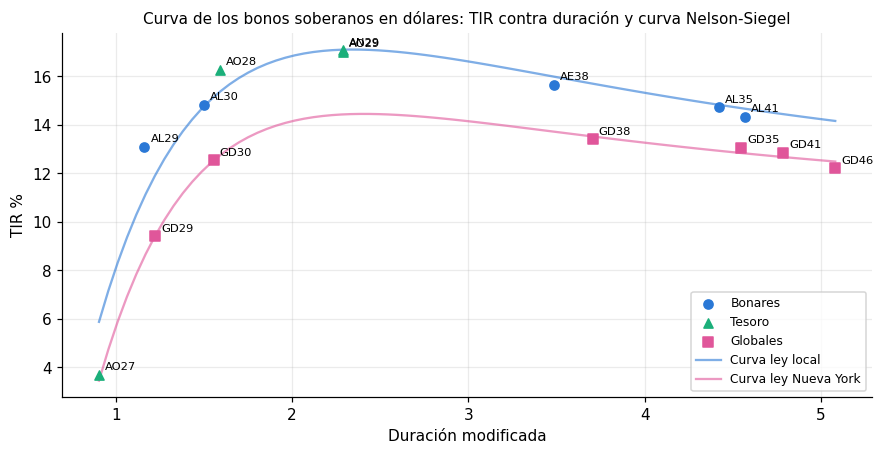

• La TIR mediana es 13,41%: va de 3,70% (AO27) a 17,08% (AN29).
• A igual vencimiento, los Bonares (ley local) rinden en mediana 225 pb más que los Globales (ley Nueva York): es la prima que pide el mercado por la legislación argentina.
• Contra su propia curva, el más barato es AL29 (+207 pb) y el más caro, AO27 (-218 pb).


In [ ]:
#@title 4.1 Curva en dólares { run: "auto" }
FAMILIAS = "Bonares, Globales, Tesoro"  #@param ["Bonares, Globales, Tesoro", "Bonares", "Globales", "Tesoro", "Bonares, Globales"]
fams = [f.strip() for f in FAMILIAS.split(",")]
tu = tabla_usd[tabla_usd["familia"].isin(fams)].copy()
tu["var"] = [(PAN["t1"].get(t + SUF) or [0] * 8)[7] for t in tu.index]      # variación del día que informa BYMA
print(f"Liquidación {liq_usd:%d/%m/%Y} · precios en dólar {'cable (tickers C)' if MONEDA == 'ccl' else 'MEP (tickers D)'}")
display(tu[["familia", "ley", "precio", "var", "tir", "md", "convexidad", "vt", "paridad", "current_yield", "spread_pb"]]
        .style.format({"precio": "{:.2f}", "var": "{:+.2%}", "tir": "{:.2%}", "md": "{:.2f}", "convexidad": "{:.1f}", "vt": "{:.2f}", "paridad": "{:.1%}",
                       "current_yield": "{:.2%}", "spread_pb": "{:+.0f}"}, **AR)
        .map(lambda v: f"color: {VERDE if v > 0 else ROJO if v < 0 else 'inherit'}", subset=["var"]))

fig, ax = plt.subplots(figsize=(9.5, 4.3))
for fam, color, mk in (("Bonares", "#2a78d6", "o"), ("Tesoro", "#1baf7a", "^"), ("Globales", "#e0569a", "s")):
    x = tu[tu["familia"] == fam]
    ax.scatter(x["md"], x["tir"] * 100, color=color, marker=mk, label=fam, zorder=3)
    for t, r in x.iterrows():
        ax.annotate(t, (r["md"], r["tir"] * 100), xytext=(4, 3), textcoords="offset points", fontsize=7.5)
g = np.linspace(tabla_usd["md"].min(), tabla_usd["md"].max(), 80)
for ley, color in (("Local", "#2a78d6"), ("Nueva York", "#e0569a")):
    ax.plot(g, B.nelson_siegel(g, *tabla_usd.attrs[ley]) * 100, color=color, alpha=.6, label=f"Curva ley {'local' if ley == 'Local' else 'Nueva York'}")
ax.set_xlabel("Duración modificada"); ax.set_ylabel("TIR %"); ax.grid(alpha=.25); ax.legend(fontsize=8)
ax.set_title("Curva de los bonos soberanos en dólares: TIR contra duración y curva Nelson-Siegel", fontsize=10)
plt.show()

# Lectura de los resultados
gd = tabla_usd[tabla_usd["ley"] == "Nueva York"]; al = tabla_usd[tabla_usd["familia"] == "Bonares"]
pares = [(a, "GD" + a[2:]) for a in al.index if "GD" + a[2:] in gd.index]
prima = np.median([(tabla_usd.loc[a, "tir"] - tabla_usd.loc[g_, "tir"]) * 1e4 for a, g_ in pares]) if pares else np.nan
barato, caro = tu["spread_pb"].idxmax(), tu["spread_pb"].idxmin()
print(f"• La TIR mediana es {pct(tu['tir'].median())}: va de {pct(tu['tir'].min())} ({tu['tir'].idxmin()}) a {pct(tu['tir'].max())} ({tu['tir'].idxmax()}).")
print(f"• A igual vencimiento, los Bonares (ley local) rinden en mediana {n_ar(prima, 0)} pb más que los Globales (ley Nueva York): "
      "es la prima que pide el mercado por la legislación argentina.")
print(f"• Contra su propia curva, el más barato es {barato} ({tu.loc[barato, 'spread_pb']:+.0f} pb) y el más caro, {caro} ({tu.loc[caro, 'spread_pb']:+.0f} pb).")

In [ ]:
#@title ¿Cuánto ganás o perdés según la TIR a la que vendas? { run: "auto" }
MESES_HASTA_LA_VENTA = 6  #@param {type:"slider", min:1, max:36, step:1}
ESCENARIOS = "Cambio de TIR (pb)"  #@param ["Cambio de TIR (pb)", "TIR de salida (%)"]
modo = "pb" if ESCENARIOS.startswith("Cambio") else "tir"
ESC = [-300, -200, -100, -50, 0, 50, 100, 200, 300] if modo == "pb" else [6, 7, 8, 9, 10, 11, 12, 13, 14]
hz = liq_usd + timedelta(days=round(MESES_HASTA_LA_VENTA * 365 / 12))
nom = {e: ((f"{e:+d} pb" if e else "TIR igual") if modo == "pb" else f"TIR {e}%") for e in ESC}
RET = H.tabla_retornos(tabla_usd[tabla_usd["familia"].isin(fams)], liq_usd, hz, ESC, modo).rename(columns=nom)
print(f"Ganancia total en dólares del {liq_usd:%d/%m/%Y} al {hz:%d/%m/%Y} ({(hz - liq_usd).days} días): cupones cobrados más el precio de venta")
display(RET[["familia", "precio", "tir", "md"] + list(nom.values())]
        .style.format({"precio": "{:.2f}", "tir": "{:.2%}", "md": "{:.2f}", **{v: "{:+.1%}" for v in nom.values()}}, **AR)
        .map(lambda v: f"color: {VERDE if v > 0 else ROJO if v < 0 else 'inherit'}", subset=list(nom.values())))
largo, corto = RET["md"].idxmax(), RET["md"].idxmin()
if modo == "pb":
    print(f"• Si las tasas no se mueven, {corto} gana {pct(RET.loc[corto, 'TIR igual'], 1)} y {largo} {pct(RET.loc[largo, 'TIR igual'], 1)}.")
    print(f"• Si la TIR baja 200 pb, {largo} (el de más duración) gana {pct(RET.loc[largo, '-200 pb'], 1)}; si sube 200 pb, {pct(RET.loc[largo, '+200 pb'], 1)}: "
          "la duración amplifica los movimientos de tasa.")
else:
    print(f"• Cada columna es la TIR a la que vendés. Vender {largo} con TIR 8% da {pct(RET.loc[largo, 'TIR 8%'], 1)}; con TIR 12%, {pct(RET.loc[largo, 'TIR 12%'], 1)}.")

Ganancia total en dólares del 11/11/2026 al 12/05/2027 (182 días): cupones cobrados más el precio de venta


,familia,precio,tir,md,-300 pb,-200 pb,-100 pb,-50 pb,TIR igual,+50 pb,+100 pb,+200 pb,+300 pb
ticker,,,,,,,,,,,,,
AL29,Bonares,"51,64","13,11%","1,16","+8,1%","+7,2%","+6,3%","+5,9%","+5,5%","+5,1%","+4,7%","+3,9%","+3,1%"
AL30,Bonares,"51,30","14,83%","1,50","+10,1%","+8,8%","+7,6%","+7,0%","+6,4%","+5,8%","+5,2%","+4,1%","+2,9%"
AE38,Bonares,"66,20","15,66%","3,49","+18,2%","+14,3%","+10,7%","+9,0%","+7,3%","+5,7%","+4,1%","+1,1%","-1,7%"
AL35,Bonares,"63,19","14,72%","4,42","+21,0%","+16,0%","+11,3%","+9,1%","+6,9%","+4,8%","+2,8%","-1,1%","-4,9%"
AL41,Bonares,"59,33","14,35%","4,57","+21,7%","+16,3%","+11,4%","+9,0%","+6,8%","+4,6%","+2,5%","-1,5%","-5,2%"
GD29,Globales,"53,96","9,42%","1,22","+6,7%","+5,8%","+4,9%","+4,4%","+4,0%","+3,6%","+3,2%","+2,3%","+1,5%"
GD30,Globales,"53,13","12,54%","1,55","+9,3%","+8,0%","+6,7%","+6,1%","+5,4%","+4,8%","+4,2%","+3,1%","+1,9%"
GD38,Globales,"71,78","13,41%","3,71","+17,9%","+13,8%","+9,9%","+8,1%","+6,3%","+4,6%","+2,9%","-0,2%","-3,2%"
GD35,Globales,"68,09","13,06%","4,55","+20,6%","+15,5%","+10,7%","+8,4%","+6,2%","+4,0%","+1,9%","-2,1%","-5,9%"


• Si las tasas no se mueven, AO27 gana 1,8% y GD46 5,6%.
• Si la TIR baja 200 pb, GD46 (el de más duración) gana 16,5%; si sube 200 pb, -3,4%: la duración amplifica los movimientos de tasa.


### 4.2 Obligaciones negociables · pestaña «ONs»


In [ ]:
#@title 4.2 ONs: todas, con filtros { run: "auto" }
EMISOR = "Todos"  #@param ["Todos", "YPF", "Pampa Energía", "Vista Energy", "Telecom", "IRSA", "Pan American Energy"] {allow-input: true}
BUSCAR_TICKER = ""  #@param {type:"string"}
ORDENAR_POR = "Volumen"  #@param ["Volumen", "Precio", "Variación", "Spread entre puntas"]
ONS, F_ONS = X.cargar_ons(EN_VIVO)
FICH = X.cargar_fichas(sorted(set(ONS["raiz"])), usar_api=EN_VIVO) if len(ONS) else {}
TO = X.tabla_ons(ONS, MEP, FICH)
ON_OK = X.ons_calculables(TO, FICH, liq_usd, MONEDA)          # en dólares, a tasa fija, con TIR
ONS_S = H.spread_ons(ON_OK, tabla_usd)
print(f"ONs: {F_ONS}")
print(f"  {TO['precio_mep'].notna().sum()} con precio en MEP de {len(TO)} · volumen US$ {n_ar(TO['volumen_usd'].sum() / 1e6, 1)} M · "
      f"MEP implícito (mediana) $ {n_ar(TO['mep_implicito'].median())} contra $ {n_ar(MEP)} del AL30 · canje (mediana) {pct(TO['canje'].median(), 1)}")
col = {"Volumen": "volumen_usd", "Precio": "precio_mep", "Variación": "var", "Spread entre puntas": "spread_puntas"}[ORDENAR_POR]
V_ = TO.copy()
if EMISOR != "Todos":
    V_ = V_[V_["emisor"].str.contains(EMISOR, case=False, na=False)]
if BUSCAR_TICKER.strip():
    V_ = V_[V_.index.str.contains(BUSCAR_TICKER.strip().upper(), regex=False)]
V_ = V_.sort_values(col, ascending=col == "spread_puntas")
print(f"  Mostrando {min(len(V_), 25)} de {len(V_)} ONs")
display(V_.head(25)[["emisor", "vence", "cupon", "precio_mep", "var", "precio_cable", "precio_pesos", "mep_implicito", "canje", "volumen_usd"]]
        .style.format({"vence": "{:%d/%m/%Y}", "cupon": "{:.2%}", "precio_mep": "{:.2f}", "var": "{:+.2%}", "precio_cable": "{:.2f}",
                       "precio_pesos": "{:,.0f}", "mep_implicito": "{:,.2f}", "canje": "{:+.1%}", "volumen_usd": "{:,.0f}"}, na_rep="", **AR))

ONs: data912 (en vivo, 07/11 19:04)
  255 con precio en MEP de 291 · volumen US$ 8,4 M · MEP implícito (mediana) $ 1.578,73 contra $ 1.583,82 del AL30 · canje (mediana) 5,5%
  Mostrando 25 de 291 ONs


,emisor,vence,cupon,precio_mep,var,precio_cable,precio_pesos,mep_implicito,canje,volumen_usd
ticker,,,,,,,,,,
YFCJ,YPF Luz,16/10/2032,"7,88%","102,80","+0,10%",,162.490,"1.580,64",,517.503
VSCX,Vista Energy,08/04/2038,"7,88%","100,10","+0,77%","93,80",157.650,"1.574,93","+6,7%",398.543
YM34,YPF,17/01/2034,"8,25%","107,25","-0,14%","104,65",169.430,"1.579,77","+2,5%",372.865
IRCP,IRSA,31/03/2035,"8,00%","103,80","+0,78%","97,50",163.700,"1.577,07","+6,5%",369.170
OTS2,Otamerica Ebytem,24/04/2027,"7,00%","102,10","+0,00%",,163.280,"1.599,22",,351.125
YMCX,YPF,11/09/2031,"8,75%","108,05","+0,51%","103,00",170.690,"1.579,73","+4,9%",335.349
PLC7,Pluspetrol,30/09/2037,"7,55%","99,80","+0,20%","94,00",157.500,"1.578,16","+6,2%",272.806
PN36,Pan American Energy,13/11/2031,"7,25%","107,90","-0,14%",,169.950,"1.575,07",,260.582
TLCM,Telecom,18/07/2031,"9,50%","110,75","+1,61%","104,45",175.980,"1.588,98","+6,0%",248.445


In [ ]:
#@title Calculadora de TIR de una ON { run: "auto" }
ON = ""  #@param {type:"string"}
PRECIO = 0.0  #@param {type:"number"}
CUPON_ANUAL_PCT = 0.0  #@param {type:"number"}
PAGOS_POR_ANIO = "como dice la ficha"  #@param ["como dice la ficha", "1", "2", "4", "12"]
CUOTAS_QUE_FALTAN = 0  #@param {type:"integer"}
RESIDUAL = 100.0  #@param {type:"number"}
#@markdown **ON**: el ticker sin la letra final (por ejemplo `MGCO`, `YM34`); vacío = la más operada del día. En **PRECIO**, **CUPÓN** y **CUOTAS**, 0 = lo que dicen el precio MEP de hoy y la ficha técnica de BYMA.
con_d = TO[TO["precio_mep"].notna()].sort_values("volumen_usd", ascending=False)
on_sel = ON.strip().upper() or con_d.index[0]
if on_sel not in TO.index and on_sel[:-1] in TO.index:          # MGCOD, MGCOC o MGCOO → MGCO
    on_sel = on_sel[:-1]
if on_sel not in TO.index:
    print(f"No encuentro la ON {on_sel}. Algunas con precio: {', '.join(con_d.index[:12])}")
elif on_sel not in con_d.index and not PRECIO:
    print(f"{on_sel} no tiene precio MEP hoy: cargá un PRECIO para calcularla igual. Algunas con precio: {', '.join(con_d.index[:12])}")
else:
    fi = FICH.get(on_sel) or X.FICHAS.get(on_sel) or [None] * 9
    venc = date.fromisoformat(fi[1]) if fi[1] and fi[1] > liq_usd.isoformat() else date(2030, 6, 30)
    cup = (CUPON_ANUAL_PCT or (fi[4] if fi[4] is not None else 8.0)) / 100
    frec = int(PAGOS_POR_ANIO) if PAGOS_POR_ANIO.isdigit() else (fi[6] if fi[6] in (1, 2, 4, 12) else 2)
    cuotas = CUOTAS_QUE_FALTAN or int(fi[7] or 1)
    px = PRECIO or float(TO.loc[on_sel, "precio_mep"])
    fl = X.flujos_on(venc, cup, frec, cuotas, liq_usd, RESIDUAL)
    y, md = X.tir_on(px, fl, liq_usd)
    ic = X.interes_corrido_on(venc, cup, frec, liq_usd, RESIDUAL)
    print(f"{on_sel}D · {fi[0] or 'emisor sin ficha'} {fi[8] or ''} · vence {venc:%d/%m/%Y} · cupón {pct(cup, 3)} · {frec} pagos por año · {cuotas} cuota(s)")
    print(f"Precio {n_ar(px)} · TIR {pct(y) if np.isfinite(y) else '–'} · duración modificada {n_ar(md) if np.isfinite(md) else '–'} · "
          f"valor técnico {n_ar(RESIDUAL + ic)} (residual {n_ar(RESIDUAL, 0)} + corrido {n_ar(ic)}) · paridad técnica {pct(px / (RESIDUAL + ic), 1)}")
    display(pd.DataFrame([{"paga": f, "renta": c, "capital": a, "total": c + a} for f, c, a in fl]).set_index("paga")
            .style.format_index("{:%d/%m/%Y}").format({"renta": "{:.3f}", "capital": "{:.2f}", "total": "{:.3f}"}, **AR)
            .set_caption("Pagos por 100 VN: las fechas se cuentan hacia atrás desde el vencimiento (una aproximación al prospecto)"))

YFCJD · YPF Energía Eléctrica S.A. Clase XVIII · vence 16/10/2032 · cupón 7,875% · 2 pagos por año · 1 cuota(s)
Precio 102,80 · TIR 7,53% · duración modificada 4,50 · valor técnico 100,55 (residual 100 + corrido 0,55) · paridad técnica 102,2%


,renta,capital,total
paga,,,
16/04/2027,"3,938","0,00","3,938"
16/10/2027,"3,938","0,00","3,938"
16/04/2028,"3,938","0,00","3,938"
16/10/2028,"3,938","0,00","3,938"
16/04/2029,"3,938","0,00","3,938"
16/10/2029,"3,938","0,00","3,938"
16/04/2030,"3,938","0,00","3,938"
16/10/2030,"3,938","0,00","3,938"
16/04/2031,"3,938","0,00","3,938"


### 4.3 Bonos del Tesoro en pesos · pestaña «Tesoro en pesos»



Supuestos: plazo 24HS · precio VWAP · TAMAR 23,94% · inflación después del REM 1,70% mensual · dólar: futuros de A3 (último contrato DLR/NOV27)
Liquidación 12/11/2026 · LECAP: 3 · BONCAP y BONTE: 5 · CER: 22 · TAMAR: 5 · Duales: 7 · Dólar linked: 6
Inflación breakeven TZX27: 1,90% mensual · REM 1,66%


,tipo,vence,dias,precio,pago_final,tna,tem,tirea
ticker,,,,,,,,
S13N6,LECAP,13/11/2026,1,"109,500","109,651","50,46%","4,23%","65,58%"
S30N6,LECAP,30/11/2026,18,"128,415","129,888","23,26%","1,92%","26,03%"
T15E7,BONCAP,15/01/2027,64,"154,400","161,104","24,76%","2,01%","27,43%"
S29E7,LECAP,29/01/2027,78,"106,150","111,685","24,40%","1,97%","26,85%"
T30A7,BONCAP,30/04/2027,169,"139,290","157,341","27,99%","2,19%","30,11%"
T31Y7,BONCAP,31/05/2027,200,"130,911","151,563","28,79%","2,22%","30,65%"
T30J7,BONCAP,30/06/2027,230,"132,150","156,037","28,69%","2,19%","30,17%"
TY30P,BONTE,30/05/2030,1.295,"113,700",,,"2,27%","31,42%"


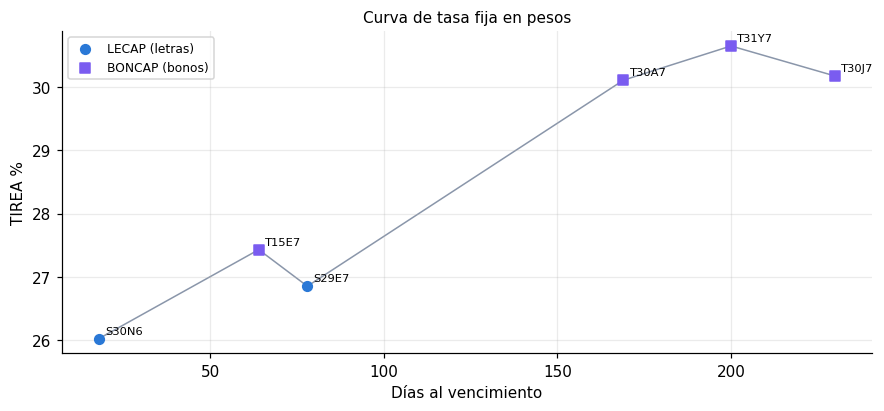

,tipo,vence,dias,precio,valor_tecnico,tir_real,be_mensual,rem_mensual
ticker,,,,,,,,
X30N6,LECER,30/11/2026,18,"130,10","130,47","5,90%",,
TZXD6,BONCER,15/12/2026,33,"316,30","317,55","4,45%",,
X29E7,LECER,29/01/2027,78,"105,30","105,55","1,12%","1,91%","1,63%"
TZXM7,BONCER,31/03/2027,139,"235,00","238,21","3,63%","1,80%","1,68%"
TZXA7,BONCER,30/04/2027,169,"130,50","132,03","2,55%","1,94%","1,65%"
TZXY7,BONCER,31/05/2027,200,"127,40","130,47","4,45%","1,85%","1,66%"
TZX27,BONCER,30/06/2027,230,"418,50","429,52","4,21%","1,90%","1,66%"
TZXS7,BONCER,30/09/2027,322,"113,95","119,04","5,07%",,"1,66%"
TZXO7,BONCER,29/10/2027,351,"102,80","108,75","6,02%",,"1,66%"


,inflacion,fuente,bono,tea,rem,dif_rem_pb
mes,,,,,,
2026-07,"2,10%",INDEC (publicado),,"28,3%",,
2026-08,"1,70%",INDEC (publicado),,"22,4%",,
2026-09,"1,90%",INDEC (publicado),,"25,3%","1,90%",+0
2026-10,"1,91%",Breakeven despejado,X29E7,"25,5%","1,70%",+21
2026-11,"1,91%",Breakeven despejado,X29E7,"25,5%","1,62%",+30
2026-12,"1,69%",Breakeven despejado,TZXM7,"22,2%","1,80%",-11
2027-01,"1,69%",Breakeven despejado,TZXM7,"22,2%","1,60%",+9
2027-02,"2,05%",Breakeven despejado,TZX27,"27,5%","1,60%",+45
2027-03,"2,05%",Breakeven despejado,TZX27,"27,5%","1,70%",+35


,vence,dias,precio,margen,tamar_prom,tirea,tamar_be
ticker,,,,,,,
TMF27,26/02/2027,106,"127,80","6,50","24,94","28,79%","23,52"
TML27,30/07/2027,260,"113,30","5,40","23,57","30,11%","24,73"
TMG27,31/08/2027,292,"122,60","6,00","23,57","30,45%","24,75"
TMF28,25/02/2028,470,"112,20","6,50","23,31","40,32%","17,92"
TMG28,31/08/2028,658,"108,55","6,90","23,27","41,39%","16,95"


,patas,vence,dias,precio,pago_pata1,pago_tamar,paga,tirea,tamar_cruce
ticker,,,,,,,,,
TTD26,Tasa fija/TAMAR,15/12/2026,33,"176,62","161,14","180,73",TAMAR,"28,94%","0,00"
TMVE8,Dólar/TAMAR,31/01/2028,445,"147000,00","211.396,87","213.964,37",TAMAR,"36,06%","22,90"
TXMJ8,CER/TAMAR,30/06/2028,596,"103,90","157,92","175,54",TAMAR,"37,88%","17,22"
TXMD8,CER/TAMAR,15/12/2028,764,"94,25","168,42","194,57",TAMAR,"41,38%","16,83"
TXMJ9,CER/TAMAR,29/06/2029,960,"95,00","196,26","231,36",TAMAR,"40,27%","17,50"
TXMD9,CER/TAMAR,14/12/2029,1.128,"87,61","206,19","253,74",TAMAR,"41,07%","17,04"
TXMJ0,CER/TAMAR,28/06/2030,1.324,"84,80","229,81","292,89",TAMAR,"40,73%","17,08"


,vence,dias,precio,precio_usd,tir_usd,dolar_esperado,suba_esperada,tirea_esperada,tirea_fija,vs_fija_pb,cobro_100k,dolar_be
ticker,,,,,,,,,,,,
D30N6,30/11/2026,18,154.750,"100,14","-2,72%",1.564,"+1,2%","24,72%","25,85%",-113,101.095,1.565
D15E7,15/01/2027,64,154.000,"99,65","2,02%",1.611,"+4,2%","29,15%","27,23%",+192,104.587,1.606
D31M7,31/03/2027,139,154.990,"100,29","-0,76%",1.685,"+9,0%","24,50%","29,06%",-456,108.702,1.708
TZV27,30/06/2027,230,153.200,"99,13","1,39%",1.783,"+15,4%","27,26%","30,67%",-341,116.403,1.813
TZV28,30/06/2028,596,126.850,"82,08","12,85%",2.354,"+52,3%","46,02%","32,41%",+1361,185.559,2.006
TZVD8,15/12/2028,764,117.000,"75,71","14,22%",2.649,"+71,4%","47,75%","31,57%",+1618,226.380,2.078


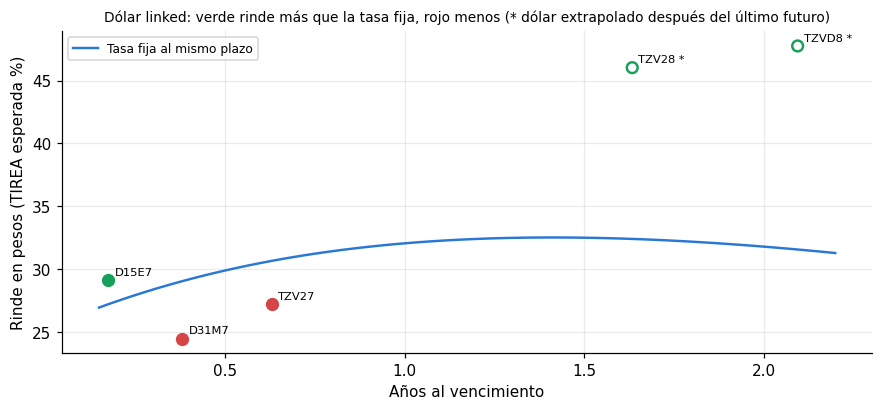

• La tasa fija rinde 2,19% mensual a unos 6 meses (T30A7, TIREA 30,1%) y 2,19% a 230 días (T30J7).
• Los bonos CER rinden entre 1,12% y 12,13% real según el plazo (por encima de la inflación).
• La inflación que descuenta el mercado es 1,91% mensual en oct-26; en promedio queda 21 pb por encima del REM.
• Con la TAMAR en 23,94%, la TAMAR de equilibrio de los bonos TAMAR va de 16,95% a 24,75%: el mercado los paga como si la TAMAR fuera a quedar alrededor de 23,52%.
• Los dólar linked rendirían entre 24,5% y 29,1% por año en pesos; 1 de 3 le gana a la tasa fija del mismo plazo (D15E7).


In [ ]:
#@title 4.3 Tesoro en pesos: supuestos y tasa fija { run: "auto" }
PLAZO = "24HS"  #@param ["24HS", "CI"]
PRECIO_P = "VWAP"  #@param ["VWAP", "Último", "Cierre anterior"]
TAMAR_SUPUESTA = ""  #@param {type:"string"}
INFLACION_MENSUAL_DESPUES_DEL_REM = ""  #@param {type:"string"}
DEVALUACION_MENSUAL = ""  #@param {type:"string"}
#@markdown Vacío = el valor por defecto de la app: **TAMAR** (TNA %), el promedio de las últimas 5 ruedas; **inflación** (% mensual), la última mediana del REM; **devaluación** (% mensual, para dólar linked y TMVE8), el dólar que esperan los futuros de A3.
num = lambda s: float(s.replace(",", ".")) if s.strip() else None
TAMAR0 = num(TAMAR_SUPUESTA) or round(float(DP["tamar"].sort_index().iloc[-5:].mean()), 2)
INFL0 = (num(INFLACION_MENSUAL_DESPUES_DEL_REM) or round(float(D["rem_mensual"]["mediana"].dropna().iloc[-1]), 2)) / 100
DEV0 = None if num(DEVALUACION_MENSUAL) is None else num(DEVALUACION_MENSUAL) / 100
IPC_PUB = D["macro"]["ipc"].dropna().to_dict()
REM = D["rem_mensual"]["mediana"].dropna().to_dict()
# dólar oficial que esperan los futuros de A3 para cada fecha (lo usan los dólar linked y el TMVE8)
tc = DP["a3500"].sort_index(); f_fut = FUT["fecha"].iloc[0]
spot_f = float(tc[tc.index <= pd.Timestamp(f_fut)].iloc[-1]) if (tc.index <= pd.Timestamp(f_fut)).any() else float(tc.iloc[-1])
TF = X.devaluacion_futuros(FUT, spot_f, f_fut)
FD = P.dolar_esperado_futuros(TF, spot_f, f_fut)
precio_k = {"VWAP": "px", "Último": "last", "Cierre anterior": "prev"}[PRECIO_P]
RP = P.calcular(DP, PLAZO, precio_k, TAMAR0, INFL0, ipc_publicado=IPC_PUB, rem_mensual=REM, dev=DEV0, dolar_fut=FD)
print(f"Supuestos: plazo {PLAZO} · precio {PRECIO_P} · TAMAR {n_ar(TAMAR0)}% · inflación después del REM {pct(INFL0)} mensual · dólar: "
      + ("futuros de A3 (último contrato " + TF["contrato"].iloc[-1] + ")" if DEV0 is None else f"devaluación de {pct(DEV0)} mensual"))
print(f"Liquidación {RP['liq']:%d/%m/%Y} · " + " · ".join(f"{nombre}: {len(RP[k])}" for k, nombre, _ in P.TIPOS))
BE0 = RP["cer"][np.isfinite(RP["cer"]["be_mensual"].astype(float))]
if len(BE0):
    print(f"Inflación breakeven {BE0.index[-1]}: {pct(BE0['be_mensual'].iloc[-1])} mensual · REM {pct(BE0['rem_mensual'].iloc[-1])}")

fija = pd.concat([RP["lecap"], RP["boncap"]]).sort_values("dias")
display(fija[["tipo", "vence", "dias", "precio", "pago_final", "tna", "tem", "tirea"]]
        .style.format({"vence": "{:%d/%m/%Y}", "precio": "{:.3f}", "pago_final": "{:.3f}", "tna": "{:.2%}", "tem": "{:.2%}", "tirea": "{:.2%}"}, na_rep="", **AR))
f_ = fija[(fija["dias"] >= 15) & fija["tipo"].isin(["LECAP", "BONCAP"])]
fig, ax = plt.subplots(figsize=(9.5, 3.8))
for tipo, mk, c in (("LECAP", "o", "#2a78d6"), ("BONCAP", "s", "#7a5cf0")):
    x = f_[f_["tipo"] == tipo]
    ax.scatter(x["dias"], x["tirea"] * 100, marker=mk, color=c, s=40, zorder=3, label=f"{tipo} ({'letras' if tipo == 'LECAP' else 'bonos'})")
    for t, r in x.iterrows():
        ax.annotate(t, (r["dias"], r["tirea"] * 100), xytext=(4, 3), textcoords="offset points", fontsize=7.5)
ax.plot(f_["dias"], f_["tirea"] * 100, color="#8a96aa", lw=1, zorder=1)
ax.set_xlabel("Días al vencimiento"); ax.set_ylabel("TIREA %"); ax.grid(alpha=.25); ax.legend(fontsize=8)
ax.set_title("Curva de tasa fija en pesos", fontsize=10)
plt.show()

# CER: tasa real e inflación breakeven, y la inflación mes a mes que descuenta el mercado
cer = RP["cer"]
display(cer[["tipo", "vence", "dias", "precio", "valor_tecnico", "tir_real", "be_mensual", "rem_mensual"]].sort_values("dias")
        .style.format({"vence": "{:%d/%m/%Y}", "precio": "{:.2f}", "valor_tecnico": "{:.2f}", "tir_real": "{:.2%}", "be_mensual": "{:.2%}",
                       "rem_mensual": "{:.2%}"}, na_rep="", **AR))
TRY = P.trayectoria_be(RP)    # inflación mes a mes que descuenta el mercado, despejada bono por bono
display(TRY.style.format({"inflacion": "{:.2%}", "tea": "{:.1%}", "rem": "{:.2%}", "dif_rem_pb": "{:+.0f}"}, na_rep="", **AR))

# TAMAR y duales: TIREA estimada con la TAMAR supuesta y la TAMAR que los empata con la tasa fija
display(RP["tamar"][["vence", "dias", "precio", "margen", "tamar_prom", "tirea", "tamar_be"]]
        .style.format({"vence": "{:%d/%m/%Y}", "precio": "{:.2f}", "margen": "{:.2f}", "tamar_prom": "{:.2f}", "tirea": "{:.2%}", "tamar_be": "{:.2f}"},
                      na_rep="", **AR))
display(RP["dual"][["patas", "vence", "dias", "precio", "pago_pata1", "pago_tamar", "paga", "tirea", "tamar_cruce"]]
        .style.format({"vence": "{:%d/%m/%Y}", "precio": "{:.2f}", "pago_pata1": "{:,.2f}", "pago_tamar": "{:,.2f}", "tirea": "{:.2%}",
                       "tamar_cruce": "{:.2f}"}, na_rep="", **AR))

# Dólar linked: cuánto rendirían en pesos con el dólar de los futuros de A3 (o con la devaluación elegida)
dlk = RP["dl"]
display(dlk[["vence", "dias", "precio", "precio_usd", "tir_usd", "dolar_esperado", "suba_esperada", "tirea_esperada", "tirea_fija", "vs_fija_pb",
             "cobro_100k", "dolar_be"]]
        .style.format({"vence": "{:%d/%m/%Y}", "precio": "{:,.0f}", "precio_usd": "{:.2f}", "tir_usd": "{:.2%}", "dolar_esperado": "{:,.0f}",
                       "suba_esperada": "{:+.1%}", "tirea_esperada": "{:.2%}", "tirea_fija": "{:.2%}", "vs_fija_pb": "{:+.0f}", "cobro_100k": "{:,.0f}",
                       "dolar_be": "{:,.0f}"}, na_rep="", **AR))
g_ = dlk[dlk["dias"] >= 30]
fig, ax = plt.subplots(figsize=(9.5, 3.8))
for t, r in g_.iterrows():
    c = VERDE if r["vs_fija_pb"] > 0 else ROJO
    ax.scatter(r["x"], r["tirea_esperada"] * 100, s=50, zorder=3, facecolors="none" if r["extrapolado"] else c, edgecolors=c, linewidths=1.6)
    ax.annotate(t + (" *" if r["extrapolado"] else ""), (r["x"], r["tirea_esperada"] * 100), xytext=(4, 3), textcoords="offset points", fontsize=7.5)
xx = np.linspace(g_["x"].min() * 0.85, g_["x"].max() * 1.05, 80)
ax.plot(xx, [RP["curva_fija"](x) * 100 for x in xx], color="#2a78d6", lw=1.6, label="Tasa fija al mismo plazo")
ax.set_xlabel("Años al vencimiento"); ax.set_ylabel("Rinde en pesos (TIREA esperada %)"); ax.grid(alpha=.25); ax.legend(fontsize=8)
ax.set_title("Dólar linked: verde rinde más que la tasa fija, rojo menos (* dólar extrapolado después del último futuro)", fontsize=9)
plt.show()

# Lectura de los resultados
c6 = f_.iloc[(f_["dias"] - 182).abs().argsort().iloc[0]]; c12 = f_.iloc[(f_["dias"] - 365).abs().argsort().iloc[0]]
print(f"• La tasa fija rinde {pct(c6['tem'])} mensual a unos 6 meses ({c6.name}, TIREA {pct(c6['tirea'], 1)}) y {pct(c12['tem'])} a {int(c12['dias'])} días ({c12.name}).")
tr = cer[cer["dias"] >= 30]["tir_real"]
print(f"• Los bonos CER rinden entre {pct(tr.min())} y {pct(tr.max())} real según el plazo (por encima de la inflación).")
be = TRY[TRY["fuente"] != "INDEC (publicado)"].dropna(subset=["rem"])
if len(be):
    print(f"• La inflación que descuenta el mercado es {pct(be['inflacion'].iloc[0])} mensual en {B.mes_corto(be.index[0])}; en promedio queda "
          f"{abs(be['dif_rem_pb'].mean()):.0f} pb {'por encima' if be['dif_rem_pb'].mean() > 0 else 'por debajo'} del REM.")
tb = RP["tamar"]["tamar_be"].dropna()
if len(tb):
    print(f"• Con la TAMAR en {n_ar(TAMAR0)}%, la TAMAR de equilibrio de los bonos TAMAR va de {n_ar(tb.min())}% a {n_ar(tb.max())}%: "
          f"el mercado los paga como si la TAMAR fuera a quedar alrededor de {n_ar(tb.median())}%.")
dl6 = dlk[(dlk["dias"] >= 30) & ~dlk["extrapolado"]]
if len(dl6):
    gana = dl6[dl6["vs_fija_pb"] > 0]
    print(f"• Los dólar linked rendirían entre {pct(dl6['tirea_esperada'].min(), 1)} y {pct(dl6['tirea_esperada'].max(), 1)} por año en pesos; "
          f"{len(gana)} de {len(dl6)} le gana{'' if len(gana) == 1 else 'n'} a la tasa fija del mismo plazo" + (f" ({', '.join(gana.index)})." if len(gana) else "."))

### 4.4 Mi portafolio · pestaña «Mi portafolio»



,grupo,sub,nominales,precio,valor,peso,tir,md,vence
ticker,,,,,,,,,
AL30,Hard dollar,"Bonar, ley local",10.000,"51,30",$ 8.125.000,"22,6%","14,83%","1,50",09/07/2030
GD35,Hard dollar,"Global, ley Nueva York",3.000,"68,09",$ 3.235.270,"9,0%","13,06%","4,55",09/07/2035
AE38,Hard dollar,"Bonar, ley local",3.000,"66,20",$ 3.145.468,"8,8%","15,66%","3,49",09/01/2038
S30N6,Tasa fija,LECAP,3.000.000,"128,41",$ 3.852.450,"10,7%","26,03%","0,04",30/11/2026
T30J7,Tasa fija,BONCAP,2.000.000,"132,15",$ 2.643.000,"7,4%","30,17%","0,48",30/06/2027
TZX27,CER,BONCER,800.000,"418,50",$ 3.348.000,"9,3%","4,21%","0,60",30/06/2027
TZXD6,CER,BONCER,500.000,"316,30",$ 1.581.500,"4,4%","4,45%","0,09",15/12/2026
D31M7,Dólar linked,Dólar linked,1.500,"154.990,00",$ 2.324.850,"6,5%","-0,76%","0,38",31/03/2027
TTD26,Duales,Dual,1.500.000,"176,62",$ 2.649.375,"7,4%","28,94%","0,00",15/12/2026


Valor $ 35.922.457 · duración modificada 1,96 (tasas +1 punto → -1,96%) · DV01 $ 7.026 · convexidad 11,6 · plazo promedio 3,86 años
Mayor exposición: Hard dollar (40%) · equivale a 8,1 bonos de igual peso
Tipo de cartera: Barbell: cargada en las dos puntas (46% en el corto y 32% en el largo) y poco en el medio.


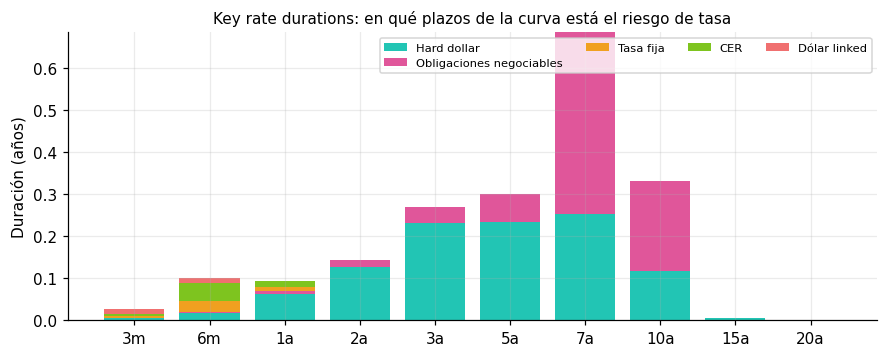

,aprox,completa,pct
salto,,,
-500,$ +4.035.286,$ +4.113.704,"+11,45%"
-100,$ +723.490,$ +724.058,"+2,02%"
100,$ -681.707,$ -682.248,"-1,90%"
500,$ -2.990.698,$ -3.052.643,"-8,50%"


In [ ]:
#@title 4.4 Mi portafolio: tu cartera { run: "auto" }
CARTERA = "AL30:10000, GD35:3000, AE38:3000, S30N6:3000000, T30J7:2000000, TZX27:800000, TZXD6:500000, D31M7:1500, TTD26:1500000, MGCO:3000"  #@param {type:"string"}
ARCHIVO_CSV = ""  #@param {type:"string"}
VALUAR_EN = "Pesos"  #@param ["Pesos", "Dólares"]
#@markdown **CARTERA**: `BONO:NOMINALES` separados por comas (bonos en dólares, en pesos u ONs). **ARCHIVO_CSV**: el nombre de un CSV con las columnas Bono y Nominales que subiste al panel de archivos (por ejemplo el que descarga la app); si está, se usa en lugar de CARTERA.
UPF = PF.agregar_ons(PF.universo(tabla_usd, liq_usd, RP, TC_HOY, MONEDA), ON_OK, liq_usd, TC_HOY)   # todos los bonos que se pueden cargar
MON_PF = "USD" if VALUAR_EN == "Dólares" else "ARS"
mon = "US$" if MON_PF == "USD" else "$"
if ARCHIVO_CSV.strip() and os.path.exists(ARCHIVO_CSV.strip()):
    csv_ = pd.read_csv(ARCHIVO_CSV.strip(), sep=None, engine="python")
    pos = csv_.groupby(csv_["Bono"].astype(str).str.strip().str.upper())["Nominales"].sum().to_dict()
else:
    if ARCHIVO_CSV.strip():
        print(f"No encuentro {ARCHIVO_CSV.strip()} en el panel de archivos: uso CARTERA.")
    pos, malas = {}, []
    for par in CARTERA.split(","):
        t, _, n = par.partition(":")
        try:
            pos[t.strip().upper()] = pos.get(t.strip().upper(), 0) + float(n.strip().replace(".", "").replace(",", "."))
        except ValueError:
            if par.strip():
                malas.append(par.strip())
    if malas:
        print(f"No entiendo {', '.join(malas)}: escribí BONO:NOMINALES (por ejemplo AL30:10000).")
norm = {}
for t, n in pos.items():                                        # AL30D o MGCOD → AL30, MGCO
    t = t[:-1] if t not in UPF and t[:-1] in UPF else t
    norm[t] = norm.get(t, 0) + n
pos = norm
fuera = sorted(t for t in pos if t not in UPF)
if fuera:
    print(f"No están hoy en la lista (sin precio o vencidos), no se cuentan: {', '.join(fuera)}")
pos = {t: n for t, n in pos.items() if t in UPF and n > 0}
if not pos:                                                     # sin bonos válidos: la de ejemplo, para que el resto corra
    print("La cartera quedó vacía, así que uso la de ejemplo.")
    pos = {t.strip(): float(n) for t, n in (par.split(":") for par in "AL30:10000, GD35:3000, AE38:3000, S30N6:3000000, T30J7:2000000, TZX27:800000, TZXD6:500000, D31M7:1500, TTD26:1500000, MGCO:3000".split(","))}
CPF = PF.cartera(UPF, pos, MON_PF, TC_HOY, hoy=liq_usd)
RS = PF.resumen(CPF)
display(CPF.assign(grupo=CPF["grupo"].map(PF.GRUPOS))[["grupo", "sub", "nominales", "precio", "valor", "peso", "tir", "md", "vence"]]
        .style.format({"nominales": "{:,.0f}", "precio": "{:,.2f}", "valor": mon + " {:,.0f}", "peso": "{:.1%}", "tir": "{:.2%}", "md": "{:.2f}",
                       "vence": "{:%d/%m/%Y}"}, **AR))
print(f"Valor {mon} {n_ar(RS['valor'], 0)} · duración modificada {n_ar(RS['md'])} (tasas +1 punto → {pct(-RS['md'] / 100)}) · DV01 {mon} {n_ar(RS['dv01'], 0)} · "
      f"convexidad {n_ar(RS['convexidad'], 1)} · plazo promedio {n_ar(RS['plazo_dias'] / 365)} años")
print(f"Mayor exposición: {PF.GRUPOS[RS['mayor_grupo']]} ({RS['mayor_peso']:.0%}) · equivale a {n_ar(RS['efectivos'], 1)} bonos de igual peso")
TC = PF.tipo_cartera(CPF)
print(f"Tipo de cartera: {TC['tipo']}: {TC['explicacion']}")

# Key rate durations: en qué plazos de la curva está el riesgo de tasa, y movimientos paralelos de todas las tasas
KR = PF.krd_cartera(CPF)
gk = [g for g in PF.GRUPOS if g in KR.columns and KR[g].abs().sum() > 0]
fig, ax = plt.subplots(figsize=(9.5, 3.4))
base = np.zeros(len(KR))
for g in gk:
    ax.bar(KR.index, KR[g], bottom=base, color=PF.COLORES_G[g], label=PF.GRUPOS[g]); base += KR[g].values
ax.set_ylabel("Duración (años)"); ax.grid(alpha=.25, axis="y"); ax.legend(fontsize=7.5, ncol=4)
ax.set_title("Key rate durations: en qué plazos de la curva está el riesgo de tasa", fontsize=10)
plt.show()
PA = PF.paralelos(UPF, CPF)
display(PA.loc[[v for v in PA.index if abs(v) <= 500], ["aprox", "completa", "pct"]]
        .style.format({"aprox": mon + " {:+,.0f}", "completa": mon + " {:+,.0f}", "pct": "{:+.2%}"}, **AR)
        .set_caption("Movimiento paralelo de todas las tasas (pb): aproximación por duración + convexidad contra revaluación completa"))

Suba paralela de 100 pb, en todas las curvas


,3m,6m,1a,2a,3a,5a,7a,10a,15a,20a
Hard dollar,+100,+100,+100,+100,+100,+100,+100,+100,+100,+100
Tasa fija,+100,+100,+100,+100,+100,+100,+100,+100,+100,+100
CER,+100,+100,+100,+100,+100,+100,+100,+100,+100,+100
Dólar linked,+100,+100,+100,+100,+100,+100,+100,+100,+100,+100


Impacto en la cartera $ -413.671 (-1,15% del valor) · con duración (lineal) $ -423.605 · efecto convexidad $ 9.934


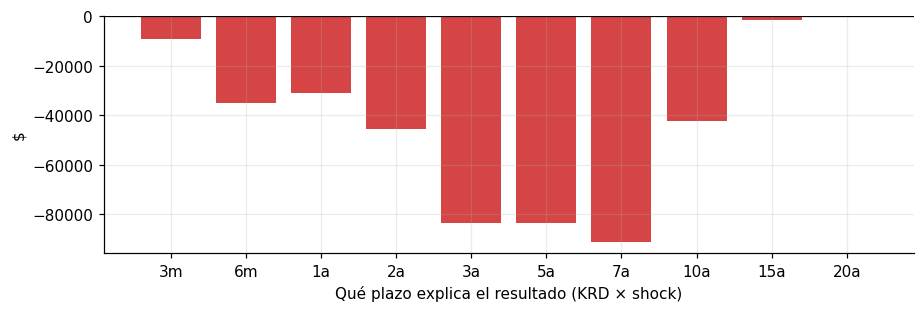

,grupo,valor,cambio,impacto,pct_impacto
ticker,,,,,
GD35,Hard dollar,3.235.270,"-4,41%",-142.686,"34,5%"
AL30,Hard dollar,8.125.000,"-1,48%",-120.125,"29,0%"
AE38,Hard dollar,3.145.468,"-3,38%",-106.335,"25,7%"
TZX27,CER,3.348.000,"-0,60%",-20.087,"4,9%"
T30J7,Tasa fija,2.643.000,"-0,48%",-12.715,"3,1%"
D31M7,Dólar linked,2.324.850,"-0,38%",-8.860,"2,1%"
S30N6,Tasa fija,3.852.450,"-0,04%",-1.501,"0,4%"
TZXD6,CER,1.581.500,"-0,09%",-1.362,"0,3%"
TTD26,Duales,2.649.375,"+0,00%",+0,"-0,0%"


In [ ]:
#@title Escenarios de tasas { run: "auto" }
ESCENARIO = "suba"  #@param ["suba", "baja", "empinamiento", "aplanamiento", "butterfly_pos", "butterfly_neg"]
MAGNITUD_PB = 100  #@param {type:"slider", min:0, max:1000, step:25}
APLICAR_A = "todas"  #@param ["todas", "hd", "fija", "cer", "dl"]
#@markdown **APLICAR_A**: todas las curvas o una sola (hd = bonos en dólares, fija = tasa fija, cer = CER, dl = dólar linked).
print(PF.ESCENARIOS[ESCENARIO], f"de {MAGNITUD_PB} pb,", "en todas las curvas" if APLICAR_A == "todas" else f"solo en {PF.GRUPOS[APLICAR_A]}")
forma = PF.forma_escenario(ESCENARIO, MAGNITUD_PB)
gr_pres = [g for g in ["hd", "fija", "cer", "dl"] if g in CPF["grupo"].values]
shocks = {g: (forma if APLICAR_A in ("todas", g) else np.zeros(len(PF.NODOS))) for g in gr_pres}
display(pd.DataFrame({PF.GRUPOS[g]: v for g, v in shocks.items()}, index=PF.ETIQ_NODOS).T.style.format("{:+.0f}").set_caption("Shock por plazo (pb)"))
EPF = PF.escenario(UPF, CPF, shocks)
imp, lin = EPF["impacto"].sum(), EPF["impacto_lineal"].sum()
print(f"Impacto en la cartera {mon} {n_ar(imp, 0)} ({pct(imp / RS['valor'])} del valor) · con duración (lineal) {mon} {n_ar(lin, 0)} · "
      f"efecto convexidad {mon} {n_ar(imp - lin, 0)}")
ap = PF.aporte_por_nodo(CPF, shocks)
fig, ax = plt.subplots(figsize=(9.5, 2.8))
ax.bar(ap.index, ap.values, color=[VERDE if v >= 0 else ROJO for v in ap.values])
ax.axhline(0, color="black", lw=.8); ax.set_ylabel(mon); ax.set_xlabel("Qué plazo explica el resultado (KRD × shock)"); ax.grid(alpha=.25, axis="y")
plt.show()
display(EPF.assign(grupo=EPF["grupo"].map(PF.GRUPOS))[["grupo", "valor", "cambio", "impacto", "pct_impacto"]].sort_values("impacto")
        .style.format({"valor": "{:,.0f}", "cambio": "{:+.2%}", "impacto": "{:+,.0f}", "pct_impacto": "{:.1%}"}, **AR))

In [ ]:
#@title VaR histórico { run: "auto" }
CONFIANZA = 0.95  #@param [0.95, 0.99]
HORIZONTE_DIAS = 1  #@param [1, 5, 10]
VENTANA_RUEDAS = 500  #@param [120, 250, 500]
FX = ("AL30", "AL30" + SUF)
SIMS = sorted({UPF[t]["simbolo"] for t in CPF.index} | set(FX))
H_PF, F_H = PF.historicos(SIMS, usar_api=EN_VIVO)             # cierres diarios de BYMA (o el respaldo)
R_PF, _ = PF.retornos(UPF, CPF, H_PF, MON_PF, FX)
VR = PF.var_historico(R_PF, CPF["valor"], CONFIANZA, HORIZONTE_DIAS, VENTANA_RUEDAS)
print(f"VaR {CONFIANZA:.0%} a {HORIZONTE_DIAS} día(s): {mon} {n_ar(VR['var'], 0)} ({pct(VR['var_pct'])} del valor) · expected shortfall {mon} {n_ar(VR['es'], 0)} · "
      f"volatilidad anual {pct(VR['vol_anual'], 1)} · {VR['ruedas']} ruedas del {VR['desde']:%d/%m/%Y} al {VR['hasta']:%d/%m/%Y}")
display(VR["por_bono"][["valor", "vol_diaria", "pct_riesgo"]].style.format({"valor": "{:,.0f}", "vol_diaria": "{:.2%}", "pct_riesgo": "{:.1%}"}, **AR)
        .set_caption("Cuánto aporta cada bono al riesgo de la cartera"))

# Lectura de los resultados
sube = PA.loc[100, "pct"] if 100 in PA.index else np.nan
print(f"• Con una duración de {n_ar(RS['md'])}, si todas las tasas suben 1 punto la cartera pierde {pct(-sube)} ({mon} {n_ar(-PA.loc[100, 'completa'], 0)}); "
      f"cada punto básico cuesta {mon} {n_ar(RS['dv01'], 0)}.")
print(f"• El riesgo de tasa está concentrado en el plazo de {KR['total'].idxmax()} (KRD {n_ar(KR['total'].max())}).")
print(f"• En un día malo (1 de cada {round(1 / (1 - CONFIANZA))}) la cartera puede perder más de {mon} {n_ar(VR['var'], 0)}.")

VaR 95% a 1 día(s): $ 294.186 (0,82% del valor) · expected shortfall $ 494.405 · volatilidad anual 10,8% · 485 ruedas del 08/11/2024 al 06/11/2026


,valor,vol_diaria,pct_riesgo
AL30,8.125.000,"1,23%","37,5%"
GD35,3.235.270,"1,51%","18,1%"
AE38,3.145.468,"1,66%","19,3%"
S30N6,3.852.450,"0,22%","0,4%"
T30J7,2.643.000,"0,45%","0,4%"
TZX27,3.348.000,"1,28%","9,5%"
TZXD6,1.581.500,"1,06%","4,2%"
D31M7,2.324.850,"0,23%","0,1%"
TTD26,2.649.375,"1,01%","5,1%"
MGCO,5.017.544,"1,24%","5,5%"


• Con una duración de 1,96, si todas las tasas suben 1 punto la cartera pierde 1,90% ($ 682.248); cada punto básico cuesta $ 7.026.
• El riesgo de tasa está concentrado en el plazo de 7a (KRD 0,68).
• En un día malo (1 de cada 20) la cartera puede perder más de $ 294.186.


### 4.5 Flujos de fondos · pestaña «Flujos de fondos»



AL30 · Bonares · precio en dólar MEP
Inversión US$ 513,00 (1.000 VN a 51,30) · total a cobrar US$ 659,20 · TIR 14,83% · duración modificada 1,50 · próximo pago el 11/01/2027 por US$ 82,40


,dias,renta,capital,total,residual_%,valor_presente
paga,,,,,,
11/01/2027,59,"2,40","80,00","82,40","56,0","80,58"
12/07/2027,240,"2,10","80,00","82,10","48,0","74,96"
10/01/2028,424,"4,20","80,00","84,20","40,0","71,70"
10/07/2028,606,"3,50","80,00","83,50","32,0","66,37"
09/01/2029,790,"2,80","80,00","82,80","24,0","61,38"
10/07/2029,971,"2,10","80,00","82,10","16,0","56,83"
09/01/2030,1155,"1,40","80,00","81,40","8,0","52,55"
10/07/2030,1336,"0,70","80,00","80,70","0,0","48,64"


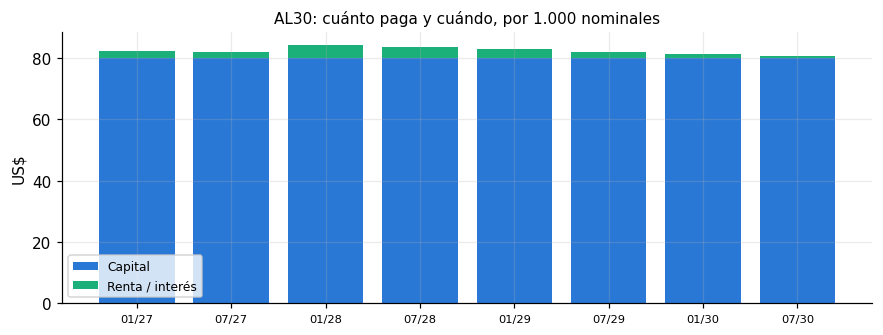

• La suma de los valores presentes (513,00) es lo que pagás hoy: así se verifica la TIR.


In [ ]:
#@title 4.5 Flujos de fondos de un bono { run: "auto" }
BONO = "AL30"  #@param {type:"string"}
NOMINALES = 1000  #@param {type:"number"}
PRECIO_DE_COMPRA = 0.0  #@param {type:"number"}
#@markdown **BONO**: un soberano en dólares (AL30, GD35, AO27…), un bono en pesos (S30N6, T30J7, TZX27, TTD26, D31M7…) o una ON (MGCO, YM34…). **PRECIO_DE_COMPRA**: 0 = el de hoy.
bono_f = BONO.strip().upper()
pesos_tk = {t: nombre for k, nombre, _ in P.TIPOS if len(RP[k]) for t in RP[k].index}
if bono_f[:-1] in set(tabla_usd.index) | set(ON_OK.index) and bono_f not in pesos_tk:   # AL30D o MGCOD → AL30, MGCO
    bono_f = bono_f[:-1]
if bono_f in tabla_usd.index or bono_f in ON_OK.index:          # en dólares: soberano u ON
    es_on = bono_f in ON_OK.index and bono_f not in tabla_usd.index
    if es_on:
        o_ = ON_OK.loc[bono_f]
        px_f = PRECIO_DE_COMPRA or float(o_["precio"])
        fl = X.flujos_on(o_["vence"], float(o_["cupon"]), int(o_["frecuencia"]), int(o_["cuotas"]), liq_usd)
        y_f, md_f = X.tir_on(px_f, fl, liq_usd)
        m_ = {"tir": y_f, "md": md_f, "residual": 100.0}
        print(f"{bono_f} · ON de {o_['emisor']} ({o_['clase']}) · cupón {pct(o_['cupon'], 3)} · fechas contadas desde el vencimiento (aproximación al prospecto)")
    else:
        px_f = PRECIO_DE_COMPRA or float(tabla_usd.loc[bono_f, "precio"])
        fl = [(f, c, a) for f, c, a in USD[bono_f]["flujos"] if f > liq_usd]
        m_ = B.metricas_bono(USD[bono_f], liq_usd, px_f)
        print(f"{bono_f} · {tabla_usd.loc[bono_f, 'familia']} · precio en dólar {'cable' if MONEDA == 'ccl' else 'MEP'}")
    res, filas = m_["residual"], []
    for f, c, a in fl:
        res -= a
        d = (f - liq_usd).days
        filas.append({"paga": L.siguiente_habil(f) if not L.habil(f) else f, "dias": d, "renta": c * NOMINALES / 100, "capital": a * NOMINALES / 100,
                      "total": (c + a) * NOMINALES / 100, "residual_%": res, "valor_presente": (c + a) * NOMINALES / 100 / (1 + m_["tir"]) ** (d / 365)})
    F = pd.DataFrame(filas)
    print(f"Inversión US$ {n_ar(px_f * NOMINALES / 100)} ({n_ar(NOMINALES, 0)} VN a {n_ar(px_f)}) · total a cobrar US$ {n_ar(F['total'].sum())} · "
          f"TIR {pct(m_['tir'])} · duración modificada {n_ar(m_['md'])} · próximo pago el {F['paga'].iloc[0]:%d/%m/%Y} por US$ {n_ar(F['total'].iloc[0])}")
    moneda_f = "US$"
elif bono_f in pesos_tk:                                          # en pesos: tasa fija, CER, TAMAR, duales o dólar linked
    k_tipo = next(k for k, _, _ in P.TIPOS if len(RP[k]) and bono_f in RP[k].index)
    fila = RP[k_tipo].loc[bono_f]
    px_f = PRECIO_DE_COMPRA or float(fila["precio"])
    F = RP["flujos"][bono_f].copy().rename(columns={"fecha": "paga"})
    s0 = RP["liq"]
    F["dias"] = [(f - s0).days for f in F["paga"]]
    F["total"] = F["renta"] + F["capital"]
    y_f = P._tir(list(zip(F["paga"], F["total"])), s0, px_f)
    k_ = NOMINALES / 100
    for c in ["renta", "capital", "total"] + [c for c in ("real", "usd") if c in F]:
        F[c] = F[c] * k_
    F["valor_presente"] = F["total"] / (1 + y_f) ** (F["dias"] / 365)
    print(f"{bono_f} · {pesos_tk[bono_f]} · {fila.get('condicion', '')} · liquida {s0:%d/%m/%Y}. Los pagos se proyectan con los supuestos de la 4.3.")
    print(f"Inversión $ {n_ar(px_f * k_, 0)} ({n_ar(NOMINALES, 0)} VN a {n_ar(px_f)}) · total a cobrar (proyectado) $ {n_ar(F['total'].sum(), 0)} · "
          f"TIREA nominal estimada {pct(y_f)} · próximo pago el {F['paga'].iloc[0]:%d/%m/%Y}")
    moneda_f = "$"
else:
    F = None
    print(f"No encuentro {bono_f}. Soberanos: {', '.join(tabla_usd.index)} · en pesos: {', '.join(list(pesos_tk)[:15])}… · ONs: {', '.join(ON_OK.index[:10])}…")
if F is not None:
    cols = [c for c in ["paga", "dias", "renta", "capital", "total", "real", "usd", "residual_%", "valor_presente"] if c in F]
    display(F[cols].set_index("paga").style.format_index("{:%d/%m/%Y}")
            .format({"dias": "{:.0f}", "renta": "{:,.2f}", "capital": "{:,.2f}", "total": "{:,.2f}", "real": "{:,.2f}", "usd": "{:,.2f}", "residual_%": "{:.1f}",
                     "valor_presente": "{:,.2f}"}, **AR))
    fig, ax = plt.subplots(figsize=(9.5, 3.2))
    x = range(len(F))
    ax.bar(x, F["capital"], color="#2a78d6", label="Capital"); ax.bar(x, F["renta"], bottom=F["capital"], color="#1baf7a", label="Renta / interés")
    paso = max(1, len(F) // 14)
    ax.set_xticks(list(x)[::paso], [f"{d:%m/%y}" for d in F["paga"]][::paso], fontsize=7.5)
    ax.set_ylabel(moneda_f); ax.grid(alpha=.25, axis="y"); ax.legend(fontsize=8)
    ax.set_title(f"{bono_f}: cuánto paga y cuándo, por {n_ar(NOMINALES, 0)} nominales", fontsize=10)
    plt.show()
    print(f"• La suma de los valores presentes ({n_ar(F['valor_presente'].sum())}) es lo que pagás hoy: así se verifica la TIR.")

In [ ]:
#@title El próximo pago de cada bono { run: "auto" }
MOSTRAR = "Todos"  #@param ["Todos", "Soberanos en dólares", "En pesos", "ONs"]
prox = []
if MOSTRAR in ("Todos", "ONs"):
    for t, o_ in ON_OK.iterrows():
        f, c, a = o_["flujos"][0]
        prox.append({"ticker": t, "tipo": f"ON {o_['emisor']} (USD)", "pago": L.siguiente_habil(f) if not L.habil(f) else f, "renta": c, "capital": a,
                     "quedan": len(o_["flujos"]), "vence": o_["vence"]})
if MOSTRAR in ("Todos", "Soberanos en dólares"):
    for t, b in {**B.universo_usd(), **L._bopreales()}.items():
        fut = [(f, c, a) for f, c, a in b["flujos"] if f > liq_usd]
        if fut:
            f, c, a = fut[0]
            prox.append({"ticker": t, "tipo": "Bopreal (USD)" if t.startswith("BPO") else b.get("familia", "") + " (USD)", "pago": L.siguiente_habil(f),
                         "renta": c, "capital": a, "quedan": len(fut), "vence": b["venc"]})
if MOSTRAR in ("Todos", "En pesos"):
    for t, nombre in pesos_tk.items():
        Fx = RP["flujos"].get(t)
        if Fx is not None and len(Fx):
            r0 = Fx.iloc[0]
            prox.append({"ticker": t, "tipo": nombre, "pago": r0["fecha"], "renta": r0["renta"], "capital": r0["capital"], "quedan": len(Fx),
                         "vence": Fx["fecha"].iloc[-1]})
PX = pd.DataFrame(prox).sort_values(["pago", "ticker"]).set_index("ticker")
PX["total"] = PX["renta"] + PX["capital"]
print(f"{len(PX)} bonos · por 100 VN originales (en pesos: proyectado con los supuestos de la 4.3) · los primeros 30, del pago más cercano al más lejano")
display(PX.head(30)[["tipo", "pago", "renta", "capital", "total", "quedan", "vence"]]
        .style.format({"pago": "{:%d/%m/%Y}", "renta": "{:,.2f}", "capital": "{:,.2f}", "total": "{:,.2f}", "quedan": "{:.0f}", "vence": "{:%d/%m/%Y}"}, **AR))

296 bonos · por 100 VN originales (en pesos: proyectado con los supuestos de la 4.3) · los primeros 30, del pago más cercano al más lejano


,tipo,pago,renta,capital,total,quedan,vence
ticker,,,,,,,
CIC8,ON CNH Capital (USD),12/11/2026,"3,75","0,00","3,75",5,12/11/2028
PN36,ON Pan American Energy (USD),13/11/2026,"3,62","0,00","3,62",11,13/11/2031
PN37,ON Pan American Energy (USD),13/11/2026,"3,12","0,00","3,12",5,13/11/2028
S13N6,LECAP,13/11/2026,"9,65","100,00","109,65",1,13/11/2026
CS47,ON Cresud (USD),16/11/2026,"3,50","0,00","3,50",5,15/11/2028
MGCR,ON Pampa Energía (USD),16/11/2026,"3,88","0,00","3,88",23,14/11/2037
PLC5,ON Pluspetrol (USD),18/11/2026,"4,06","0,00","4,06",10,18/05/2031
STCF,ON Grupo ST (USD),18/11/2026,"2,06","0,00","2,06",2,18/02/2027
HBCD,ON Banco Hipotecario (USD),20/11/2026,"3,00","100,00","103,00",1,20/11/2026


### 4.6 Informe semanal con IA · pestaña «Informe semanal con IA»



In [ ]:
#@title 4.6 Informe semanal con IA
INCLUIR_MI_PORTAFOLIO = True  #@param {type:"boolean"}
DESCARGAR_EL_PDF = False  #@param {type:"boolean"}
#@markdown Para que el texto lo escriba Claude, guardá la clave en los **Secrets** de Colab (ícono de la llave) con el nombre `ANTHROPIC_API_KEY`. Sin clave, lo escribe una plantilla con los mismos números.
# 1. la semana
DOL = DL.series(DL.cargar_dolares(usar_api=EN_VIVO))
SUB, COL, PROX, _ = L.actualizar(EN_VIVO, DP["cer"], DP["tamar"], DP["a3500"])   # licitaciones (se agregan solas las nuevas)
top = ON_OK.sort_values("volumen_usd", ascending=False).head(15)
ONS_INF = tuple((t, r["emisor"], r["vence"].isoformat(), float(r["cupon"]), int(r["frecuencia"]), int(r["cuotas"]), t + "D", float(r["volumen_usd"]))
                for t, r in top.iterrows())
S = I.semana(EN_VIVO, DP["cer"], DP["tamar"], RIESGO, DOL, (SUB, COL), ons=ONS_INF)

# 2. lo que suma la app con los cálculos de las otras pestañas
ONS_EV = tuple((t, r["emisor"], r["clase"], tuple(r["flujos"]), r["vence"], bool(r["frec_supuesta"])) for t, r in ON_OK.iterrows())
HOY = max(date.today(), D["fecha"])
dic = TF[TF["vence"].map(lambda v: v.month == 12)]; ff = dic.iloc[0] if len(dic) else TF.iloc[-1]
be4 = TRY[TRY["fuente"] != "INDEC (publicado)"].head(4)
extra = {"dolar_futuro": {"a3500": round(spot_f, 2), "contrato": ff["contrato"], "precio": round(float(ff["ajuste"]), 1),
                          "devaluacion_%": round(float(ff["dev_directa"]) * 100, 2), "mensual_%": round(float(ff["mensual"]) * 100, 2)},
         "breakeven_proximos_meses_%": {B.mes_corto(m): round(float(v) * 100, 2) for m, v in be4["inflacion"].items()},
         "rem_mismos_meses_%": {B.mes_corto(m): round(float(v) * 100, 2) for m, v in be4["rem"].dropna().items()},
         "proxima_licitacion": f"{pd.Timestamp(PROX['lic']):%d/%m/%Y}" + (" (" + ", ".join(m[0] for m in PROX["menu"]) + ")" if PROX["menu"] else ""),
         "ons_grandes_emisores": I.contexto_emisores(ONS_S, H.EMISORES_TOP),
         "agenda_proximos_dias": I.agenda(HOY, HOY + timedelta(days=14), ONS_EV)}

# 3. tu portafolio (la cartera de la 4.4): retorno de la semana, aporte de cada bono e indicadores
pf = None
if INCLUIR_MI_PORTAFOLIO and len(CPF):
    H_INF = I.historia_cartera(H_PF, SIMS, EN_VIVO)
    R_INF, _ = PF.retornos(UPF, CPF, H_INF, MON_PF, FX)
    extra["portafolio"] = pf = I.contexto_portafolio(CPF, R_INF, H_INF, UPF, S["ini"], S["fin"], MON_PF, S["tabla"], S.get("ons"))
CTX = {**S["contexto"], **{k: v for k, v in extra.items() if v}}
print(f"Semana del {S['ini']:%d/%m/%Y} al {S['fin']:%d/%m/%Y} · precios: {S['fuente_precios']}")
if pf:
    ts = pf["tasas_en_la_semana"]
    print(f"Tu portafolio en la semana: {n_ar(pf['retorno_semana_%'])}% ({mon} {n_ar(pf['resultado_aprox'], 0)}) · las tasas de tus bonos se movieron "
          f"{n_ar(ts['cambio_promedio_pb'], 0)} pb · efecto de la duración {n_ar(ts['efecto_de_la_duracion_pp'])} puntos · resto {n_ar(ts['resto_pp'])} puntos")

# 4 y 5. redacción (Claude o plantilla) y PDF
try:   # la clave se guarda en los Secrets de Colab (ícono de la llave), nunca en el código
    from google.colab import userdata
    os.environ["ANTHROPIC_API_KEY"] = userdata.get("ANTHROPIC_API_KEY")
except Exception:
    pass
TEXTO, ORIGEN = I.redactar(CTX)
with open("Bond_Analytics_informe_semanal.pdf", "wb") as f:
    f.write(I.pdf(S, TEXTO, ORIGEN, CTX))
print(f"Texto: {ORIGEN} · PDF guardado en Bond_Analytics_informe_semanal.pdf (panel de archivos, a la izquierda)\n")
print(TEXTO)
if DESCARGAR_EL_PDF:
    try:
        from google.colab import files
        files.download("Bond_Analytics_informe_semanal.pdf")
    except Exception:
        print("La descarga automática funciona en Colab; acá el PDF quedó en la carpeta.")

Semana del 30/10/2026 al 06/11/2026 · precios: BYMA en vivo
Tu portafolio en la semana: -1,58% ($ -578.086) · las tasas de tus bonos se movieron 119 pb · efecto de la duración -2,09 puntos · resto 0,51 puntos
Texto: plantilla automática (sin clave de Anthropic) · PDF guardado en Bond_Analytics_informe_semanal.pdf (panel de archivos, a la izquierda)

La semana en una línea: fue una mala semana para los bonos argentinos. El riesgo país subió y los bonos del Estado en dólares bajaron cerca de 5,3%, mientras el dólar casi no se movió.

El dólar y el riesgo país: el riesgo país, que mide cuánto más que Estados Unidos le cobra el mercado a la Argentina para prestarle plata, subió 152 puntos y quedó en 939. Es una señal de más desconfianza. El dólar MEP, el que se compra con bonos en la bolsa, terminó en $ 1.584, apenas 2,5% más caro que el oficial. Para fin de año, el mercado de futuros espera un dólar oficial de $ 1.598.

Bonos del Estado en dólares: en la semana bajaron los Bonares (ley ar

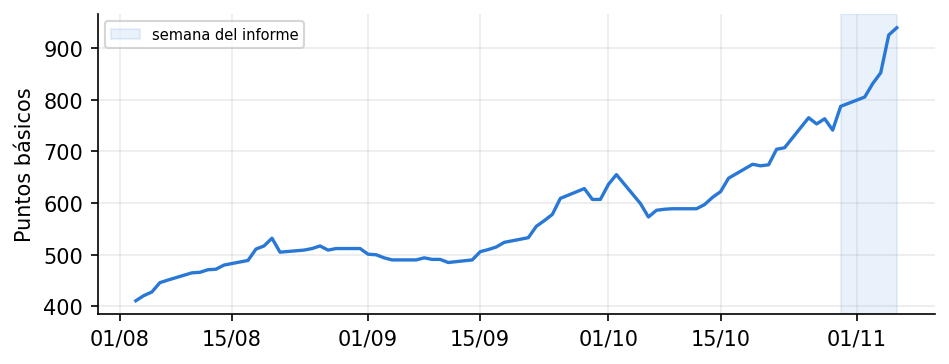

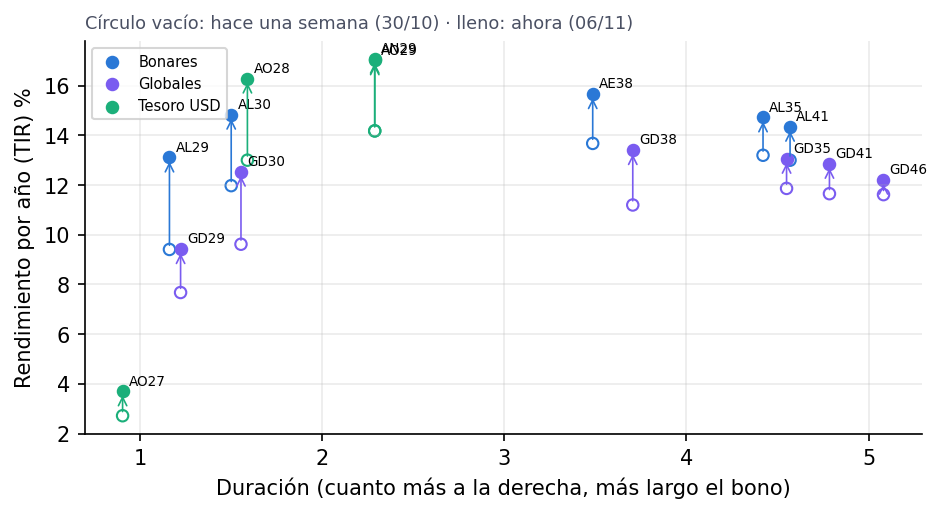

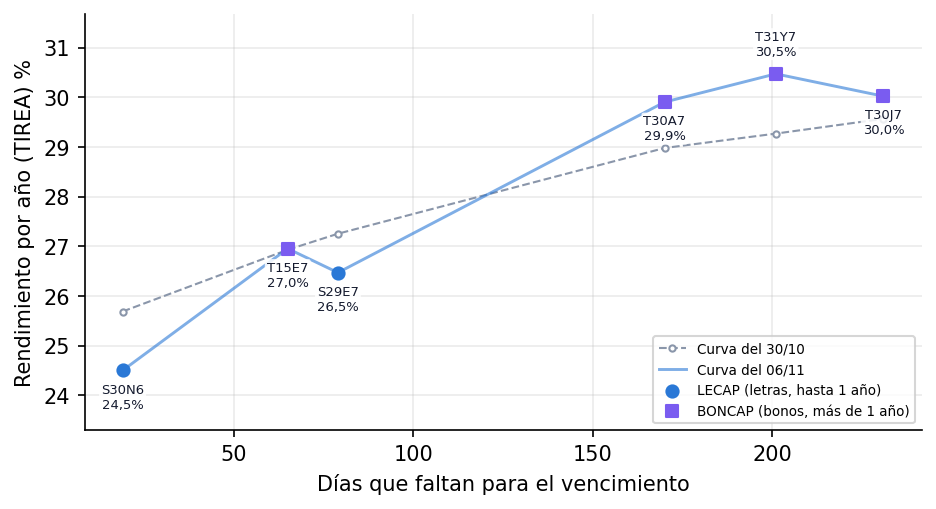

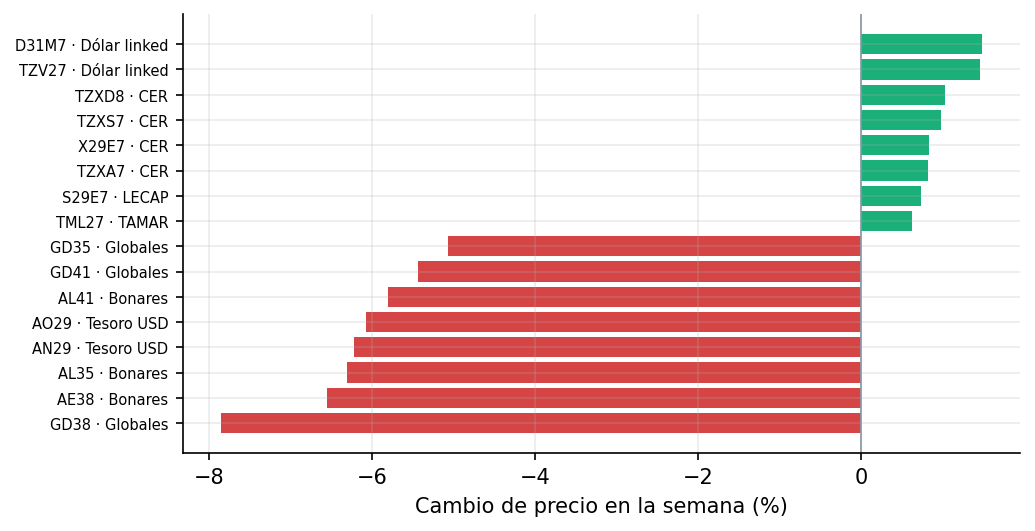

In [ ]:
# Los gráficos del PDF
G = I.graficos(S)
for k in ("riesgo", "curva_usd", "tasa_fija", "movimientos"):
    if k in G:
        display(Image(data=G[k].getvalue(), width=760))

## 5. Resultados y conclusiones

In [ ]:
print("Resultados con los datos y los valores de los formularios de este notebook")
print(f"• Soberanos en dólares: TIR mediana {pct(tabla_usd['tir'].median())}; prima de la ley local sobre la de Nueva York de {n_ar(prima, 0)} pb.")
print(f"• ONs: TIR mediana {pct(ON_OK['tir'].median())}, contra {pct(tabla_usd.loc[tabla_usd['familia'] == 'Globales', 'tir'].median())} de los Globales.")
print(f"• Tasa fija en pesos: {pct(c6['tem'])} mensual a 6 meses; inflación breakeven del próximo mes: "
      + (f"{pct(be['inflacion'].iloc[0])}." if len(be) else "sin dato."))
print(f"• Tu cartera: duración {n_ar(RS['md'])}, VaR {CONFIANZA:.0%} a {HORIZONTE_DIAS} día(s) de {pct(VR['var_pct'])} del valor"
      + (f"; en la semana, {n_ar(pf['retorno_semana_%'])}%." if pf else "."))

Resultados con los datos y los valores de los formularios de este notebook
• Soberanos en dólares: TIR mediana 13,41%; prima de la ley local sobre la de Nueva York de 225 pb.
• ONs: TIR mediana 6,66%, contra 12,70% de los Globales.
• Tasa fija en pesos: 2,19% mensual a 6 meses; inflación breakeven del próximo mes: 1,91%.
• Tu cartera: duración 1,96, VaR 95% a 1 día(s) de 0,82% del valor; en la semana, -1,58%.
